# Continuous Actor-Critic with Trajectory Optimization" (CACTO)
Basic implementation of the algorithm CACTO for a single integrator dynamics.
This implementation is based on JAX, and it is not completely equivalent to the original CACTO algorithm.

## Summary of the algorithm
CACTO boils down to repeating in a loop the following steps:
* Solve a batch of Trajectory Optimization (TO) problems with different initial states and different horizon lengths.
* For each state of the computed trajectories, compute the associated cost-to-go $\bar{V}$ and store it in a replay buffer. Note that since this implementation of CACTO uses Monte Carlo (instead of Temporal Difference) we do not need to store the future state in the replay buffer.
* Sample randomly from the replay buffer and use the data to train the critic network so that it matches the stored cost-to-go.
* Sample randomly from the replay buffer and use the data to train the actor network by minimizing the Q function computed by using the critic network, the cost function and the system dynamics.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "" # force JAX to use CPU 
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import casadi as ca
from matplotlib.patches import Ellipse
import optax
import timeit # start_time = timeit.default_timer()
import collections

import jax
jax.config.update("jax_default_prng_impl", "threefry2x32") # Set the random number generator 
import jax.numpy as jnp
from jax import random
import flax
import flax.linen as nn
from typing import Sequence
from tqdm import tqdm

# Print available devices 
print(f"Devices: {jax.devices()}")
print("JAX is using:", jax.devices())

# set default values for getting nice plots
mpl.rcParams["lines.linewidth"] = 4
mpl.rcParams["font.size"] = 16
mpl.rcParams["legend.fontsize"] = 16
mpl.rcParams["axes.labelsize"] = 16
mpl.rcParams["axes.grid"] = True


# NOTE: I had to force JAx on the CPU because my GPU can't make it :-(

2026-09-23 11:15:20.365159: E external/xla/xla/stream_executor/cuda/cuda_driver.cc:268] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected
No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


Devices: [CpuDevice(id=0)]
JAX is using: [CpuDevice(id=0)]


Define all the parameters of the problem and the algorithm.

In [2]:

start_total_time = timeit.default_timer() # start total timer

RANDOM_SEED = 13  # seed of the randon number generator

# PARAMETERS OF THE PROBLEM
N = 50      # horizon size
dt = 0.05   # time step
n_x = 2     # State dimension (X, Y)
n_u = 2     # Control dimension (u_x, u_y)
U_MAX = 10  # maximum control input (for both u_x and u_y)

# REPLAY BUFFER AND OCPs PARAMETERS
BUFFER_SIZE = 500 * N # size of the replay buffer ( = number of OCPs that i want to store * horizon size)
N_OCP = 300 # number of Optimal Control Problems (OCP) solved at each iteration

# PARAMETERS OF THE ALGORITHM (CACTO)
critic_layers = [ 128, 256, 256]  # number of neurons of the NN layers of the critic
actor_layers = [256, 256, 256]    # number of neurons of the NN layers of the actor
learning_rate_critic = 5e-3       # learning rate used for updating the weights of the critic
learning_rate_actor = 5e-4        # learning rate used for updating the weights of the actor
minibatch_size = 256              # size of the minibatch
actor_epochs = 35               # number of epochs of training of the actor for every CACTO iteration
critic_epochs = 35              # number of epochs of training of the critic for every CACTO iteration

# ALM Stability hyperparameters
lam_max, rho_max = 1e5, 1e5
rho_growth, tolerance = 1.01, 1e-4
rho_init = 50.0
lambda_init = 20.0
eta_lambda = 0.4

# Set random seeds for reproducibility
np.random.seed(RANDOM_SEED)
key = jax.random.PRNGKey(RANDOM_SEED)

Cost, obstacles and OCP parameters 

In [3]:
# 1. Create a 2D grid for plotting
N_grid = 100
x_min, x_max = -15, 15
y_min, y_max = -15, 15
x_vals = np.linspace(x_min, x_max, N_grid)
y_vals = np.linspace(y_min, y_max, N_grid)
XX, YY = np.meshgrid(x_vals, y_vals)
X_grid_2d = np.stack([XX.ravel(), YY.ravel()], axis=-1)

# 2. Initialize the Z matrix to store cost values for pllotting the cost landscape
Z = np.zeros_like(XX)

# 3. Initial states
init_pos = [
    # Out of the C obstacle 
    [-10.0, -10.0],
    [-8.0,  -5.0],
    [-10.0,  0.0],  
    [-8.0,   5.0],
    [-10.0, 10.0],
    
    # Inside the C obstacle 
    [5.0,  0.0],    
    [6.0,  1.5],     
    [6.0, -1.5],   
    [5.5,  2.5],     
    [5.5, -2.5],  
    [2.0, 0.0],
    [1.5, 1.0],
    [1.5, -2.0],
    [2.3, 1.0],
    [3.0, -1.0],
    [4.0, 2.0],
    [4.0, -2.0],
    [4.3, 0.7],
    [4.3, -.7],
    [4.0, 0.0],
    [3.4, 0.8],
    [5.8,  0.8],   
    [5.8, -0.8],   
    [2.5,  1.8],   
    [2.5, -2.2],   
    [4.5,  2.3],  
    [4.5, -2.3],   
    [3.0,  0.0],  
    [1.8, -1.0],   
    [3.8, -1.5],   
    [5.2,  1.2],   
    
    
    # Near the boundary 
    [10, 5],
    [10, 10],
    [10, 8],
    [10, -5],
    [10, -10],
    [10, -8]
    
]

# Convertion
X_init_grid = jnp.array(init_pos)

# Target and cost parameters
target_pos = [-7.0, 0.0] 
cost_weights = {'w_d': 1e2, 'w_p': 5e1, 'w_u': 6e1, 'w_f': 1e1} # distance ot targ, target valley, control effort, final pos cost

# Obstacles 
obstacle_parameters = [
            {'x_ob': 0.0, 'y_ob': 0.0,  'a': 1.5, 'b': 5.0}, # Ellipse 1 (vertical, back)
            {'x_ob': 3, 'y_ob': 4.0,  'a': 4.0, 'b': 1.5}, # Ellipse 2 (horizontal, top)
            {'x_ob': 3, 'y_ob': -4.0, 'a': 4.0, 'b': 1.5}  # Ellipse 3 (horizontal, bottom)
]


def generate_valid_initial_states(num_samples, init_min, init_max, obstacle_params, n_x=2, plot=False):
    """
    Generates an array of random initial states with specific densities:
    - 20% inside the C-shaped obstacle
    - 20% behind the C-shaped obstacle
    - 60% randomly distributed in the free space
    Ensures that no point falls inside the elliptical obstacles.

    
    args:
    - num_samples: number of valid initial states to generate
    - init_min: minimum value for the random sampling (can be a scalar or an array of size n_x)
    - init_max: maximum value for the random sampling (can be a scalar or an array of size n_x)
    - obstacle_params: list of dictionaries, each containing the parameters of an ellipse (x_ob, y_ob, a, b)
    - n_x: dimension of the state space (default is 2 for 2D)
    
    returns:
    - valid_samples: a (num_samples, n_x) array of valid initial states
    - N_samples: a (num_samples,) array of remaining steps for each sample
    """

    # --- Generate samples with specific spatial densities ---

    behind_c_percent = 0.2 # percentage of samples to generate behind the C zone
    inside_c_percent = 0.2 # percentage of samples to generate inside the C zone


    n_in = int(num_samples * inside_c_percent)     # %20 inside the C zone
    n_c = int(num_samples * behind_c_percent)      # %20 behind the C zone
    n_free = num_samples - n_c - n_in              # The rest outside the C zone


    # 1. Generate random samples in the free space  
    valid_samples_free = np.empty((n_free, n_x))  
    valid_count = 0
    
    while valid_count < n_free:
        # Generate a random candidate
        candidate = np.random.uniform(init_min, init_max, size=(n_x,))
        
        # Check if the candidate is outside ALL obstacles
        is_valid = True
        for param in obstacle_params:
            x_term = ((candidate[0] - param['x_ob'])**2) / (param['a']**2)
            y_term = ((candidate[1] - param['y_ob'])**2) / (param['b']**2)
            
            g_ellipse = x_term + y_term - 1
            
            # If g_ellipse <= 0, the point is INSIDE or ON THE EDGE of the obstacle
            if g_ellipse <= 0:
                is_valid = False
                break # No need to check other obstacles, discard the point
                
        # If it passed all checks, save it to the array
        if is_valid:
            valid_samples_free[valid_count, :] = candidate
            valid_count += 1
            
    # 2. Add points behind the C zone
    c_min = np.array([5.0,  -5.0])
    c_max = np.array([15.0,  5.0])
    behind_c_count = 0
    behind_c_samples = np.empty((n_c, n_x))
    
    while behind_c_count < n_c:
        candidate = np.random.uniform(c_min, c_max, size=(n_x,))
        is_valid = True
        for param in obstacle_params:
            x_term = ((candidate[0] - param['x_ob'])**2) / (param['a']**2)
            y_term = ((candidate[1] - param['y_ob'])**2) / (param['b']**2)
            if x_term + y_term - 1 <= 0:
                is_valid = False
                break
        if is_valid:
            behind_c_samples[behind_c_count] = candidate
            behind_c_count += 1

    # 3. Add points inside the C zone 
    in_c_min = np.array([1.8, -2.3])
    in_c_max = np.array([6.5,  2.3])
    inside_c_count = 0
    inside_c_samples = np.empty((n_in, n_x))
    
    while inside_c_count < n_in:
        candidate = np.random.uniform(in_c_min, in_c_max, size=(n_x,))
        is_valid = True
        for param in obstacle_params:
            x_term = ((candidate[0] - param['x_ob'])**2) / (param['a']**2)
            y_term = ((candidate[1] - param['y_ob'])**2) / (param['b']**2)
            if x_term + y_term - 1 <= 0:
                is_valid = False
                break
        if is_valid:
            inside_c_samples[inside_c_count] = candidate
            inside_c_count += 1

    # Combine the valid samples with the C zone samples and shuffle them
    valid_samples = np.vstack([valid_samples_free, behind_c_samples, inside_c_samples])
    np.random.shuffle(valid_samples)


    # --- Generate remaining steps samples with specific densities ---
    
    # For the steps I set 40% of the set to start at t0 = 0 (thus remainig steps = N)
    num_full = int(N_OCP*0.4) # Number of samples with full horizon
    N_full = np.full(num_full, N, dtype=int)  
    
    # The rest of the remaining steps will have a random value in [1, N-1] 
    num_random = N_OCP - num_full
    val_min = int(N*0.25)
    val_max = int(N*0.75)
    N_random = np.random.randint(val_min, val_max, size=num_random)
    
    # Total remaining steps samples
    N_samples = np.concatenate([N_full, N_random])
    
    # Shuffle the samples to mix the zero and random initial times
    np.random.shuffle(N_samples)

    t0_samples = N - N_samples  # Compute the corresponding initial time for each sample
            
            
    # Plotting (optional)
    if plot:
        fig, ax = plt.subplots(figsize=(8, 7))
        
        # Draw obstacles
        for i, p in enumerate(obstacle_params):
            el = Ellipse((p['x_ob'], p['y_ob']), 2*p['a'], 2*p['b'], 
                        color='red', alpha=0.3, label=f"Obstacles" if i==0 else None)
            ax.add_patch(el)
            
        # Draw valid samples
        sc =ax.scatter(valid_samples[:, 0], valid_samples[:, 1], s=10, 
                c=t0_samples, cmap='coolwarm', alpha=0.8, label="Initial States")

        # Add colorbar for initial time
        cbar = fig.colorbar(sc, ax=ax)
        cbar.set_label('Initial Time ($t_0$)', fontsize=12)
    
        ax.set_xlim(init_min[0]-0.5, init_max[0]+0.5)
        ax.set_ylim(init_min[1]-0.5, init_max[1]+0.5)
        ax.set_title(f"Generated {num_samples} Valid States")
        ax.legend()
        ax.grid(True, linestyle='--', alpha=0.6)
        plt.show()
                
    return valid_samples, N_samples

## Define Cost, Dynamics and Constraints

The system considered is a 2D single integrator that has to reach a target avoiding a C-shaped obstacle.

The staete is defined as: $ [x, y, t] $ (augmented state), while the controls are defined as $ [v_x, v_y] $.

The dymanics is:

$ x_{i+1} = x_i + \Delta t \, u_i$




The cost is instead defined as in the paper, but without the penalty on the ellpilses region since now is a constraint:
$$l(\cdot) = \frac{1}{c_2} \left( l_1(\cdot) + l_2(\cdot) + l_4(\cdot) - c_1 \right)$$

With: 
* $$l_1(\cdot) = w_d \left( (x - x_g)^2 + (y - y_g)^2 \right)$$
* $$l_2(\cdot) = \frac{w_p}{\alpha_1} \ln\left( e^{-\alpha_1 \left( \sqrt{(x - x_g)^2 + c_2} + \sqrt{(y - y_g)^2 + c_3} + c_4 \right)} + 1 \right)$$
* $$l_4(\cdot) = w_u ||u||_2^2
Where:
* $l_1$ (Quadratic Tracking Cost): A standard quadratic penalty on the distance between the current state $(x, y)$ and the target $(x_g, y_g)$. It provides a global gradient towards the goal.
* $l_2$ (Target Cost Valley): A smooth logarithmic-exponential term that creates a steep "cost valley" around the target. It ensures high precision and strong attraction when the agent is near the goal.
* $l_4$ (Control Effort): A regularization term penalizing the squared $L_2$ norm of the control inputs ($||u||_2^2$). It minimizes energy consumption and prevents aggressive control actions.


We defined also the augmented versions of these functions that use an augmented version of the state including time as last component. This is useful because the actor and critic networks depend on both state and time.

In [4]:
def cost(x, u, target, params = cost_weights, lib='casadi'):
    """
    Computes the cost function based on the CACTO paper (excluding the obstacle term l3).
    
    Allows for both JAX and CasADi implementations by selecting the appropriate math library based on the 'lib' flag.
    
    Args:
        x: State vector [x, y].
        u: Control input [vx, vy].
        target: Target coordinates [x_g, y_g].
        params: Dictionary containing weights (w_d, w_p, w_u).
        lib: Library selector ('jax' or 'casadi').
        
    Returns:
        c: The computed scalar cost.
    """
    
    # Selection of the math library based on the 'lib' flag
    if lib == 'jax':
        xp = jnp
        # Ensure inputs are JAX arrays to handle lists or tuples
        x = jnp.array(x)
        u = jnp.array(u)
        target = jnp.array(target)
    else:
        xp = ca
        # When using CasADi, we keep the symbolic variables (MX/SX) as they are

    # Extract weights from the params dictionary
    w_d = params['w_d']      
    w_p = params['w_p']        
    w_u = params['w_u']

            
    # Extract current position and target coordinates
    x_pos, y_pos = x[0], x[1]
    x_g, y_g = target[0], target[1]
    
       
    # Constants from the CACTO paper (i changed them wrt the paper)
    c1 = 1000.0
    c2 = 1000.0
    c3 = 0.1
    c4 = -2 * c3 - 2 * xp.sqrt(c3)
    alpha_1 = 50.0
    
    # Compute individual cost terms
    
    # l1: Quadratic Tracking Cost (Formula 12)
    l1 = w_d * ((x_pos - x_g)**2 + (y_pos - y_g)**2)
    
    # l2: Target Cost Valley (Formula 13)
    dist_term = xp.sqrt((x_pos - x_g)**2 + c2) + xp.sqrt((y_pos - y_g)**2 + c3) + c4
    l2 = (w_p / alpha_1) * xp.log(xp.exp(-alpha_1 * dist_term) + 1.0)
    
    # l4: Control Effort (Formula 15)
    # Using lib-specific dot product/sumsqr logic
    l4 = w_u * xp.dot(u, u) 
        
        
    # Total Cost Calculation
    c = (1.0 / c2) * (l1 + l2 + l4 - c1)
    
    return c
    
def cost_aug_1d(x_aug, u):
    ''' 
    Augmented cost function that includes the time step as part of the state.
    This version is for mono-dimensional inputs (x_aug is a 1D array).'''
    return cost(x_aug[:-1], u, target_pos, lib='jax')

def dynamic_1d(x, u):
    '''Single integrator dynamics, mono-dimensional version.'''
    x_next = x + dt*u
    return x_next

def dynamic_aug_1d(x_aug, u):
    '''Augmented dynamics that includes the time step as part of the state,  mono-dimensional version.'''
    x_next = dynamic_1d(x_aug[:-1], u)
    x_aug_next = jnp.concatenate([x_next, jnp.array([x_aug[-1] + 1])])
    return x_aug_next

# Smart wrappers that handle both single vectors and batches automatically, using vmap for vectorization.
# Neded for the warm start function to work with batched trajectories for efficiency.
def cost_aug(x_aug, u):
    '''Smart wrapper: handles both single vectors and batches automatically'''
    if x_aug.ndim == 1:
        return cost_aug_1d(x_aug, u)
    else:
        return jax.vmap(cost_aug_1d)(x_aug, u)

def dynamic_aug(x_aug, u):
    '''Smart wrapper: handles both single vectors and batches automatically'''
    if x_aug.ndim == 1:
        return dynamic_aug_1d(x_aug, u)
    else:
        return jax.vmap(dynamic_aug_1d)(x_aug, u)

Now we plot the cost function as a surface (with $u = [0, 0]$).

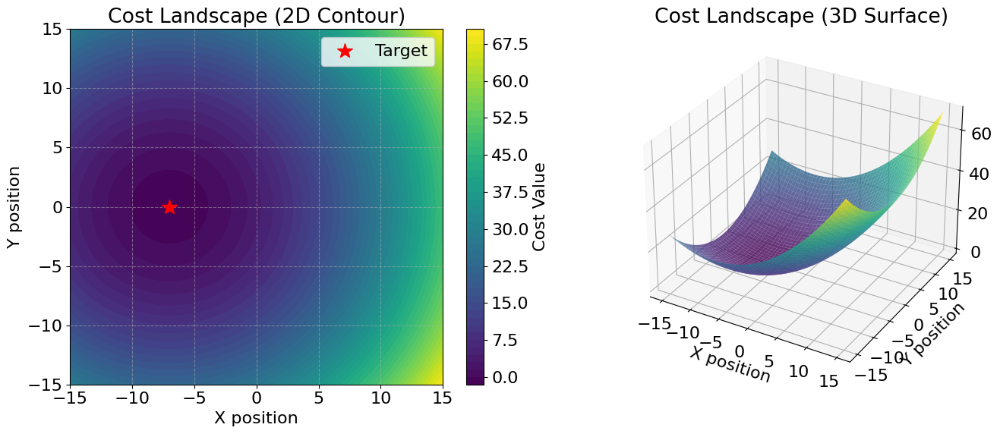

In [5]:
def plot_cost_landscape(target):
    """
    Plots the 2D contour and 3D surface of the cost function 
    by directly calling the cost() function.
    Assumes control input u = [0, 0].
    """
    
    # Zero control effort for visualization
    u_val = [0.0, 0.0]
    
    # Evaluate the original cost() function point by point on a grid deifned in a pervious code section 
    for i in range(XX.shape[0]):
        for j in range(XX.shape[1]):
            # Current state on the grid
            x_val = [XX[i, j], YY[i, j]] 
            
            # Call your CasADi cost function and cast the result to a Python float
            cost_value = cost(x_val, u_val, target)
            Z[i, j] = float(cost_value)

    # Create the plots
    fig = plt.figure(figsize=(14, 6))

    # --- Plot 1: 2D Contour (Heatmap) ---
    ax1 = fig.add_subplot(1, 2, 1)
    contour = ax1.contourf(XX, YY, Z, levels=50, cmap='viridis')
    fig.colorbar(contour, ax=ax1, label='Cost Value')
    
    # Plot the target position as a red star
    ax1.plot(target[0], target[1], 'r*', markersize=15, label='Target')
    ax1.set_title("Cost Landscape (2D Contour)")
    ax1.set_xlabel("X position")
    ax1.set_ylabel("Y position")
    ax1.legend()
    ax1.grid(True, linestyle='--', alpha=0.5)

    # --- Plot 2: 3D Surface ---
    ax2 = fig.add_subplot(1, 2, 2, projection='3d')
    surf = ax2.plot_surface(XX, YY, Z, cmap='viridis', edgecolor='none', alpha=0.8)
    ax2.set_title("Cost Landscape (3D Surface)")
    ax2.set_xlabel("X position")
    ax2.set_ylabel("Y position")
    
    plt.tight_layout()
    plt.show()
   

# Function call
plot_cost_landscape(target=target_pos)

The obstacles are defined as 3 ellipses forming a C shape.

 An elliptical constraint can be modeled as: 
$$\frac{(x - x_c)^2}{a^2} + \frac{(y - y_c)^2}{b^2} - 1 \ge 0$$

With: 
* $x_c, y_c$: Coordinates of the center of the ellipse.
* $a$: Length of the semi-axis along the X direction (horizontal "radius").
* $b$: Length of the semi-axis along the Y direction (vertical "radius").

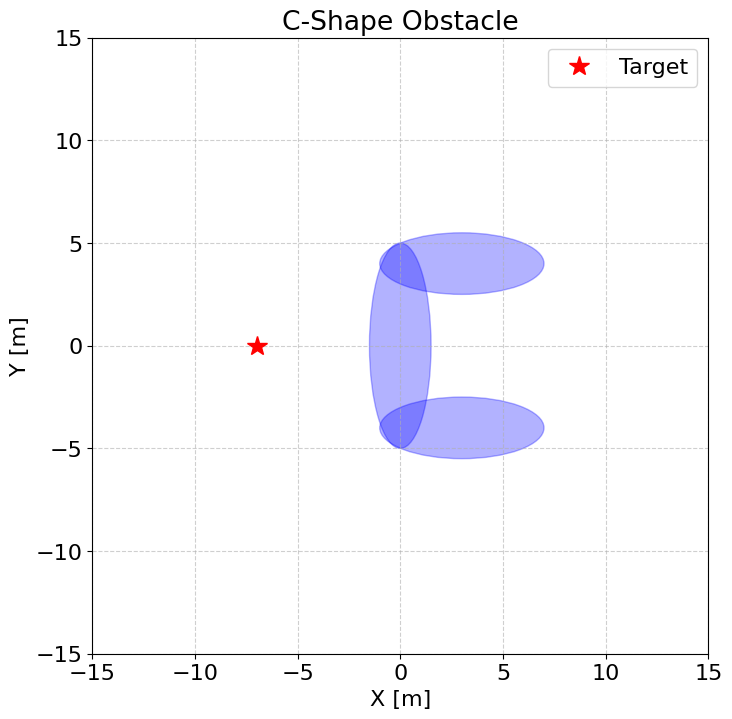

In [6]:
def elliptical_constraints(x_next, ellips_params, backend ='casadi'):
    """
    Generate the mathematical constraint equations using CasADi.
    Allows to compute the constraints using either CasADi or JAX by changing the 'backend' argument.

    args:
        x_next: The next state of the system (position) for which we want to evaluate the constraints.
        ellips_params: A list of dictionaries, where each dictionary contains the parameters of an ellipse
        backend: A string that specifies the library to use for computations. It can be 'casadi' or 'jax'.

    returns:
        A list of inequality expressions representing the constraints for each ellipse.  
    """

    x_pos = x_next[0]
    y_pos = x_next[1]

    constraints = []
    for param in ellips_params:
        x_term = ((x_pos - param['x_ob'])**2) / (param['a']**2)
        y_term = ((y_pos - param['y_ob'])**2) / (param['b']**2)

        g_ellipse = x_term + y_term - 1
        constraints.append(g_ellipse)
        
    if backend == 'jax':
        return jnp.array(constraints)
    else:   
        return constraints


def plot_ellipses(ellips_params, ax=None, target=None):
    """
    Plots filled ellipses.
    If 'ax' is provided, it plots on that axis. 
    Otherwise, it creates a new standalone figure.
    """
    # If no ax is passed create a newe one
    show_plot = False
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 8))
        show_plot = True

    # Draw the ellipses 
    for param in ellips_params:
        ellipse = Ellipse(xy=(param['x_ob'], param['y_ob']), 
                          width=param['a']*2, height=param['b']*2, 
                          edgecolor='blue', facecolor='blue', alpha=0.3)
        ax.add_patch(ellipse)

    # Draw target 
    if target is not None:
        ax.plot(target[0], target[1], 'r*', markersize=15, label='Target')

    # Settings
    ax.set_aspect('equal') 
    ax.set_xlim(-15, 15)
    ax.set_ylim(-15, 15)
    ax.set_xlabel('X [m]')
    ax.set_ylabel('Y [m]')
    ax.set_title("C-Shape Obstacle")
    ax.grid(True, linestyle='--', alpha=0.6)
    
    # Legend
    handles, labels = ax.get_legend_handles_labels()
    if labels:
        ax.legend()
    
    if show_plot:
        plt.show()

# 1. CasADi Constraints
X = ca.SX.sym('X')
Y = ca.SX.sym('Y')
state_sym = ca.vertcat(X, Y)
constraints_eq = elliptical_constraints(state_sym, obstacle_parameters)

# 2. Plot call
plot_ellipses(obstacle_parameters, target=target_pos)

## Define a class for solving the optimal control problem with the optimal control library Casadi

The discrete-time Optimal Control Problem over an horizon $N$ can be mathematically formulated as follows:$$\begin{aligned}
\min_{\mathbf{x}, \mathbf{u}} \quad & \sum_{i=0}^{N-1} \ell(x_i, u_i, x_{\text{target}}) + \ell(x_N) \\
\text{s.t.} \quad & x_0 = x_{\text{init}} \\
& x_{i+1} = f(x_i, u_i), \quad \forall i \in \{0, \dots, N-1\} \\
& g_k(x_i) \ge 0, \quad \forall i \in \{0, \dots, N\}, \; \forall k \in \{1, \dots, M\} \\
& -u_{max} \le u_i \le u_{max} \quad \forall i \in \{0, \dots, N-1\}
\end{aligned}$$

Notation and Variables:
* Decision Variables:
  - $\mathbf{x} = \{x_0, x_1, \dots, x_N\}$ is the state sequence, where $x_i \in \mathbb{R}^{n_x}$.
  - $\mathbf{u} = \{u_0, u_1, \dots, u_{N-1}\}$ is the control sequence, where $u_i \in \mathbb{R}^{n_u}$.

* Objective Function (Cost):
  - $\ell(x_i, u_i, x_{\text{target}})$ represents the running cost function evaluated at each step $i$.
  - $\ell(x_N)$ Is the terminal cost and it is computed as: $w_f \cdot \| x_N - x_{target} \|^2_2$, where $w_f$ is the final cost weight.
* Constraints:
  - Initial Condition: $x_0 = x_{\text{init}}$ ensures the trajectory starts from the given initial state.
  - System Dynamics: $x_{i+1} = f(x_i, u_i)$ defines the state transition. For a single integrator system, this typically represents standard integration, e.g., $x_{i+1} = x_i + u_i \Delta t$.
  - Obstacle Avoidance: $g_k(x_i) \ge 0$ requires the state to remain outside or on the boundary of the $M = 3$ defined elliptical obstacles at all times.
  - Control limits: $-u_{max} \le u_i \le u_{max}$

In [7]:
class OcpSingleIntegrator:
    '''
    A class to solve an Optimal Control Problem (OCP) for a single integrator.
    '''

    def __init__(self, target, cost_params, obstacle_params):

        self.target = target
        self.cost_params = cost_params
        self.obstacle_params = obstacle_params

    def solve(self, x_init, N, X_guess=None, U_guess=None):
        self.opti = ca.Opti() # Use casadi
        
        # create the state and control variables
        self.x = self.opti.variable(n_x, N+1) 
        self.u = self.opti.variable(n_u, N)
        x = self.x
        u = self.u

        # warm-start the solver with the provided initial guess (if any)
        if(X_guess is not None):
            for i in range(N+1):
                self.opti.set_initial(x[:, i], X_guess[i,:])
        else:
            # otherwise initialize the state trajectory with the initial state
            for i in range(N+1):
                self.opti.set_initial(x[:, i], x_init)
        if(U_guess is not None):
            for i in range(N):
                self.opti.set_initial(u[:, i], U_guess[i,:])
        else:
            # otherwise initialize the control at 0
            for i in range(N):
                self.opti.set_initial(u[:, i], 0.0) 
                
        # define the cost function
        self.cost = 0
        self.running_costs = [None,]*(N+1) # Preallocate a list
        self.final_cost = None
        
        for i in range(N+1):
            # Running cost  
            if(i<N):
                self.running_costs[i] = cost(x[:, i], u[:, i], self.target, self.cost_params)
                self.cost += self.running_costs[i]
            # Final Cost (i use a quadratic final cost)
            else:
                self.final_cost = ca.sumsqr(x[:, N] - self.target) # Simple quadratic final cost
                self.cost += self.cost_params['w_f'] * self.final_cost
            
            
        # --- Set the constraints for the optimization problem ---
        for i in range(N+1):
            # Elliptical obstacles constraints
            obs_constraints = elliptical_constraints(x[:, i], self.obstacle_params)
            for g in obs_constraints:
                self.opti.subject_to(g >= 0)

        # Define the dynamics constraints and the controls constraints 
        for i in range(N):            
            
            self.opti.subject_to( x[:, i+1]== dynamic_1d(x[:, i], u[:, i]) )
            self.opti.subject_to( self.opti.bounded(-U_MAX, u[:, i], U_MAX) ) # Control limits

        # Set the initial state
        self.opti.subject_to(x[:, 0]==x_init)
        
        # Set final state constraints
        #self.opti.subject_to(x[:, N] == self.target)
        # NOTE: if the final consrt is used you get failed trajectories (not wanted)
        
        self.opti.minimize(self.cost)

        # Solve the problem with IpOpt
        opts = {'ipopt.print_level': 0, 'print_time': 0, 'ipopt.sb': 'yes'}
        self.opti.solver("ipopt", opts)

        return self.opti.solve()

## Try to solve some OCPs

Create an OCP solver and start evaluating it w/o initial guess. We can see how the solver fails in the "hard zone", thus inside the C formed by the ellipses.

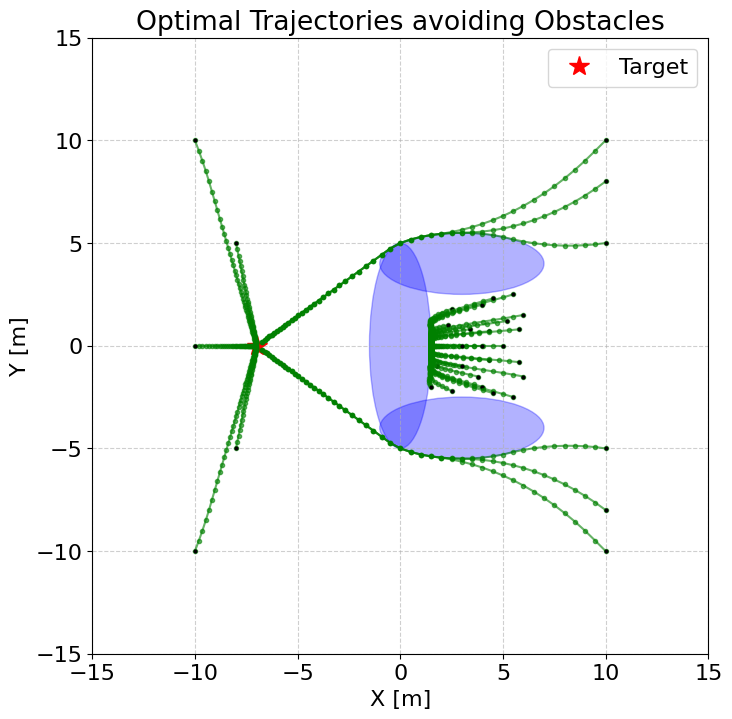

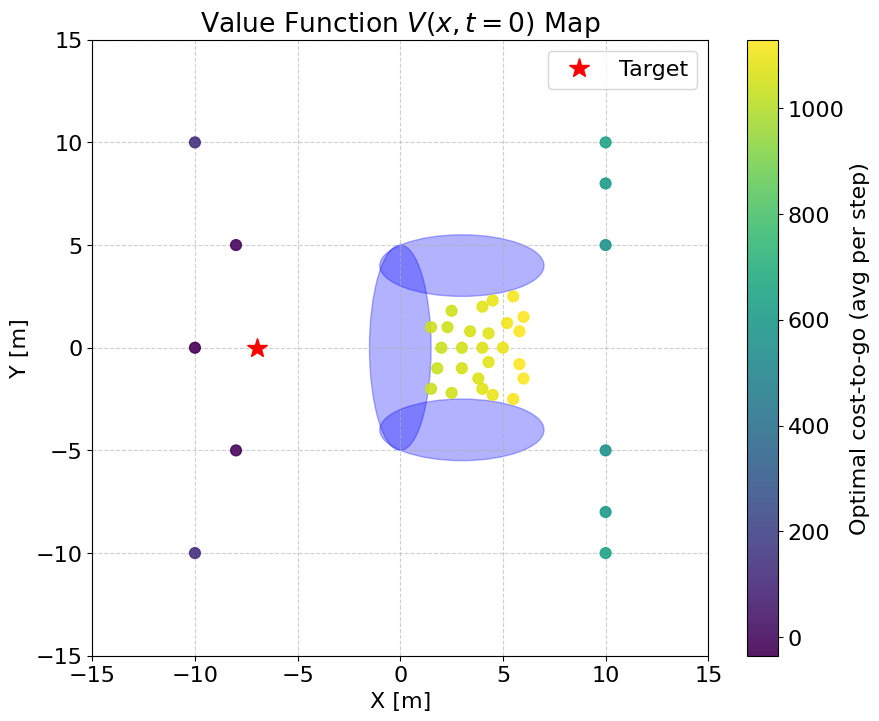

In [8]:
# 1. Initialize the OCP solver passing the required arguments
ocp = OcpSingleIntegrator(target=target_pos, cost_params=cost_weights, obstacle_params=obstacle_parameters)


V = np.empty((len(X_init_grid), 1)) # Value function at each state for each CACTO iteration


# PLOT 1: OPTIMAL TRAJECTORIES IN 2D SPACE
fig, ax = plt.subplots(figsize=(10, 8))

# Plot obstacles
plot_ellipses(obstacle_parameters, ax=ax, target=target_pos)
ax.set_title("Optimal Trajectories avoiding Obstacles")

# Solve the OCP for the given initial states x_init and horizon N 
for i, x_init in enumerate(np.array(X_init_grid)):
    try:
        sol = ocp.solve(x_init, N)   
        V[i, 0] = sol.value(ocp.cost) 
        x_traj = sol.value(ocp.x) 
        
        ax.plot(x_traj[0, :], x_traj[1, :], alpha=0.6, linewidth=1.5, 
                color='green', marker='o', markersize=3)
        
        ax.plot(x_init[0], x_init[1], 'k.', markersize=4)
        
    except Exception as e:
        print(f"Solver failed for init state {x_init}")
        
        V[i, 0] = np.nan 
        
        ax.plot(x_init[0], x_init[1], 'rx', markersize=4)
        
        x_traj_failed = ocp.opti.debug.value(ocp.x)
        
        ax.plot(x_traj_failed[0, :], x_traj_failed[1, :], 'r--', 
                alpha=0.5, linewidth=1.5)

ax.legend(loc='best')
plt.show()


# PLOT 2: Value function map
fig, ax = plt.subplots(figsize=(10, 8))

# Plot obstacles 
plot_ellipses(obstacle_parameters, ax=ax, target=target_pos)

# Title
ax.set_title("Value Function $V(x, t=0)$ Map")

# Plot the value function
scatter = ax.scatter(np.array(X_init_grid)[:, 0], np.array(X_init_grid)[:, 1], 
                     c=V[:, 0], cmap='viridis', s=60, alpha=0.9, zorder=3)

# Add colorbar to show the scale
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Optimal cost-to-go (avg per step)")

plt.show()

## Replay buffer
Define a class representing the replay buffer. Data is stored using Python lists, but when retrieved with the "get" methods it is converted to Jax arrays, so that it can be directly used to train/evaluate the neural networks.

In [9]:
class ReplayBuffer:
    def __init__(self, name, size = BUFFER_SIZE):
        self.name = name
        self.X = collections.deque(maxlen=size)    # FIFO buffer 
        self.U = collections.deque(maxlen=size)    # FIFO buffer
        self.V = collections.deque(maxlen=size)

    def append(self, x, u, v):
        self.X.append(x)
        self.U.append(u)
        self.V.append(v)

    def getX(self):
        return jnp.array(self.X)

    def getU(self):
        valid_u = [u for u in self.U if u is not None]
        return jnp.array(valid_u)

    def getV(self):
        v_array = jnp.array(self.V)
        if v_array.ndim == 1:
            return v_array.reshape((len(self.V), 1))
        return v_array
    

## Neural networks structure
Define a class representing a standard Multi-Layer Perceptron neural network based on Flax. This neural network will be used to represent the critic and the actor. We use the ELU activation function, which is a smooth version of the ReLU (Rectified Linear Unit) function.


**NOTES**: 
* A perceptron is essentially a neuron 
* JAX: A high-performance mathematical computation library (essentially a super-powered NumPy with GPU/TPU support and automatic differentiation).
* Flax: A Neural Network framework built on top of JAX. While JAX handles the raw math, Flax provides the ready-to-use building blocks (layers, activation functions, parameter management) needed to easily construct and train ML models.

So JAX is similar to Numpy but more powefull, so it is a tool for mathematical computation. Flax introduces the tools, methos ecc. based on JaX to buid Neural Networks.

In [10]:
# A multi-layer perceptron using ELU activation functions
class MLP(nn.Module):
  '''
  A Multi-Layer Perceptron model.

  Args:
      features: A sequence of integers defining the number of neurons in each layer.
                Example: [64, 32, 2] creates two hidden layers and one output layer.
  
  Returns:
      The output of the network (logits/predictions) after the forward pass.
  '''
  features: Sequence[int]

  @nn.compact
  def __call__(self, x):
    for feat in self.features[:-1]:
      x = nn.elu(nn.Dense(feat)(x))
    x = nn.Dense(self.features[-1])(x)
    return x
  
# NO MORE NEED FOR THIS FUNCTION SINCE WE ARE USING OPTAX
# # Function to update the weights of the network
# @jax.jit
# def update_params(params, learning_rate, grads):
#   params = jax.tree_util.tree_map(
#       lambda p, g: p - learning_rate * g, params, grads)
#   return params


1. Building the Neural Network (using Flax) 

  This part of the code is used to "draw" the structure of our artificial brain.

  * `class MLP(nn.Module):` This class defines our Neural Network (Multi-Layer Perceptron), building it on top of the base module provided by the Flax library.
  * `features: Sequence[int]`: This is a simple list of numbers that determines the size of the network. For example, passing `[64, 32, 2]` tells Flax to create a first hidden layer with 64 neurons, a second with 32, and a final output layer with 2 neurons.
  * `@nn.compact`: A very convenient decorator exclusive to Flax. In traditional libraries, you usually have to declare the layers first and then connect them later. This command allows you to define and use the layers at the exact same time the data passes through them (inside the `__call__` function), saving a lot of boilerplate code.
  * `self.features[:-1]` (The Slicing): In Python, `[:-1]` means "take the whole list except the very last item". If your features list is `[64, 32, 2]`, this loop will only iterate over 64 and 32. We do this because the inside layers (hidden layers) need an activation function to learn complex patterns, but the final output layer (the 2) needs to output raw, unactivated numbers.
  * `nn.Dense(feat)(x)` (Create & Apply): Thanks to the `@nn.compact` decorator, this specific part does two things simultaneously: it defines a new fully-connected layer with `feat` neurons (e.g., 64), and immediately feeds the current input data `x` into it.
  * `nn.elu(...)` (The Activation): The mathematical output of the Dense layer is immediately wrapped inside the ELU (Exponential Linear Unit) function. This introduces non-linearity.
  * So `x = nn.elu(nn.Dense(feat)(x))` creates a fully connected (dense) layer with input _x_ and activation function ELU.
  * `x = nn.Dense(self.features[-1])(x)`: the last layer. It is just afully connected layer, no activation.


2. Learning and Updating Weights (using JAX) (NO MORE USED)

  This part of the code is the "engine" that allows the network to correct its mistakes and learn, exploiting the mathematical speed of JAX.

  * `@jax.jit`: Stands for Just-In-Time compilation. By putting this line above the function, JAX takes your Python code and translates it into super-optimized machine language (XLA) right before running it. This makes computation very fast, especially on a GPU.
  * `jax.tree_util.tree_map`: Unlike other libraries, in Flax the millions of network "weights" and their respective errors (gradients) are not stored inside the network itself. They are saved in large, tree-structured dictionaries called PyTrees. This function is used to apply a mathematical rule to all the numbers inside these dictionaries at once, without having to write slow `for` loops.
  * `lambda p, g: p - learning_rate * g`: This is the classic mathematical formula that neural networks use to learn (called Gradient Descent). In simple terms, it means: "Take the old weight (`p`), and subtract the error made (`g`) scaled by how fast we want the network to learn (`learning_rate`). The result is the new, corrected weight."

**More about `jax.tree_util.tree_map`:**

It updates the entire set of network weights (`params`) by applying the information stored in the gradients (`grads`) using the rule/formula `f` (in this case, gradient descent).

Call:
`jax.tree_util.tree_map(f, tree, *rest, is_leaf=None)`

In my case:
`jax.tree_util.tree_map(lambda p, g: p - learning_rate * g, params, grads)`

* `f`: `lambda p, g: p - learning_rate * g`. It defines how to combine the data. Since I provided two trees, the lambda must take two arguments (`p` for params and `g` for grads).
* `tree`: `params`. The Pytree that contains the current weights of the neural network.
* `*rest`: `grads`. The Pytree that contains the calculated gradients of the cost function.

Note: `lambda` is a keyword used to define an anonymous, one-line function on the fly.
<br>
<br>
<br>

## Define a class that contains a neural network and the standard machinery for training the network to fit a given target using a Mean-Squared Error loss. 

$ \text{loss}(\theta) = \sum_{i=0}^{k-1} \frac{1}{2} || V_\theta(x_i) - \bar{V}_i ||^2$

This class will be used for the critic, which needs to be trained in a standard supervised-learning fashion.
<br>
<br>
<br>

**NOTES:** 
* I need to initialize the weights (parameters) and to define dummy/fake inputs. The latter is needed because doing so JAX can compute the number of weights of the network that depends on the input size. So, instead of giving the input size to the class, with JAX I just define fake inputs so it computes this value by itself.

  To do this, I need to randomly generate these values. To do so, JAX needs a random key for each random operation. So, 2 in this case.

  I use the method `k1, k2 = random.split(random.PRNGKey(random_seed))` that allows me to split a seed into as many random keys as I want. Doing so, I can randomly initialize the weights and define the fake inputs.

  Once i've generated the keys i can initialize the parameters by calling the `init(key, dummy_input)` function. 

  For more see: [Flax basics site](https://flax-linen.readthedocs.io/en/latest/guides/flax_fundamentals/flax_basics.html)

* `pred = self.model.apply(params, x)` fucntion that given the parameters (weights) and inputs gives the predictions of the model (outputs). Method from Flax
* `jax.vmap(fun, ...)`: 
  It automatically transforms a function written for a single data point (`fun`) into a new function that can process an entire batch of data at once. By mapping the function over the argument axes, it eliminates the need for slow `for` loops. This allows JAX to compute the results for all items in the batch simultaneously and in parallel, maximizing the computational power of the CPU/GPU.
* `jax.value_and_grad(fun)`: 
  It takes a function (like the `mse` loss) and returns a new function. When called, this new function evaluates the original one to return the actual output/value (the Loss in this case) and simultaneously computes the gradient of that function. 
* `def __call__(self, x): return self.model.apply(self.params, x)`: \_\_call\_\_ is a special method (dunder method) that makes the objecgt callable like a funztion. So instaed of doing a call like _my_network.prediction(x)_ i can just do _predictions = my_network(x)_.
* `assert( condition )`: if the condition is true the code continues.ì, if it is false it rises an exception.


In [11]:
class CriticNetwork:
    """
    Initializes the Neural Network, setting up the model architecture, 
    parameters, and the functions required for training.

    Args:
        name (str): The name identifier for the neural network.
        in_dim (int): The dimensionality of the input data.
        out_dim (int): The dimensionality of the output predictions.
        layer_sizes (list of int): A list specifying the number of neurons in each hidden layer.
        learning_rate (float, optional): The step size used for updating weights during gradient descent.
        random_seed (int, optional): The seed used to initialize JAX's pseudo-random number generator for reproducible 
        weights. Defaults to 0.
    """
    
    def __init__(self, name, in_dim, out_dim, layer_sizes, learning_rate=0.1, random_seed=0):
        # Set problem dimensions.
        self.name = name
        self.random_seed = random_seed
        self.in_dim = in_dim
        self.out_dim = out_dim
        self.learning_rate = learning_rate


        self.model = MLP(layer_sizes + [out_dim])
        k1, k2 = random.split(random.PRNGKey(random_seed))
        x = random.normal(k1, (in_dim,)) # Dummy input data
        self.params = self.model.init(k2, x) # Initialization call
        jax.tree_util.tree_map(lambda x: x.shape, self.params) # Checking output shapes
    

        # Mean-Squared Error loss function
        @jax.jit
        def mse(params, x_batched, y_batched):
            # Define the squared loss for a single pair (x,y)
            def squared_error(x, y):
                pred = self.model.apply(params, x)
                return jnp.sum(jnp.square(pred - y)) / 2.0 # computes the scalar product between 2 vectors
            # Vectorize the previous to compute the average of the loss on all samples.
            return jnp.mean(jax.vmap(squared_error)(x_batched,y_batched), axis=0)
        
        # function computing both the loss and its gradient
        self.loss_grad_fn = jax.value_and_grad(mse)
        # function computing the loss
        self.loss = mse


    def __call__(self, x):
       return self.model.apply(self.params, x)


    def train(self, in_samples, out_samples, n_epochs=1, minibatch_size=128, print_every=5):
        """
        Train the network using epochs and sequential minibatches.
        """
        N = in_samples.shape[0]
        indices = np.arange(N)
        
        # Define a learning rate schedule that decays the learning rate after a certain number of steps.
        lr_schedule = optax.exponential_decay(
            init_value=self.learning_rate,
            transition_begin = 500, # start decaying after 500 steps
            transition_steps=500,   # decay every 500 steps
            decay_rate=0.75,         # decay factor
            staircase=True,         # use staircase decay (discrete jumps) 
            end_value=1e-5           # minimum learning rate after decay
        )
        
        # Set up the optimizer using Optax with gradient clipping and Adam optimization.
        self.optimizer = optax.chain(
            optax.clip_by_global_norm(1.0),
            optax.adam(lr_schedule)
        )
        
        self.opt_state = self.optimizer.init(self.params)
        
        global_step = 0
        
        
        for epoch in range(n_epochs):
            # 1. Shuffle dataset indices at the start of each epoch
            np.random.shuffle(indices)
            
            # 2. Sequential minibatch loop
            for start_idx in range(0, N, minibatch_size):
                end_idx = min(start_idx + minibatch_size, N)
                batch_indices = indices[start_idx:end_idx]
                
                in_batched = in_samples[batch_indices, :]
                out_batched = out_samples[batch_indices, :]
                
                # 3. Gradient update
                loss_val, grads = self.loss_grad_fn(self.params, in_batched, out_batched)
                updates, self.opt_state = self.optimizer.update(grads, self.opt_state, self.params)
                self.params = optax.apply_updates(self.params, updates)
                
                global_step += 1

            # Get the current learning rate value from the schedule for logging
            current_lr_value = lr_schedule(global_step)
            
            # 4. Periodic logging of MSE and RMSE
            if (epoch + 1) % print_every == 0 or epoch == 0:
                current_mse = self.loss(self.params, in_samples, out_samples)
                rmse = jnp.sqrt(current_mse)
                print(f"Epoch {epoch+1}/{n_epochs} | MSE: {current_mse:.4f} | RMSE: {rmse:.4f} | LR: {current_lr_value:.6f} | step: {global_step}")
        
            
        return self.loss(self.params, in_samples, out_samples)

## Define a class containing the actor network and the code for training it. 

Since the actor is trained by minimizing the Q function, we need to pass it the cost $l(x,u)$, the Value network model $V(\cdot)$ and the dynamic model $f(x,u)$, because the Q function is computed as:

$Q(x,u) = l(x,u) + V(f(x,u))$

Thus my loss is the mean of the Q function over a batch: 

$$\mathcal{L}(\theta) = \frac{1}{S} \sum_{i=1}^{S} \Big( \ell(x_i, u_i) + V_\phi(f(x_i, u_i)) \Big)$$

Where:
- $\theta$ are the parameters of the actor.
- $u_i = \pi(x_i,  \theta)$ is the action predicted the Actor itself.
- $\ell(x_i, u_i)$ is the immediate running cost.
- $f(x_i, u_i)$ represents the system dynamics that yield the future state.
- $V_\phi$ is the value estimated by the Critic.

### Notes on constraints (Augmented Lagrangian actor)

### AL Theory:
#### Quadratic Penalty Method
The Quadratic Penalty Method (QPM) transforms a constrained optimization problem into an unconstrained one by adding a penalty term that "punishes" the solver only when constraints are violated.

Consider a standard problem with inequality constraints:

$$\min_x f(x) \quad \text{s.t.} \quad g(x) \le 0$$

Instead of solving this directly, we define a new unconstrained objective function:

$$\Phi(x) = f(x) + \frac{1}{2} \rho \max(0, g(x))^2$$


The $\max(0, g(x))$ ensures we only penalize actual violations ($g(x) > 0$).  The therm $\rho > 0$ is the penalty parameter.

The idea is to minimize the new function starting with small values of $\rho$, allowing slight constraint violations. Then, $\rho$ is gradually increased at each iteration, resulting in a massive penalty that strictly forces the final solution into the feasible region.

**Problem:** As $\rho$ becomes massive (e.g., $10^6$), the problem becomes ill-conditioned. Gradients near the constraint boundary explode, causing gradient-based solvers (like Adam) to oscillate violently or fail completely. 

#### AL Method

The Augmented Lagrangian Method (ALM) improves upon the QPM by adding an extra term involving Lagrange multipliers ($\lambda$). 
This allows the solver to satisfy constraints accurately without requiring the penalty parameter $\rho$ to go to infinity.

Thus the objective function is redefined, in a constrained version, as:

$$\mathcal{L}_A(x, \lambda, \rho) = f(x) + \lambda^T  \max(0, g(x)) + \frac{1}{2} \rho \max(0, g(x))^2$$

The term $\lambda \ge 0$ estimates the "force" required to keep the solution on the boundary of the constraint.
The idea is to update $\lambda$ after each optimization step based on the measured violation. By shifting the focus onto $\lambda$, we can achieve feasibility even with moderate values of $\rho$, avoiding the numerical instability and ill-conditioning (exploding gradients) typical of the pure Penalty Method.


So in this case the Augmented Lagrangian Function was defined as:

$$\mathcal{L}_A(u_t, x_t, \lambda, \rho) = Q(u_t, x_t) + \lambda^T \max(0, g(x_{t+1})) + \frac{1}{2} \rho \|\max(0, g(x_{t+1}))\|^2$$

Where $x_{t+1} = f(u_t, x_t)$ is the dynamics function.


Note: that the number of `lambda` terms is equal to the number of constraints, so 3 in this case.

**Augmented Lagrangian Parameter Updates**

In this implementation, the Augmented Lagrangian (AL) parameters are updated within the training loop to bias the policy away from collisions using the following logic:

1. Penalty Terms
For each obstacle $i$, the violation is defined as $g_i(x) = \max(0, -\text{elliptic\_constr}_i(x))$. NB: i have minus because when the constraint is violated it assumes negative value. 

The parameters are updated as:
* Multiplier Update: $\lambda_{i} \leftarrow \lambda_{i} + \eta \rho_{i} g_i(x)$ (where $\eta > 0$ is the dual step size)
* Penalty Update: $\rho_{i} \leftarrow \gamma \rho_{i}$ (where $\gamma \geq 1$ is a growth factor)

2. Implementation Strategy
* Initialization: $\lambda$ and $\rho$ are initialized in the `ConsActorNetwork` class. .
* In this experiment, $\gamma$ is kept near $1$ and saturation limits were required. So upper limits of the walues of $\rho$ and $\lambda$ were imposed.

### Control Limits

To account for control limits a very basic approach was used.

 The raw output of the network is passed through a squashing function to ensure it stays within the feasible range $[-u_{max}, u_{max}]$.

We multiply the output of the network by:

$$u = u_{max} \cdot \tanh(y)$$

In [12]:
class ConsActorNetwork:
    
    def __init__(self, name, in_dim, out_dim, layer_sizes, cost, V_model, dynamic, constraint_fn, learning_rate=0.01, random_seed=0):
        
        # Set problem dimensions
        self.name = name
        self.random_seed = random_seed
        self.in_dim = in_dim
        self.out_dim = out_dim
        self.learning_rate = learning_rate
        self.u_max = U_MAX
        
        # Augmented Lagrangian parameters
        self.rho_x = rho_init # Penalty coefficient 
        self.constraint = constraint_fn
        self.model = MLP(layer_sizes + [out_dim])
        self.V_model = V_model
        self.dynamic = dynamic
        self.cost = cost

        # Network initialization
        k1, k2 = jax.random.split(jax.random.PRNGKey(random_seed))
        x = jax.random.normal(k1, (in_dim,)) # Dummy input data
        self.params = self.model.init(k2, x)
        
        # Auto-detect number of constraints
        dummy_g = self.constraint(x)
        num_constraints = len(dummy_g)
        
        # Initialize Lagrange multipliers for state constraints
        self.lambda_x = jnp.full(num_constraints, lambda_init) # Initial Lagrange multipliers for state constraints
    


    def __call__(self, x):
       raw_u = self.model.apply(self.params, x)
       return self.u_max * jnp.tanh(raw_u) # Apply tanh to ensure the output is within control limits [-u_max, u_max]
    
    
    def train(self, in_samples, n_epochs=1, minibatch_size=32, print_every=5, grad_Q_vmap=None):

        # Sanity checks 
        N = in_samples.shape[0]
        if N == 0:
            raise ValueError("ConsActorNetwork.train: in_samples is empty.")
        if minibatch_size > N:
            minibatch_size = N
            
        # This is probbly useless but technically it is better ofr jax.jit
        model = self.model
        cost_fn = self.cost
        dynamic_fn = self.dynamic
        V_model = self.V_model
        u_max = self.u_max
        constraint = self.constraint
            

        # 1. JAX-Safe Loss Function: We MUST pass lambda_x and rho_x as arguments.
        # Otherwise, jax.jit will "freeze" them at their initial values!
        def Q_batch(params, x_batched, lam, rho):
            def Q_single(x):
                raw_u = model.apply(params, x)  # Actor output
                u = u_max * jnp.tanh(raw_u)     # Apply tanh to ensure control limits
                instant_cost = cost_fn(x, u)       # Instantaneous cost
                x_next = dynamic_fn(x, u)          # Next state
                V_next = V_model(x_next)[0]     # Critic evaluation at next state
        
                # Augmented Lagrangian
                g_raw = constraint(x_next)      # Constraint violation
                g = jnp.maximum(0.0, - g_raw)        # NB: -g_raw because when we enter the obstacle g_raw is negative, 
                                                     #     but we want to penalize only positive violations
                
                # Multivariate ALM penalty
                aug = jnp.dot(lam, g) + 0.5 * rho * jnp.sum(g * g)
                
                # Return the total cost + ALM penalty
                return instant_cost + V_next + aug
                
            # Vectorize the single-sample Q function to compute the mean over the batch
            return jnp.mean(jax.vmap(Q_single)(x_batched), axis=0)

        # value_and_grad with respect to params 
        loss_grad_fn = jax.jit(jax.value_and_grad(Q_batch, argnums=0))

        # 2. JAX-Safe Constraint Evaluation Function: this computes the constraint violations for a batch of states
        def g_batch(params, x_batched):
            def g_single(x):
                raw_u = self.model.apply(params, x)
                u = self.u_max * jnp.tanh(raw_u)
                
                x_next = self.dynamic(x, u)
                g_raw = constraint(x_next) 
                return jnp.maximum(0.0, -g_raw)  # NB: -g_raw because when we enter the obstacle g_raw is negative, 
                                                 #       but we want to penalize only positive violations
            return jax.vmap(g_single)(x_batched)
            
        # JIT compile the constraint evaluation function for efficiency during the dual update step.
        g_batch_jit = jax.jit(g_batch)


        # --- EPOCH TRAINING LOOP ---
        indices = np.arange(N)
        print(f"--- Starting Constrained Actor training for {n_epochs} epochs ---")
        
        # Define a learning rate schedule that decays the learning rate after a certain number of steps.
        lr_schedule = optax.exponential_decay(
            init_value=self.learning_rate,
            transition_begin = 500, # start decaying after 500 steps
            transition_steps=500,   # decay every 500 steps
            decay_rate=0.8,         # decay factor
            staircase=True,         # use staircase decay (discrete jumps) 
            end_value=1e-5           # minimum learning rate after decay
        )
        
        
        # Set up the optimizer using Optax with gradient clipping and Adam optimization
        self.optimizer = optax.chain(
            optax.clip_by_global_norm(5.0),  # NOTE: This parmater seems crucial for stability
            optax.adam(lr_schedule)
        )
        self.opt_state = self.optimizer.init(self.params)
        
        global_step = 0


        # --- EPOCH TRAINING LOOP ---
        for epoch in range(n_epochs):
            np.random.shuffle(indices)

            # --- 1. PRIMAL UPDATE (Train Actor on minibatch) ---
            for start_idx in range(0, N, minibatch_size):
                end_idx = min(start_idx + minibatch_size, N)
                batch_indices = indices[start_idx:end_idx]
                x_mb = in_samples[batch_indices, :]
        
                loss_val, grads = loss_grad_fn(self.params, x_mb, self.lambda_x, self.rho_x)
                updates, self.opt_state = self.optimizer.update(grads, self.opt_state, self.params)
                self.params = optax.apply_updates(self.params, updates)
                
                global_step += 1 
                current_lr = lr_schedule(global_step)
        
            # --- 2. DUAL UPDATE: update rho and lambda for each minibatch ---
            g_vals = g_batch_jit(self.params, in_samples) # Shape (N, num_constraints)
            g_avg = jnp.mean(g_vals, axis=0)  
        
            # Dual ascent step for Lambda
            self.lambda_x = jnp.clip(self.lambda_x + eta_lambda * self.rho_x * g_avg, 0.0, lam_max)
            
            # Penalty growth step for Rho
            max_violation = float(jnp.max(g_avg))
            if max_violation > tolerance:
                self.rho_x = float(min(self.rho_x * rho_growth, rho_max))
            

            # --- Periodic Logging ---
            if (epoch + 1) % print_every == 0 or epoch == 0:
                # Compute the total Q value for the entire batch 
                lam_str = np.array2string(np.asarray(self.lambda_x), precision=2)
                total_q_val = Q_batch(self.params, in_samples, self.lambda_x, self.rho_x)
                log_str = f"Epoch {epoch + 1}/{n_epochs} | Mean Q+ALM: {total_q_val:.4f} | Max Viol: {max_violation:.5f} | Lambda: {lam_str} | Rho: {self.rho_x:.1f} | LR: {current_lr:.6f} | step: {global_step}\n"
                
                if grad_Q_vmap is not None:
                    U_pred = self(in_samples)
                    dQdu = grad_Q_vmap(U_pred, in_samples)
                    dQdu_norm = jnp.mean(jnp.linalg.norm(dQdu, axis=1))
                    log_str += f" | dQ/du norm: {dQdu_norm:.6f}"
                    
                print(log_str)

        # Return final loss and ALM parameters
        return Q_batch(self.params, in_samples, self.lambda_x, self.rho_x), self.lambda_x, self.rho_x

## Create main components of CACTO:
* Critic network
* Actor network
* Replay buffer

Note that the input size of the actor and critic network is equal to the size of the state plus one, to account for the time. We create also a second replay buffer to store the optimal control inputs just for plots.


In [13]:
critic = CriticNetwork("Critic", n_x+1, 1, critic_layers, learning_rate_critic, RANDOM_SEED)

# Define the constraint function for the actor network using the previously defined elliptical_constraints function
constr_for_ALnet = lambda x: elliptical_constraints(x, obstacle_parameters, backend='jax')

cons_actor  = ConsActorNetwork("Policy", n_x+1, n_u, actor_layers, cost_aug, critic, dynamic_aug,                  constr_for_ALnet, learning_rate_actor, RANDOM_SEED)
replay_buffer = ReplayBuffer("ReplayBuffer", BUFFER_SIZE)

# Itertion counter initialization
iteration_cnt = 0

I also create a function to compute the number of train cycles during training, to see the performance.

In [14]:
def cycles_counter(buffer, batch_size, epochs):
  ''' 
  Utility function to compute the number of training cycles (parameter updates) performed given the buffer size,
  batch size, and number of epochs.
  '''  
  # Num of samples in the buffer
  N = buffer.getX().shape[0]
  
  # Number of steps per epoch (number of batches needed to cover the whole dataset)
  steps_per_epoch = int(np.ceil(N / batch_size)) # ceil rounds up to ensure we cover all samples even if N is not perfectly divisible by batch_size
  
  cnt = epochs * steps_per_epoch
  
  return cnt

# Initialize the variables of the cycles counters
critic_cycles = 0
actor_cycles = 0
cons_actor_cycles = 0

# Start CACTO's main loop

### 1) Solve a batch of TO problems
Solve a batch of TO problems starting from random initial states and initial times. To ensure a robust Critic evaluation and high-quality data in critical regions, we utilize a hybrid sampling strategy for initial times and states:
1. Temporal Sampling. Rather than sampling randomly in the whole horizon, we split the samples in 2:
    * 25% of samples with Full Horizon N ($t_0 = 0$).
    * 75% Random Horizon: Sampled within $[0.25N, 0.75N]$ to allow the Critic to learn the cost-to-go for various intermediate stages of the trajectory.

    This was done otherwise the samples distribution was unbalanced for different values of $t$.

2. Spatial Sampling. Also spatially the initial states were not totally randoly sampled:
* 80% Uniform Sampling: Provides broad exploration across the feasible state space.
* 20% Targeted Sampling: Specifically sampled near/behind the Target Region ($C$). This increases the density of successful trajectories ending in the goal area, providing higher-quality data where cost-to-go estimation is most critical.


# DA SISTEMARE


In [15]:
def compute_initial_guess(X_samples, t0_samples, N_horiz, actor):
    ''' 
    Computes initial guesses for an entire batch of states simultaneously.
    Used to warm-start the OCP solver with the actor's policy.
    
    Args:
        X_samples (array): Array of initial states for the system [Batch, n_x]. Batch = number of initial states.
        t0_samples (array): Array of initial times for the system [Batch].
        N_horiz (int): Time horizon for the trajectory.
        actor (ConsActorNetwork): The constrained actor network used to generate the trajectory.
        
    Returns:
        X_guess (array): The state trajectory generated by rolling out the constrained actor's policy.
        U_guess (array): The control trajectory generated by the constrained actor's policy.
        V_cons (float): The total cost accumulated along the trajectory.
    
    '''
    B = X_samples.shape[0] # Batch size (= initial states num = 500)
    
    # Create the augmented state for all samples in the batch
    t0_col = np.array(t0_samples).reshape(B, 1)
    X_aug_t = np.concatenate([X_samples, t0_col], axis=1) # Shape: (B, n_x + 1)
    
    # Initialize arrays to store the trajectories and costs
    X_guess_seq = [X_aug_t[:, :-1]] # Store only the state part (exclude time) at each step
    U_guess_seq = []
    V = np.zeros(B)
    
    # Rollout loop for the entire horizon
    # At each step, we compute the quantities for all samples in the batch simultaneously
    for t in range(N_horiz):
        
        # Get control input from the constrained actor for the current augmented state
        U_t = actor(X_aug_t) 
        U_guess_seq.append(U_t)
        
        # Add the cost for the current step
        step_costs = cost_aug(X_aug_t, U_t)
        V += np.array(step_costs).flatten()
        
        # Compute the next state using the dynamics
        X_aug_t = actor.dynamic(X_aug_t, U_t)
        X_guess_seq.append(X_aug_t[:, :-1]) # Store only the state part (exclude time)
        
    # Final cost at the end of the trajectory (using the final state)
    X_final = X_aug_t[:, :-1]
    target_np = np.array(target_pos).reshape(1, -1) # just a conversion
    dist_final = np.sum(np.square(X_final - target_np), axis=1)
    V += dist_final * cost_weights['w_f']
                      
    
    #Reshape data from [time, batch, dim] to [batch, time, dim]
    X_guess_all = np.array(X_guess_seq).swapaxes(0, 1)
    U_guess_all = np.array(U_guess_seq).swapaxes(0, 1)
    
    return list(X_guess_all), list(U_guess_all), list(V)

In [16]:
def solve_TO_problems(use_actor_to_warm_start=False, actor=None):
    '''
    Solves N_OCP trajectory optimization problems and fills the replay buffer with the resulting state-cost pairs.
    
    Args:
        use_actor_to_warm_start (bool): If True, uses the constrained actor to generate an initial guess for the solver. If False, no warm start is used.
        actor (ConsActorNetwork, optional): The constrained actor network used for warm starting. Required if use_actor_to_warm_start is True.
    '''
    global iteration_cnt
    iteration_cnt += 1
    print(f"--- CACTO Iteration {iteration_cnt} ---")
    
    print("Start solving %d TO problems" % N_OCP)
    start_time = timeit.default_timer()
    
    # --- sample initial states and initial times ---
    init_min = np.array([x_min, y_min])
    init_max = np.array([x_max, y_max])
    X_samples, N_samples = generate_valid_initial_states(N_OCP, init_min, init_max, obstacle_parameters, n_x, plot=True)
    
    # Compute the corresponding initial time for each sample
    t0_samples = N - N_samples

    #NOTE: N_samples is the number of remaining steps, while t0_samples is the initial time (t0 = N - remaining_steps)
    
    
    # Initialize the guess for the solver (if warm start is enabled)
    X_guess, U_guess = N_OCP*[None,], N_OCP*[None,]
    
    if(use_actor_to_warm_start): # compute initial guess
        
        # Calculate the initial guesses by calling the compute_initial_guess function
        print("Computing warm start guesses via Actor...")
        X_guess_batch, U_guess_batch, _ = compute_initial_guess(
            X_samples,  
            t0_samples,
            N,  
            actor
        )
            
        # Convert the lists of trajectories into the format expected by the OCP solver (list of arrays)
        X_guess = [np.array(x) for x in X_guess_batch]
        U_guess = [np.array(u) for u in U_guess_batch]

    # solve an OCP for every sampled initial state-time
    success_count = 0
    
    # tqdm for progess bar
    for i in tqdm(range(N_OCP), desc="COmputing OCPs", unit="traj"):
        try:
            sol = ocp.solve(X_samples[i,:], N_samples[i], X_guess[i], U_guess[i])
            success_count += 1
        except RuntimeError as e:
            # If Sovlver with Warm Start fails, we try again without warm-starting
            if X_guess[i] is not None or U_guess[i] is not None:
                try:
                    sol = ocp.solve(X_samples[i, :], N_samples[i], None, None)
                    success_count += 1
                except RuntimeError as e_fallback:
                    # Case where both attempts fail, we log the error and continue to the next sample
                    tqdm.write(
                        f'i={i}, X={X_samples[i,:]}: OCP failed (both attempts) |'
                        f' {str(e_fallback).splitlines()[-1]}'
                    )
                    continue
            else:
                # Case where the first attempt fails and no initial guess is available
                tqdm.write(
                    f'i={i}, X={X_samples[i,:]}: OCP failed |'
                    f' {str(e).splitlines()[-1]}'
                )
                continue # we skip the rest of the loop and do not add any data to the buffer for this sample
        
        # --- recover the whole optimal trajectory ---
        
        # Terminal cost
        w_f = cost_weights['w_f']
        J = float(sol.value(ocp.final_cost)) * w_f # Cost at time N (final cost)
        
        # Running costs and data extraction for the replay buffer
        for j in range(N_samples[i], -1, -1): # we iterate backward to compute the cost-to-go at each step
            
            # Data extraction and augmentation for the replay buffer
            x_val = np.array(sol.value(ocp.x[:, j])).flatten() 
            t_val = np.array([N - N_samples[i] + j])
            x_aug = jnp.concatenate([x_val, t_val])      

            if j < N_samples[i]: 
                # compute the optimal cost-to-go using Monte Carlo (sum of running costs along the trajectory)
                J += float(sol.value(ocp.running_costs[j])) 
                u_val = np.array(sol.value(ocp.u[:, j])).flatten()
            else:
                u_val = None
            
            # add the element to the replay buffer
            replay_buffer.append(x_aug, u_val, J)

# FINAL CHECK
    duration = timeit.default_timer() - start_time
    print(f"--- Finished ---")
    print(f"Successfully solved: {success_count} / {N_OCP}")
    print(f"States Buffer size: {replay_buffer.getX().shape} samples")
    print(f"Time taken: {duration:.3f} s")

--- CACTO Iteration 1 ---
Start solving 300 TO problems


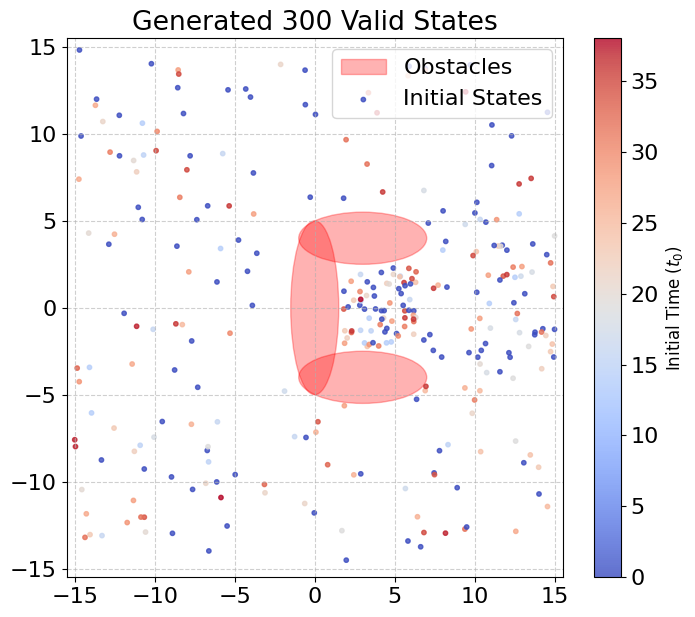

COmputing OCPs: 100%|██████████| 300/300 [01:08<00:00,  4.36traj/s]


--- Finished ---
Successfully solved: 300 / 300
States Buffer size: (10705, 3) samples
Time taken: 69.214 s


In [17]:
# First CACTO iteration: we do not use the actor to warm start since it is not trained yet
solve_TO_problems(use_actor_to_warm_start=False)

## 2) Train the critic network

Define a function to plot the critic network for a certain time, together with the data computed with TO.

In [18]:
def plot_critic(crit, t=0, show=True):
    # Get data from replay buffer
    X = replay_buffer.getX()          # Shape: [N, 3] -> [x, y, t]
    V_true = replay_buffer.getV()   
    
    # Filter points at time 't'
    ind = jnp.where(X[:, 2] == t)[0]  
    X_t = X[ind, :2]                  
    V_t = V_true[ind]

    # Create 2D grid for the Critic
    x_lin = np.linspace(x_min, x_max, 50)
    y_lin = np.linspace(y_min, y_max, 50)
    X_mesh, Y_mesh = np.meshgrid(x_lin, y_lin)
    
    # Flatten grid and add time column
    grid_flat = np.c_[X_mesh.ravel(), Y_mesh.ravel()]
    time_col = np.full((grid_flat.shape[0], 1), t)
    X_aug = jnp.hstack([grid_flat, time_col])

    # Predict values on the grid
    V_crit = crit(X_aug).reshape(X_mesh.shape)

    # --- Plotting ---
    plt.figure(figsize=(10, 8))
    
    # Critic heatmap
    cp = plt.contourf(X_mesh, Y_mesh, V_crit, levels=40, cmap='viridis', alpha=0.8)
    plt.colorbar(cp, label="Critic Value (Normalized)")

    # True values from buffer
    if len(ind) > 0:
        plt.scatter(X_t[:, 0], X_t[:, 1], c=V_t, cmap='viridis', 
                    edgecolors='k', marker='o', s=50, label='True Value (CasADi)')

    # Draw obstacles
    for param in obstacle_parameters:
        ellipse = Ellipse((param['x_ob'], param['y_ob']), 2*param['a'], 2*param['b'], 
                          color='red', alpha=0.5)
        plt.gca().add_patch(ellipse)
        
    # Draw target
    plt.plot(target_pos[0], target_pos[1], 'r*', markersize=15, label='Target')

    plt.title(f"Critic '{crit.name}' prediction at t={t}, samples num.={len(ind)}")
    plt.xlabel("X Position")
    plt.ylabel("Y Position")
    plt.legend()
    
    if show:
        plt.show()

Start the training using the data from the buffer.

In [19]:
def train_critic():
    
    print(f"--- CACTO Iteration {iteration_cnt} ---")
    print("--- Start training critic ---")
    
    # 1. Get the data from the buffer
    X_aug, V_buffer = replay_buffer.getX(), replay_buffer.getV() 

    print(f"Replay buffer size: {X_aug.shape[0]} samples")
    
    # 2. Start the training using epochs and sequential minibatches
    final_mse = critic.train(
        X_aug, 
        V_buffer, 
        n_epochs=critic_epochs, # Use critic_epochs as the number of epochs
        minibatch_size=minibatch_size,
        print_every=5              # Print progress every 5 epochs
    )
    
    # 3. Final summary
    final_rmse = np.sqrt(final_mse)
    print(f"Final Critic MSE: {final_mse:.2f}")
    print(f"Final Critic RMSE: {final_rmse:.2f}")
    print("--- Critic training has finished ---")
        
        
train_critic()

# Update the critic cycles counter
critic_cycles += cycles_counter(replay_buffer, minibatch_size, critic_epochs)
print(f"\n\nTotal critic cycles: {critic_cycles}")

--- CACTO Iteration 1 ---
--- Start training critic ---
Replay buffer size: 10705 samples
Epoch 1/35 | MSE: 17449.0527 | RMSE: 132.0949 | LR: 0.005000 | step: 42
Epoch 5/35 | MSE: 4976.9424 | RMSE: 70.5474 | LR: 0.005000 | step: 210
Epoch 10/35 | MSE: 1729.2487 | RMSE: 41.5842 | LR: 0.005000 | step: 420
Epoch 15/35 | MSE: 1912.9424 | RMSE: 43.7372 | LR: 0.005000 | step: 630
Epoch 20/35 | MSE: 1187.3152 | RMSE: 34.4574 | LR: 0.005000 | step: 840
Epoch 25/35 | MSE: 455.4558 | RMSE: 21.3414 | LR: 0.003750 | step: 1050
Epoch 30/35 | MSE: 226.6280 | RMSE: 15.0542 | LR: 0.003750 | step: 1260
Epoch 35/35 | MSE: 208.1418 | RMSE: 14.4271 | LR: 0.003750 | step: 1470
Final Critic MSE: 208.14
Final Critic RMSE: 14.43
--- Critic training has finished ---


Total critic cycles: 1470


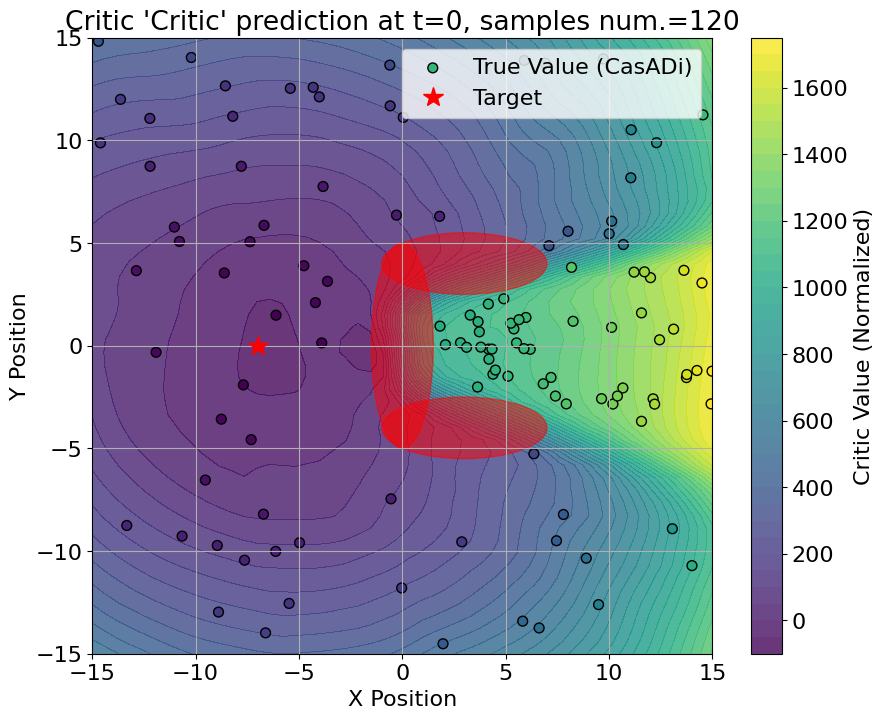

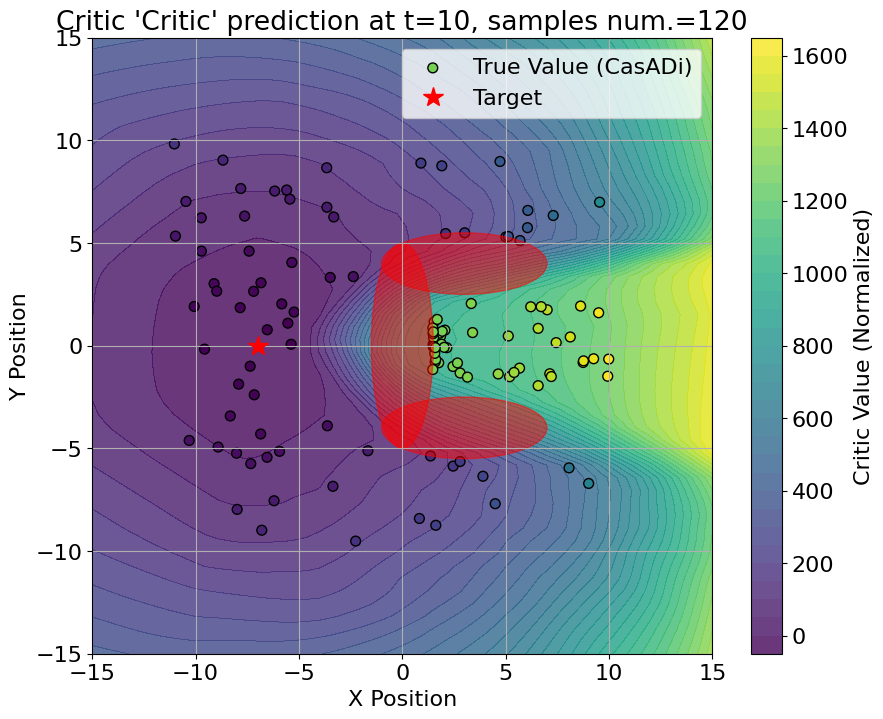

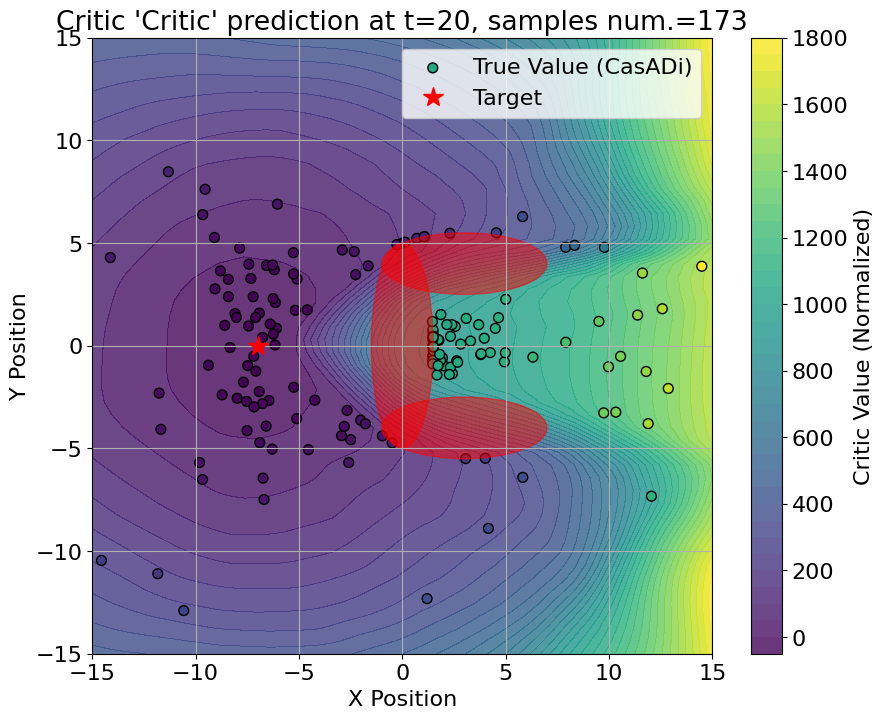

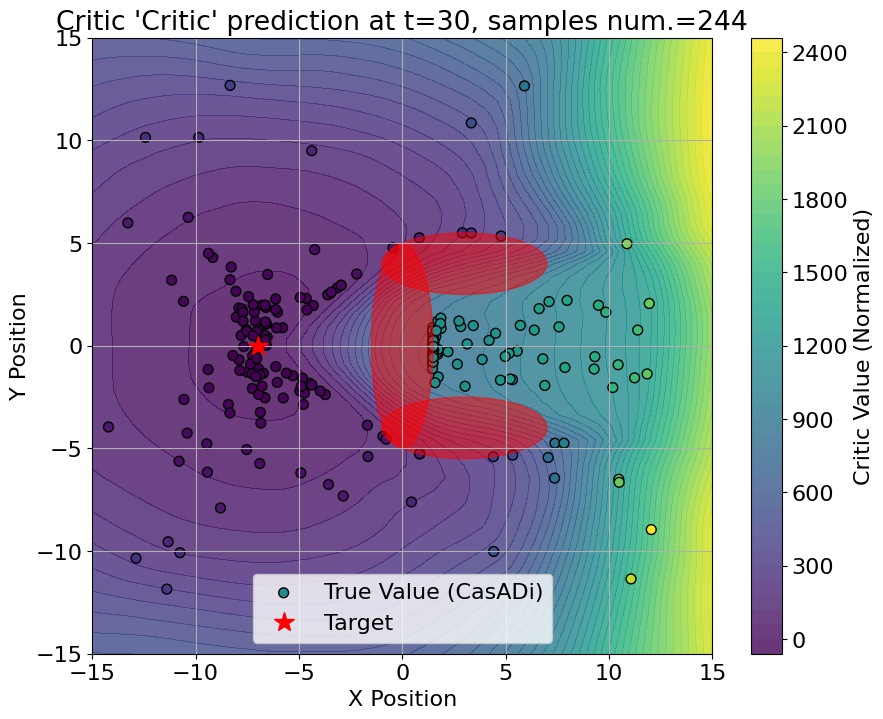

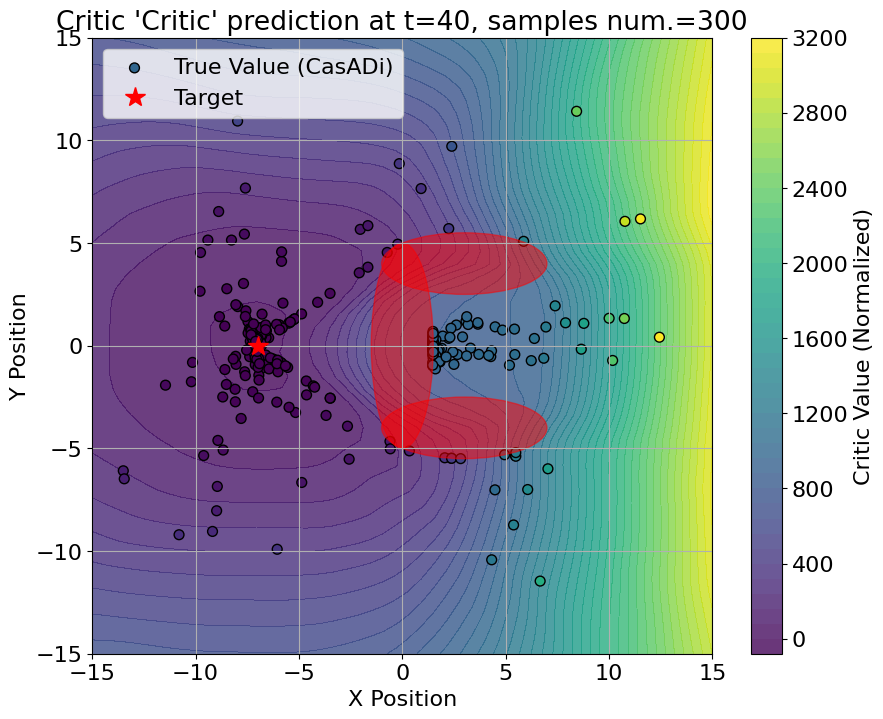

In [20]:
for t in range(0, N, 10):
    plot_critic(critic, t, show=False)

## 3) Train the constrained actor network

In [21]:
def plot_constr_actor(t=0, show=True, plot_u_ocp=True):
    """
    Visualizes the Actor's policy at a specific time 't' using a Quiver plot.
    """
    # 1. Prepare the 2D grid for prediction
    t_vec = t * jnp.ones((X_grid_2d.shape[0], 1))
    X_aug_grid = jnp.hstack([X_grid_2d, t_vec])
    
    # 2. Get Actor predictions (Control inputs) across the grid
    u_pred = cons_actor(X_aug_grid) # Expected shape: (N*N, 2)
    
    plt.figure(figsize=(10, 8))
    
    # 3. Plot obstacles for reference
    theta = np.linspace(0, 2*np.pi, 100)
    for obs in obstacle_parameters:

        x_obs = obs['x_ob'] + obs['a'] * np.cos(theta)
        y_obs = obs['y_ob'] + obs['b'] * np.sin(theta)
        plt.plot(x_obs, y_obs, 'r-', linewidth=2)
        
    # 4. Quiver Plot: Visualize control vectors as arrows
    # 'skip' prevents the plot from being too crowded
    skip = 3 
    plt.quiver(X_grid_2d[::skip, 0], X_grid_2d[::skip, 1], 
               u_pred[::skip, 0], u_pred[::skip, 1], 
               color='blue', alpha=0.6, label='Actor Policy (u)')

    # 6. Formatting
    plt.plot(target_pos[0], target_pos[1], 'r*', markersize=15, label='Target')
    plt.title(f"Actor Policy Visualization (Quiver Plot) at t={t}")
    plt.xlabel("Position x")
    plt.ylabel("Position y")
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.6)
    
    if show:
        plt.show()

In [22]:
def train_constr_actor():
    print(f"--- CACTO Iteration {iteration_cnt} ---")
    print("--- Start training the constrained actor ---")
    start_time = timeit.default_timer()
    
    # 1. Fetch training data from the buffer
    X_train_aug = replay_buffer.getX() 
    
    # Safety check: ensure the buffer is not empty
    if X_train_aug.shape[0] == 0:
        print("WARNING: Replay Buffer is empty! Skipping Actor training.")
        return
        
    # 2. Define the Q-function for diagnostics using the actor's internal functions
    @jax.jit
    def Q_func(u, x_aug):
        # Usiamo i metodi dell'attore per coerenza matematica
        x_next_aug = cons_actor.dynamic(x_aug, u)
        return cons_actor.cost(x_aug, u) + critic(x_next_aug)[0]
    
    # Compute the gradient of Q and vmap it for batch processing
    grad_Q = jax.jit(jax.grad(Q_func, argnums=0))
    grad_Q_vmap = jax.jit(jax.vmap(grad_Q))
    
    # 3. Execute the epoch-based training directly through the Actor class
    actor_loss, final_lam, final_rho = cons_actor.train(
        X_train_aug, 
        n_epochs=actor_epochs, 
        minibatch_size=minibatch_size,
        print_every=5,
        grad_Q_vmap=grad_Q_vmap  
    ) 
    
    # 4. Diagnostic: Evaluate how well the actor minimizes the Critic's Value
    U_pred = cons_actor(X_train_aug)
    dQdu_final = grad_Q_vmap(U_pred, X_train_aug)
    dQdu_norm_final = jnp.mean(jnp.linalg.norm(dQdu_final, axis=1)) 
    
    print(f"Final Constrained Actor loss (Mean Q): {actor_loss:.6f} \t Final dQ/du norm: {dQdu_norm_final:.6f}")
    print(f"Final ALM Parameters -> Lambda: {final_lam} | Rho: {final_rho}")
            
    duration = timeit.default_timer() - start_time
    print(f"--- Finished training constrained actor ({duration:.3f} s) ---")

# Run the training
train_constr_actor()

# Update the constrained actor cycles counter
actor_cycles += cycles_counter(replay_buffer, minibatch_size, actor_epochs)
print(f"\nTotal constrained actor cycles: {actor_cycles}")

--- CACTO Iteration 1 ---
--- Start training the constrained actor ---
--- Starting Constrained Actor training for 35 epochs ---
Epoch 1/35 | Mean Q+ALM: 481.9998 | Max Viol: 0.13784 | Lambda: [22.76 20.01 20.06] | Rho: 50.5 | LR: 0.000500 | step: 42
 | dQ/du norm: 1.868297
Epoch 5/35 | Mean Q+ALM: 478.5636 | Max Viol: 0.13804 | Lambda: [34.09 20.14 20.32] | Rho: 52.6 | LR: 0.000500 | step: 210
 | dQ/du norm: 1.461811
Epoch 10/35 | Mean Q+ALM: 474.1043 | Max Viol: 0.00088 | Lambda: [39.6  20.33 20.39] | Rho: 55.2 | LR: 0.000500 | step: 420
 | dQ/du norm: 1.635707
Epoch 15/35 | Mean Q+ALM: 473.5846 | Max Viol: 0.00982 | Lambda: [41.74 20.5  20.55] | Rho: 58.0 | LR: 0.000500 | step: 630
 | dQ/du norm: 1.593465
Epoch 20/35 | Mean Q+ALM: 472.7389 | Max Viol: 0.02038 | Lambda: [43.62 20.63 20.75] | Rho: 61.0 | LR: 0.000500 | step: 840
 | dQ/du norm: 1.361607
Epoch 25/35 | Mean Q+ALM: 472.7624 | Max Viol: 0.00550 | Lambda: [44.27 20.82 20.94] | Rho: 64.1 | LR: 0.000400 | step: 1050
 | dQ/du 

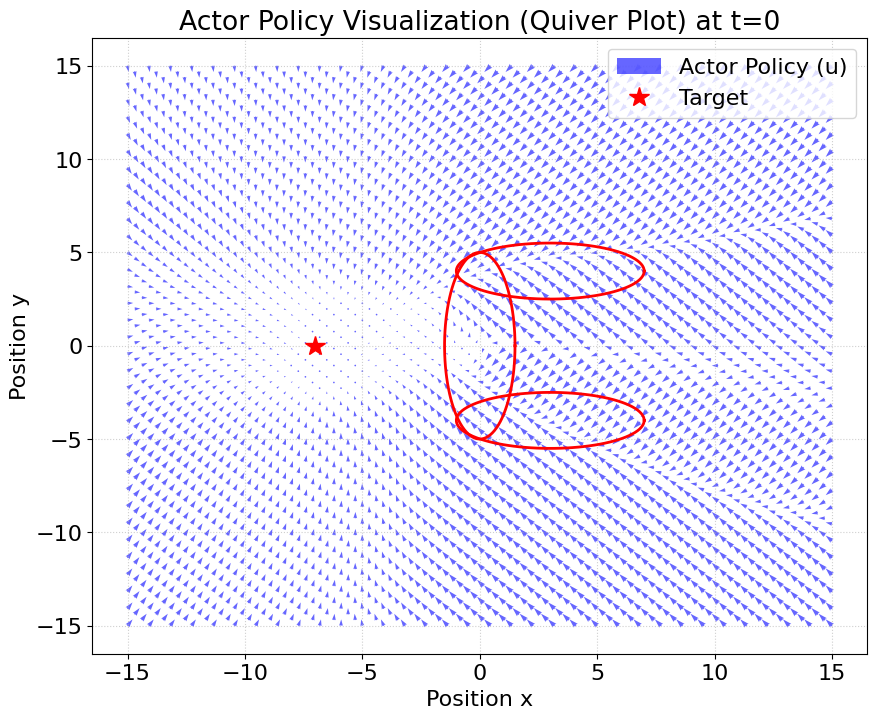

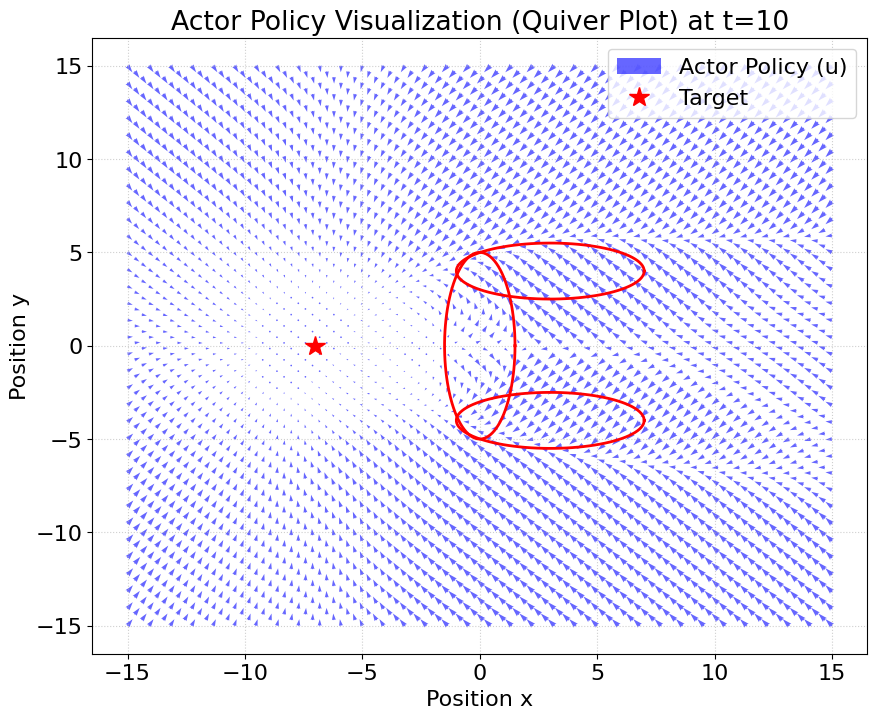

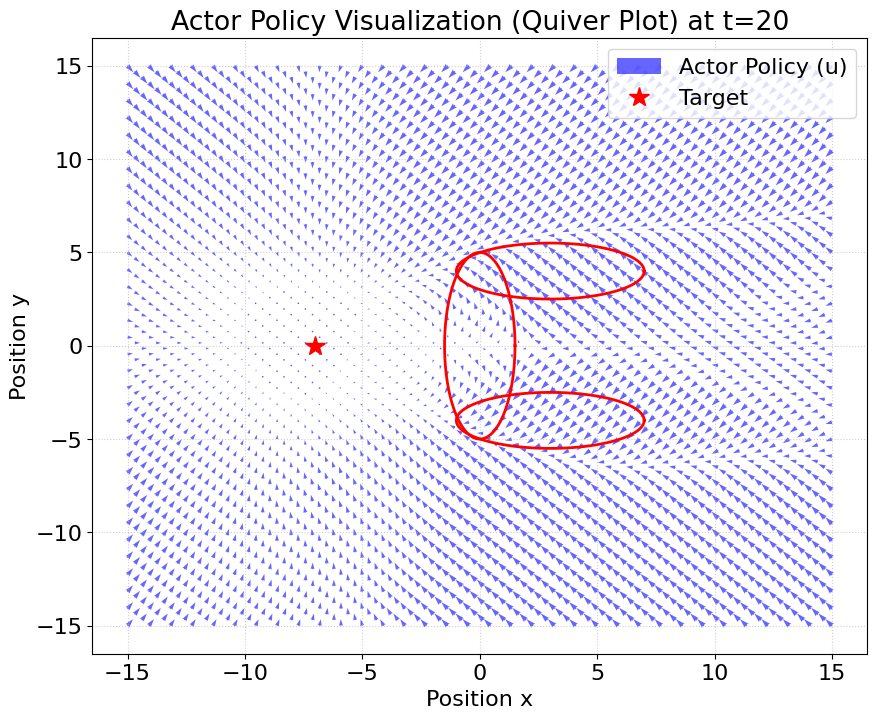

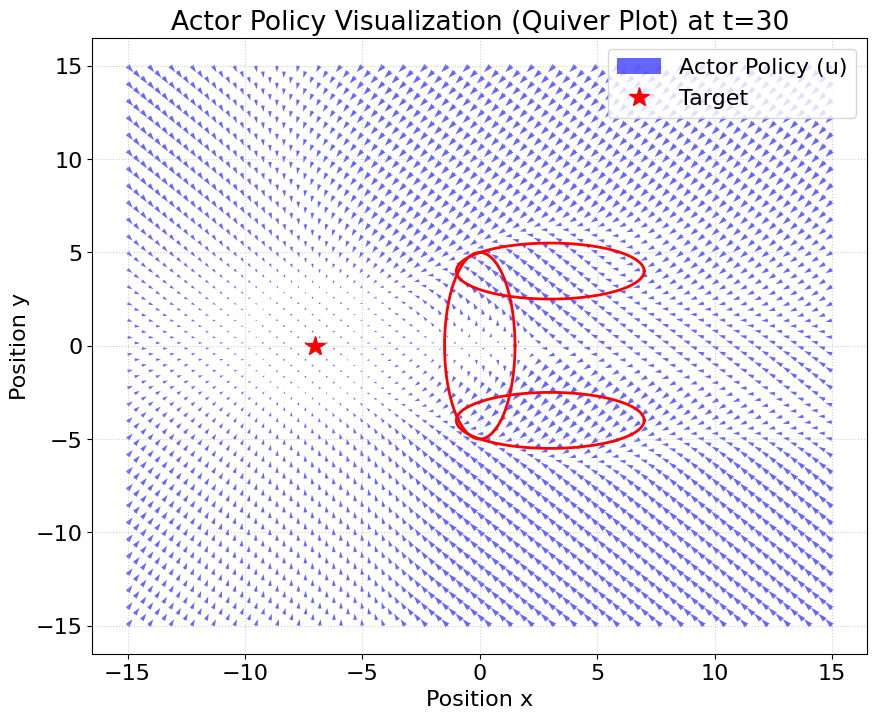

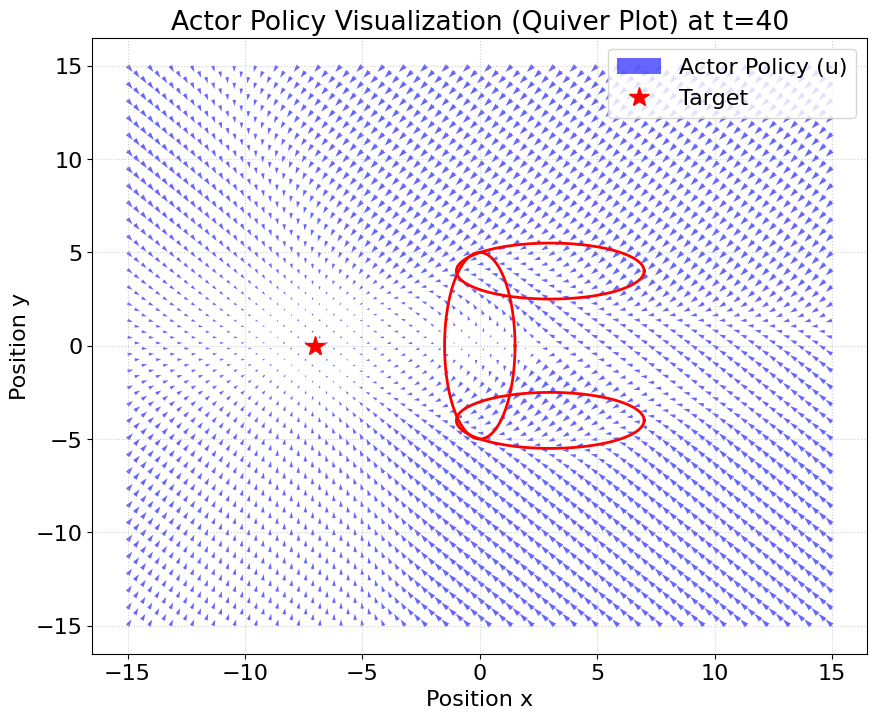

In [23]:
for t in range(0, N, 10):
    plot_constr_actor(t, show=True, plot_u_ocp=True)

## 4) Evaluate TO with constrained actor's initial guess

First compute the initial guesses by getting the cotnrols form the constrined actor and the corresponding states from the dynamics.

In [24]:
def check_2d_constraints(X_traj, obstacles_params, tol=1e-4):
    """
    Helper function to check if a given trajectory violates the elliptical constraints defined by the obstacles.
    Returns: feasible (bool), max_violation (float)
    """
    max_viol = 0.0
    
    # Evaluate every point in the trajectory
    for state in X_traj:
        # Get the g(x) values for all the trajectory points with respect to all obstacles
        g_vals = elliptical_constraints(state, obstacles_params, backend='numpy')
        
        for g in g_vals:
            # If g < 0, we are inside the ellipse (violation)
            viol = max(0.0, -g) 
            if viol > max_viol:
                max_viol = viol
            
    feasible = max_viol <= tol
    return feasible, max_viol

Plot the constrained actor rollouts to see the resulting trajectories.

Actor Only -> Feasible: 8/37 | Violating: 29/37
Actor Only -> Avg. max violation: 0.5688
Actor Only -> Avg. cost: 273.5012

Costs and Feasibility List:
Rollout 001 | Xini: (-10.0, -10.0) | Cost:   129.29 | Status: OK
Rollout 002 | Xini: (-8.0, -5.0) | Cost:    -1.21 | Status: OK
Rollout 003 | Xini: (-10.0,  0.0) | Cost:   -30.11 | Status: OK
Rollout 004 | Xini: (-8.0,  5.0) | Cost:    -1.41 | Status: OK
Rollout 005 | Xini: (-10.0, 10.0) | Cost:   132.53 | Status: OK
Rollout 006 | Xini: ( 5.0,  0.0) | Cost:   287.52 | Status: VIOL
Rollout 007 | Xini: ( 6.0,  1.5) | Cost:   346.59 | Status: VIOL
Rollout 008 | Xini: ( 6.0, -1.5) | Cost:   333.75 | Status: VIOL
Rollout 009 | Xini: ( 5.5,  2.5) | Cost:   317.95 | Status: VIOL
Rollout 010 | Xini: ( 5.5, -2.5) | Cost:   300.21 | Status: VIOL
Rollout 011 | Xini: ( 2.0,  0.0) | Cost:   161.95 | Status: VIOL
Rollout 012 | Xini: ( 1.5,  1.0) | Cost:   137.83 | Status: VIOL
Rollout 013 | Xini: ( 1.5, -2.0) | Cost:   116.15 | Status: VIOL
Rollout 0

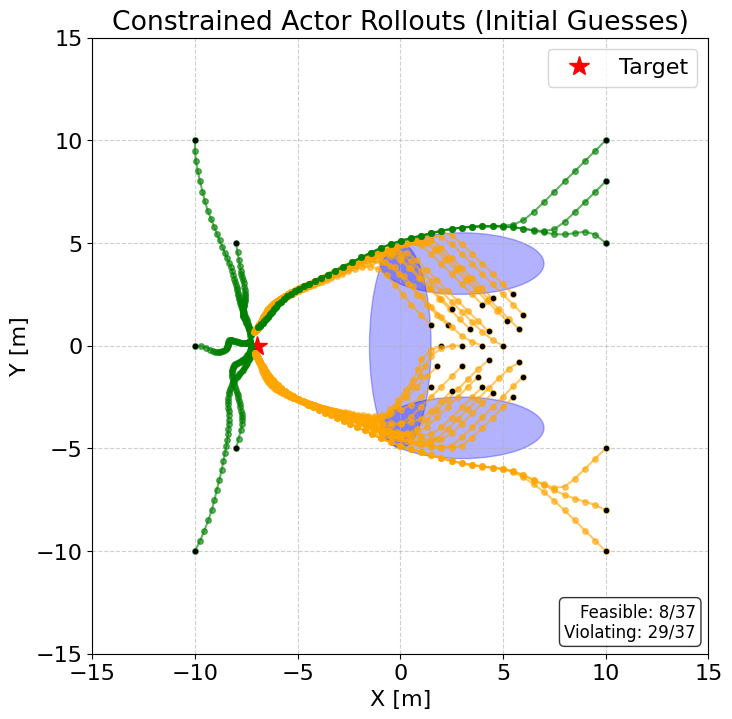

In [25]:
def plot_cons_actor_rollouts(print_costs=False):
    fig, ax = plt.subplots(figsize=(10, 8))
    
    # 1. Draw obstacles and target
    plot_ellipses(obstacle_parameters, ax=ax, target=target_pos)

    n_total = len(X_init_grid)
    n_feasible, n_violating = 0, 0
    maxv_list = []
    
    # Inizializziamo i tempi a zero
    t0_grid = np.zeros(n_total)
    
    # Batch computation delle traiettorie
    X_guess_list, U_guess_list, V_list = compute_initial_guess(X_init_grid, t0_grid, N, cons_actor)

    # List to store the feasibility status of each trajectory for later use in printing costs
    feasibility_status = []

    # Check constraints and plot each trajectory
    for i in range(n_total):
        X_guess = X_guess_list[i]
        x_init = X_init_grid[i] 
        
        # Check 2D constraints
        feasible, maxv = check_2d_constraints(X_guess, obstacle_parameters)
        n_feasible += int(feasible)
        n_violating += int(not feasible)
        maxv_list.append(maxv)
        feasibility_status.append(feasible)

        color = 'green' if feasible else 'orange'
        ax.plot(X_guess[:, 0], X_guess[:, 1], color=color, alpha=0.6, linewidth=1.5, marker='o', markersize=4)
        ax.plot(x_init[0], x_init[1], 'ko', markersize=3) # Start point
        
    avg_cost = np.mean(V_list)    
    
    # Print summary statistics
    print(f"Actor Only -> Feasible: {n_feasible}/{n_total} | Violating: {n_violating}/{n_total}")
    print(f"Actor Only -> Avg. max violation: {np.mean(maxv_list):.4f}")
    print(f"Actor Only -> Avg. cost: {avg_cost:.4f}")
    
    if print_costs:
        print("\nCosts and Feasibility List:")
        for idx in range(n_total):
            c = V_list[idx]
            xi = X_init_grid[idx] # Corretto: prende l'X_init specifico per l'indice
            status = "OK" if feasibility_status[idx] else "VIOL"
            print(f"Rollout {idx+1:03d} | Xini: ({xi[0]:4.1f}, {xi[1]:4.1f}) | Cost: {c:8.2f} | Status: {status}")
            
    # Add text box with stats
    ax.text(0.98, 0.02, f"Feasible: {n_feasible}/{n_total}\nViolating: {n_violating}/{n_total}",
            transform=ax.transAxes, fontsize=12, ha="right", va="bottom",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))

    ax.set_title("Constrained Actor Rollouts (Initial Guesses)")
    plt.show()

# Function call
plot_cons_actor_rollouts(print_costs=True)

Now solve the TO with the consrained actor trajectoris for warm start.
Uses as initial states the ones defined at the beginning (variable `init_pos`).

Computing initial guesses in batch...
Skip i=5: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=10: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=11: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=12: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=13: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=14: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variabl

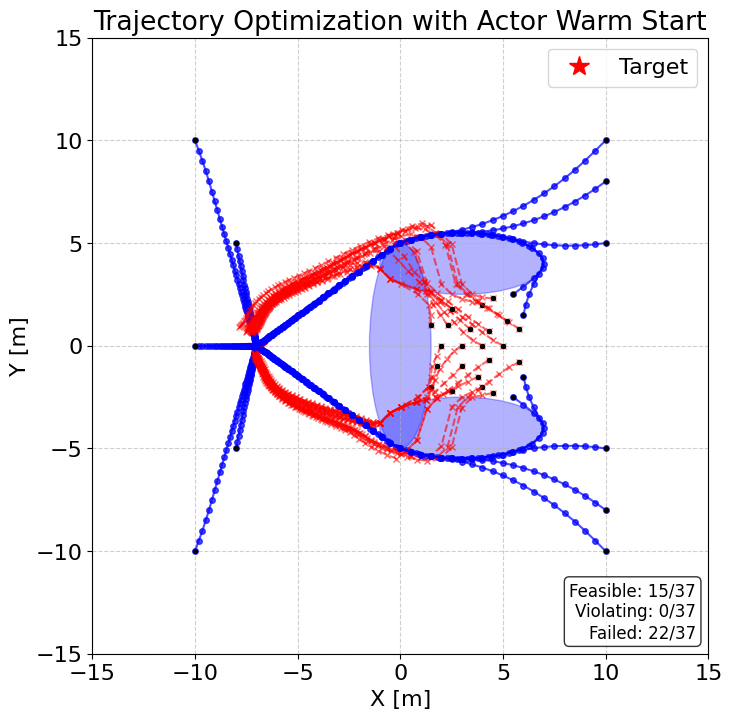

In [26]:
def evaluate_TO_w_cons_warm_start():
    '''
    Evaluates the performance of the trajectory optimization solver when warm-started with the constrained 
    actor's rollouts.
    For each initial state in the grid, it computes the initial guess using the constrained actor, solves the OCP, 
    and checks for constraint violations.
    It also visualizes the resulting trajectories and prints summary statistics about feasibility and solver success.
    '''

    fig, ax = plt.subplots(figsize=(10, 8))
    
    # 1. Draw obstacles and target 
    plot_ellipses(obstacle_parameters, ax=ax, target=target_pos)

    # Variables initialization
    V_TO = np.full(len(X_init_grid), np.nan)
    n_total = len(X_init_grid)
    n_feasible, n_violating, n_failed = 0, 0, 0
    maxv_list = []
    all_cons_x_trajs = []

    start_time = timeit.default_timer()
    
    # Compute initial guesses for warm start in batch using the constrained actor
    print("Computing initial guesses in batch...")
    t0_grid = np.zeros(n_total)
    X_guess_batch, U_guess_batch, _ = compute_initial_guess(
        X_init_grid, t0_grid, N, cons_actor
    )

    # Solve OCP for each initial state using the corresponding warm start and check constraints
    for i, x_init in enumerate(X_init_grid):
        
        X_guess = np.array(X_guess_batch[i])
        U_guess = np.array(U_guess_batch[i])

        try:
            sol = ocp.solve(x_init, N, X_guess, U_guess)
        except Exception as e:
            n_failed += 1
            print(f"Skip i={i}: OCP failed | Error: {str(e).splitlines()[-1]}")
            
            x_traj_failed = ocp.opti.debug.value(ocp.x).T
                
            # Plot the failed trajectory in red dashed line with 'x' markers
            ax.plot(x_traj_failed[:, 0], x_traj_failed[:, 1], color='red', linestyle='--', alpha=0.6, linewidth=1.5, marker='x', markersize=4)
            ax.plot(x_init[0], x_init[1], 'ko', markersize=3)
            continue

        V_TO[i] = sol.value(ocp.cost)
        x_traj_opt = sol.value(ocp.x).T 
        all_cons_x_trajs.append(x_traj_opt)

        feasible, maxv = check_2d_constraints(x_traj_opt, obstacle_parameters)
        n_feasible += int(feasible)
        n_violating += int(not feasible)
        maxv_list.append(maxv)

        color = 'blue' if feasible else 'red'
        ax.plot(x_traj_opt[:, 0], x_traj_opt[:, 1], color=color, alpha=0.7, linewidth=1.5, marker='o', markersize=4)
        ax.plot(x_init[0], x_init[1], 'ko', markersize=3)

    print(f"TO + Warm Start -> Time: {timeit.default_timer() - start_time:.3f} s")
    print(f"TO + Warm Start -> Feasible: {n_feasible}/{n_total} | Failed: {n_failed}/{n_total}")
    

    ax.text(0.98, 0.02, f"Feasible: {n_feasible}/{n_total}\nViolating: {n_violating}/{n_total}\nFailed: {n_failed}/{n_total}",
            transform=ax.transAxes, fontsize=12, ha="right", va="bottom",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))

    ax.set_title("Trajectory Optimization with Actor Warm Start")
    plt.show()

    return V_TO, all_cons_x_trajs

# --- RUN ---
V_TO, all_cons_x_trajs = evaluate_TO_w_cons_warm_start()

## Re-iterate the procedure

Now we repeat the stesp 1), 2), 3b) and 4) unitll we get good results.

--- CACTO Iteration 2 ---
Start solving 300 TO problems


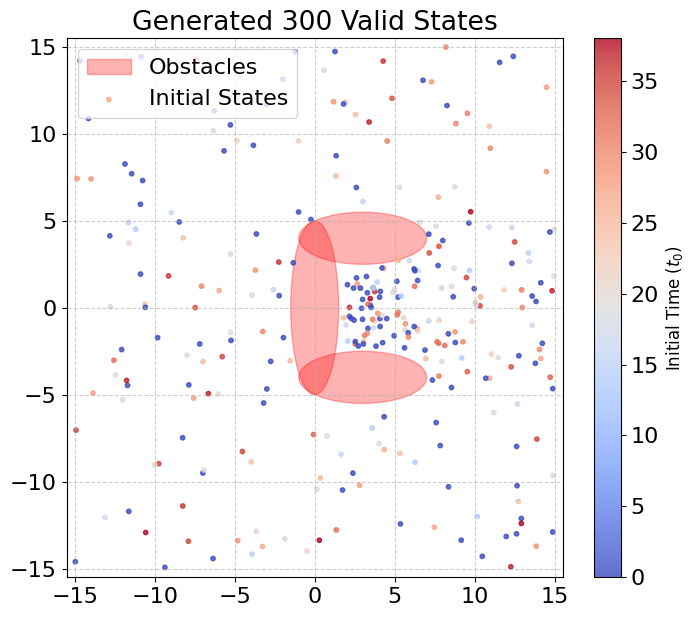

Computing warm start guesses via Actor...


COmputing OCPs: 100%|██████████| 300/300 [01:18<00:00,  3.80traj/s]


--- Finished ---
Successfully solved: 300 / 300
States Buffer size: (21453, 3) samples
Time taken: 81.728 s


In [27]:
# Solve an OCP for every sampled initial state-time using the constrained actor for warm start
solve_TO_problems(use_actor_to_warm_start=True, actor=cons_actor)

--- CACTO Iteration 2 ---
--- Start training critic ---
Replay buffer size: 21453 samples
Epoch 1/35 | MSE: 2021.1113 | RMSE: 44.9568 | LR: 0.005000 | step: 84
Epoch 5/35 | MSE: 1298.0251 | RMSE: 36.0281 | LR: 0.005000 | step: 420
Epoch 10/35 | MSE: 1222.2325 | RMSE: 34.9604 | LR: 0.005000 | step: 840
Epoch 15/35 | MSE: 1021.6439 | RMSE: 31.9632 | LR: 0.003750 | step: 1260
Epoch 20/35 | MSE: 897.4596 | RMSE: 29.9576 | LR: 0.002812 | step: 1680
Epoch 25/35 | MSE: 822.7551 | RMSE: 28.6837 | LR: 0.002109 | step: 2100
Epoch 30/35 | MSE: 830.4073 | RMSE: 28.8168 | LR: 0.001582 | step: 2520
Epoch 35/35 | MSE: 736.0496 | RMSE: 27.1302 | LR: 0.001582 | step: 2940
Final Critic MSE: 736.05
Final Critic RMSE: 27.13
--- Critic training has finished ---

Total critic cycles: 4410


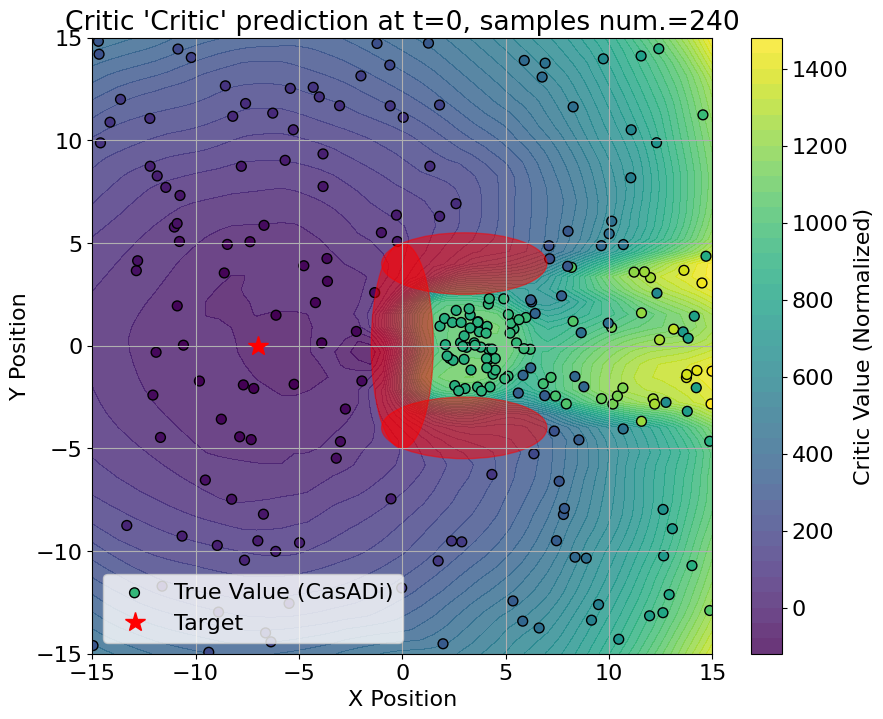

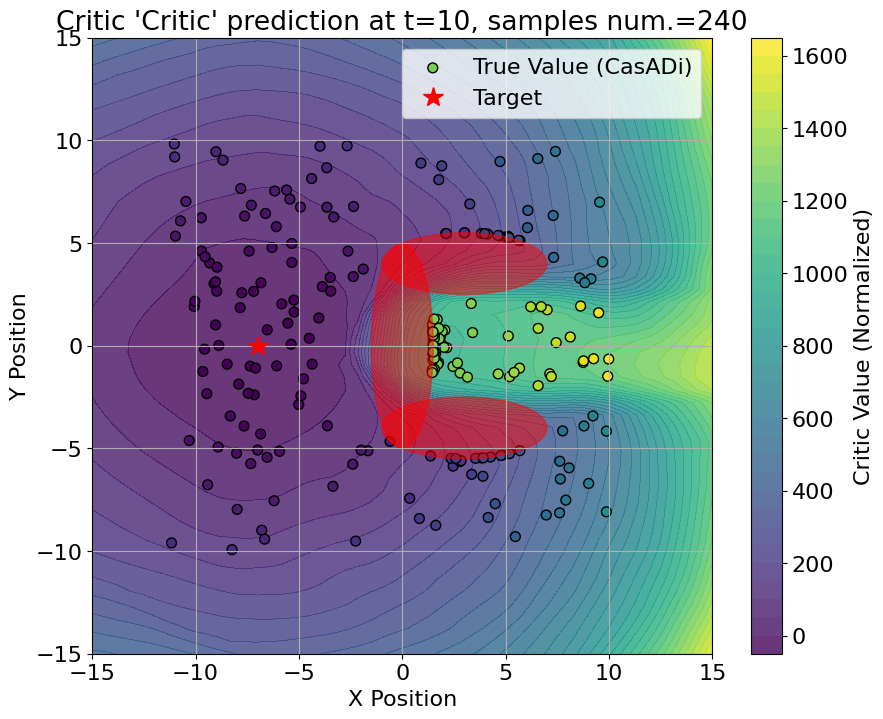

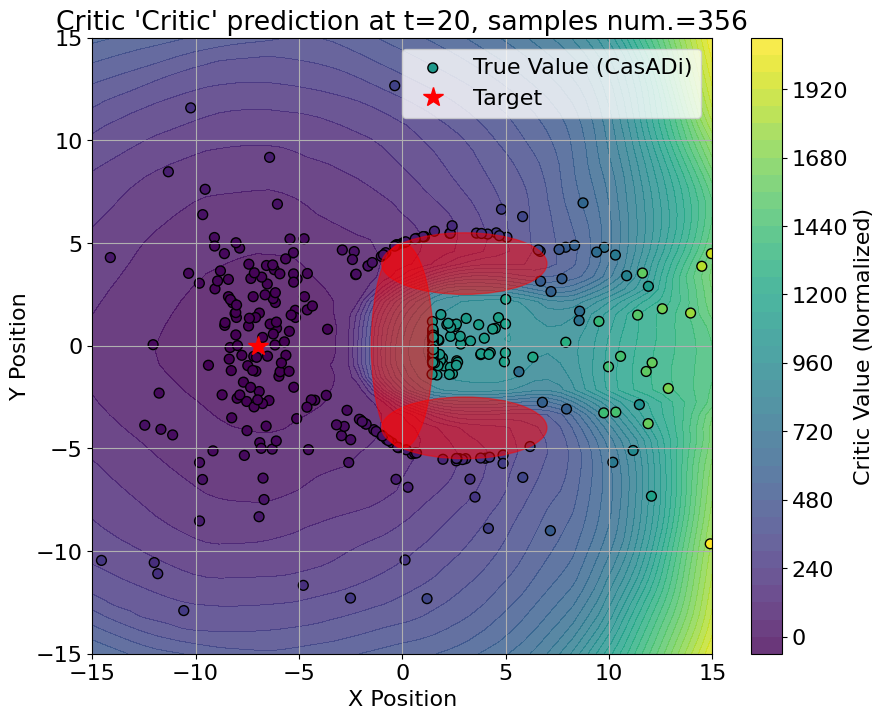

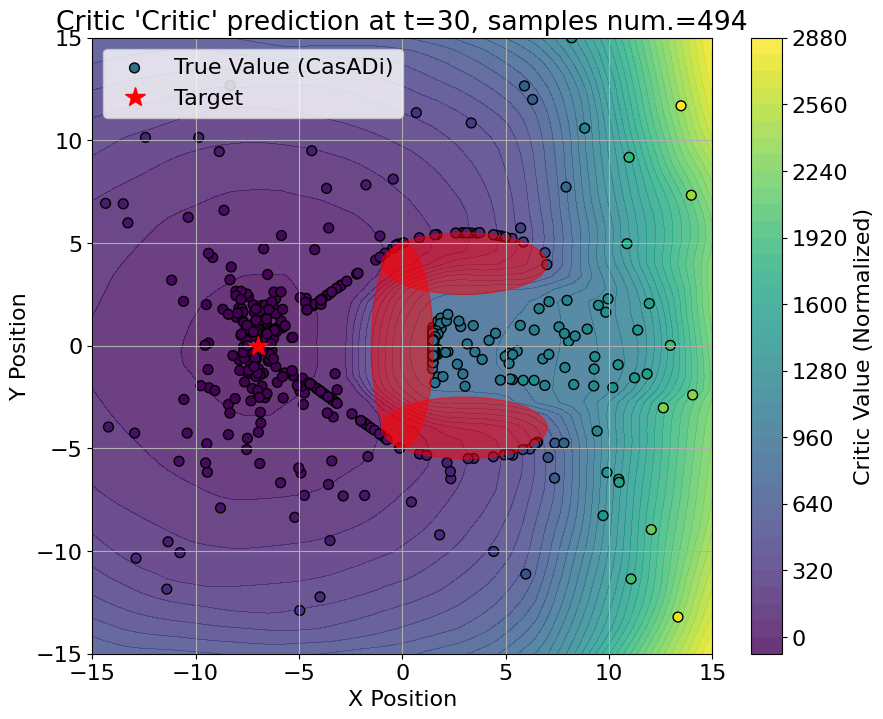

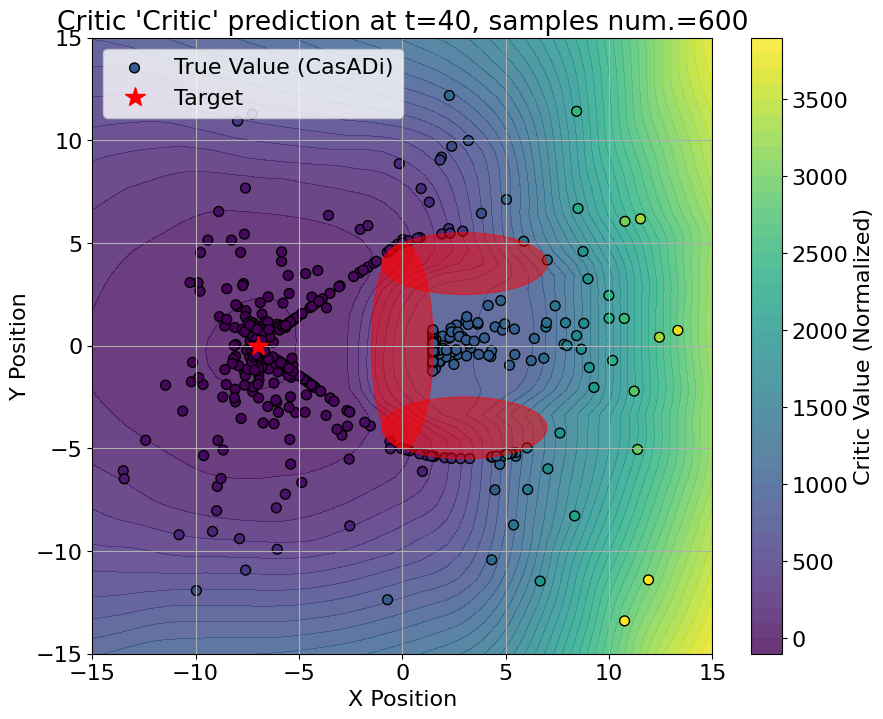

In [28]:
# Train the critic again with the new data in the buffer 
train_critic()

# Update the critic cycles counter
critic_cycles += cycles_counter(replay_buffer, minibatch_size, critic_epochs)
print(f"\nTotal critic cycles: {critic_cycles}")

for t in range(0, N, 10):
  plot_critic(critic, t, show=False)

--- CACTO Iteration 2 ---
--- Start training the constrained actor ---
--- Starting Constrained Actor training for 35 epochs ---
Epoch 1/35 | Mean Q+ALM: 409.5081 | Max Viol: 0.00697 | Lambda: [46.22 21.17 21.27] | Rho: 71.5 | LR: 0.000500 | step: 84
 | dQ/du norm: 1.729225
Epoch 5/35 | Mean Q+ALM: 409.3836 | Max Viol: 0.00885 | Lambda: [46.71 21.34 21.61] | Rho: 74.4 | LR: 0.000500 | step: 420
 | dQ/du norm: 1.678539
Epoch 10/35 | Mean Q+ALM: 409.1316 | Max Viol: 0.00464 | Lambda: [47.61 21.54 21.93] | Rho: 78.2 | LR: 0.000500 | step: 840
 | dQ/du norm: 1.700204
Epoch 15/35 | Mean Q+ALM: 408.9019 | Max Viol: 0.00241 | Lambda: [48.2  21.84 22.24] | Rho: 82.2 | LR: 0.000400 | step: 1260
 | dQ/du norm: 1.663177
Epoch 20/35 | Mean Q+ALM: 409.1394 | Max Viol: 0.00708 | Lambda: [49.13 22.3  22.51] | Rho: 86.4 | LR: 0.000320 | step: 1680
 | dQ/du norm: 1.661305
Epoch 25/35 | Mean Q+ALM: 408.9107 | Max Viol: 0.00450 | Lambda: [49.86 22.64 22.83] | Rho: 90.8 | LR: 0.000256 | step: 2100
 | dQ/d

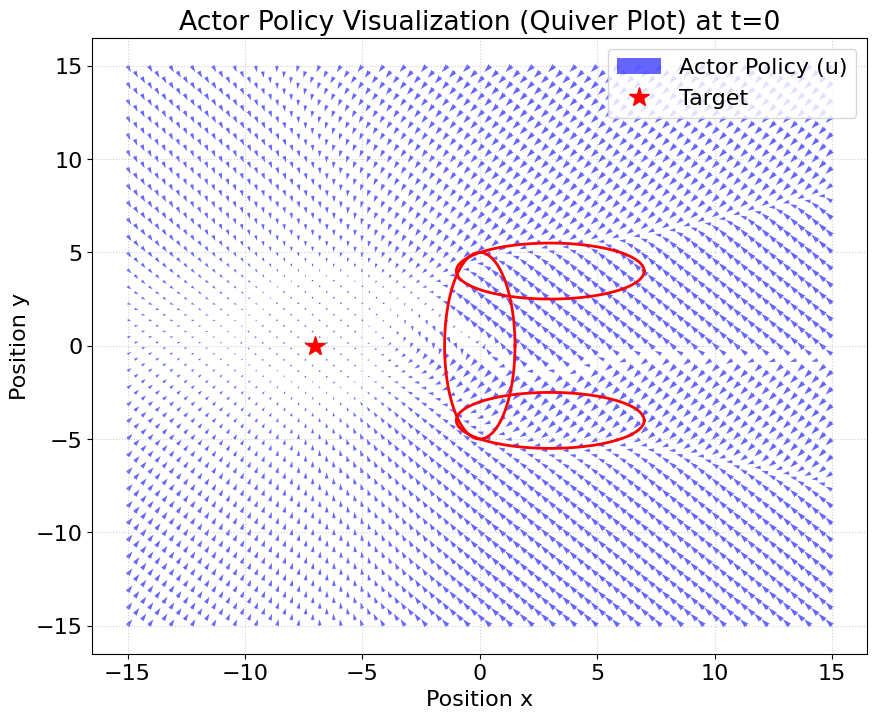

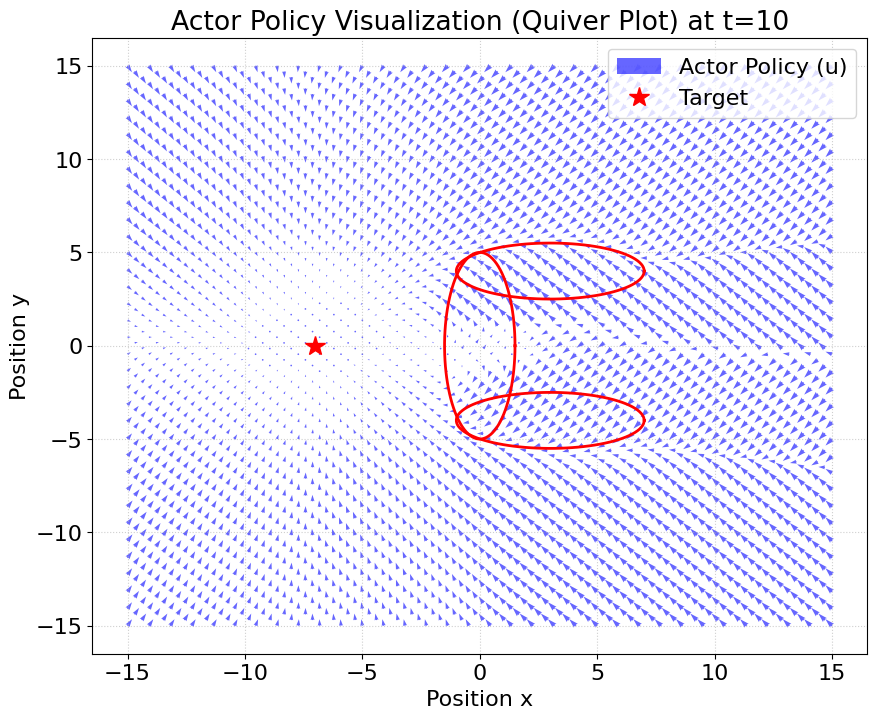

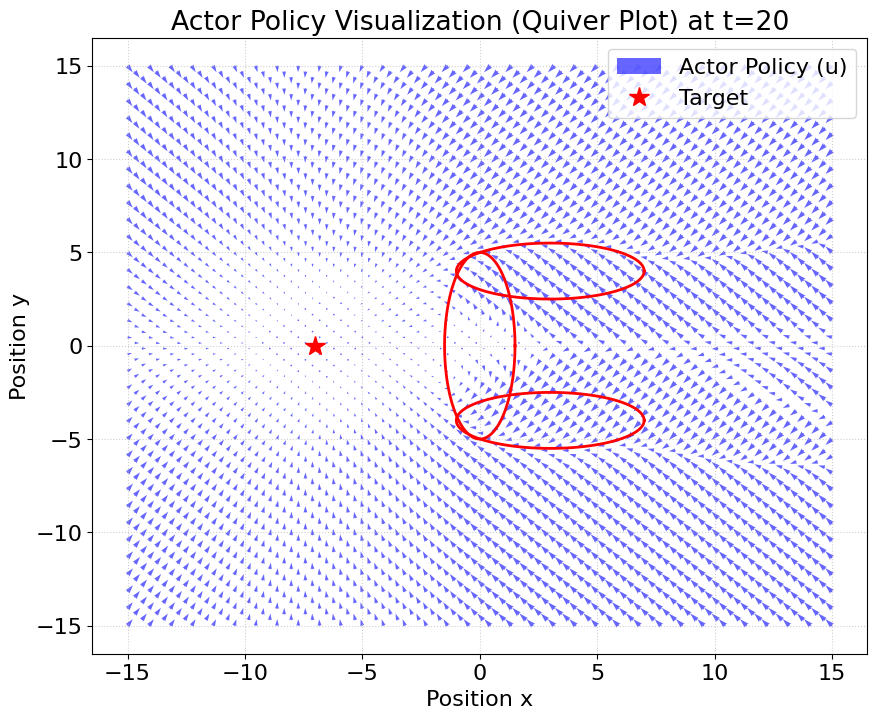

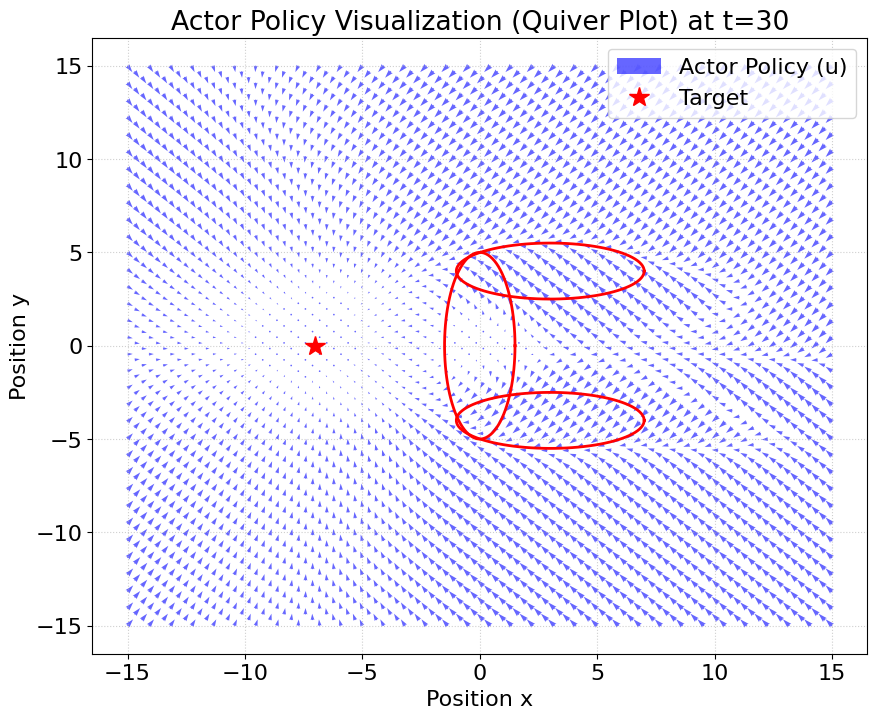

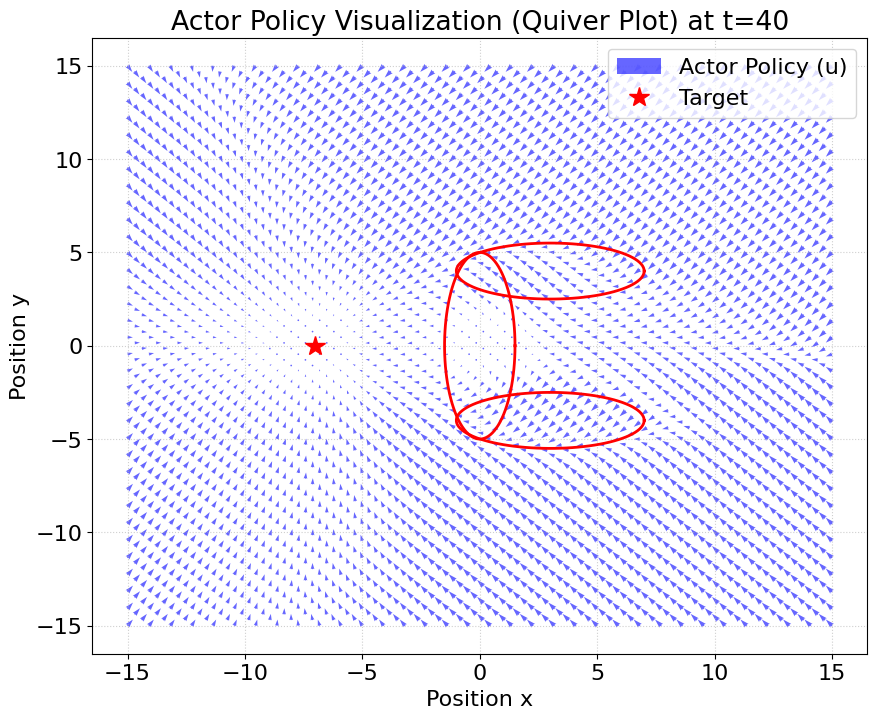

In [29]:
# Train the constrained actor again with the new critic

train_constr_actor()

# Update the constrained actor cycles counter
actor_cycles += cycles_counter(replay_buffer, minibatch_size, actor_epochs)
print(f"\nTotal constrained actor cycles: {actor_cycles}")


for t in range(0, N, 10):
  plot_constr_actor(t, show=True, plot_u_ocp=True)

Actor Only -> Feasible: 9/37 | Violating: 28/37
Actor Only -> Avg. max violation: 0.5704
Actor Only -> Avg. cost: 278.7818


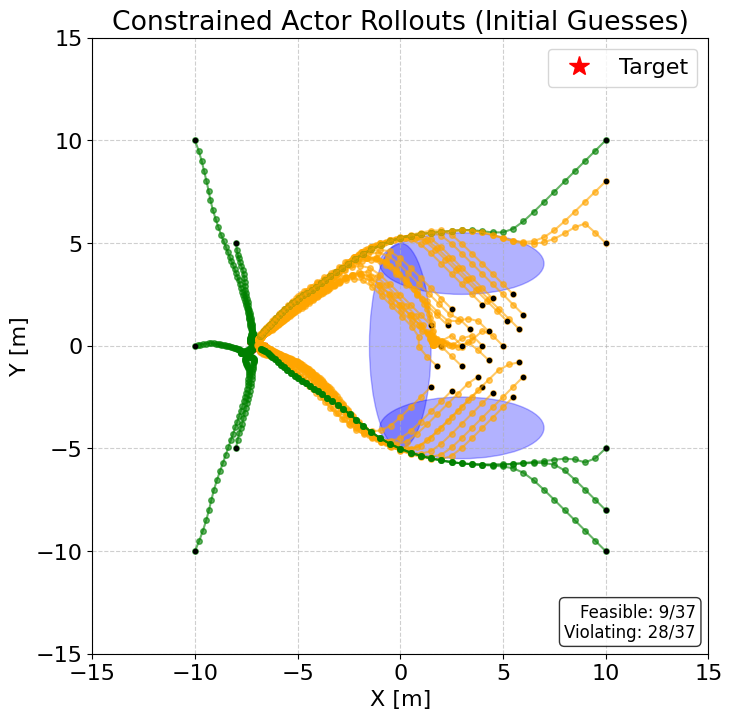

Computing initial guesses in batch...
Skip i=5: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=10: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=11: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=12: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=13: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=14: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variabl

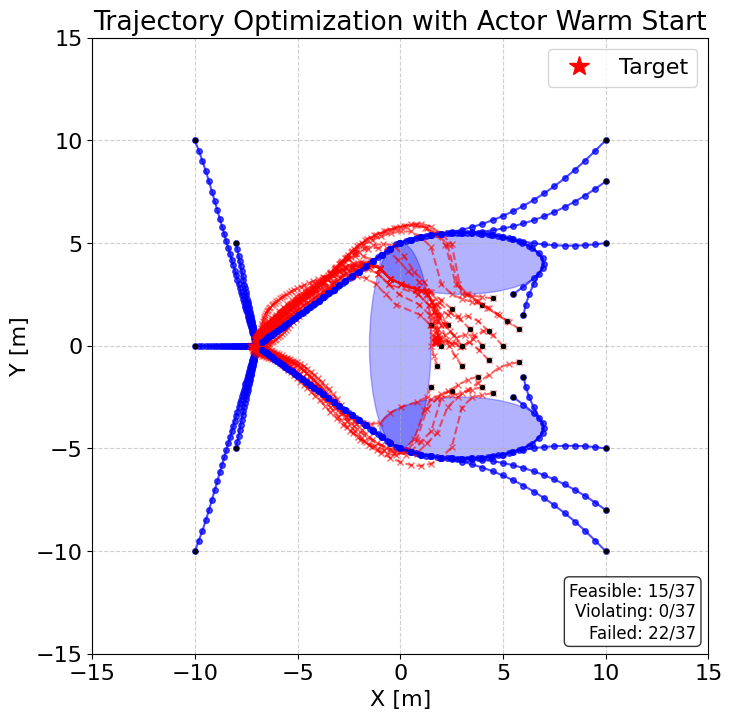

In [30]:
# Final evaluation of the constrained actor rollouts and TO performance after the last iteration
plot_cons_actor_rollouts()
V_TO, all_cons_x_trajs = evaluate_TO_w_cons_warm_start()

--- CACTO Iteration 3 ---
Start solving 300 TO problems


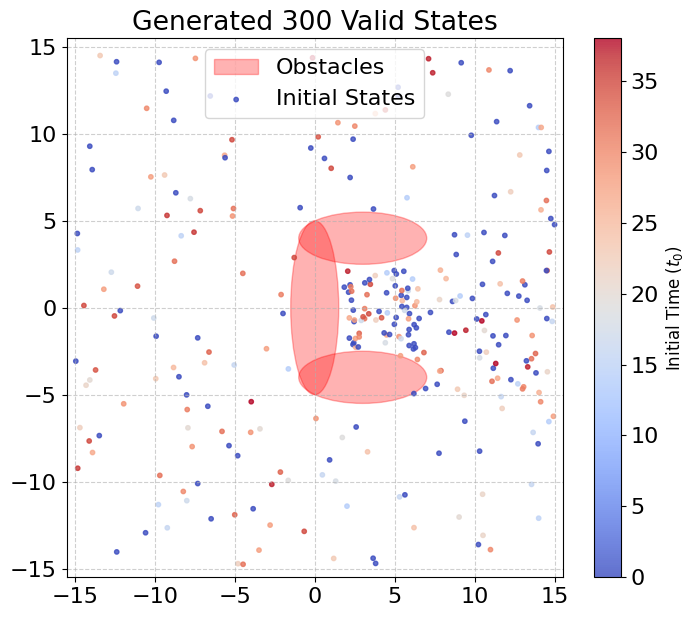

Computing warm start guesses via Actor...


COmputing OCPs: 100%|██████████| 300/300 [01:26<00:00,  3.48traj/s]


--- Finished ---
Successfully solved: 300 / 300
States Buffer size: (25000, 3) samples
Time taken: 88.717 s


In [31]:
# Solve an OCP for every sampled initial state-time using the constrained actor for warm start
solve_TO_problems(use_actor_to_warm_start=True, actor=cons_actor)

--- CACTO Iteration 3 ---
--- Start training critic ---
Replay buffer size: 25000 samples
Epoch 1/35 | MSE: 1004.1450 | RMSE: 31.6882 | LR: 0.005000 | step: 98
Epoch 5/35 | MSE: 536.6256 | RMSE: 23.1652 | LR: 0.005000 | step: 490
Epoch 10/35 | MSE: 402.6883 | RMSE: 20.0671 | LR: 0.005000 | step: 980
Epoch 15/35 | MSE: 416.5153 | RMSE: 20.4087 | LR: 0.003750 | step: 1470
Epoch 20/35 | MSE: 325.4133 | RMSE: 18.0392 | LR: 0.002812 | step: 1960
Epoch 25/35 | MSE: 291.5409 | RMSE: 17.0746 | LR: 0.002109 | step: 2450
Epoch 30/35 | MSE: 238.3665 | RMSE: 15.4391 | LR: 0.001582 | step: 2940
Epoch 35/35 | MSE: 220.5079 | RMSE: 14.8495 | LR: 0.001187 | step: 3430
Final Critic MSE: 220.51
Final Critic RMSE: 14.85
--- Critic training has finished ---

Total critic cycles: 7840


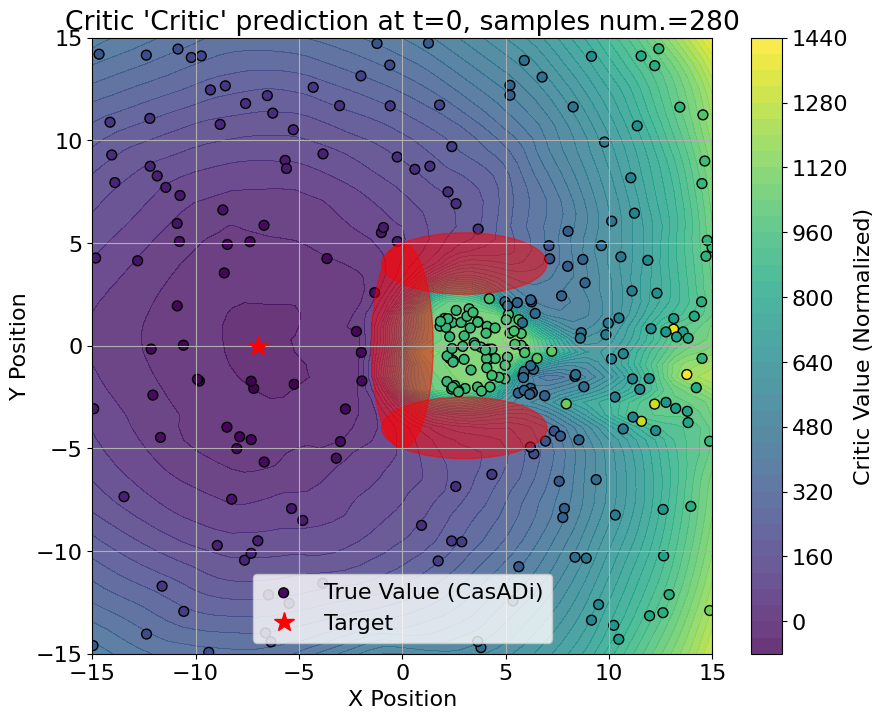

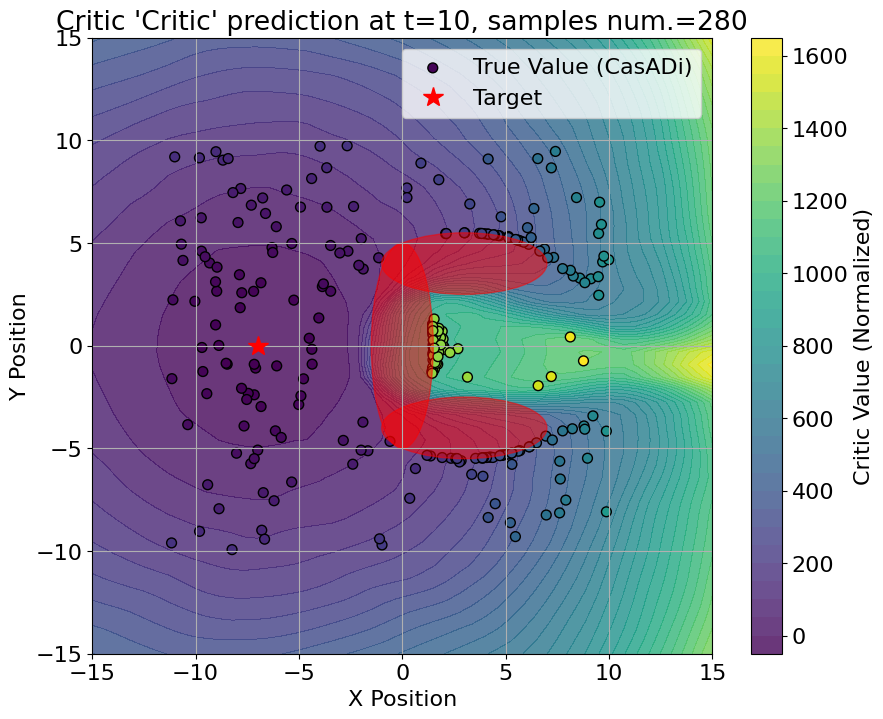

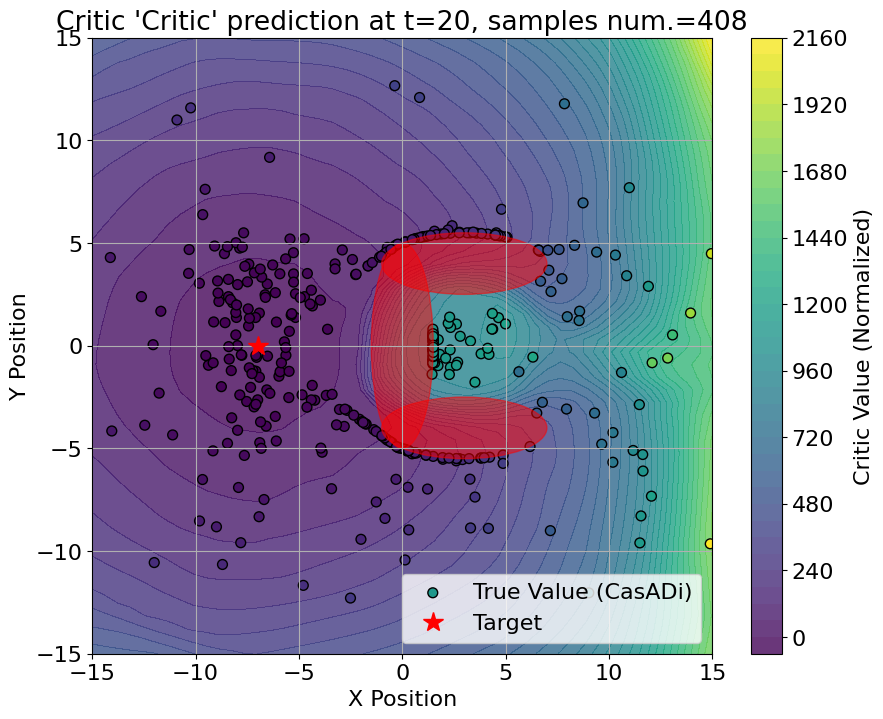

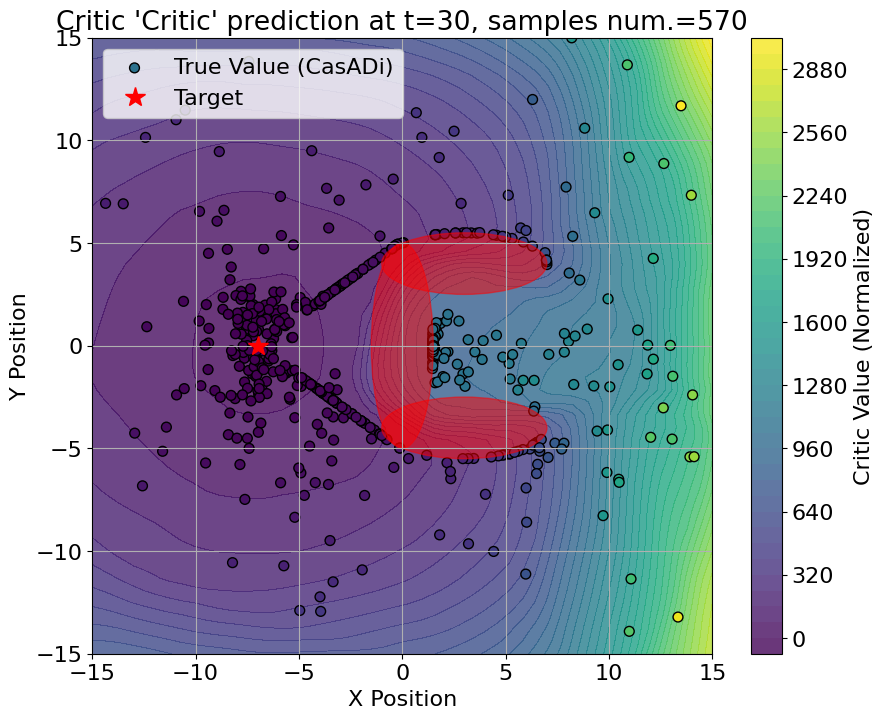

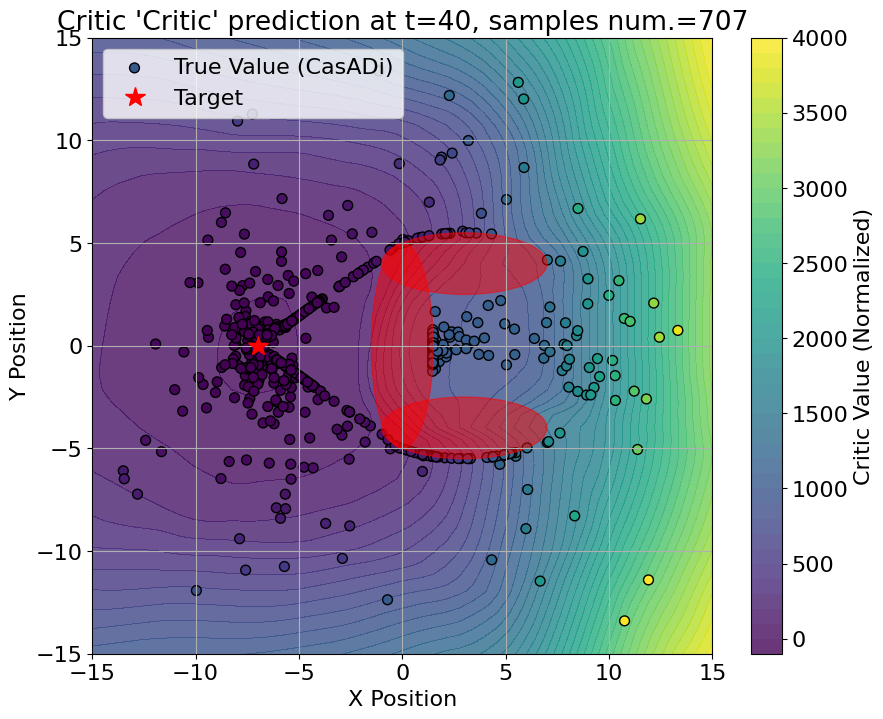

In [32]:
# Train the critic again with the new data in the buffer 
train_critic()

# Update the critic cycles counter
critic_cycles += cycles_counter(replay_buffer, minibatch_size, critic_epochs)
print(f"\nTotal critic cycles: {critic_cycles}")

for t in range(0, N, 10):
  plot_critic(critic, t, show=False)

--- CACTO Iteration 3 ---
--- Start training the constrained actor ---
--- Starting Constrained Actor training for 35 epochs ---
Epoch 1/35 | Mean Q+ALM: 369.3881 | Max Viol: 0.00223 | Lambda: [51.6  23.42 23.66] | Rho: 101.3 | LR: 0.000500 | step: 98
 | dQ/du norm: 1.741155
Epoch 5/35 | Mean Q+ALM: 369.3028 | Max Viol: 0.00826 | Lambda: [52.37 23.63 24.18] | Rho: 105.5 | LR: 0.000500 | step: 490
 | dQ/du norm: 1.699515
Epoch 10/35 | Mean Q+ALM: 369.2438 | Max Viol: 0.00235 | Lambda: [53.2  23.88 24.62] | Rho: 110.8 | LR: 0.000500 | step: 980
 | dQ/du norm: 1.745034
Epoch 15/35 | Mean Q+ALM: 369.2140 | Max Viol: 0.00281 | Lambda: [53.71 24.19 25.3 ] | Rho: 116.5 | LR: 0.000400 | step: 1470
 | dQ/du norm: 1.712558
Epoch 20/35 | Mean Q+ALM: 368.6190 | Max Viol: 0.00315 | Lambda: [54.62 24.51 25.99] | Rho: 122.4 | LR: 0.000320 | step: 1960
 | dQ/du norm: 1.682065
Epoch 25/35 | Mean Q+ALM: 368.5458 | Max Viol: 0.00271 | Lambda: [55.66 24.79 26.62] | Rho: 128.7 | LR: 0.000256 | step: 2450
 

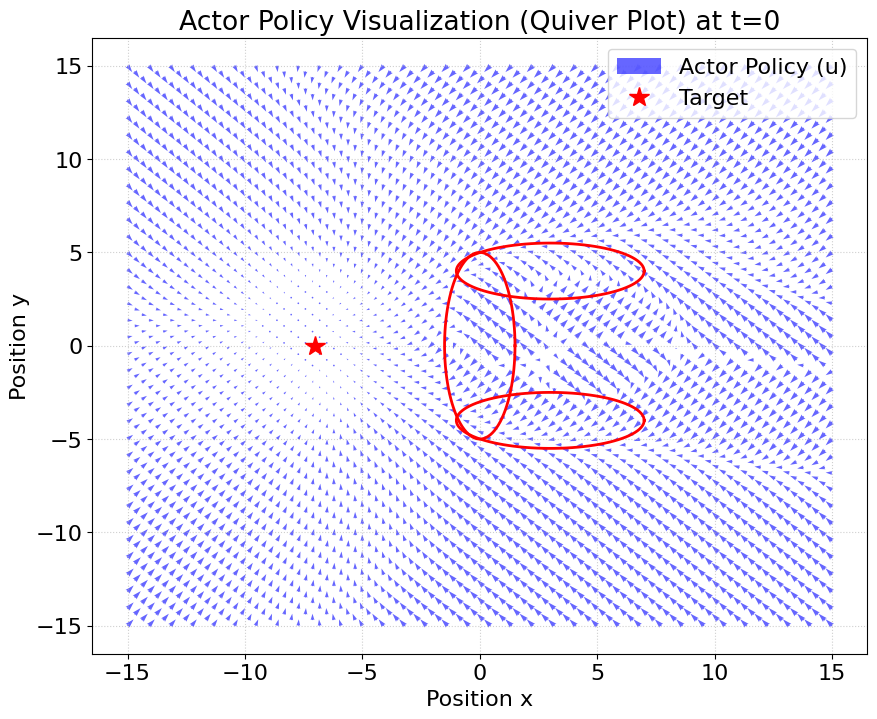

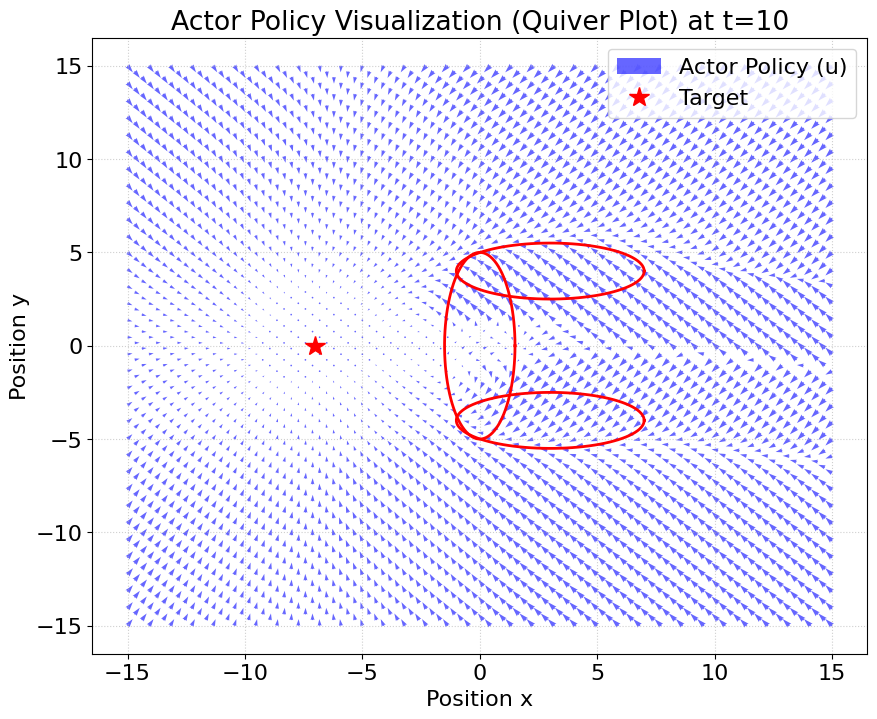

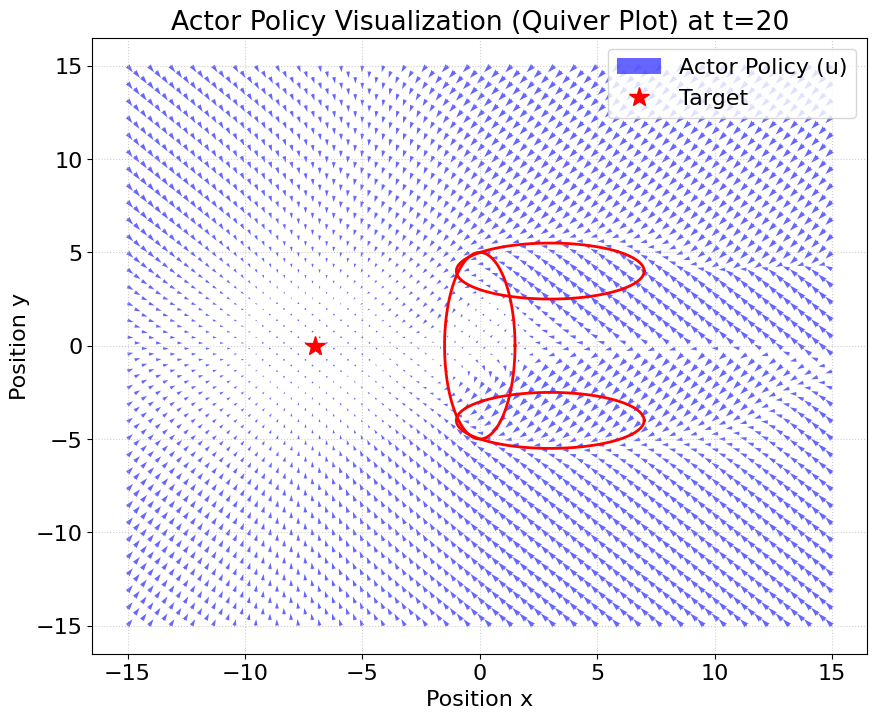

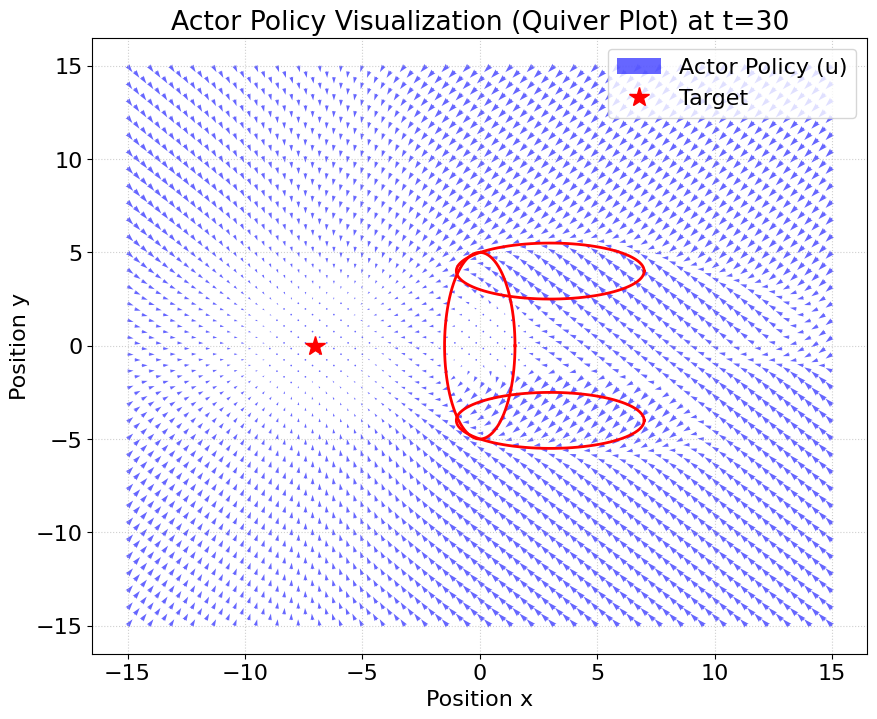

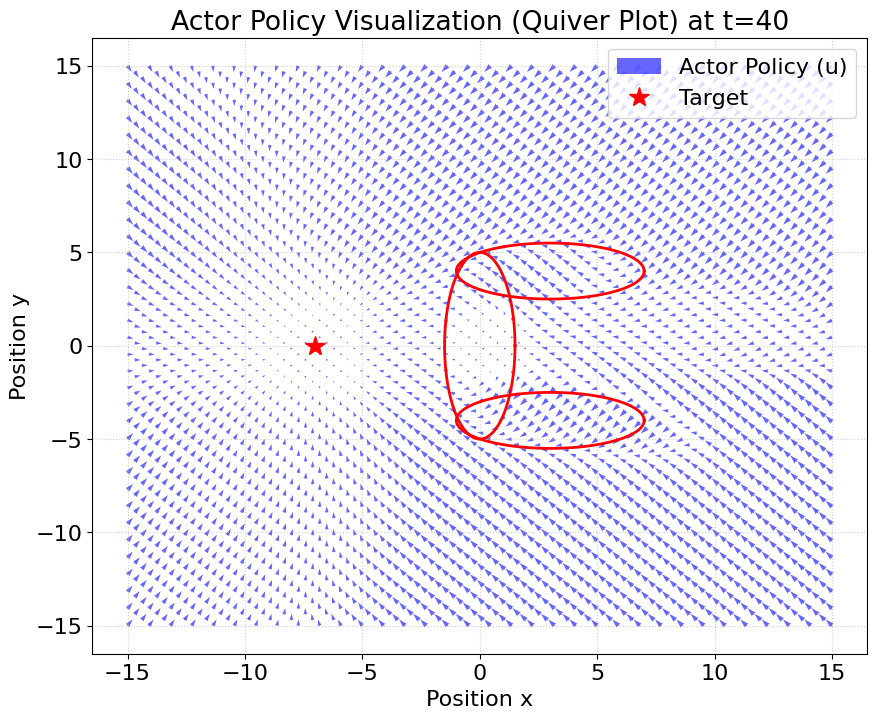

In [33]:
# Train the constrained actor again with the new critic

train_constr_actor()

# Update the constrained actor cycles counter
actor_cycles += cycles_counter(replay_buffer, minibatch_size, actor_epochs)
print(f"\nTotal constrained actor cycles: {actor_cycles}")

for t in range(0, N, 10):
  plot_constr_actor(t, show=True, plot_u_ocp=True)

Actor Only -> Feasible: 8/37 | Violating: 29/37
Actor Only -> Avg. max violation: 0.5543
Actor Only -> Avg. cost: 334.2695


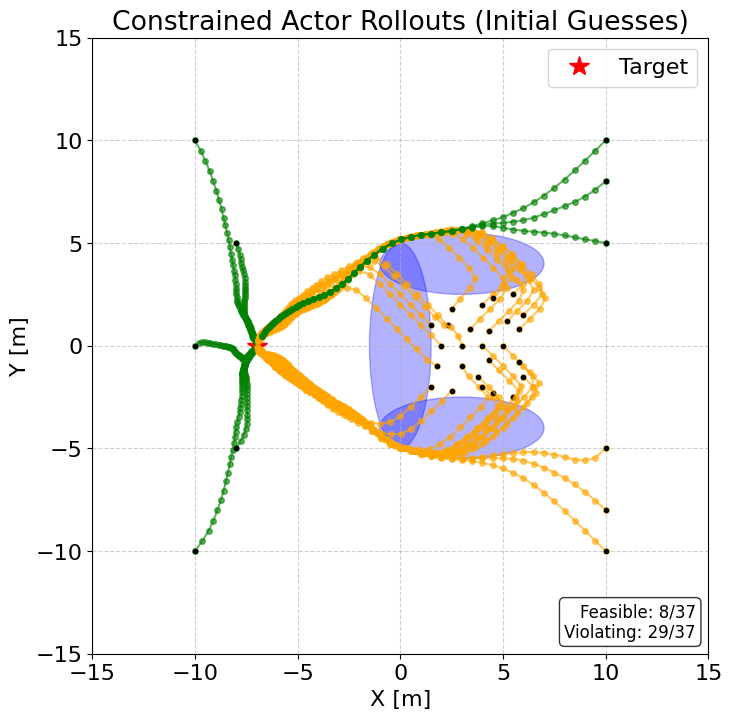

Computing initial guesses in batch...
Skip i=10: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=11: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=12: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=13: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=14: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=23: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variab

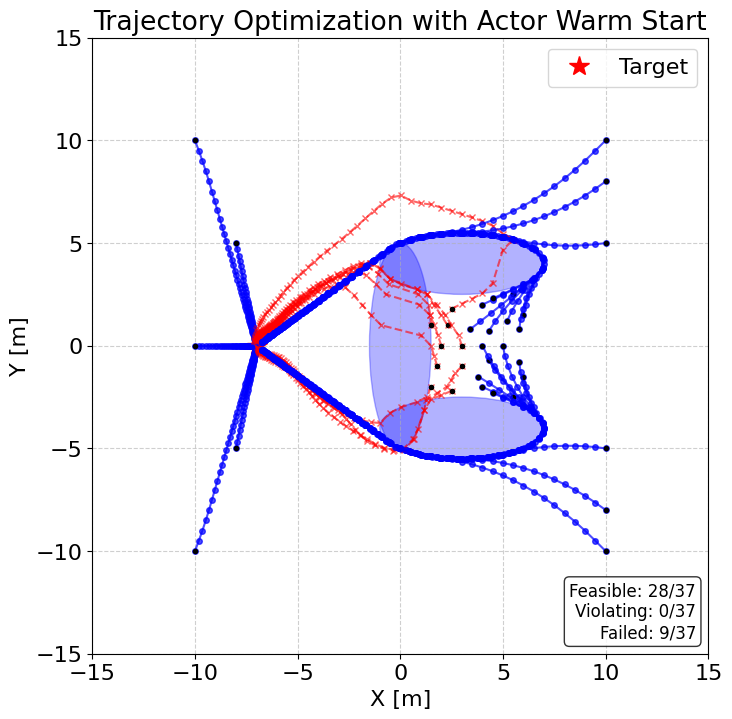

In [34]:
# Final evaluation of the constrained actor rollouts and TO performance after the last iteration
plot_cons_actor_rollouts()
V_TO, all_cons_x_trajs = evaluate_TO_w_cons_warm_start()

--- CACTO Iteration 4 ---
Start solving 300 TO problems


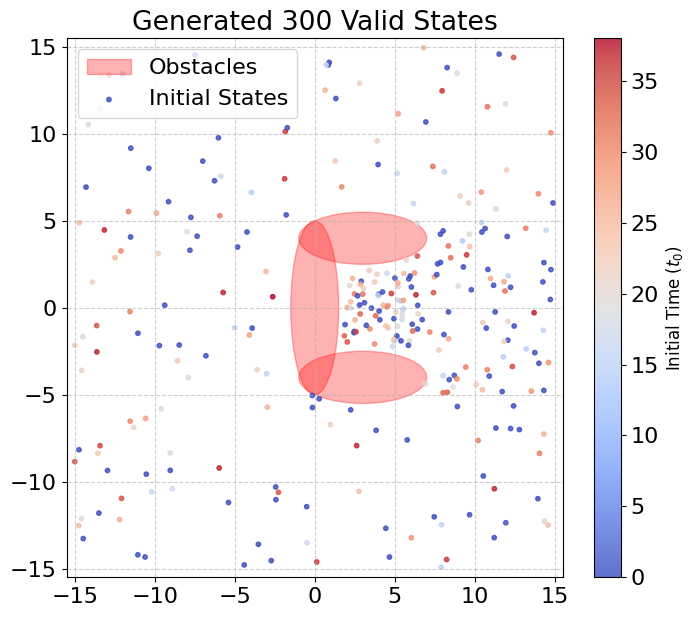

Computing warm start guesses via Actor...


COmputing OCPs: 100%|██████████| 300/300 [02:07<00:00,  2.35traj/s]


--- Finished ---
Successfully solved: 300 / 300
States Buffer size: (25000, 3) samples
Time taken: 130.518 s


In [35]:
# Solve an OCP for every sampled initial state-time using the constrained actor for warm start
solve_TO_problems(use_actor_to_warm_start=True, actor=cons_actor)

--- CACTO Iteration 4 ---
--- Start training critic ---
Replay buffer size: 25000 samples
Epoch 1/35 | MSE: 372.7235 | RMSE: 19.3060 | LR: 0.005000 | step: 98
Epoch 5/35 | MSE: 266.2229 | RMSE: 16.3163 | LR: 0.005000 | step: 490
Epoch 10/35 | MSE: 258.2750 | RMSE: 16.0709 | LR: 0.005000 | step: 980
Epoch 15/35 | MSE: 224.3804 | RMSE: 14.9793 | LR: 0.003750 | step: 1470
Epoch 20/35 | MSE: 217.5372 | RMSE: 14.7491 | LR: 0.002812 | step: 1960
Epoch 25/35 | MSE: 175.7855 | RMSE: 13.2584 | LR: 0.002109 | step: 2450
Epoch 30/35 | MSE: 148.9039 | RMSE: 12.2026 | LR: 0.001582 | step: 2940
Epoch 35/35 | MSE: 135.2168 | RMSE: 11.6283 | LR: 0.001187 | step: 3430
Final Critic MSE: 135.22
Final Critic RMSE: 11.63
--- Critic training has finished ---

Total critic cycles: 11270


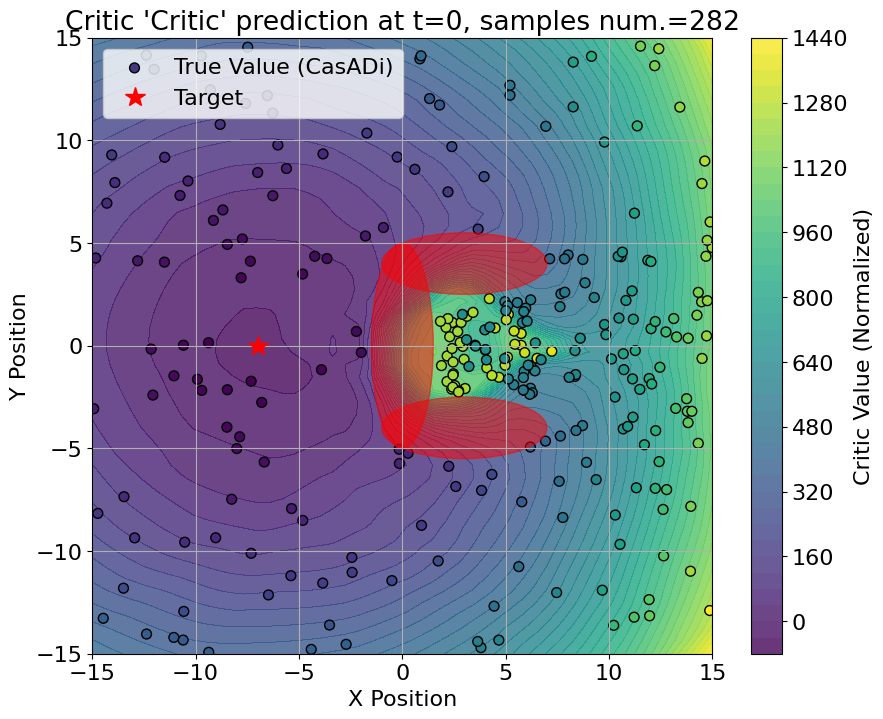

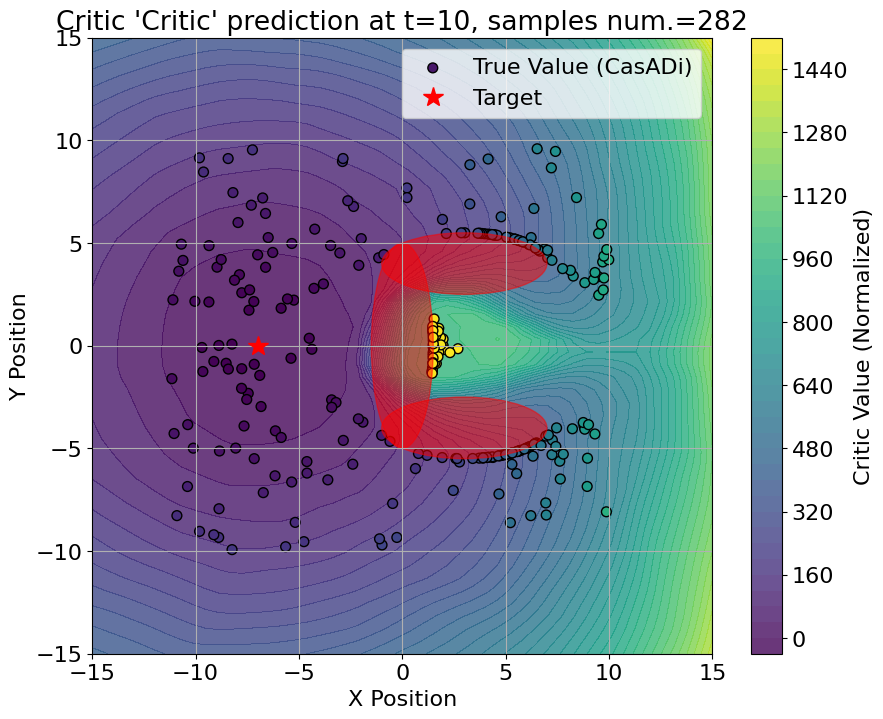

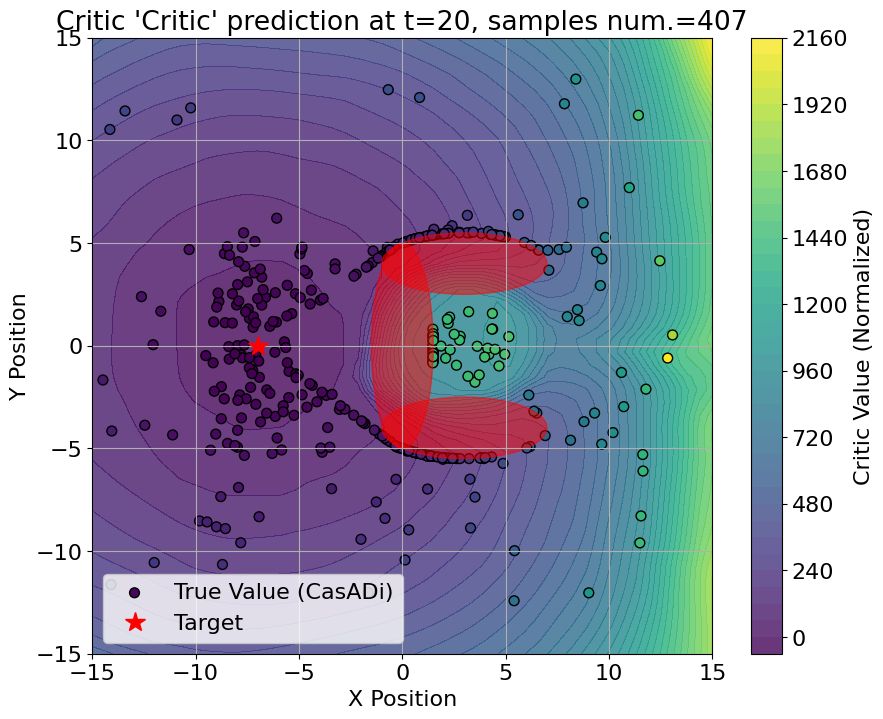

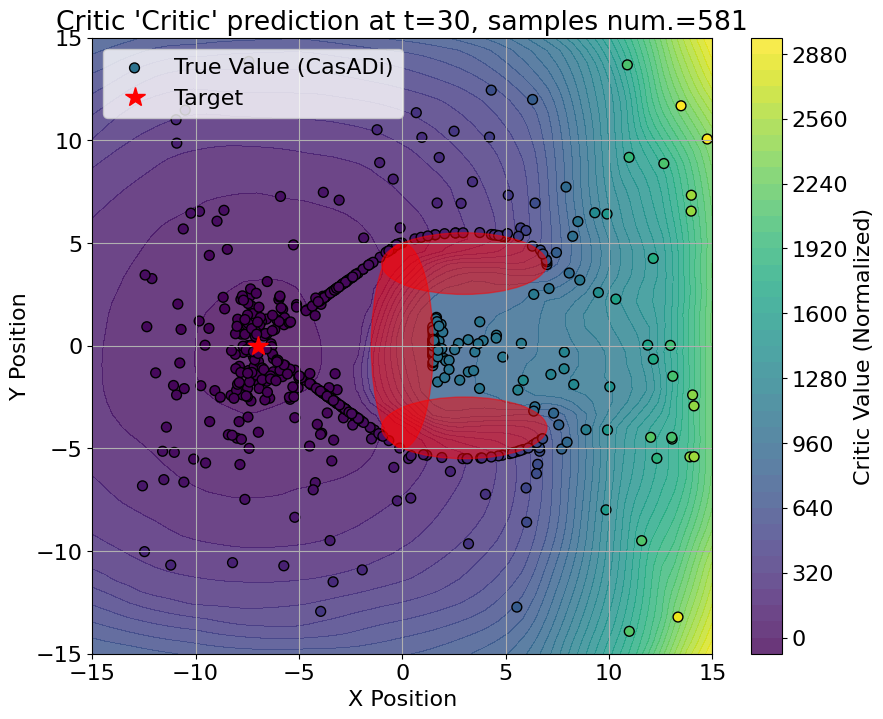

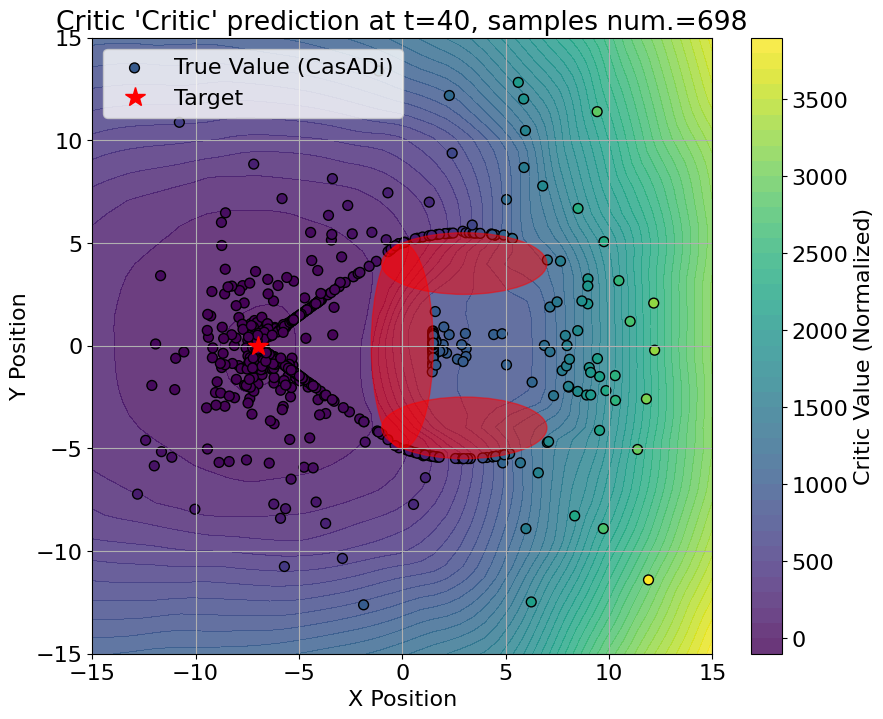

In [36]:
# Train the critic again with the new data in the buffer 
train_critic()

# Update the critic cycles counter
critic_cycles += cycles_counter(replay_buffer, minibatch_size, critic_epochs)
print(f"\nTotal critic cycles: {critic_cycles}")

for t in range(0, N, 10):
  plot_critic(critic, t, show=False)

--- CACTO Iteration 4 ---
--- Start training the constrained actor ---
--- Starting Constrained Actor training for 35 epochs ---
Epoch 1/35 | Mean Q+ALM: 324.7491 | Max Viol: 0.00170 | Lambda: [57.62 25.53 27.73] | Rho: 143.6 | LR: 0.000500 | step: 98
 | dQ/du norm: 1.650843
Epoch 5/35 | Mean Q+ALM: 324.5558 | Max Viol: 0.00159 | Lambda: [58.44 26.22 28.09] | Rho: 149.4 | LR: 0.000500 | step: 490
 | dQ/du norm: 1.614239
Epoch 10/35 | Mean Q+ALM: 324.5565 | Max Viol: 0.00543 | Lambda: [59.29 26.88 28.62] | Rho: 157.0 | LR: 0.000500 | step: 980
 | dQ/du norm: 1.596478
Epoch 15/35 | Mean Q+ALM: 324.4543 | Max Viol: 0.00320 | Lambda: [60.36 27.55 29.02] | Rho: 165.0 | LR: 0.000400 | step: 1470
 | dQ/du norm: 1.592507
Epoch 20/35 | Mean Q+ALM: 324.3322 | Max Viol: 0.00220 | Lambda: [61.19 28.04 29.46] | Rho: 173.4 | LR: 0.000320 | step: 1960
 | dQ/du norm: 1.584557
Epoch 25/35 | Mean Q+ALM: 324.3221 | Max Viol: 0.00238 | Lambda: [61.91 28.59 29.96] | Rho: 182.3 | LR: 0.000256 | step: 2450
 

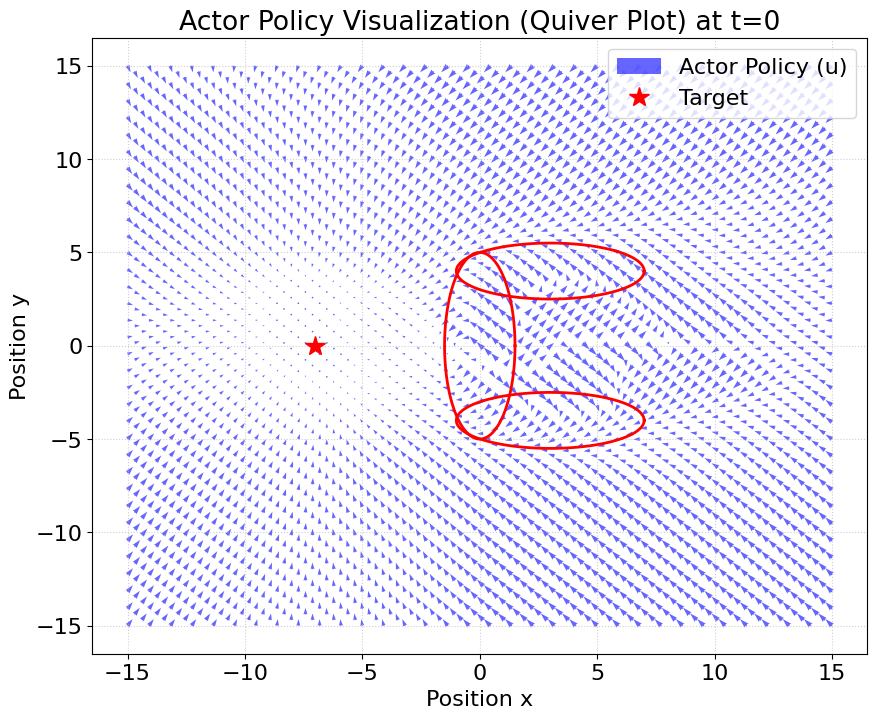

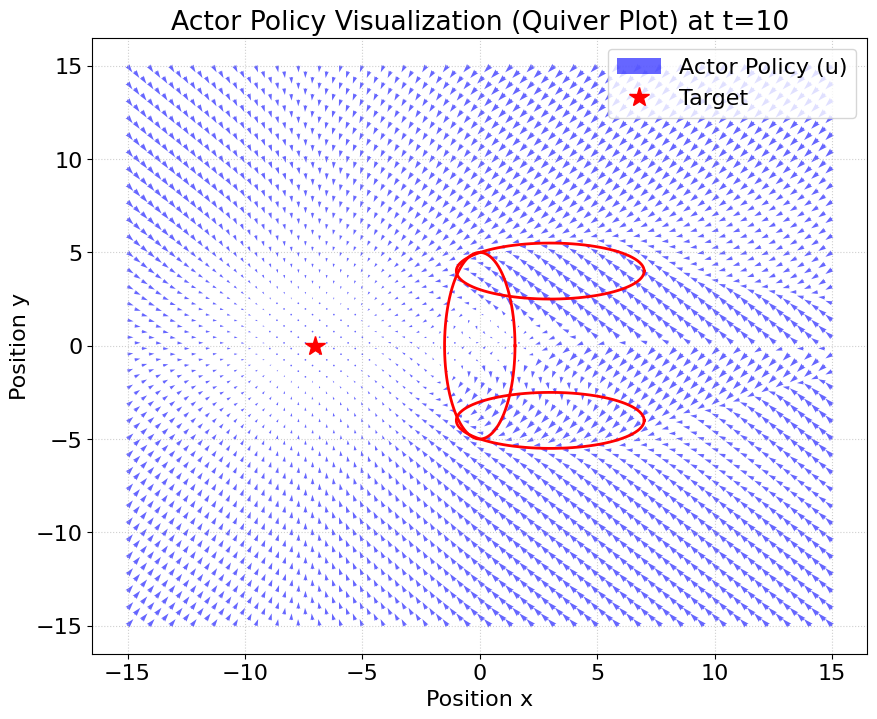

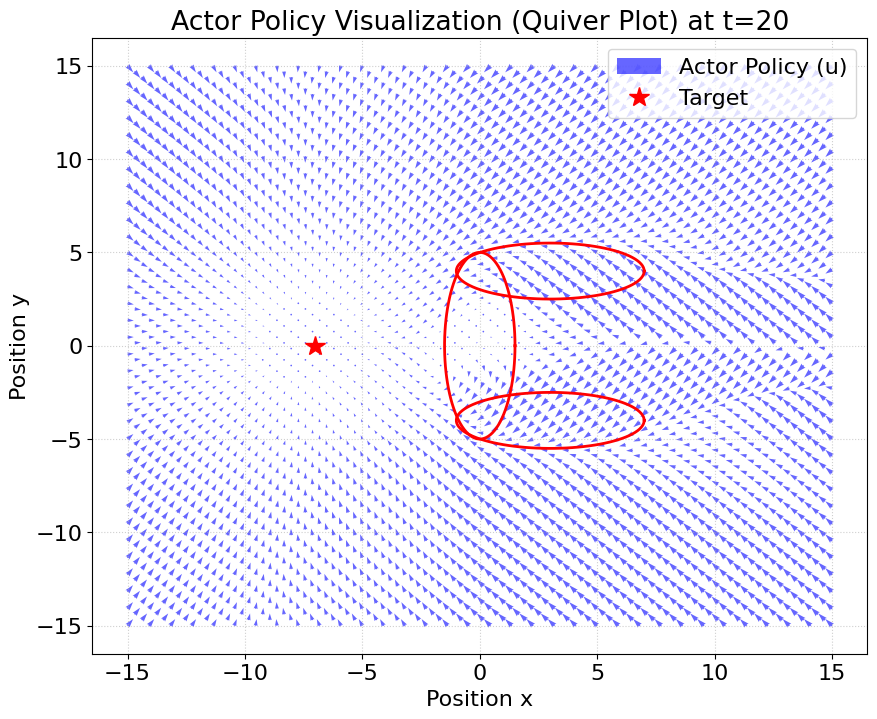

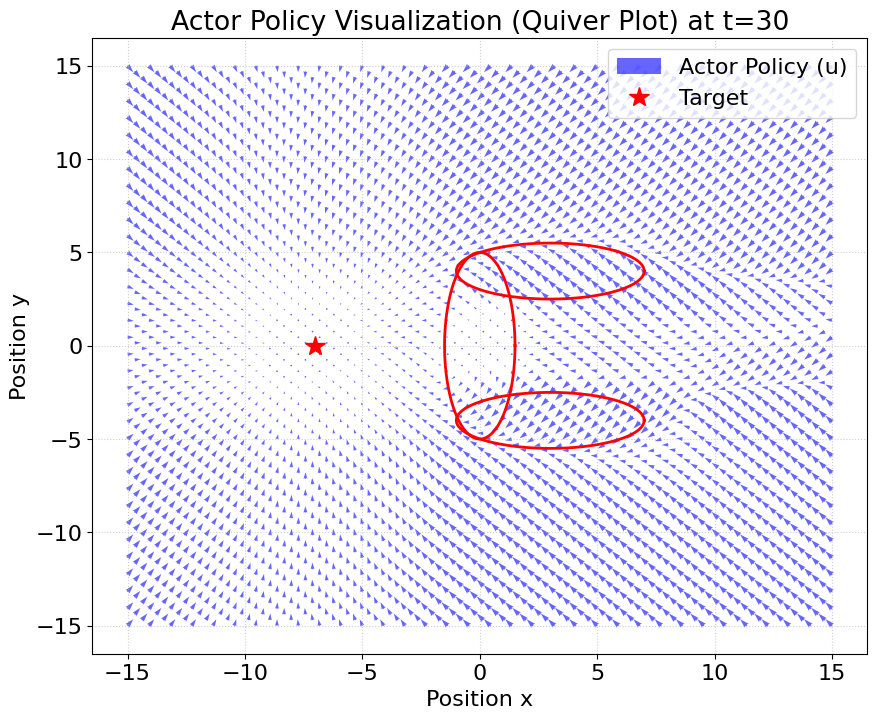

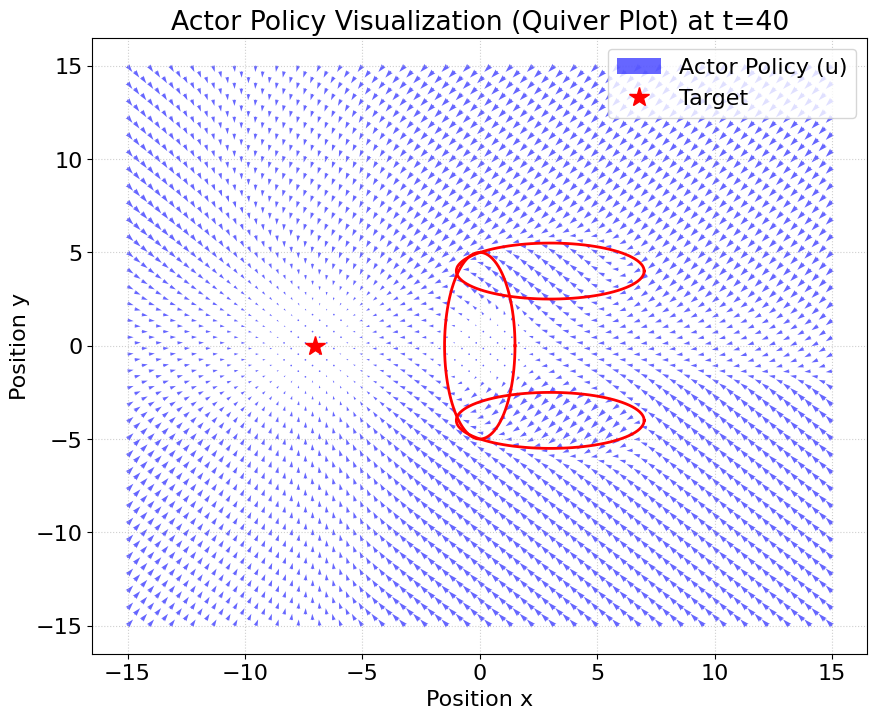

In [37]:
# Train the constrained actor again with the new critic

train_constr_actor()

# Update the constrained actor cycles counter
actor_cycles += cycles_counter(replay_buffer, minibatch_size, actor_epochs)
print(f"\nTotal constrained actor cycles: {actor_cycles}")


for t in range(0, N, 10):
  plot_constr_actor(t, show=True, plot_u_ocp=True)

Actor Only -> Feasible: 11/37 | Violating: 26/37
Actor Only -> Avg. max violation: 0.3711
Actor Only -> Avg. cost: 431.1339


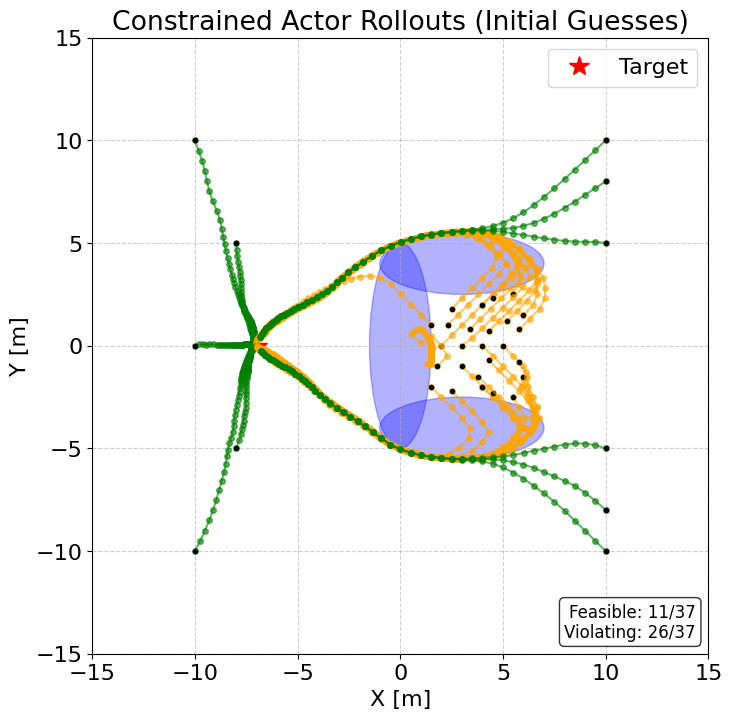

Computing initial guesses in batch...
Skip i=11: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=12: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=23: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=24: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
TO + Warm Start -> Time: 19.891 s
TO + Warm Start -> Feasible: 33/37 | Failed: 4/37


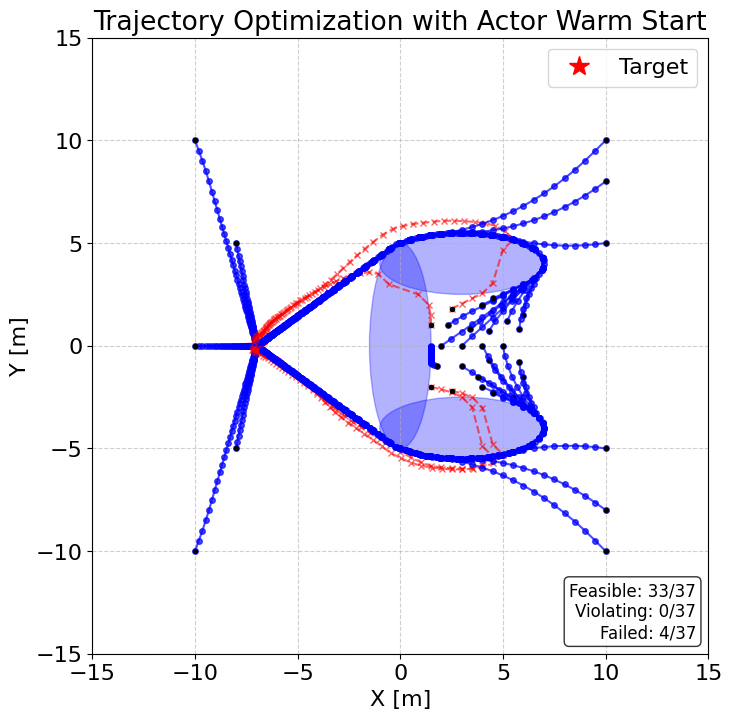

In [38]:
# Final evaluation of the constrained actor rollouts and TO performance after the last iteration
plot_cons_actor_rollouts()
V_TO, all_cons_x_trajs = evaluate_TO_w_cons_warm_start()

--- CACTO Iteration 5 ---
Start solving 300 TO problems


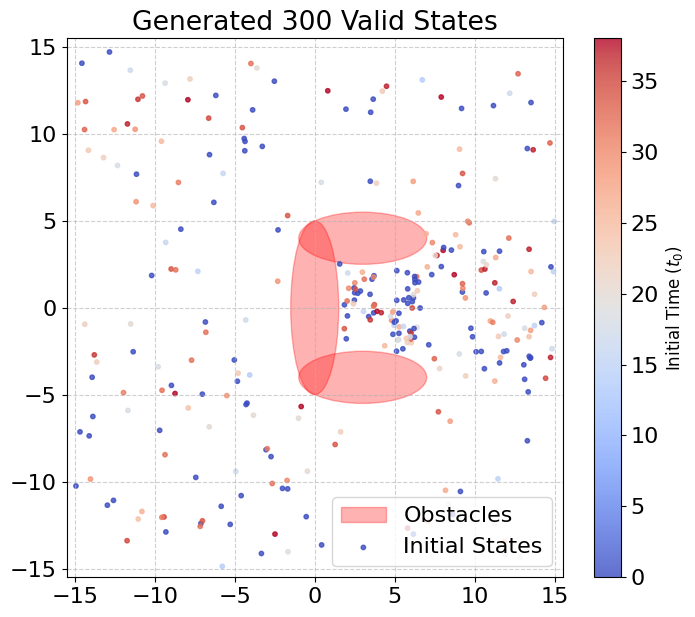

Computing warm start guesses via Actor...


COmputing OCPs: 100%|██████████| 300/300 [01:46<00:00,  2.80traj/s]


--- Finished ---
Successfully solved: 300 / 300
States Buffer size: (25000, 3) samples
Time taken: 109.821 s


In [39]:
# Solve an OCP for every sampled initial state-time using the constrained actor for warm start
solve_TO_problems(use_actor_to_warm_start=True, actor=cons_actor)

--- CACTO Iteration 5 ---
--- Start training critic ---
Replay buffer size: 25000 samples
Epoch 1/35 | MSE: 306.8234 | RMSE: 17.5164 | LR: 0.005000 | step: 98
Epoch 5/35 | MSE: 492.0580 | RMSE: 22.1824 | LR: 0.005000 | step: 490
Epoch 10/35 | MSE: 246.6502 | RMSE: 15.7051 | LR: 0.005000 | step: 980
Epoch 15/35 | MSE: 155.2316 | RMSE: 12.4592 | LR: 0.003750 | step: 1470
Epoch 20/35 | MSE: 199.1940 | RMSE: 14.1136 | LR: 0.002812 | step: 1960
Epoch 25/35 | MSE: 148.9321 | RMSE: 12.2038 | LR: 0.002109 | step: 2450
Epoch 30/35 | MSE: 109.0084 | RMSE: 10.4407 | LR: 0.001582 | step: 2940
Epoch 35/35 | MSE: 97.5824 | RMSE: 9.8784 | LR: 0.001187 | step: 3430
Final Critic MSE: 97.58
Final Critic RMSE: 9.88
--- Critic training has finished ---

Total critic cycles: 14700


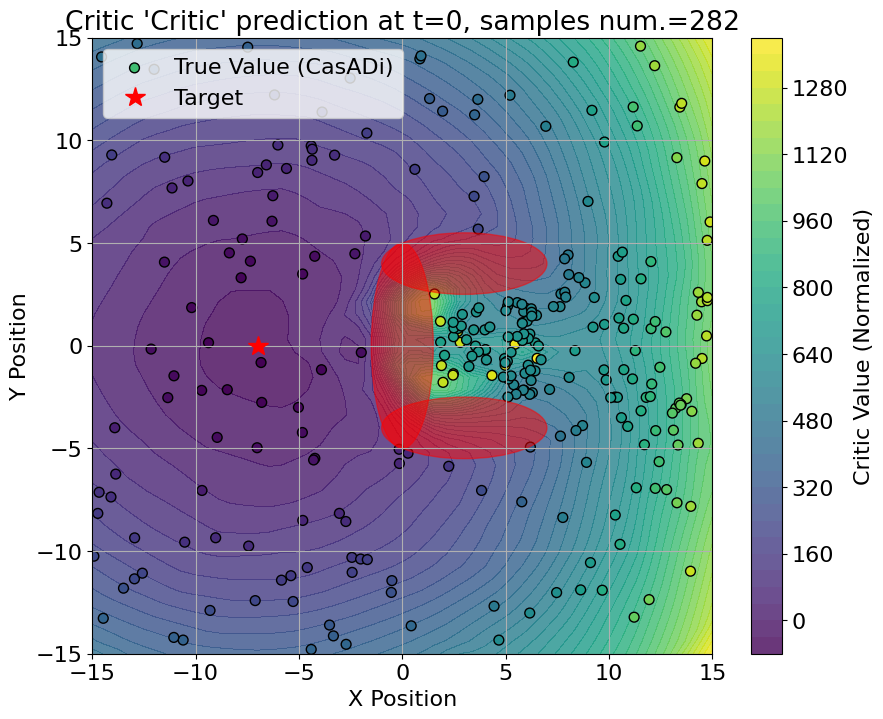

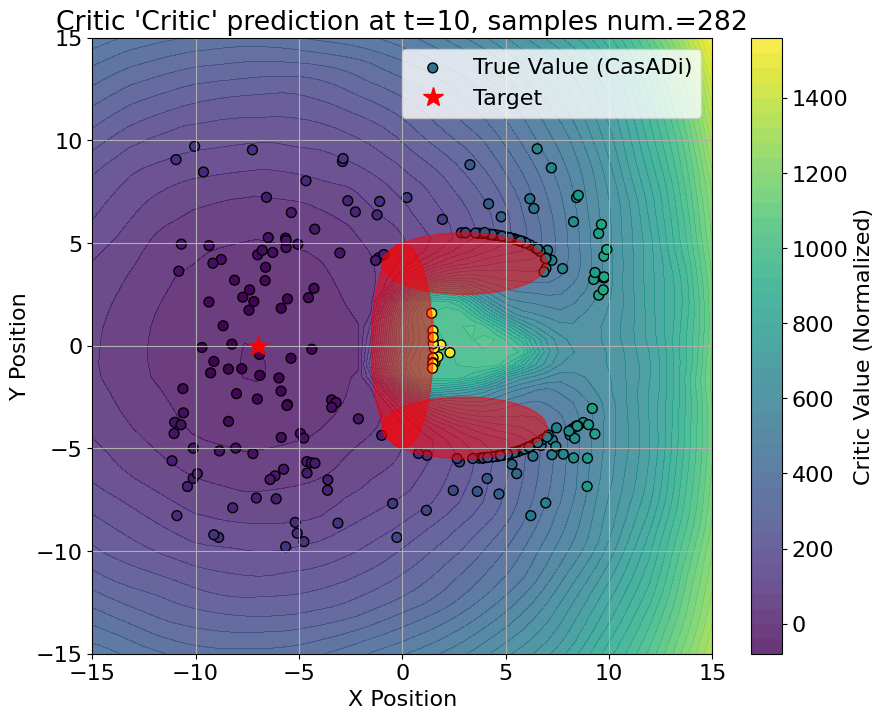

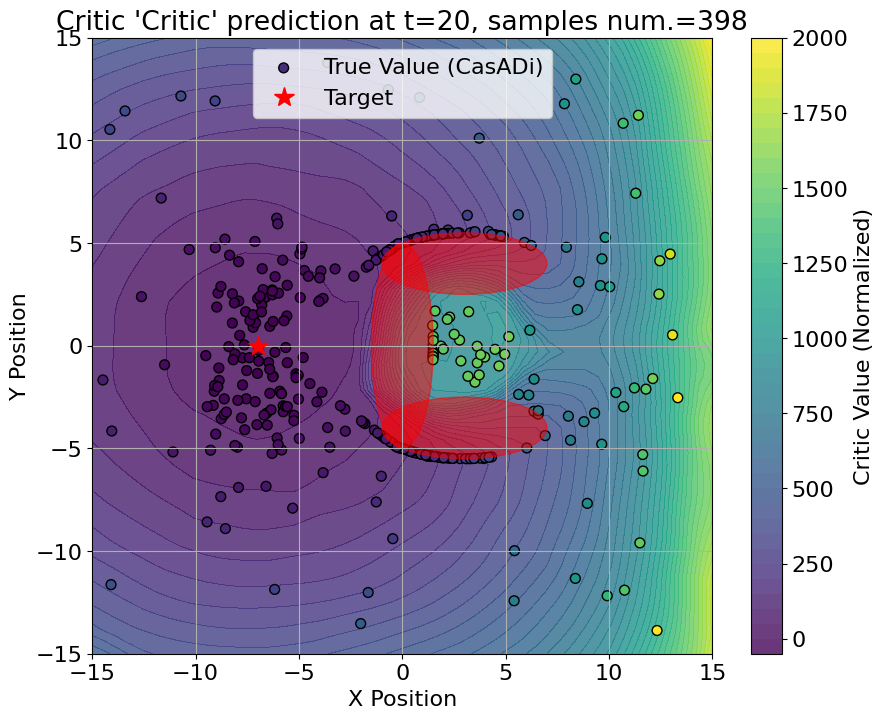

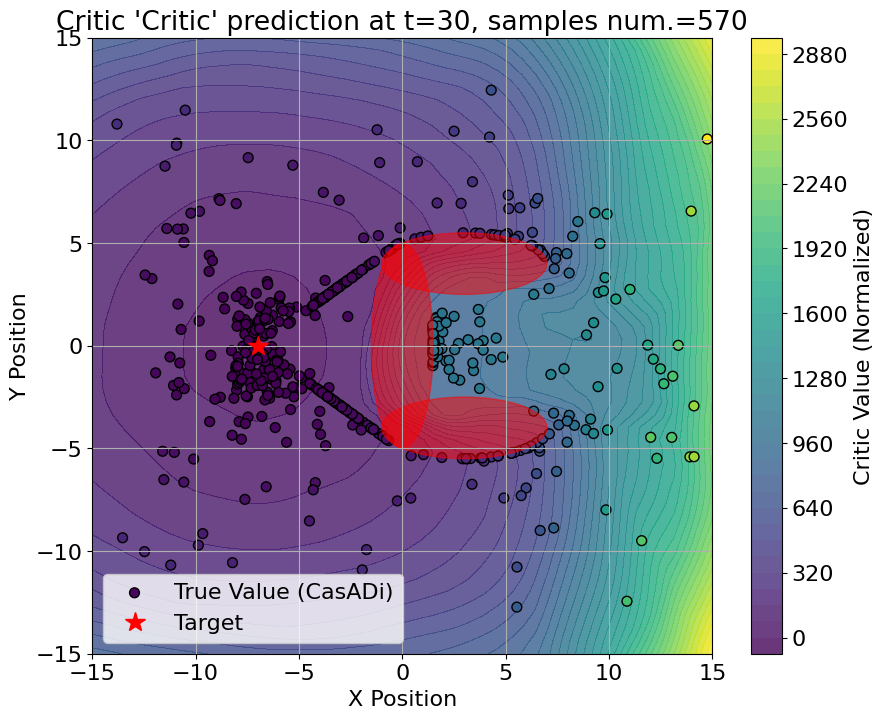

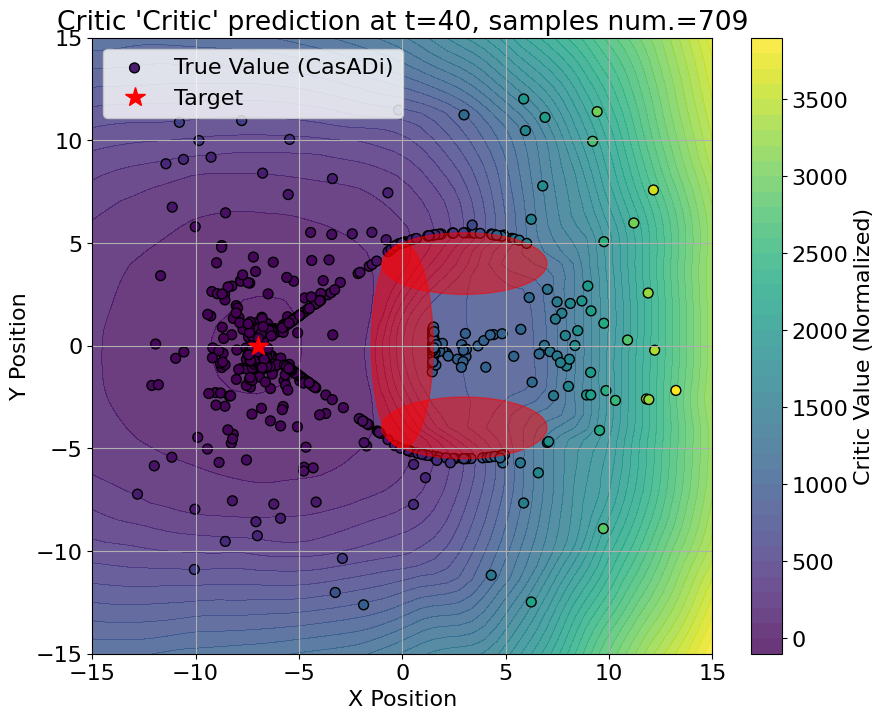

In [40]:
# Train the critic again with the new data in the buffer 
train_critic()

# Update the critic cycles counter
critic_cycles += cycles_counter(replay_buffer, minibatch_size, critic_epochs)
print(f"\nTotal critic cycles: {critic_cycles}")


for t in range(0, N, 10):
  plot_critic(critic, t, show=False)

--- CACTO Iteration 5 ---
--- Start training the constrained actor ---
--- Starting Constrained Actor training for 35 epochs ---
Epoch 1/35 | Mean Q+ALM: 274.1716 | Max Viol: 0.00347 | Lambda: [64.29 30.07 31.25] | Rho: 203.4 | LR: 0.000500 | step: 98
 | dQ/du norm: 1.508159
Epoch 5/35 | Mean Q+ALM: 274.0396 | Max Viol: 0.00294 | Lambda: [64.69 30.71 31.99] | Rho: 211.6 | LR: 0.000500 | step: 490
 | dQ/du norm: 1.528240
Epoch 10/35 | Mean Q+ALM: 273.7552 | Max Viol: 0.00220 | Lambda: [65.24 31.72 32.62] | Rho: 222.4 | LR: 0.000500 | step: 980
 | dQ/du norm: 1.504587
Epoch 15/35 | Mean Q+ALM: 273.7093 | Max Viol: 0.00313 | Lambda: [65.55 32.6  33.31] | Rho: 233.8 | LR: 0.000400 | step: 1470
 | dQ/du norm: 1.496438
Epoch 20/35 | Mean Q+ALM: 273.6067 | Max Viol: 0.00133 | Lambda: [66.04 33.32 33.81] | Rho: 245.7 | LR: 0.000320 | step: 1960
 | dQ/du norm: 1.515708
Epoch 25/35 | Mean Q+ALM: 273.5413 | Max Viol: 0.00134 | Lambda: [66.57 34.11 34.25] | Rho: 258.2 | LR: 0.000256 | step: 2450
 

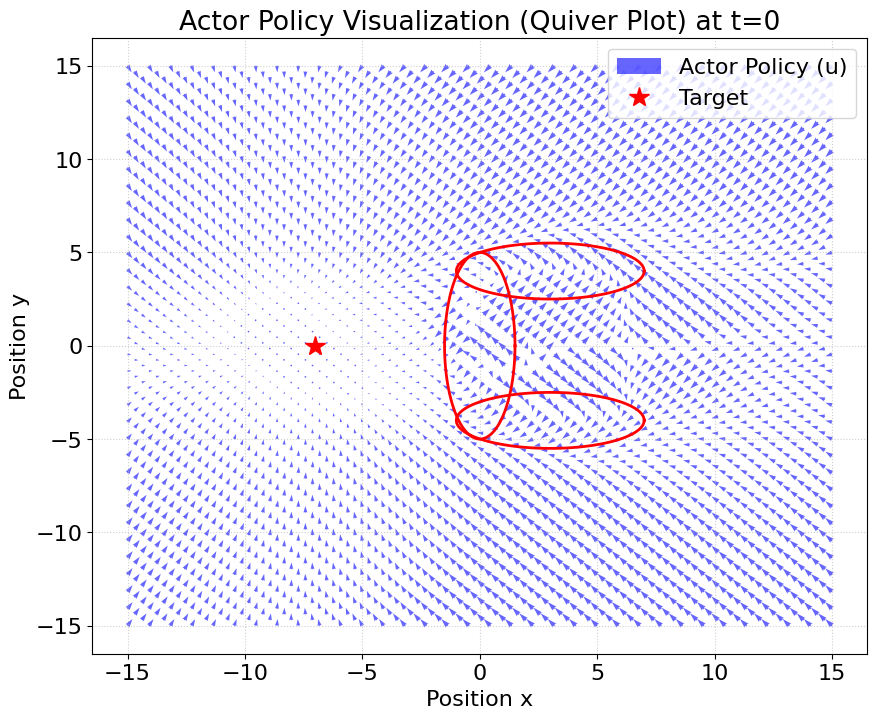

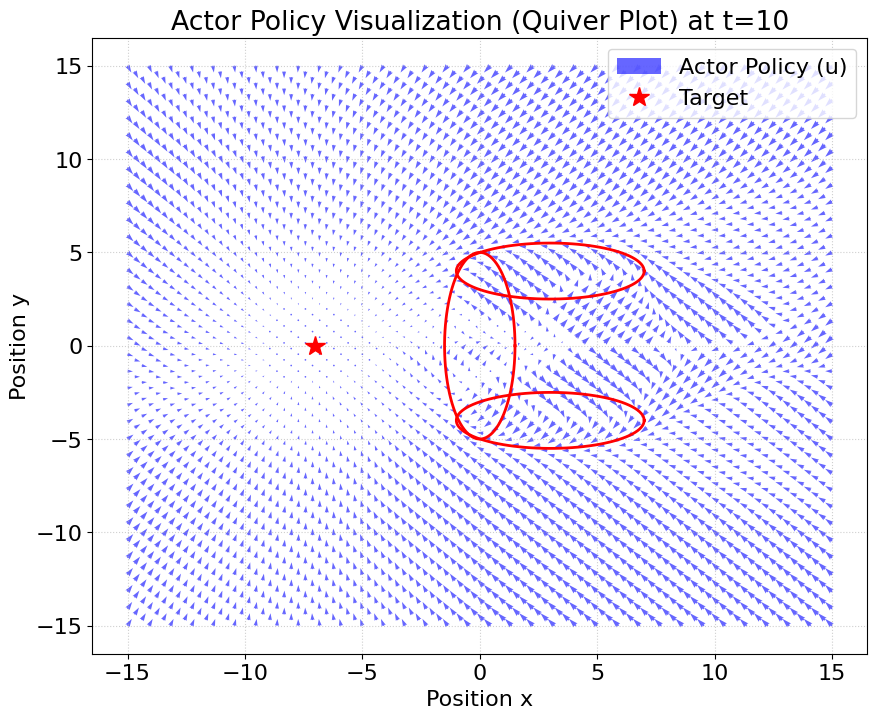

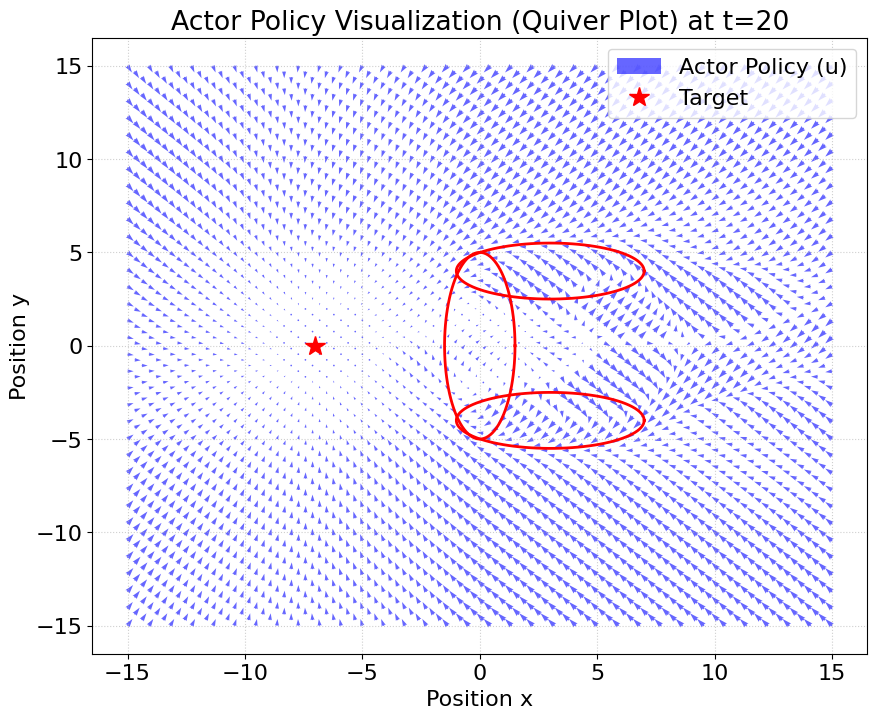

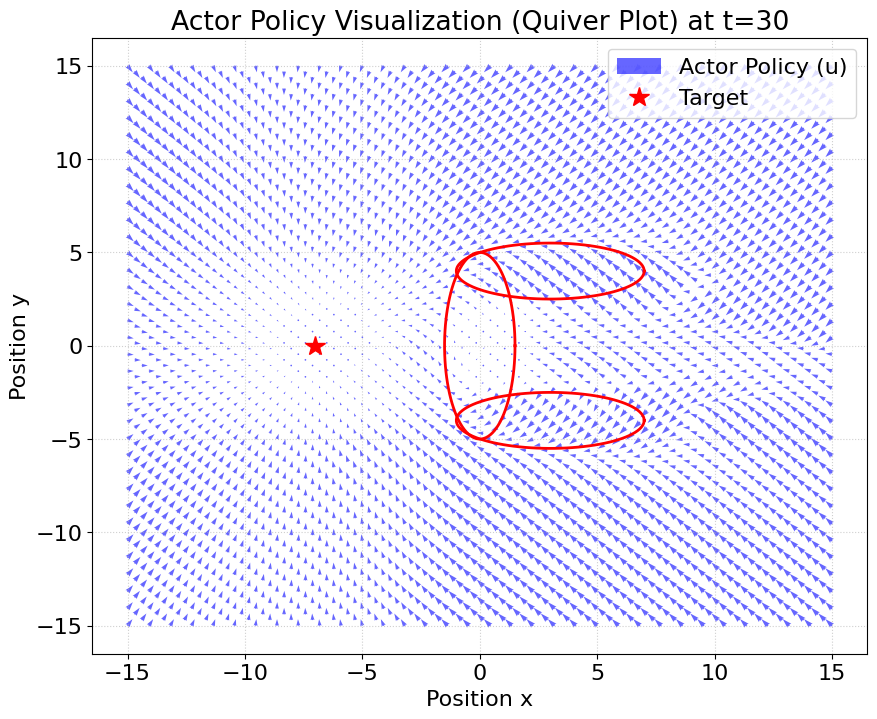

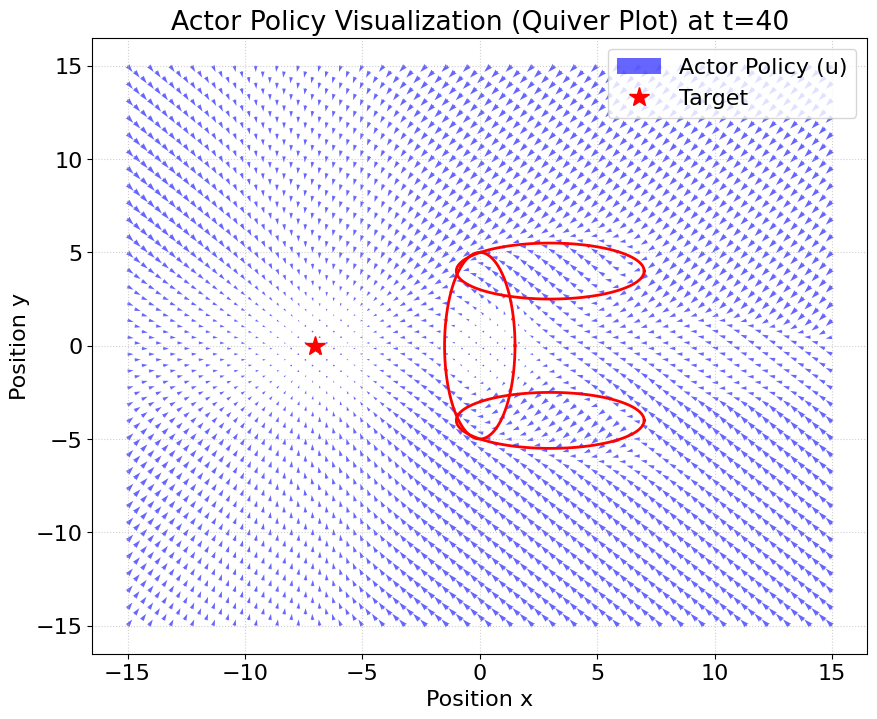

In [41]:
# Train the constrained actor again with the new critic

train_constr_actor()

# Update the constrained actor cycles counter
actor_cycles += cycles_counter(replay_buffer, minibatch_size, actor_epochs)
print(f"\nTotal constrained actor cycles: {actor_cycles}")


for t in range(0, N, 10):
  plot_constr_actor(t, show=True, plot_u_ocp=True)

Actor Only -> Feasible: 11/37 | Violating: 26/37
Actor Only -> Avg. max violation: 0.3125
Actor Only -> Avg. cost: 440.8742


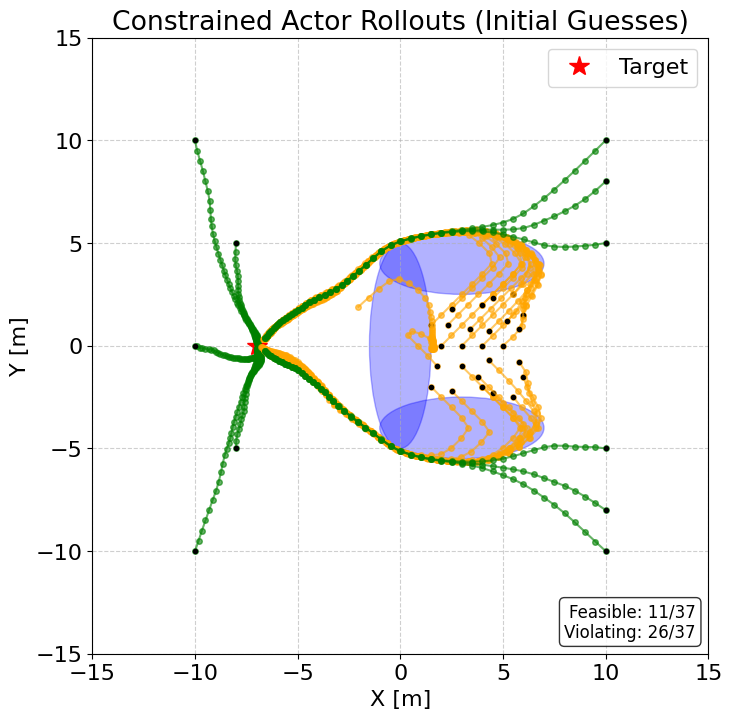

Computing initial guesses in batch...
Skip i=11: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=12: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=23: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=24: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=28: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
TO + Warm Start -> Time: 21.838 s
TO + Warm Start -> Feasible: 32/37 | Failed: 5/37


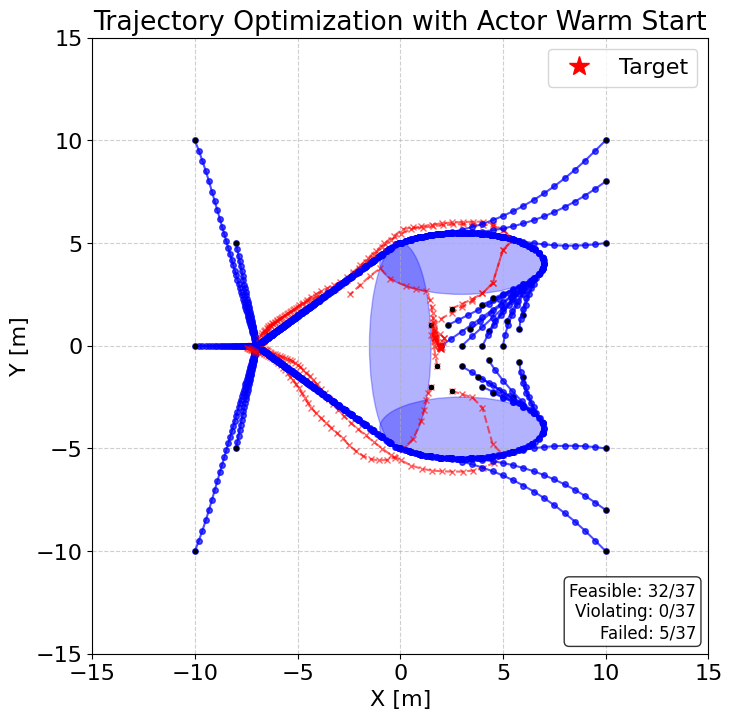

In [42]:
# Final evaluation of the constrained actor rollouts and TO performance after the last iteration
plot_cons_actor_rollouts()
V_TO, all_cons_x_trajs = evaluate_TO_w_cons_warm_start()

--- CACTO Iteration 6 ---
Start solving 300 TO problems


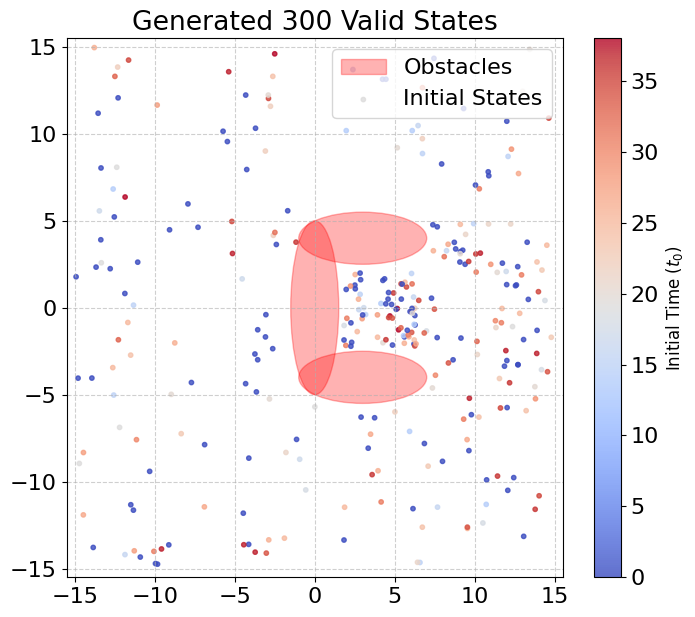

Computing warm start guesses via Actor...


COmputing OCPs: 100%|██████████| 300/300 [01:21<00:00,  3.68traj/s]


--- Finished ---
Successfully solved: 300 / 300
States Buffer size: (25000, 3) samples
Time taken: 84.082 s


In [43]:
# Solve an OCP for every sampled initial state-time using the constrained actor for warm start
solve_TO_problems(use_actor_to_warm_start=True, actor=cons_actor)

--- CACTO Iteration 6 ---
--- Start training critic ---
Replay buffer size: 25000 samples
Epoch 1/35 | MSE: 204.7972 | RMSE: 14.3107 | LR: 0.005000 | step: 98
Epoch 5/35 | MSE: 150.4550 | RMSE: 12.2660 | LR: 0.005000 | step: 490
Epoch 10/35 | MSE: 205.0359 | RMSE: 14.3191 | LR: 0.005000 | step: 980
Epoch 15/35 | MSE: 179.7357 | RMSE: 13.4066 | LR: 0.003750 | step: 1470
Epoch 20/35 | MSE: 116.5635 | RMSE: 10.7965 | LR: 0.002812 | step: 1960
Epoch 25/35 | MSE: 66.5146 | RMSE: 8.1556 | LR: 0.002109 | step: 2450
Epoch 30/35 | MSE: 59.6247 | RMSE: 7.7217 | LR: 0.001582 | step: 2940
Epoch 35/35 | MSE: 47.7500 | RMSE: 6.9101 | LR: 0.001187 | step: 3430
Final Critic MSE: 47.75
Final Critic RMSE: 6.91
--- Critic training has finished ---

Total critic cycles: 18130


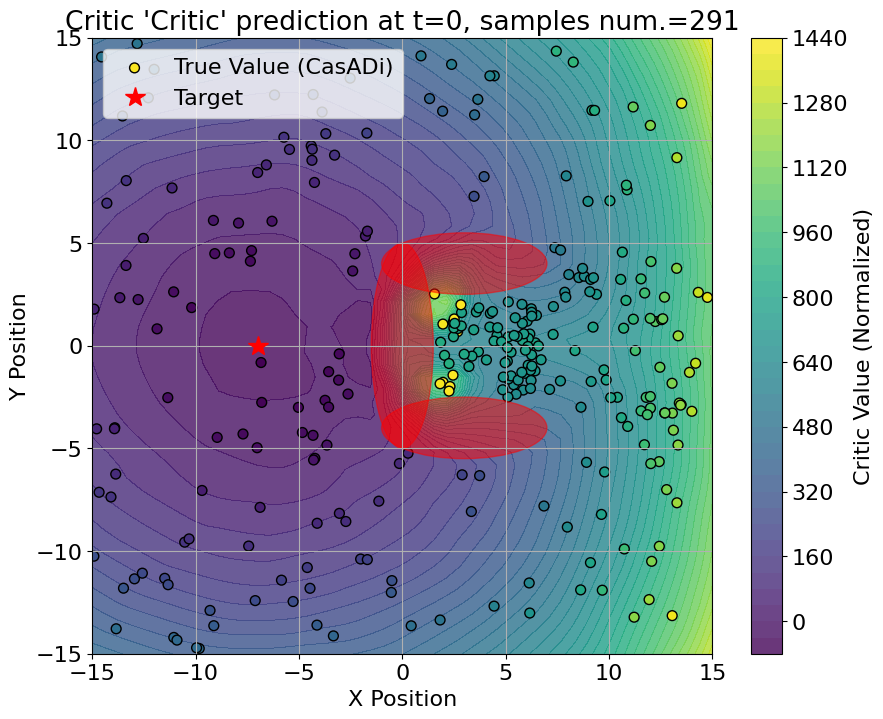

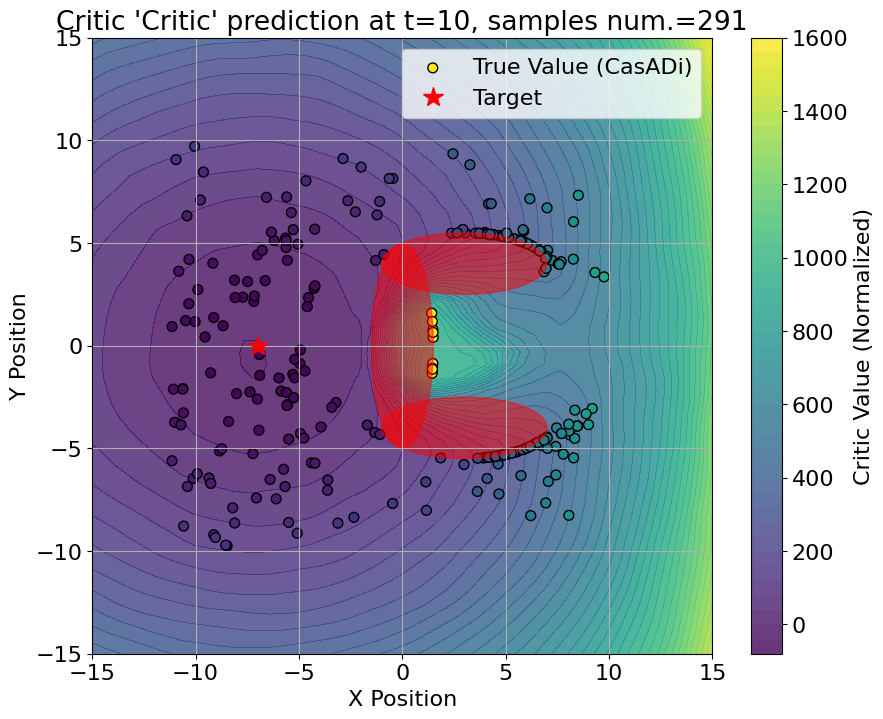

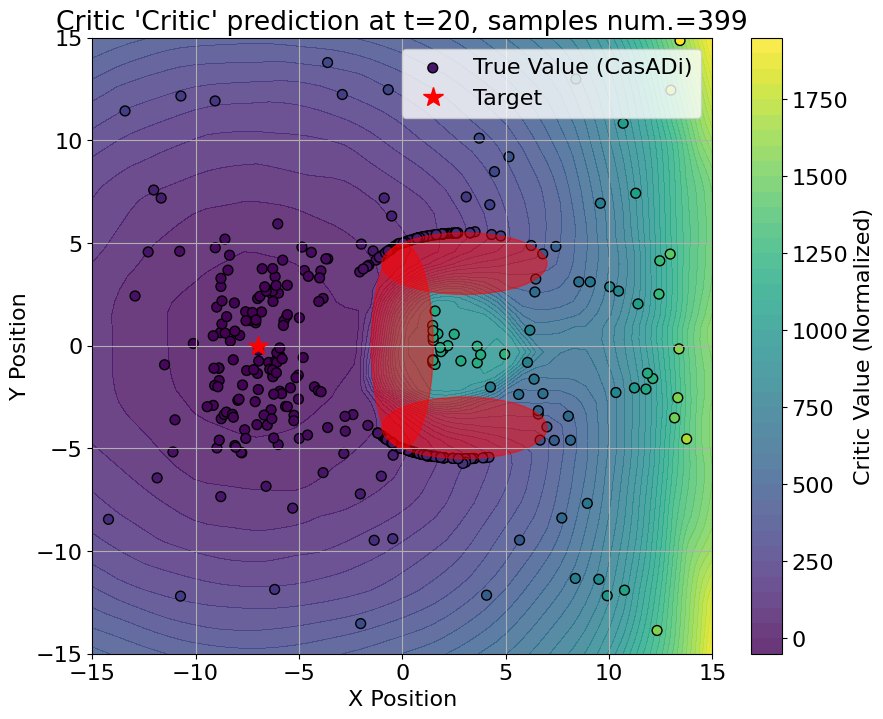

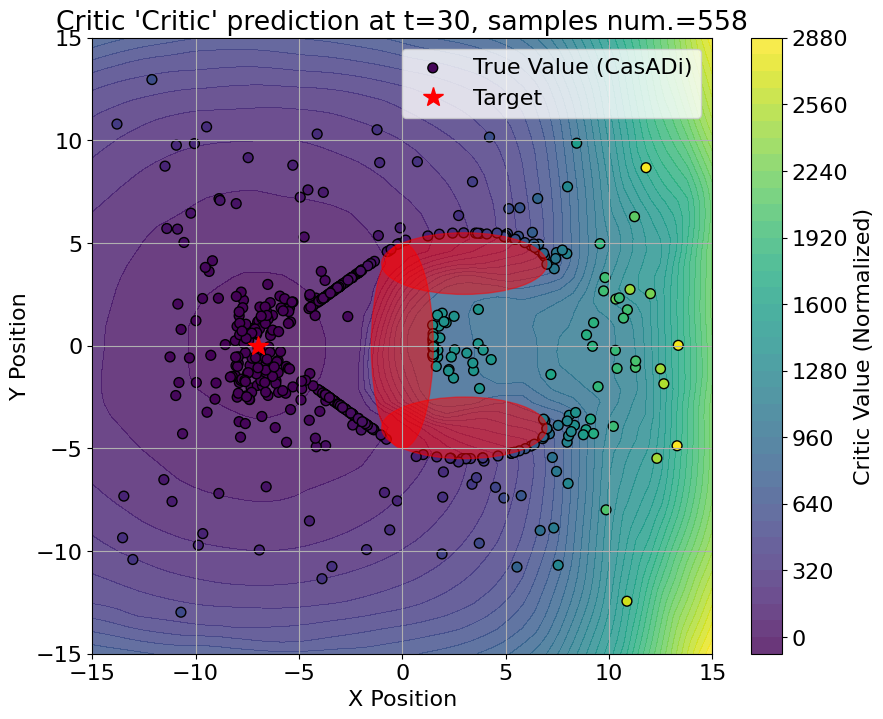

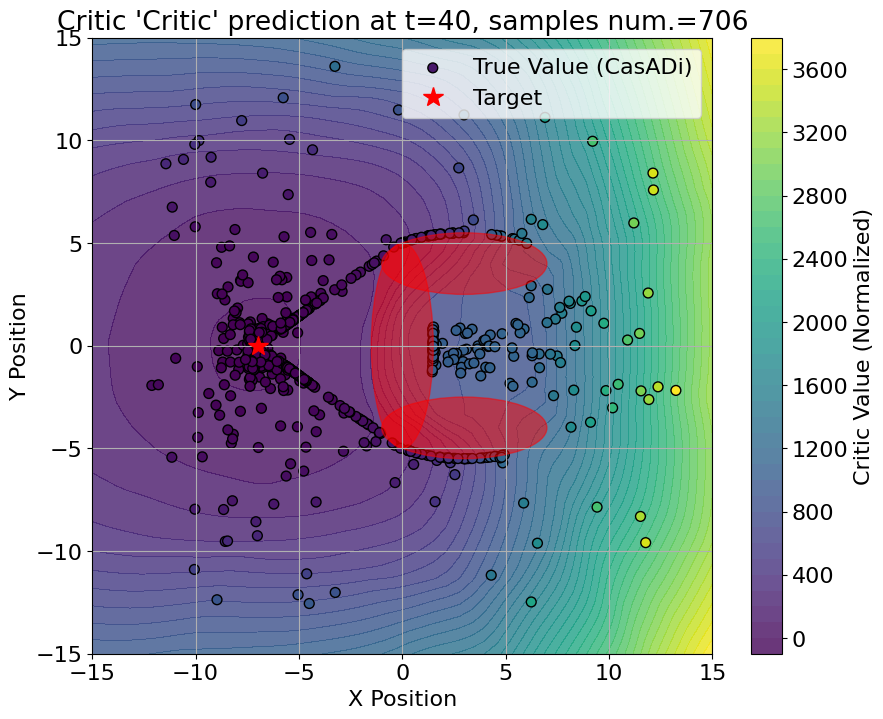

In [44]:
# Train the critic again with the new data in the buffer 
train_critic()

# Update the critic cycles counter
critic_cycles += cycles_counter(replay_buffer, minibatch_size, critic_epochs)
print(f"\nTotal critic cycles: {critic_cycles}")


for t in range(0, N, 10):
  plot_critic(critic, t, show=False)

--- CACTO Iteration 6 ---
--- Start training the constrained actor ---
--- Starting Constrained Actor training for 35 epochs ---
Epoch 1/35 | Mean Q+ALM: 259.3761 | Max Viol: 0.00258 | Lambda: [67.91 35.86 35.58] | Rho: 288.1 | LR: 0.000500 | step: 98
 | dQ/du norm: 1.463676
Epoch 5/35 | Mean Q+ALM: 259.3602 | Max Viol: 0.00114 | Lambda: [68.27 36.51 35.97] | Rho: 299.8 | LR: 0.000500 | step: 490
 | dQ/du norm: 1.466972
Epoch 10/35 | Mean Q+ALM: 259.2789 | Max Viol: 0.00292 | Lambda: [69.16 37.24 36.66] | Rho: 315.1 | LR: 0.000500 | step: 980
 | dQ/du norm: 1.428568
Epoch 15/35 | Mean Q+ALM: 259.2158 | Max Viol: 0.00146 | Lambda: [69.85 38.28 37.35] | Rho: 331.2 | LR: 0.000400 | step: 1470
 | dQ/du norm: 1.455250
Epoch 20/35 | Mean Q+ALM: 259.1309 | Max Viol: 0.00202 | Lambda: [70.75 39.04 38.04] | Rho: 348.0 | LR: 0.000320 | step: 1960
 | dQ/du norm: 1.394213
Epoch 25/35 | Mean Q+ALM: 259.0788 | Max Viol: 0.00126 | Lambda: [71.73 39.93 38.66] | Rho: 365.8 | LR: 0.000256 | step: 2450
 

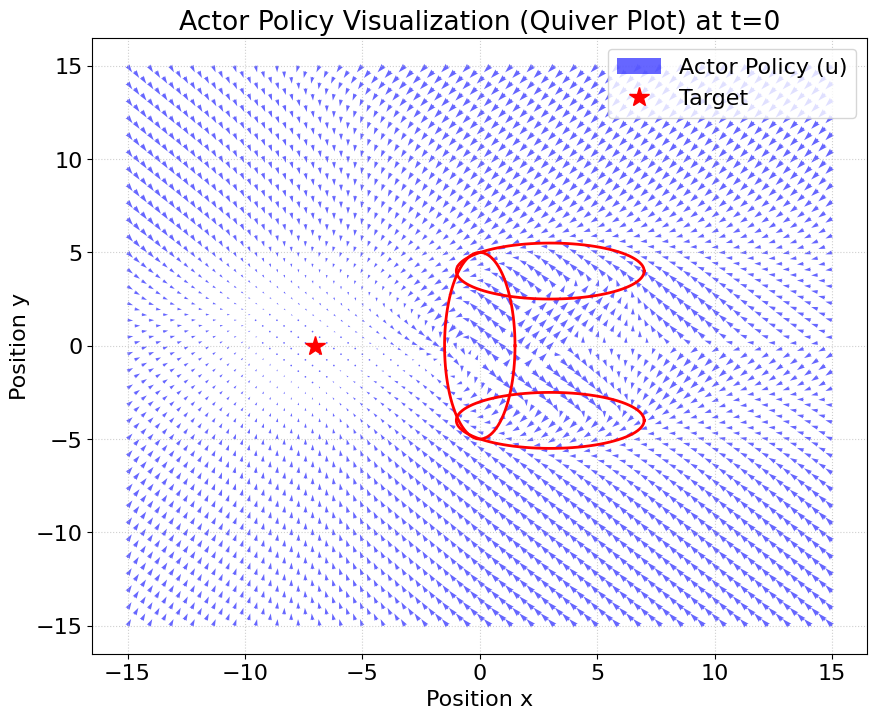

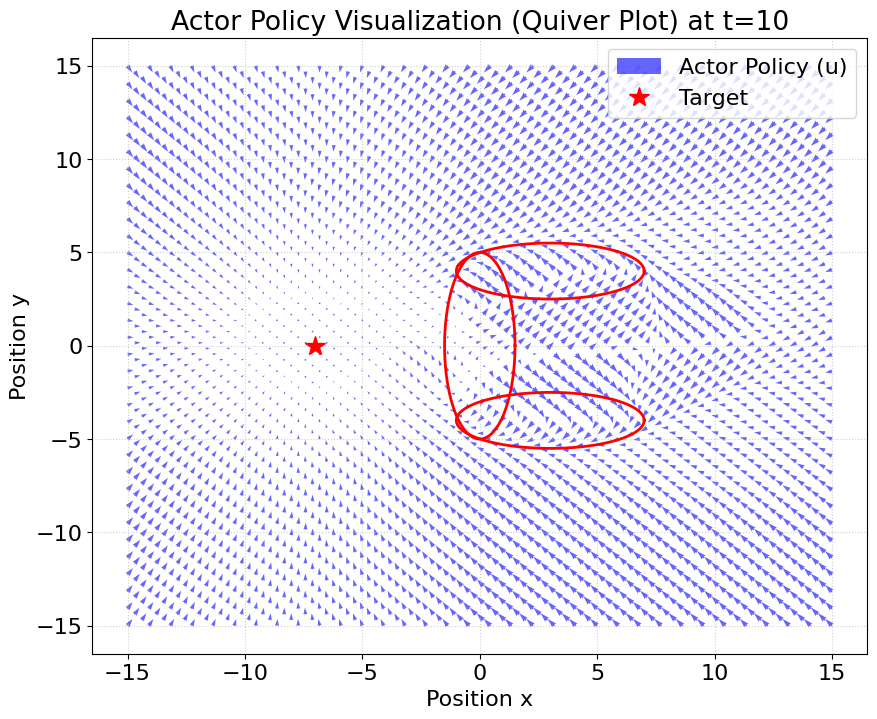

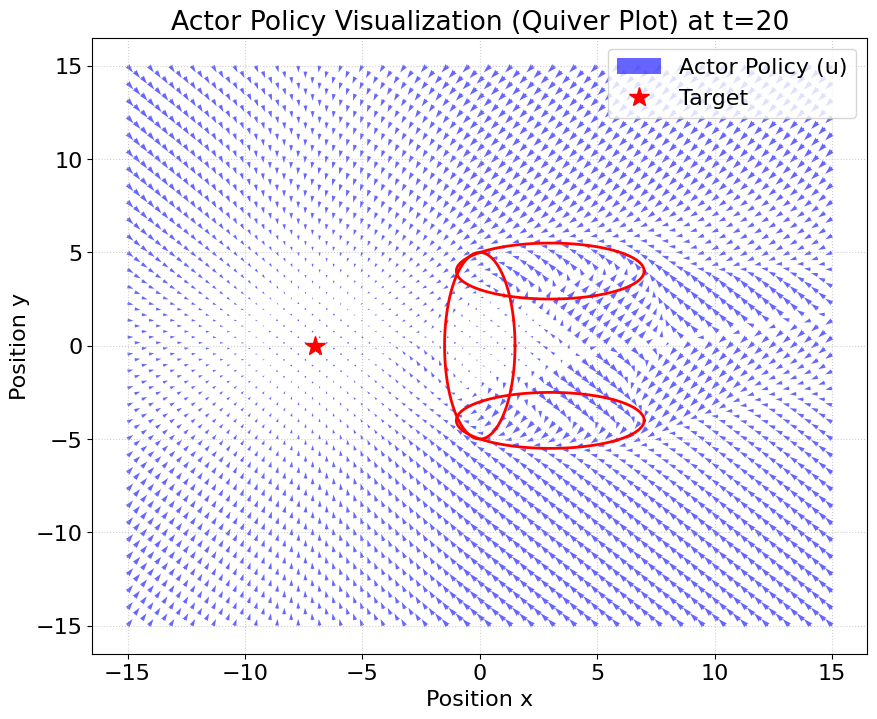

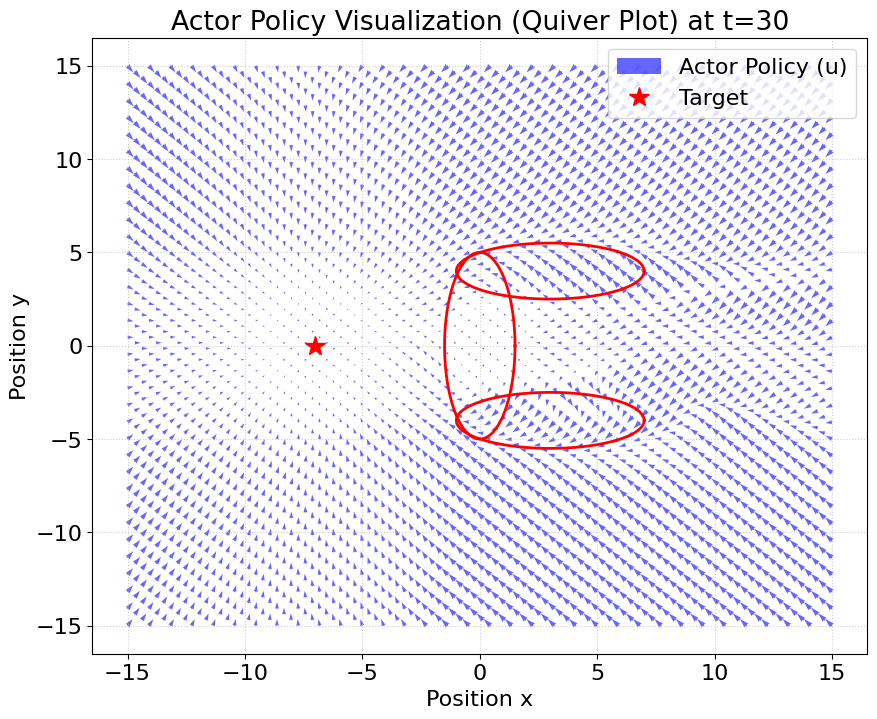

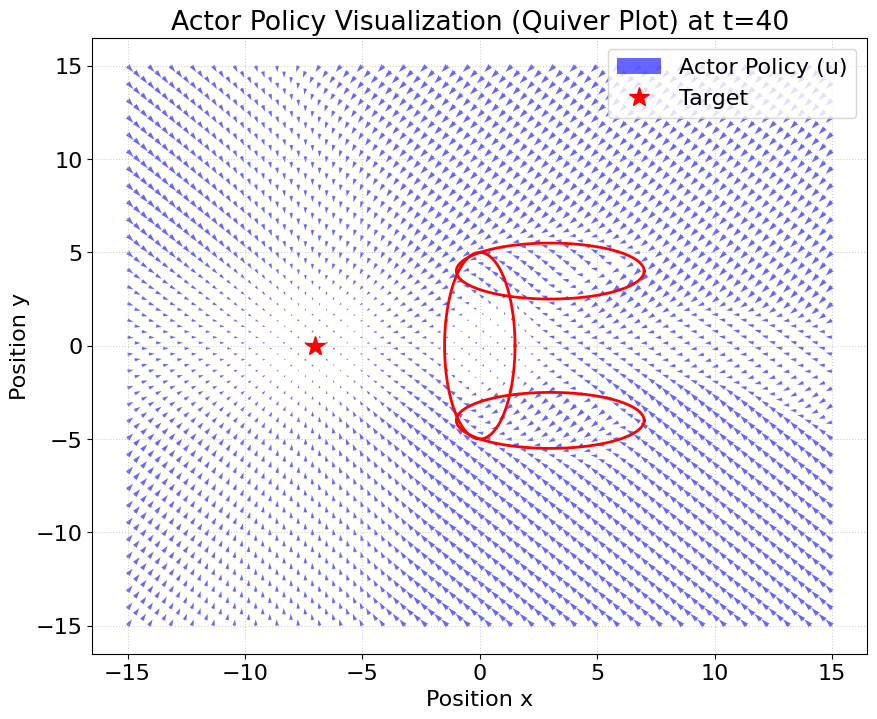

In [45]:
# Train the constrained actor again with the new critic

train_constr_actor()

# Update the constrained actor cycles counter
actor_cycles += cycles_counter(replay_buffer, minibatch_size, actor_epochs)
print(f"\nTotal constrained actor cycles: {actor_cycles}")


for t in range(0, N, 10):
  plot_constr_actor(t, show=True, plot_u_ocp=True)

Actor Only -> Feasible: 10/37 | Violating: 27/37
Actor Only -> Avg. max violation: 0.2890
Actor Only -> Avg. cost: 433.5874


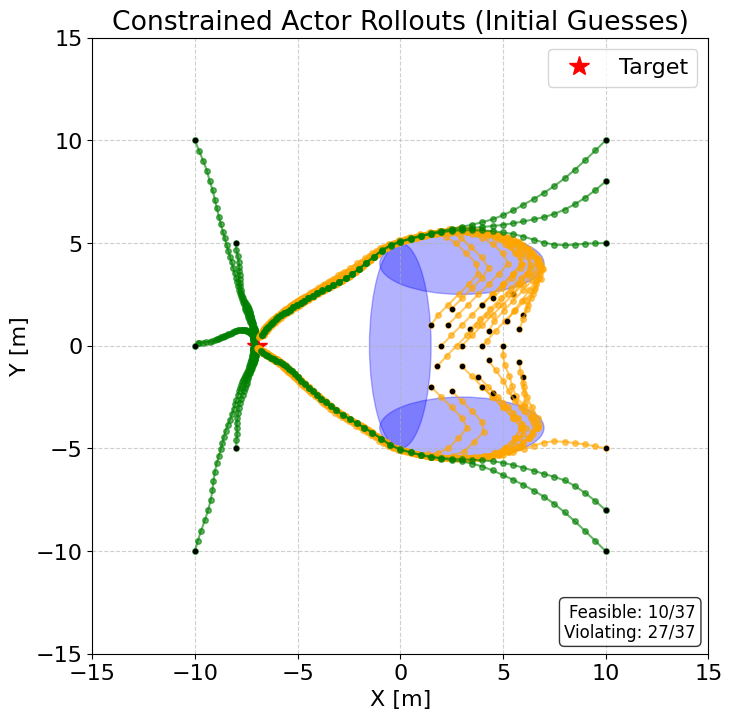

Computing initial guesses in batch...
Skip i=11: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=12: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=24: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
TO + Warm Start -> Time: 18.783 s
TO + Warm Start -> Feasible: 34/37 | Failed: 3/37


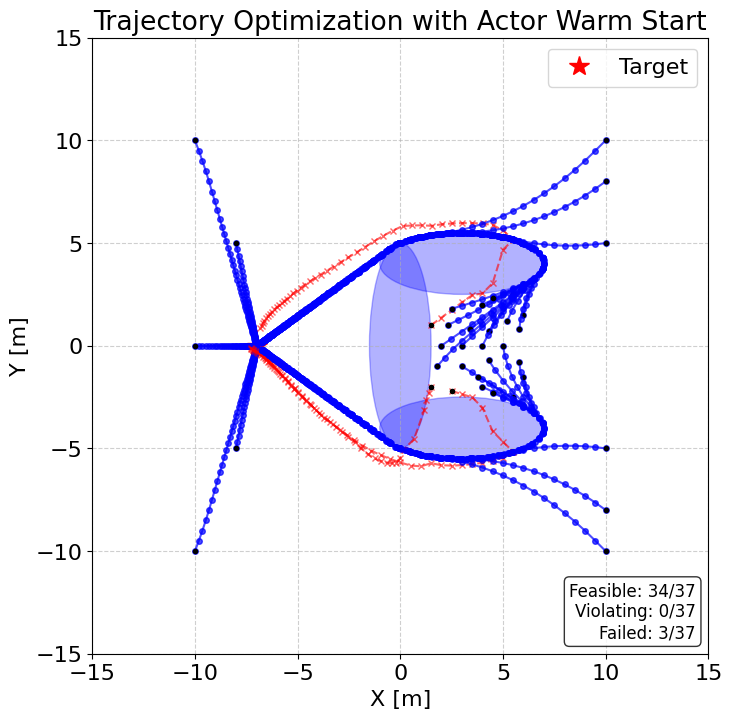

In [46]:
# Final evaluation of the constrained actor rollouts and TO performance after the last iteration
plot_cons_actor_rollouts()
V_TO, all_cons_x_trajs = evaluate_TO_w_cons_warm_start()

--- CACTO Iteration 7 ---
Start solving 300 TO problems


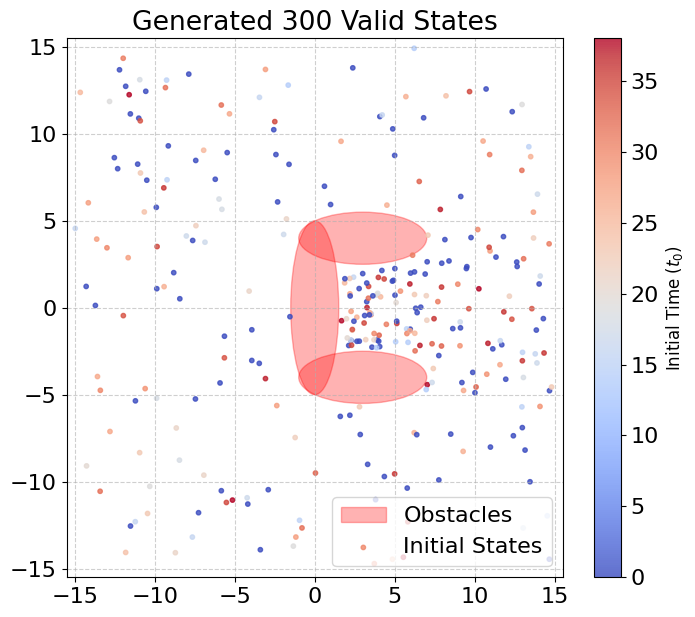

Computing warm start guesses via Actor...


COmputing OCPs: 100%|██████████| 300/300 [01:32<00:00,  3.24traj/s]


--- Finished ---
Successfully solved: 300 / 300
States Buffer size: (25000, 3) samples
Time taken: 95.265 s


In [47]:
# Solve an OCP for every sampled initial state-time using the constrained actor for warm start
solve_TO_problems(use_actor_to_warm_start=True, actor=cons_actor)

--- CACTO Iteration 7 ---
--- Start training critic ---
Replay buffer size: 25000 samples
Epoch 1/35 | MSE: 116.5640 | RMSE: 10.7965 | LR: 0.005000 | step: 98
Epoch 5/35 | MSE: 110.4364 | RMSE: 10.5089 | LR: 0.005000 | step: 490
Epoch 10/35 | MSE: 80.6143 | RMSE: 8.9785 | LR: 0.005000 | step: 980
Epoch 15/35 | MSE: 80.0509 | RMSE: 8.9471 | LR: 0.003750 | step: 1470
Epoch 20/35 | MSE: 77.8461 | RMSE: 8.8230 | LR: 0.002812 | step: 1960
Epoch 25/35 | MSE: 63.8904 | RMSE: 7.9931 | LR: 0.002109 | step: 2450
Epoch 30/35 | MSE: 48.6223 | RMSE: 6.9730 | LR: 0.001582 | step: 2940
Epoch 35/35 | MSE: 34.1705 | RMSE: 5.8456 | LR: 0.001187 | step: 3430
Final Critic MSE: 34.17
Final Critic RMSE: 5.85
--- Critic training has finished ---

Total critic cycles: 21560


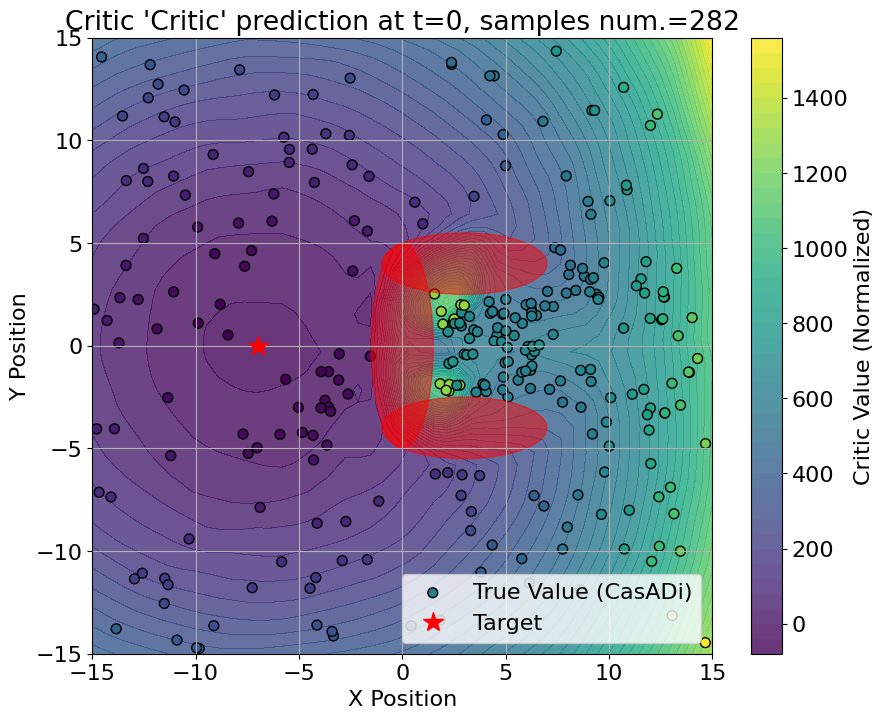

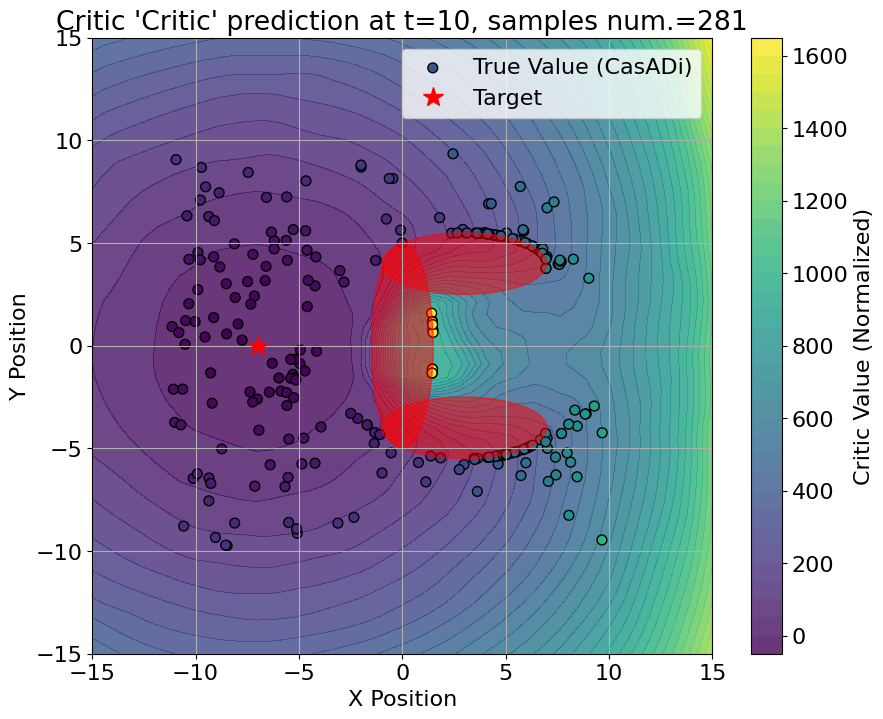

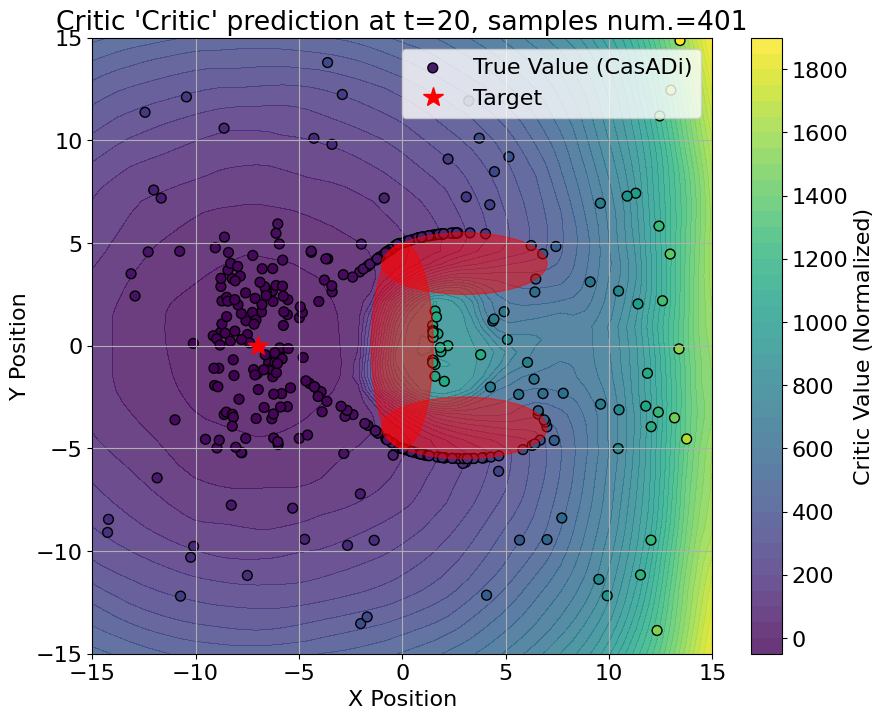

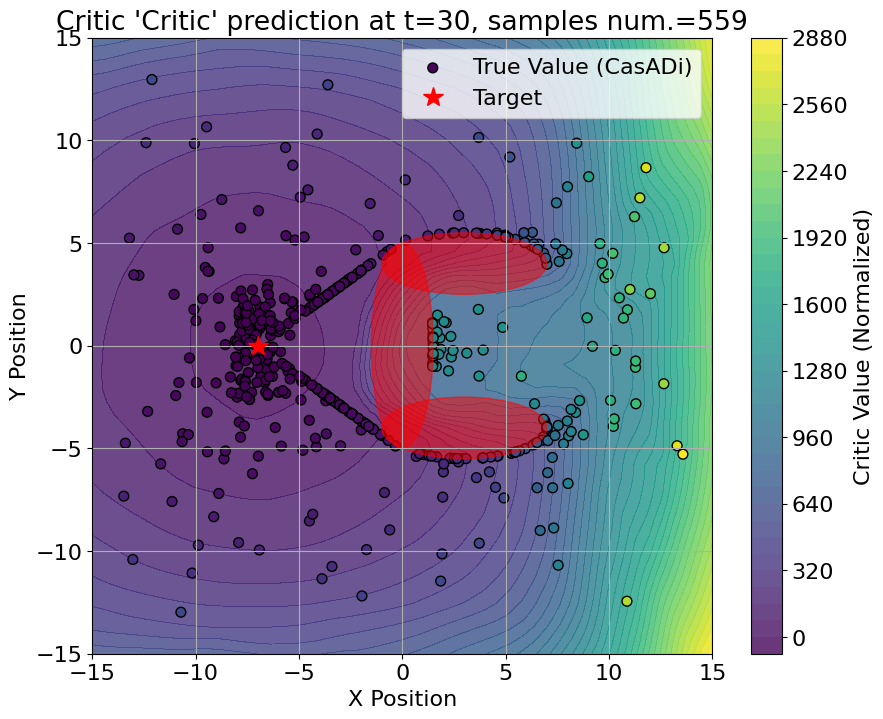

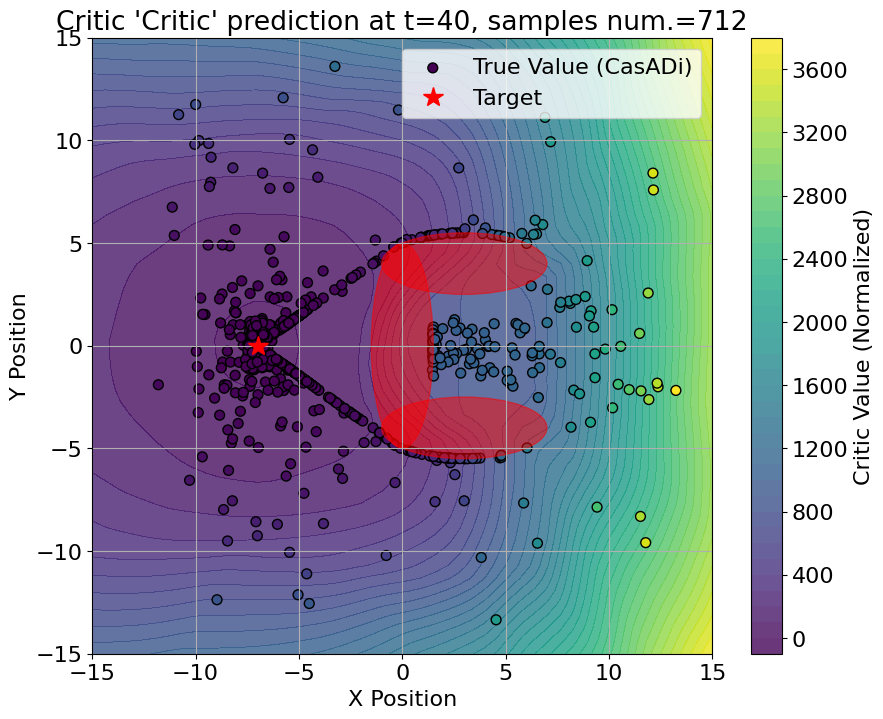

In [48]:
# Train the critic again with the new data in the buffer 
train_critic()

# Update the critic cycles counter
critic_cycles += cycles_counter(replay_buffer, minibatch_size, critic_epochs)
print(f"\nTotal critic cycles: {critic_cycles}")

for t in range(0, N, 10):
  plot_critic(critic, t, show=False)

--- CACTO Iteration 7 ---
--- Start training the constrained actor ---
--- Starting Constrained Actor training for 35 epochs ---
Epoch 1/35 | Mean Q+ALM: 263.8307 | Max Viol: 0.00310 | Lambda: [73.36 41.93 40.13] | Rho: 408.1 | LR: 0.000500 | step: 98
 | dQ/du norm: 1.500975
Epoch 5/35 | Mean Q+ALM: 263.7187 | Max Viol: 0.00190 | Lambda: [74.15 43.07 40.93] | Rho: 424.7 | LR: 0.000500 | step: 490
 | dQ/du norm: 1.489606
Epoch 10/35 | Mean Q+ALM: 263.6650 | Max Viol: 0.00086 | Lambda: [75.28 44.51 42.14] | Rho: 446.3 | LR: 0.000500 | step: 980
 | dQ/du norm: 1.505032
Epoch 15/35 | Mean Q+ALM: 263.6264 | Max Viol: 0.00190 | Lambda: [76.36 45.84 43.5 ] | Rho: 469.1 | LR: 0.000400 | step: 1470
 | dQ/du norm: 1.498299
Epoch 20/35 | Mean Q+ALM: 263.6015 | Max Viol: 0.00115 | Lambda: [77.08 47.07 44.49] | Rho: 493.0 | LR: 0.000320 | step: 1960
 | dQ/du norm: 1.499636
Epoch 25/35 | Mean Q+ALM: 263.5543 | Max Viol: 0.00095 | Lambda: [78.47 48.15 45.6 ] | Rho: 518.2 | LR: 0.000256 | step: 2450
 

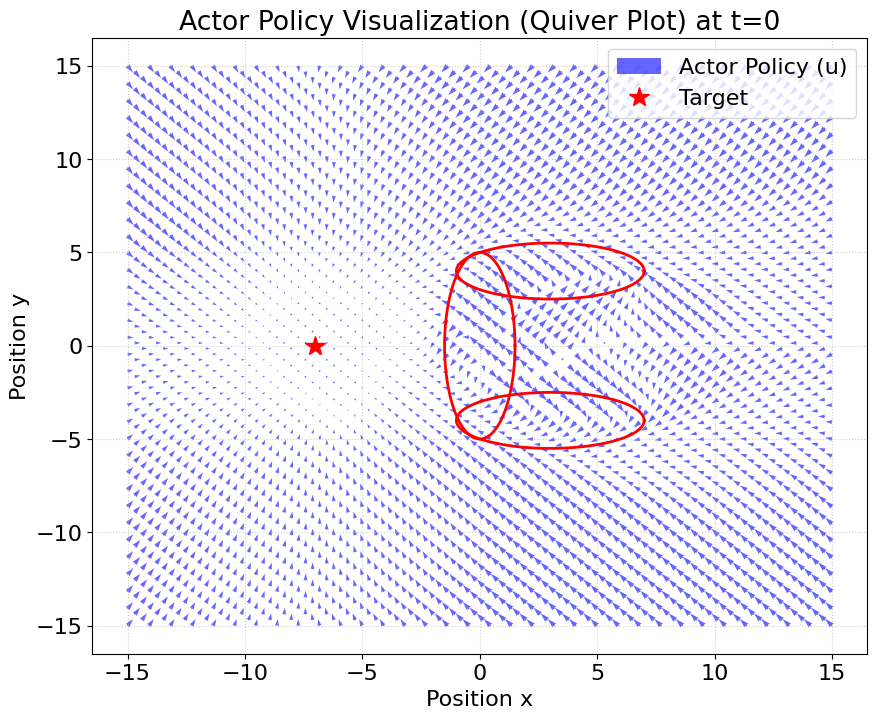

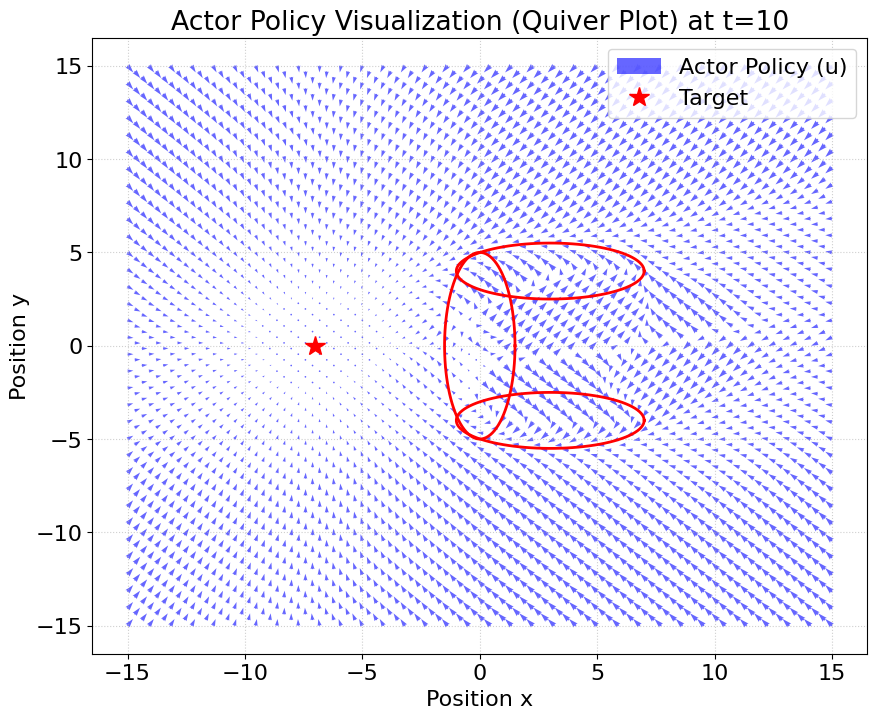

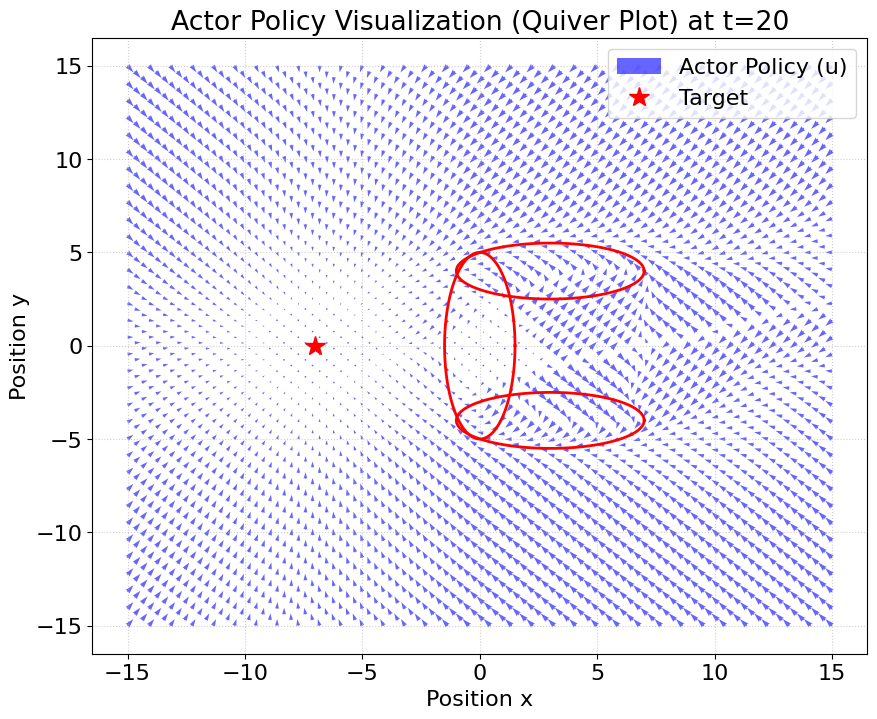

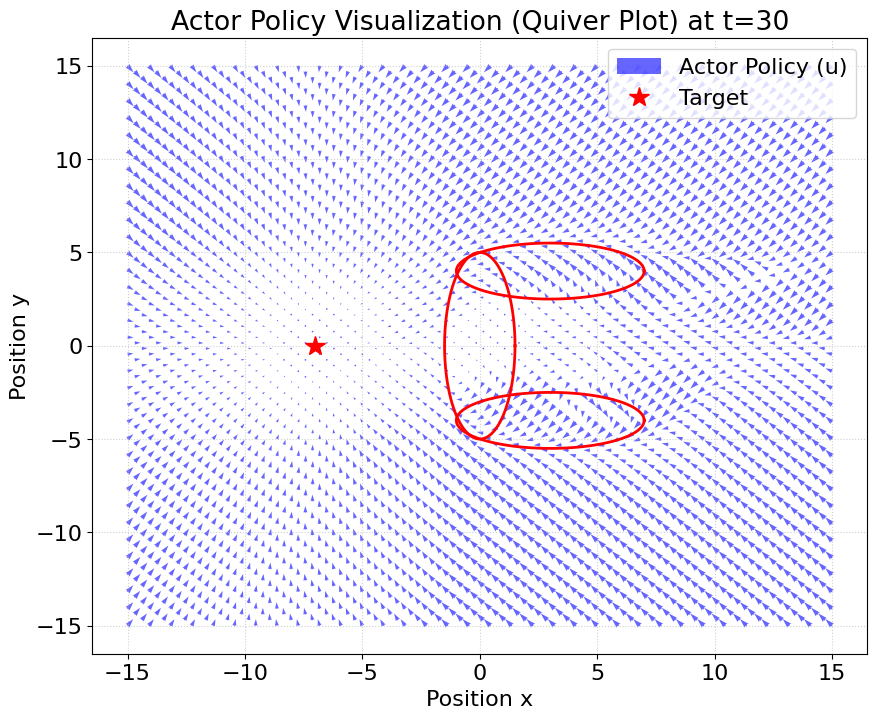

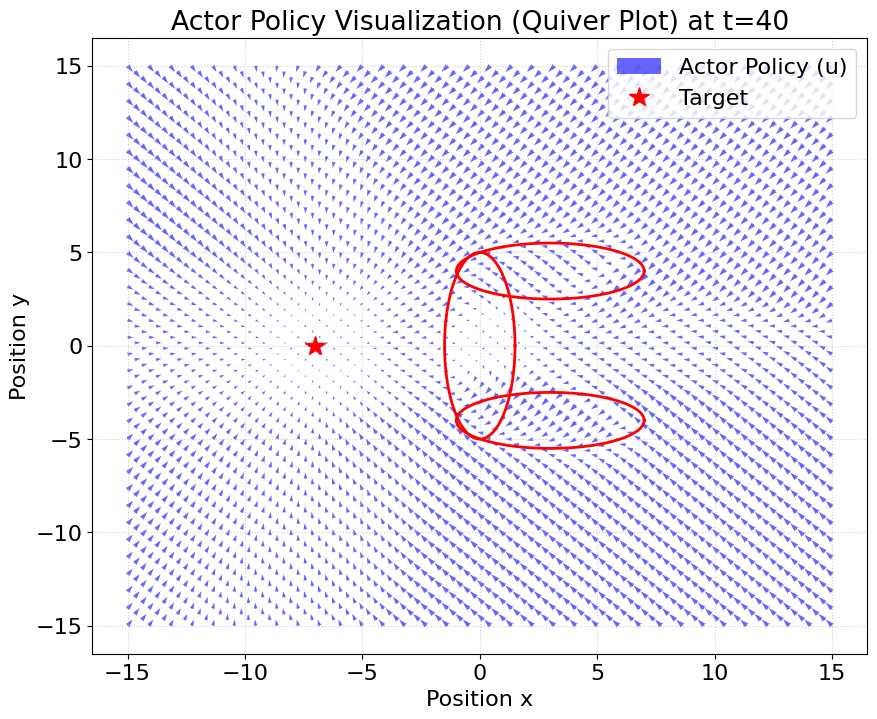

In [49]:
# Train the constrained actor again with the new critic

train_constr_actor()

# Update the constrained actor cycles counter
actor_cycles += cycles_counter(replay_buffer, minibatch_size, actor_epochs)
print(f"\nTotal constrained actor cycles: {actor_cycles}")

for t in range(0, N, 10):
  plot_constr_actor(t, show=True, plot_u_ocp=True)

Actor Only -> Feasible: 8/37 | Violating: 29/37
Actor Only -> Avg. max violation: 0.2895
Actor Only -> Avg. cost: 437.2678

Costs and Feasibility List:
Rollout 001 | Xini: (-10.0, -10.0) | Cost:   126.10 | Status: OK
Rollout 002 | Xini: (-8.0, -5.0) | Cost:    -7.22 | Status: OK
Rollout 003 | Xini: (-10.0,  0.0) | Cost:   -34.50 | Status: OK
Rollout 004 | Xini: (-8.0,  5.0) | Cost:    -7.31 | Status: OK
Rollout 005 | Xini: (-10.0, 10.0) | Cost:   126.21 | Status: OK
Rollout 006 | Xini: ( 5.0,  0.0) | Cost:   553.48 | Status: VIOL
Rollout 007 | Xini: ( 6.0,  1.5) | Cost:   493.81 | Status: VIOL
Rollout 008 | Xini: ( 6.0, -1.5) | Cost:   493.59 | Status: VIOL
Rollout 009 | Xini: ( 5.5,  2.5) | Cost:   441.18 | Status: VIOL
Rollout 010 | Xini: ( 5.5, -2.5) | Cost:   441.55 | Status: VIOL
Rollout 011 | Xini: ( 2.0,  0.0) | Cost:   468.86 | Status: VIOL
Rollout 012 | Xini: ( 1.5,  1.0) | Cost:   382.69 | Status: VIOL
Rollout 013 | Xini: ( 1.5, -2.0) | Cost:   287.89 | Status: VIOL
Rollout 0

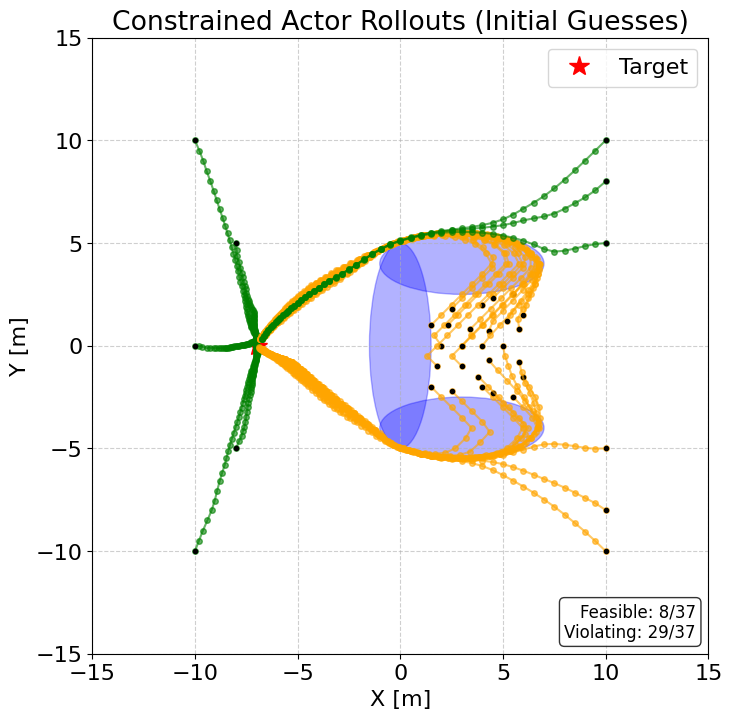

Computing initial guesses in batch...
Skip i=11: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=12: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=23: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=24: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
TO + Warm Start -> Time: 21.352 s
TO + Warm Start -> Feasible: 33/37 | Failed: 4/37


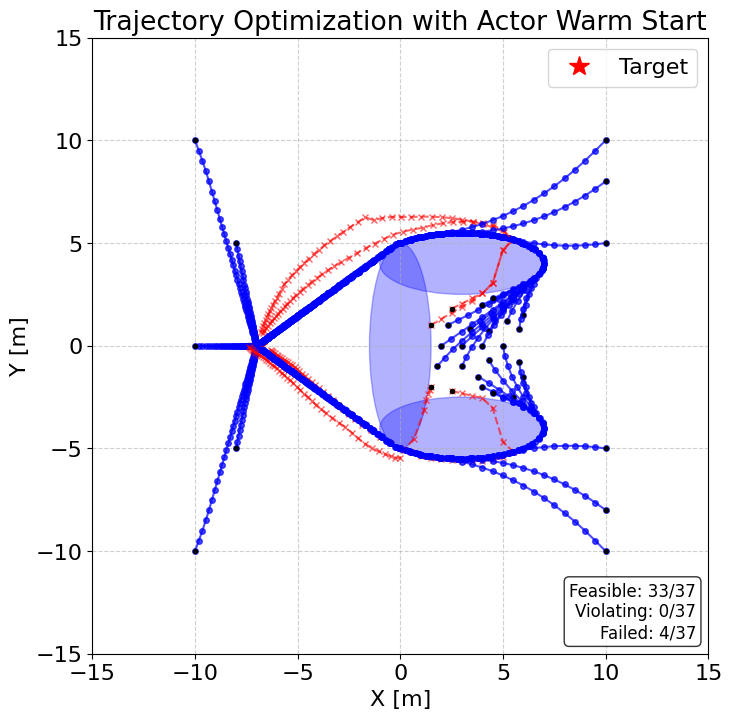

In [50]:
# Final evaluation of the constrained actor rollouts and TO performance after the last iteration
plot_cons_actor_rollouts(print_costs=True)
V_TO, all_cons_x_trajs = evaluate_TO_w_cons_warm_start()

--- CACTO Iteration 8 ---
Start solving 300 TO problems


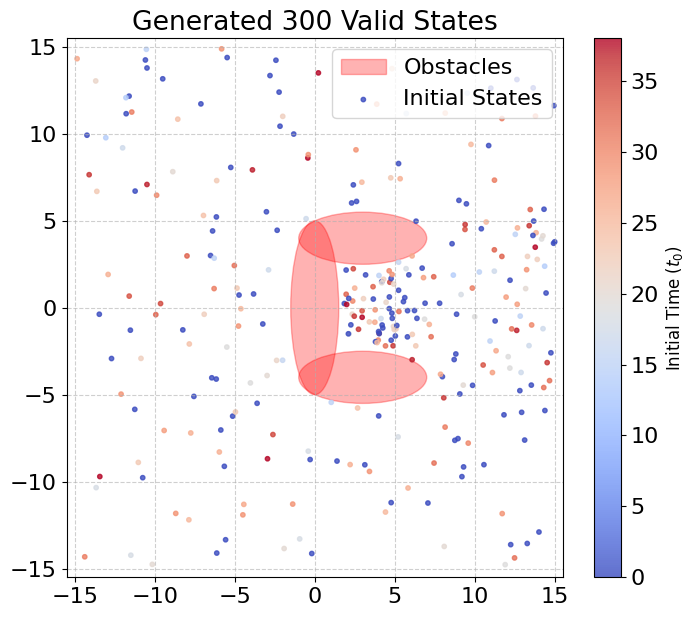

Computing warm start guesses via Actor...


COmputing OCPs: 100%|██████████| 300/300 [01:41<00:00,  2.97traj/s]


--- Finished ---
Successfully solved: 300 / 300
States Buffer size: (25000, 3) samples
Time taken: 103.865 s


In [51]:
# Solve an OCP for every sampled initial state-time using the constrained actor for warm start
solve_TO_problems(use_actor_to_warm_start=True, actor=cons_actor)

--- CACTO Iteration 8 ---
--- Start training critic ---
Replay buffer size: 25000 samples
Epoch 1/35 | MSE: 220.6721 | RMSE: 14.8550 | LR: 0.005000 | step: 98
Epoch 5/35 | MSE: 84.5176 | RMSE: 9.1933 | LR: 0.005000 | step: 490
Epoch 10/35 | MSE: 124.5913 | RMSE: 11.1620 | LR: 0.005000 | step: 980
Epoch 15/35 | MSE: 102.2383 | RMSE: 10.1113 | LR: 0.003750 | step: 1470
Epoch 20/35 | MSE: 113.4716 | RMSE: 10.6523 | LR: 0.002812 | step: 1960
Epoch 25/35 | MSE: 36.0062 | RMSE: 6.0005 | LR: 0.002109 | step: 2450
Epoch 30/35 | MSE: 30.5617 | RMSE: 5.5283 | LR: 0.001582 | step: 2940
Epoch 35/35 | MSE: 30.9952 | RMSE: 5.5673 | LR: 0.001187 | step: 3430
Final Critic MSE: 31.00
Final Critic RMSE: 5.57
--- Critic training has finished ---

Total critic cycles: 24990


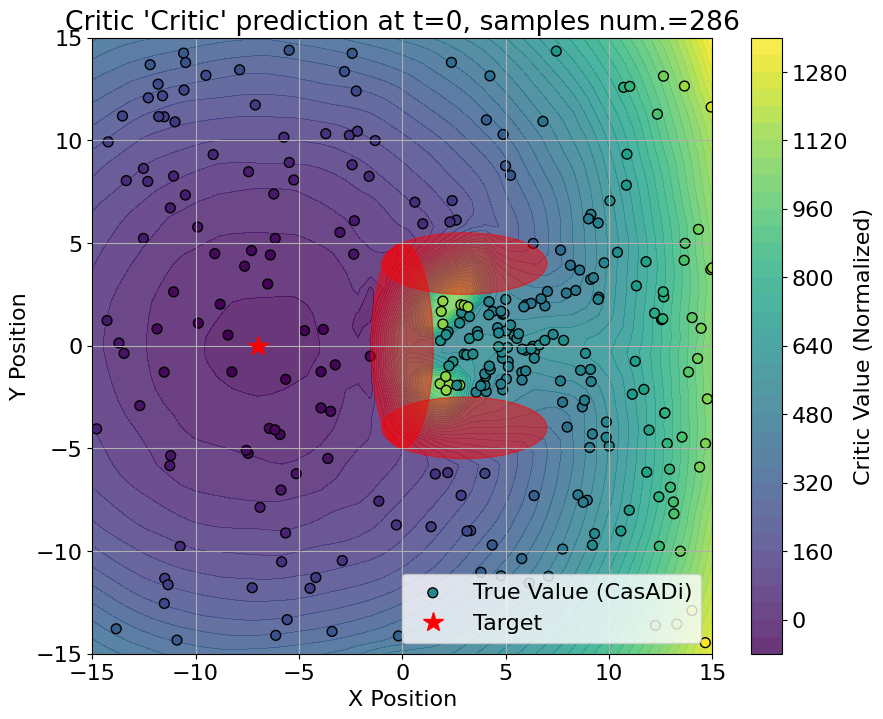

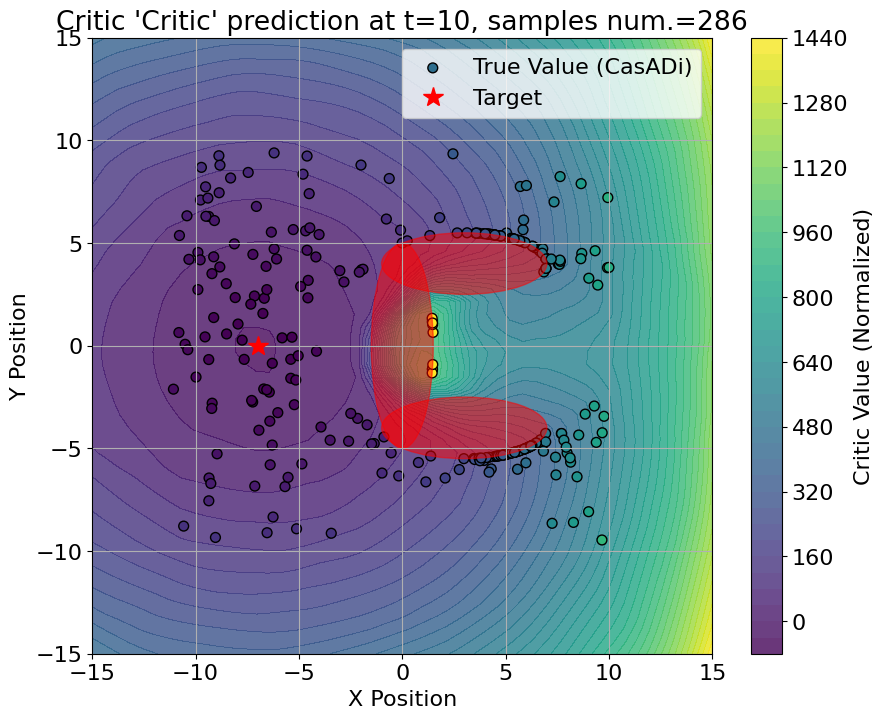

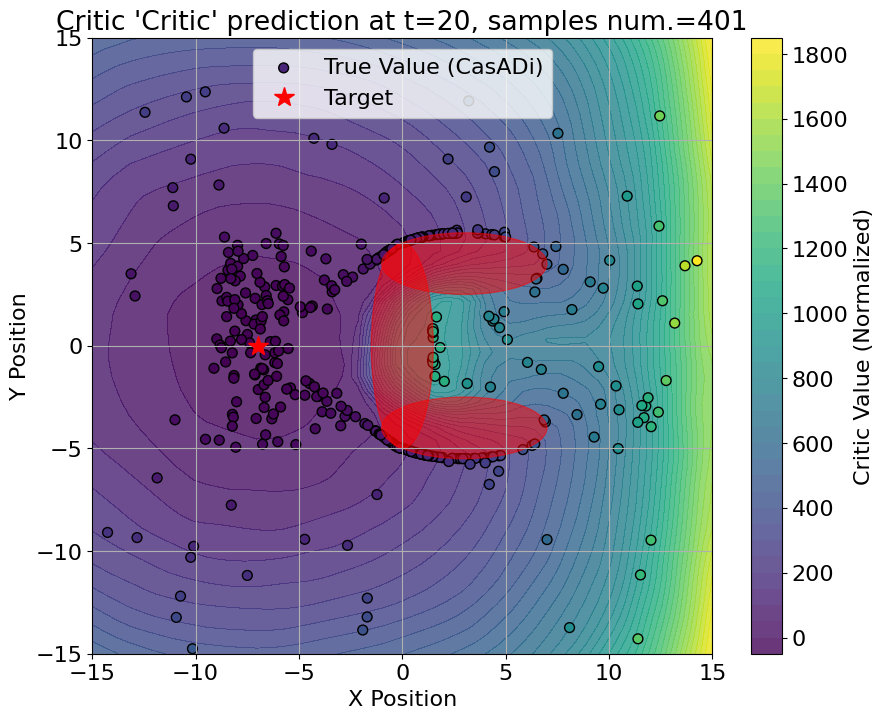

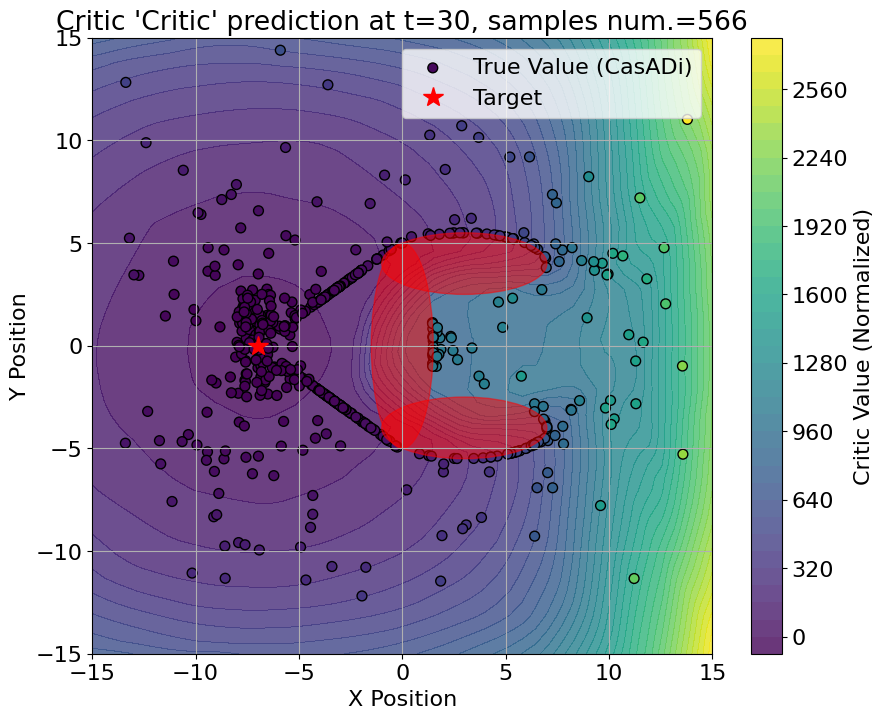

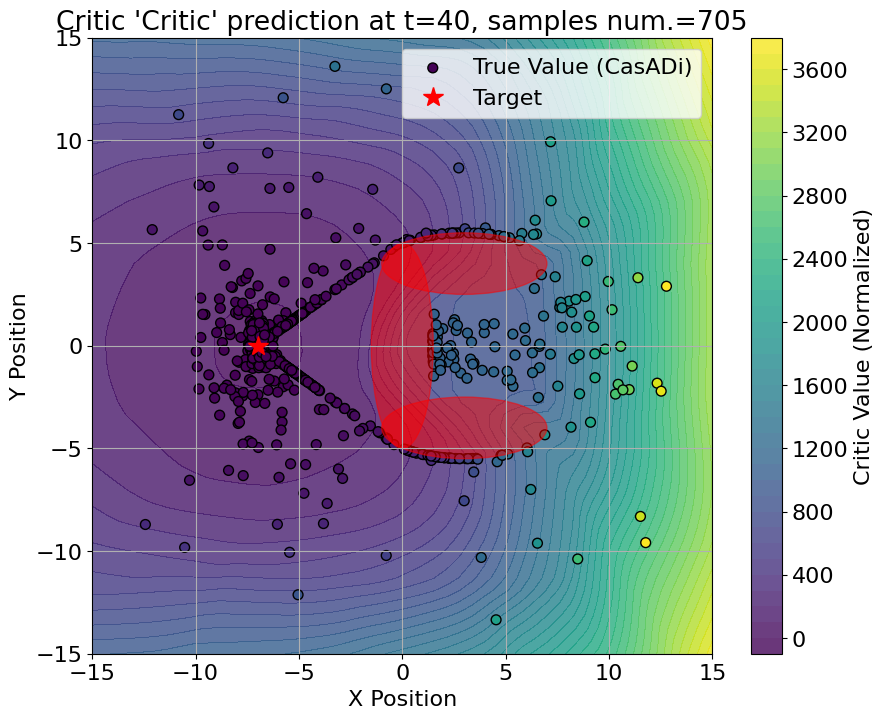

In [52]:
# Train the critic again with the new data in the buffer 
train_critic()

# Update the critic cycles counter
critic_cycles += cycles_counter(replay_buffer, minibatch_size, critic_epochs)
print(f"\nTotal critic cycles: {critic_cycles}")

for t in range(0, N, 10):
  plot_critic(critic, t, show=False)

--- CACTO Iteration 8 ---
--- Start training the constrained actor ---
--- Starting Constrained Actor training for 35 epochs ---
Epoch 1/35 | Mean Q+ALM: 254.0695 | Max Viol: 0.00115 | Lambda: [80.16 50.26 48.33] | Rho: 578.1 | LR: 0.000500 | step: 98
 | dQ/du norm: 1.540260
Epoch 5/35 | Mean Q+ALM: 253.8448 | Max Viol: 0.00193 | Lambda: [80.56 51.13 49.68] | Rho: 601.6 | LR: 0.000500 | step: 490
 | dQ/du norm: 1.520438
Epoch 10/35 | Mean Q+ALM: 253.7540 | Max Viol: 0.00138 | Lambda: [81.1  52.31 51.1 ] | Rho: 632.3 | LR: 0.000500 | step: 980
 | dQ/du norm: 1.541088
Epoch 15/35 | Mean Q+ALM: 253.7208 | Max Viol: 0.00132 | Lambda: [82.18 53.62 52.56] | Rho: 664.5 | LR: 0.000400 | step: 1470
 | dQ/du norm: 1.532082
Epoch 20/35 | Mean Q+ALM: 253.6044 | Max Viol: 0.00188 | Lambda: [83.16 54.96 54.04] | Rho: 698.4 | LR: 0.000320 | step: 1960
 | dQ/du norm: 1.498866
Epoch 25/35 | Mean Q+ALM: 253.5125 | Max Viol: 0.00100 | Lambda: [83.74 56.41 55.35] | Rho: 734.1 | LR: 0.000256 | step: 2450
 

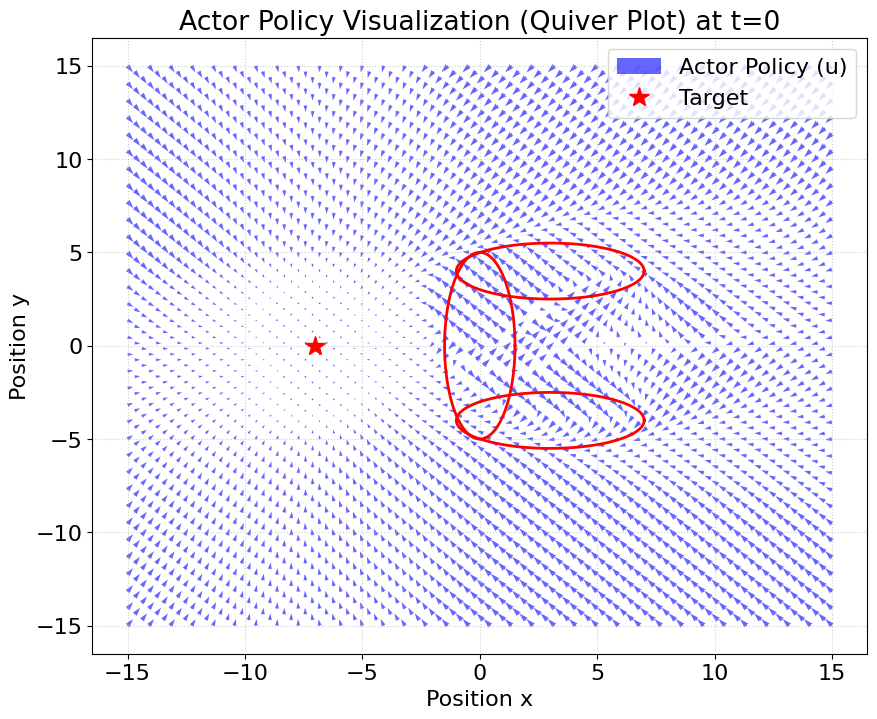

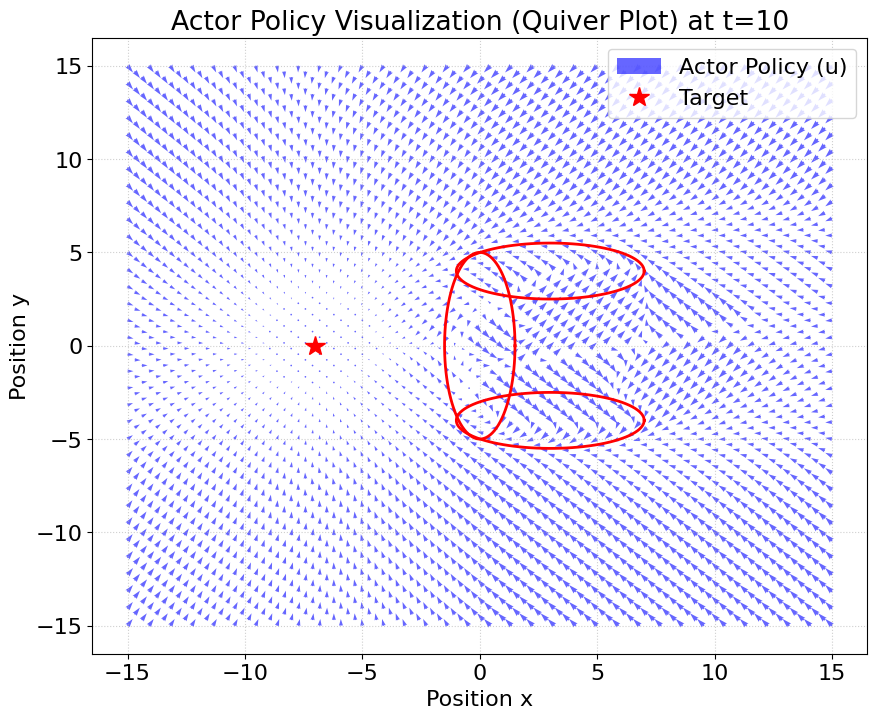

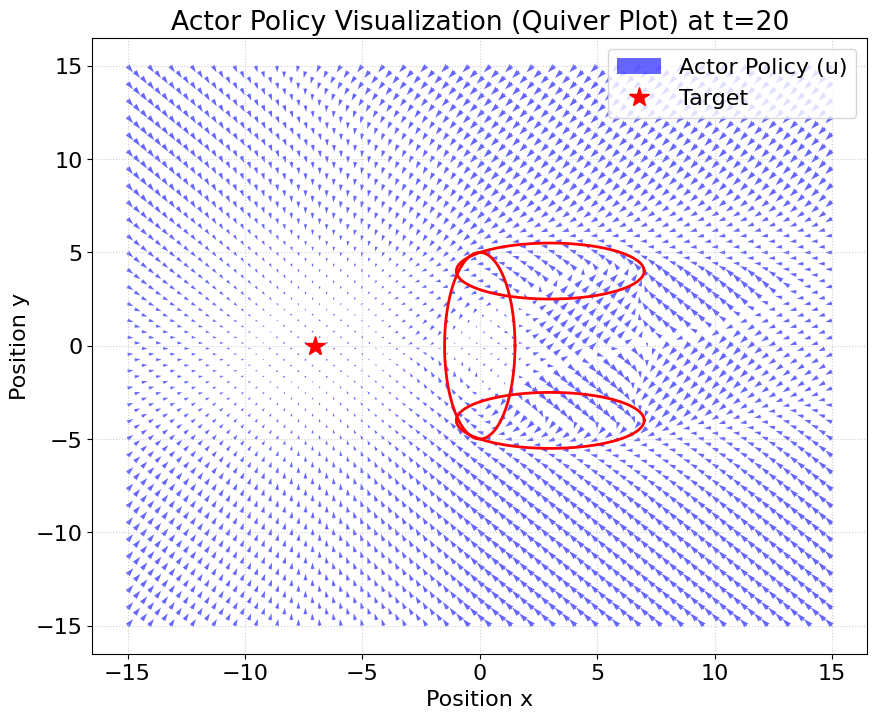

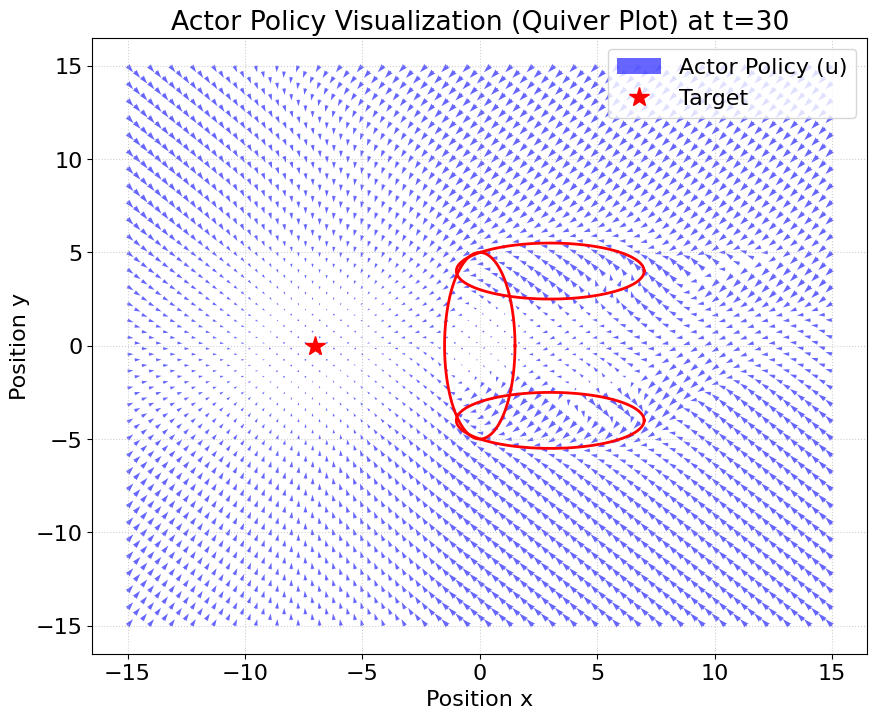

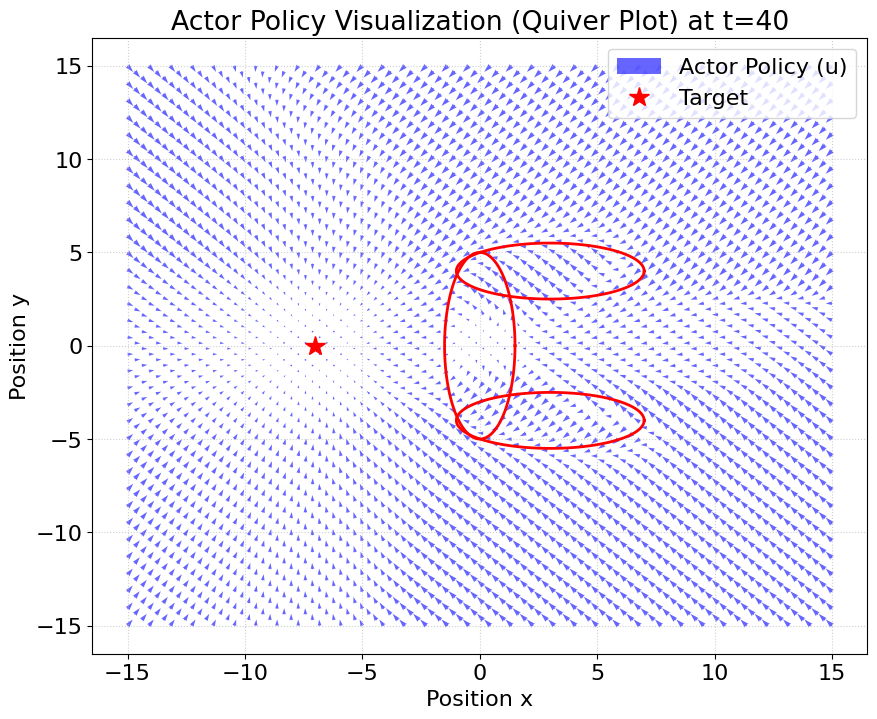

In [53]:
# Train the constrained actor again with the new critic

train_constr_actor()

# Update the constrained actor cycles counter
actor_cycles += cycles_counter(replay_buffer, minibatch_size, actor_epochs)
print(f"\nTotal constrained actor cycles: {actor_cycles}")

for t in range(0, N, 10):
  plot_constr_actor(t, show=True, plot_u_ocp=True)

Actor Only -> Feasible: 8/37 | Violating: 29/37
Actor Only -> Avg. max violation: 0.2200
Actor Only -> Avg. cost: 452.4421

Costs and Feasibility List:
Rollout 001 | Xini: (-10.0, -10.0) | Cost:   126.21 | Status: OK
Rollout 002 | Xini: (-8.0, -5.0) | Cost:    -7.61 | Status: OK
Rollout 003 | Xini: (-10.0,  0.0) | Cost:   -34.98 | Status: OK
Rollout 004 | Xini: (-8.0,  5.0) | Cost:    -7.54 | Status: OK
Rollout 005 | Xini: (-10.0, 10.0) | Cost:   126.26 | Status: OK
Rollout 006 | Xini: ( 5.0,  0.0) | Cost:   577.52 | Status: VIOL
Rollout 007 | Xini: ( 6.0,  1.5) | Cost:   511.95 | Status: VIOL
Rollout 008 | Xini: ( 6.0, -1.5) | Cost:   512.48 | Status: VIOL
Rollout 009 | Xini: ( 5.5,  2.5) | Cost:   458.97 | Status: VIOL
Rollout 010 | Xini: ( 5.5, -2.5) | Cost:   455.21 | Status: VIOL
Rollout 011 | Xini: ( 2.0,  0.0) | Cost:   561.85 | Status: VIOL
Rollout 012 | Xini: ( 1.5,  1.0) | Cost:   117.90 | Status: VIOL
Rollout 013 | Xini: ( 1.5, -2.0) | Cost:   320.83 | Status: VIOL
Rollout 0

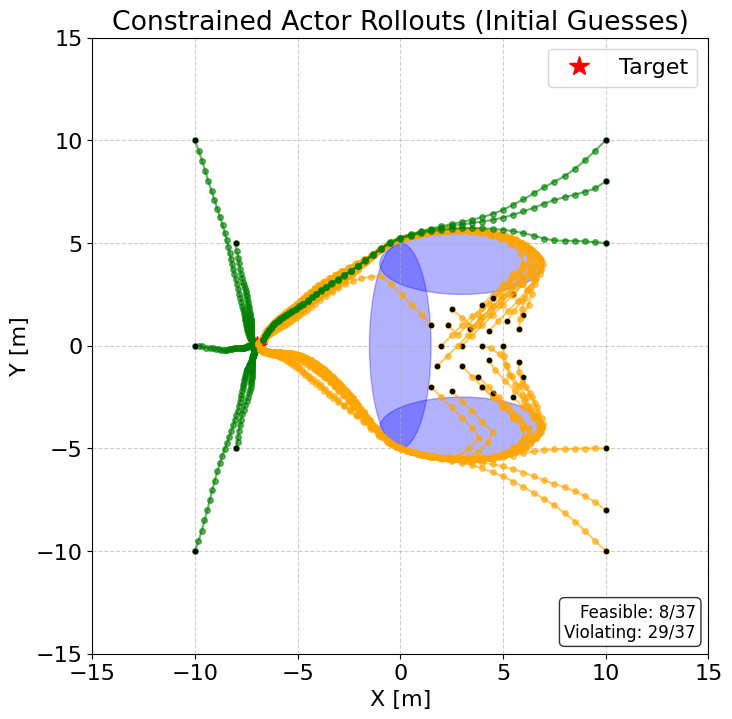

Computing initial guesses in batch...
Skip i=11: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=12: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=24: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
TO + Warm Start -> Time: 15.505 s
TO + Warm Start -> Feasible: 34/37 | Failed: 3/37


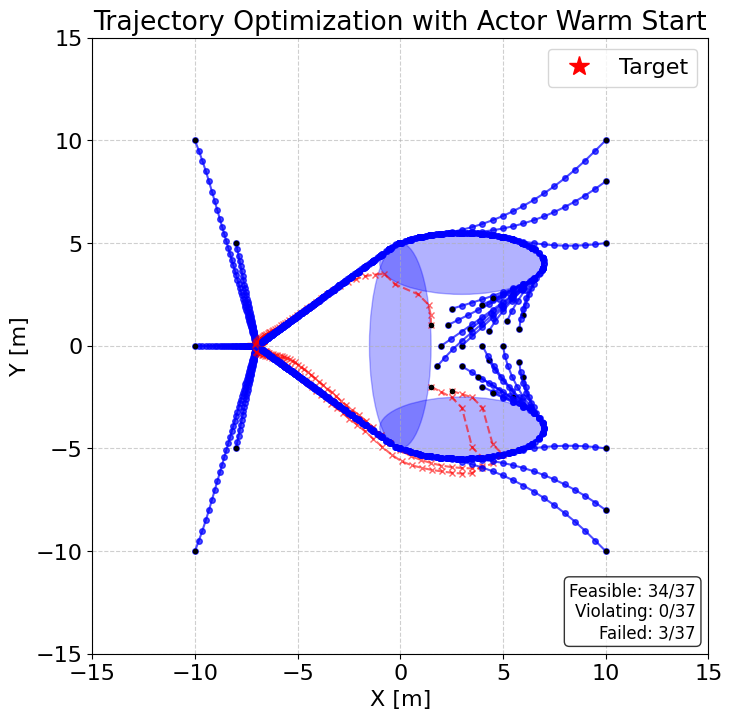

In [54]:
# Final evaluation of the constrained actor rollouts and TO performance after the last iteration
plot_cons_actor_rollouts(print_costs=True)
V_TO, all_cons_x_trajs = evaluate_TO_w_cons_warm_start()

--- CACTO Iteration 9 ---
Start solving 300 TO problems


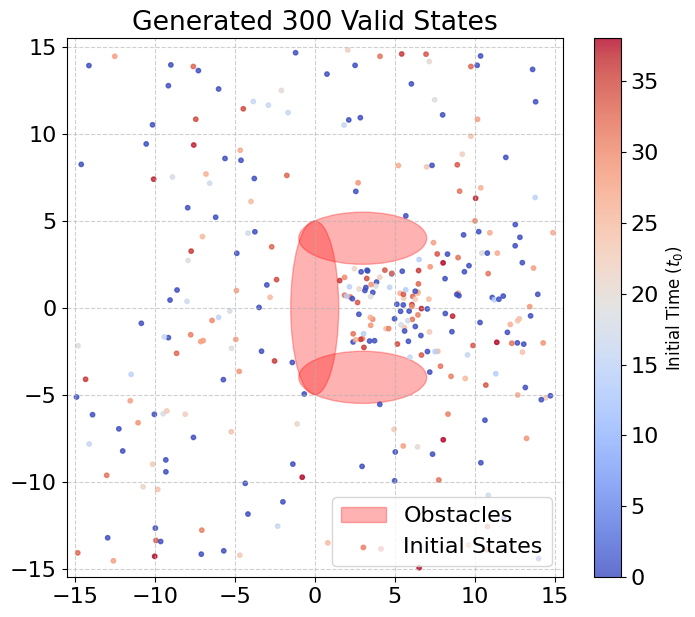

Computing warm start guesses via Actor...


COmputing OCPs: 100%|██████████| 300/300 [01:24<00:00,  3.55traj/s]


--- Finished ---
Successfully solved: 300 / 300
States Buffer size: (25000, 3) samples
Time taken: 87.037 s


In [55]:
# Solve an OCP for every sampled initial state-time using the constrained actor for warm start
solve_TO_problems(use_actor_to_warm_start=True, actor=cons_actor)

--- CACTO Iteration 9 ---
--- Start training critic ---
Replay buffer size: 25000 samples
Epoch 1/35 | MSE: 83.5795 | RMSE: 9.1422 | LR: 0.005000 | step: 98
Epoch 5/35 | MSE: 106.0940 | RMSE: 10.3002 | LR: 0.005000 | step: 490
Epoch 10/35 | MSE: 156.6745 | RMSE: 12.5170 | LR: 0.005000 | step: 980
Epoch 15/35 | MSE: 79.2217 | RMSE: 8.9007 | LR: 0.003750 | step: 1470
Epoch 20/35 | MSE: 25.1335 | RMSE: 5.0133 | LR: 0.002812 | step: 1960
Epoch 25/35 | MSE: 37.2911 | RMSE: 6.1066 | LR: 0.002109 | step: 2450
Epoch 30/35 | MSE: 18.6463 | RMSE: 4.3181 | LR: 0.001582 | step: 2940
Epoch 35/35 | MSE: 16.2337 | RMSE: 4.0291 | LR: 0.001187 | step: 3430
Final Critic MSE: 16.23
Final Critic RMSE: 4.03
--- Critic training has finished ---

Total critic cycles: 28420


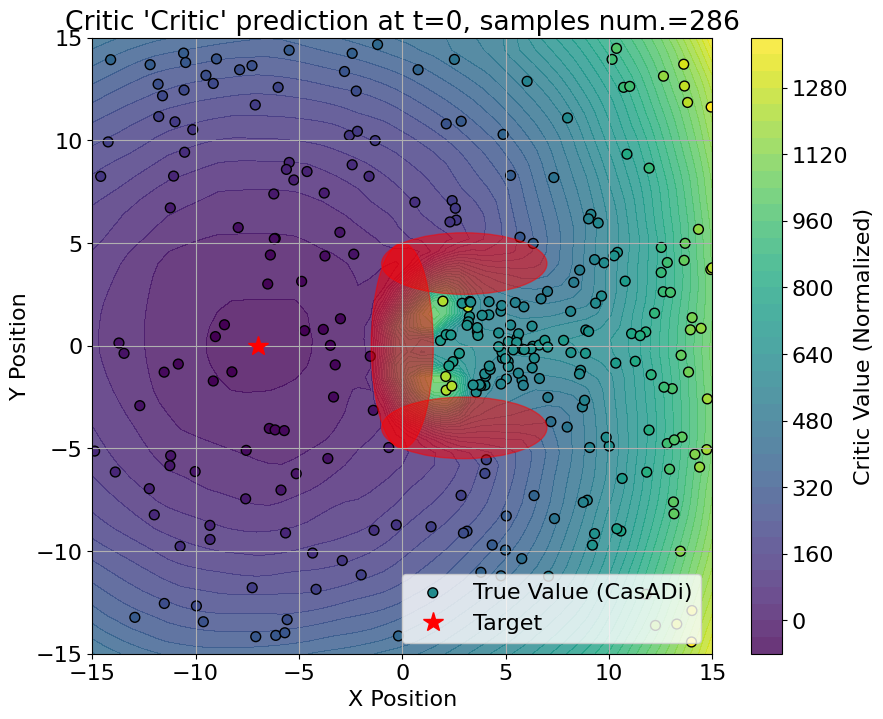

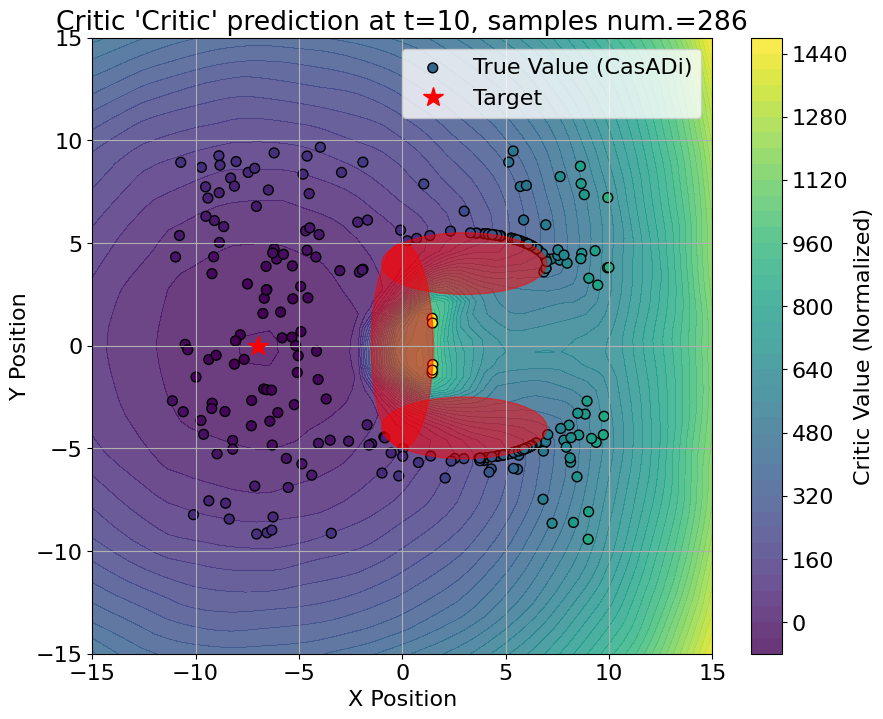

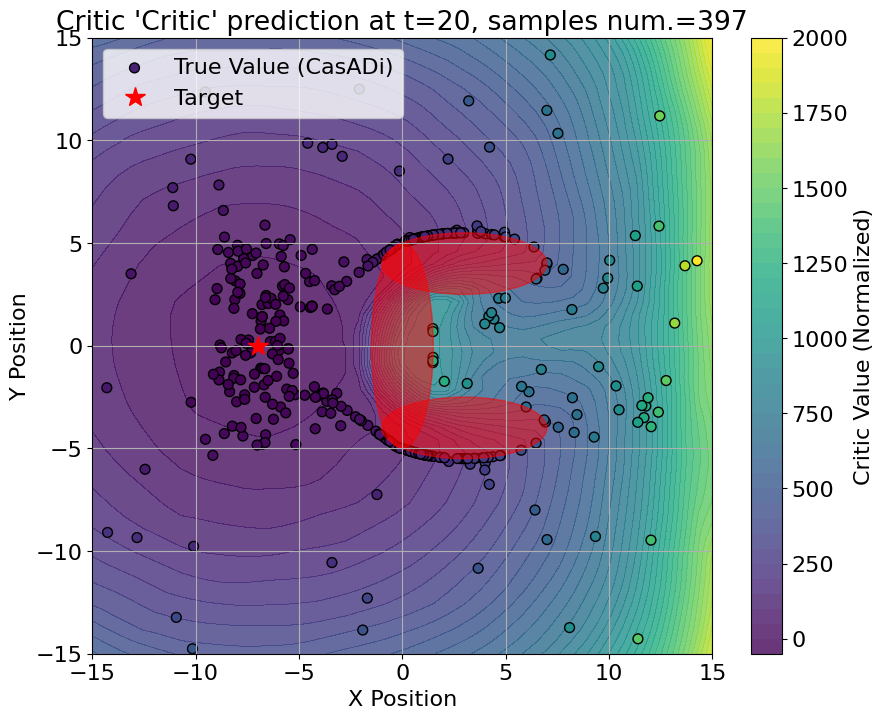

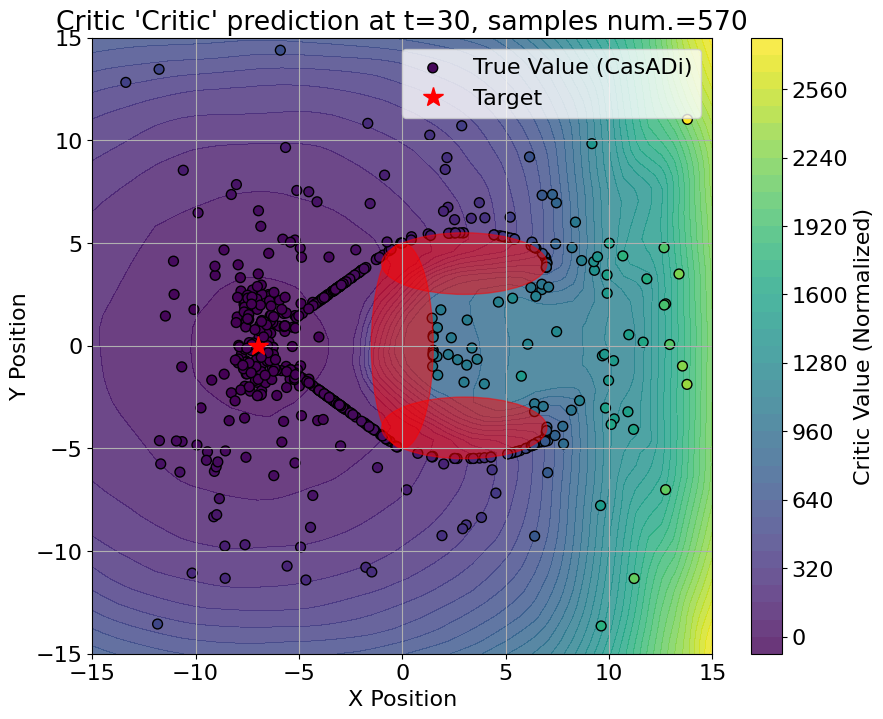

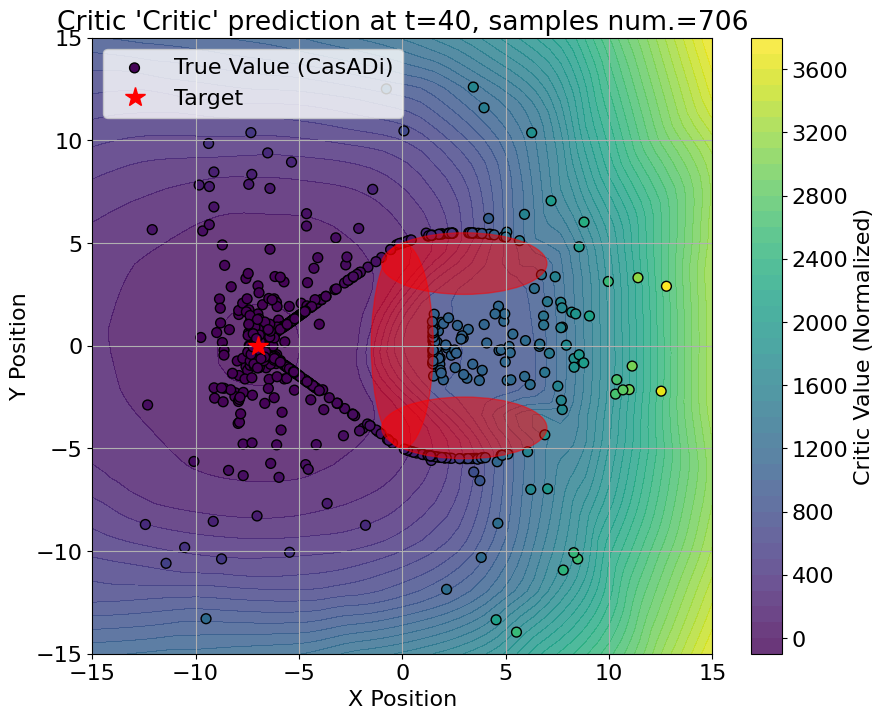

In [56]:
# Train the critic again with the new data in the buffer 
train_critic()

# Update the critic cycles counter
critic_cycles += cycles_counter(replay_buffer, minibatch_size, critic_epochs)
print(f"\nTotal critic cycles: {critic_cycles}")

for t in range(0, N, 10):
  plot_critic(critic, t, show=False)

--- CACTO Iteration 9 ---
--- Start training the constrained actor ---
--- Starting Constrained Actor training for 35 epochs ---
Epoch 1/35 | Mean Q+ALM: 239.1819 | Max Viol: 0.00103 | Lambda: [85.49 59.08 59.54] | Rho: 819.0 | LR: 0.000500 | step: 98
 | dQ/du norm: 1.494041
Epoch 5/35 | Mean Q+ALM: 239.2003 | Max Viol: 0.00084 | Lambda: [86.25 60.66 61.03] | Rho: 852.2 | LR: 0.000500 | step: 490
 | dQ/du norm: 1.492648
Epoch 10/35 | Mean Q+ALM: 239.0964 | Max Viol: 0.00112 | Lambda: [87.6  62.39 62.88] | Rho: 895.7 | LR: 0.000500 | step: 980
 | dQ/du norm: 1.479882
Epoch 15/35 | Mean Q+ALM: 239.0484 | Max Viol: 0.00088 | Lambda: [89.19 64.01 64.3 ] | Rho: 941.4 | LR: 0.000400 | step: 1470
 | dQ/du norm: 1.502167
Epoch 20/35 | Mean Q+ALM: 238.9842 | Max Viol: 0.00092 | Lambda: [90.5  65.46 65.69] | Rho: 989.4 | LR: 0.000320 | step: 1960
 | dQ/du norm: 1.458901
Epoch 25/35 | Mean Q+ALM: 239.1806 | Max Viol: 0.00268 | Lambda: [92.21 67.03 67.  ] | Rho: 1039.9 | LR: 0.000256 | step: 2450


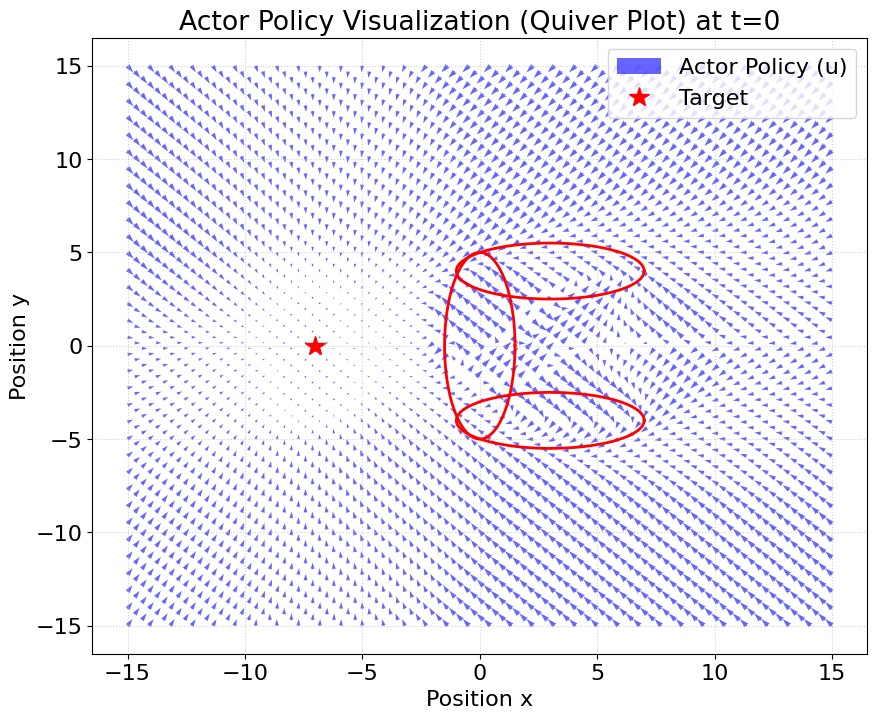

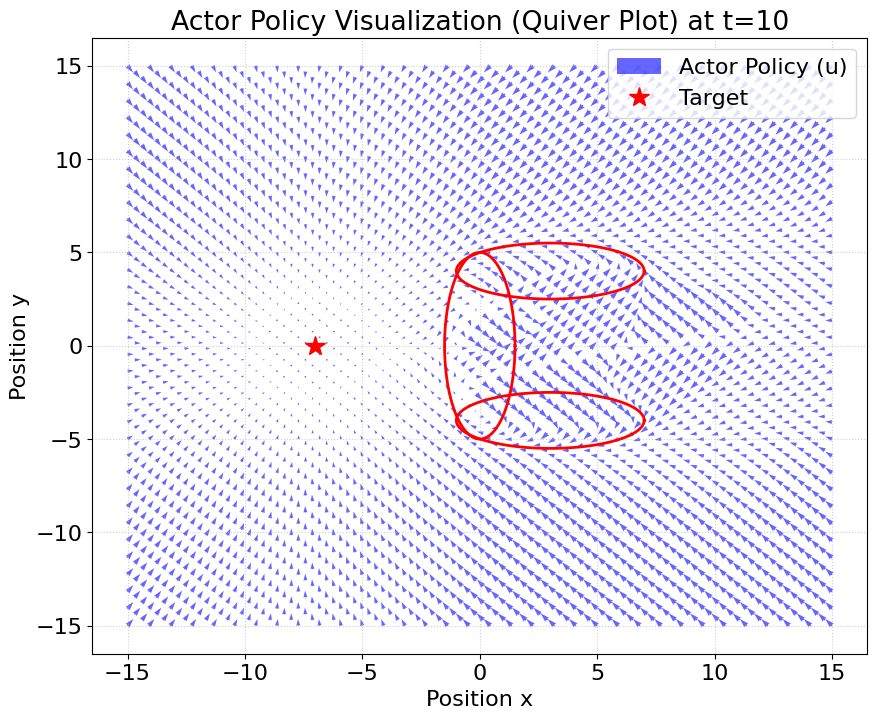

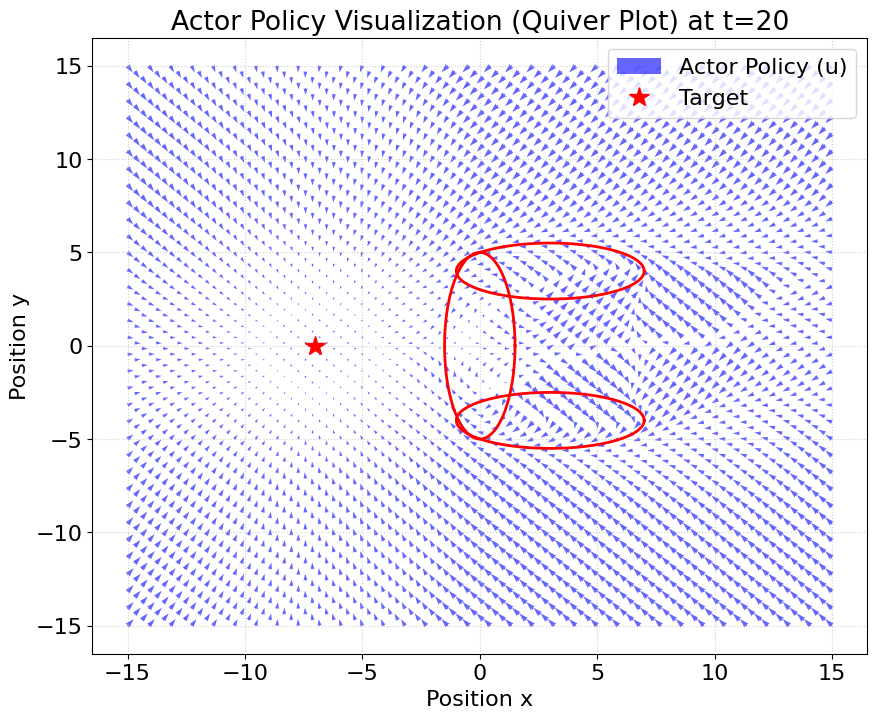

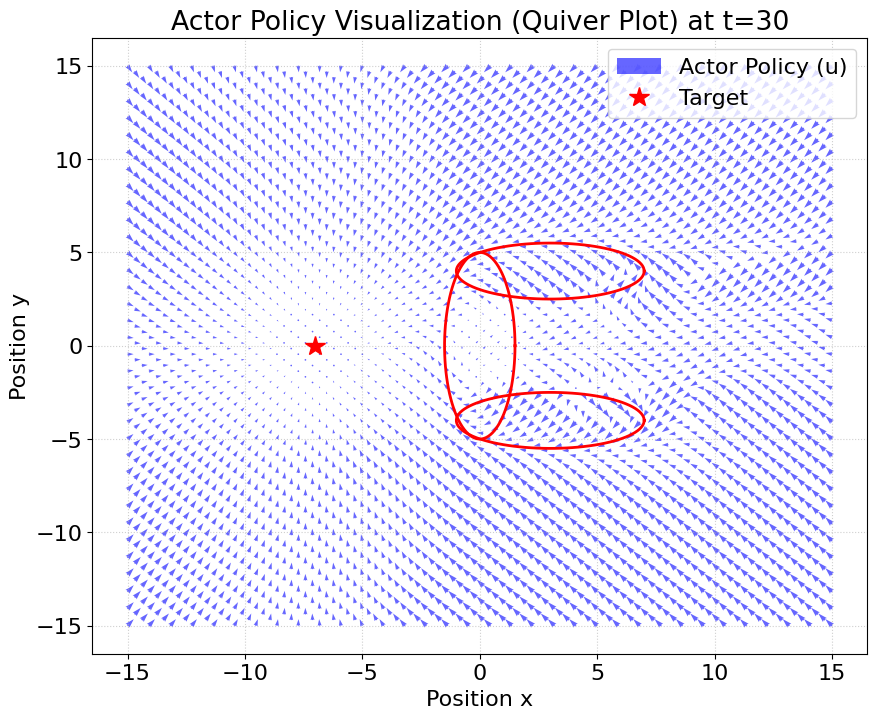

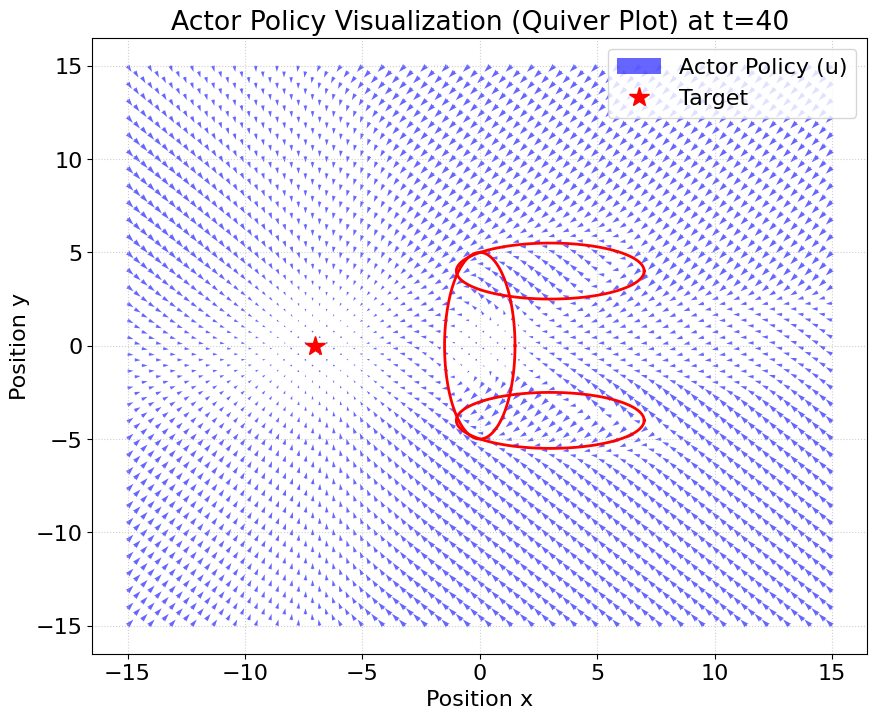

In [57]:
# Train the constrained actor again with the new critic

train_constr_actor()

# Update the constrained actor cycles counter
actor_cycles += cycles_counter(replay_buffer, minibatch_size, actor_epochs)
print(f"\nTotal constrained actor cycles: {actor_cycles}")

for t in range(0, N, 10):
  plot_constr_actor(t, show=True, plot_u_ocp=True)

Actor Only -> Feasible: 11/37 | Violating: 26/37
Actor Only -> Avg. max violation: 0.1933
Actor Only -> Avg. cost: 467.6944

Costs and Feasibility List:
Rollout 001 | Xini: (-10.0, -10.0) | Cost:   125.99 | Status: OK
Rollout 002 | Xini: (-8.0, -5.0) | Cost:    -7.67 | Status: OK
Rollout 003 | Xini: (-10.0,  0.0) | Cost:   -34.22 | Status: OK
Rollout 004 | Xini: (-8.0,  5.0) | Cost:    -7.67 | Status: OK
Rollout 005 | Xini: (-10.0, 10.0) | Cost:   126.60 | Status: OK
Rollout 006 | Xini: ( 5.0,  0.0) | Cost:   599.20 | Status: VIOL
Rollout 007 | Xini: ( 6.0,  1.5) | Cost:   508.14 | Status: VIOL
Rollout 008 | Xini: ( 6.0, -1.5) | Cost:   518.70 | Status: VIOL
Rollout 009 | Xini: ( 5.5,  2.5) | Cost:   446.29 | Status: VIOL
Rollout 010 | Xini: ( 5.5, -2.5) | Cost:   462.21 | Status: VIOL
Rollout 011 | Xini: ( 2.0,  0.0) | Cost:   584.03 | Status: VIOL
Rollout 012 | Xini: ( 1.5,  1.0) | Cost:   581.53 | Status: VIOL
Rollout 013 | Xini: ( 1.5, -2.0) | Cost:   327.44 | Status: VIOL
Rollout 

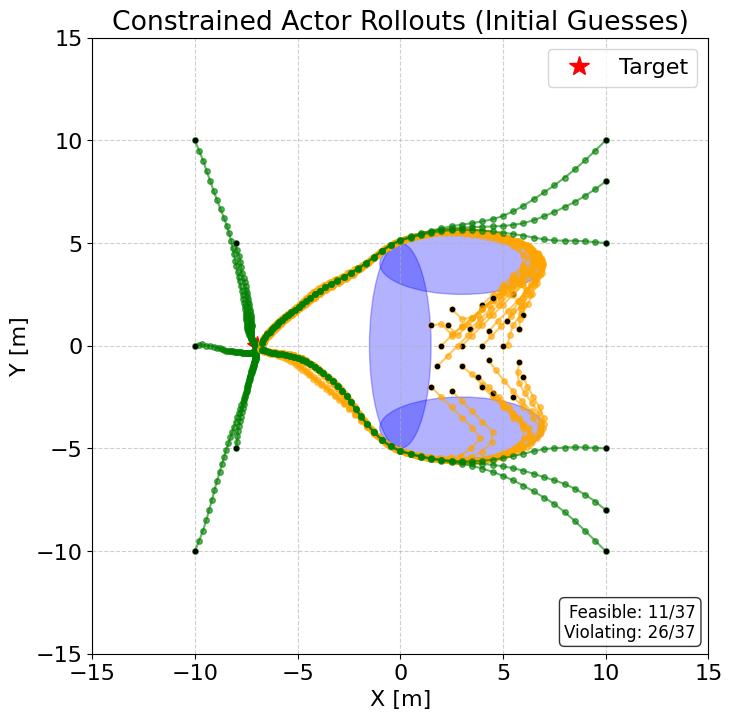

Computing initial guesses in batch...
Skip i=12: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=24: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
TO + Warm Start -> Time: 15.605 s
TO + Warm Start -> Feasible: 35/37 | Failed: 2/37


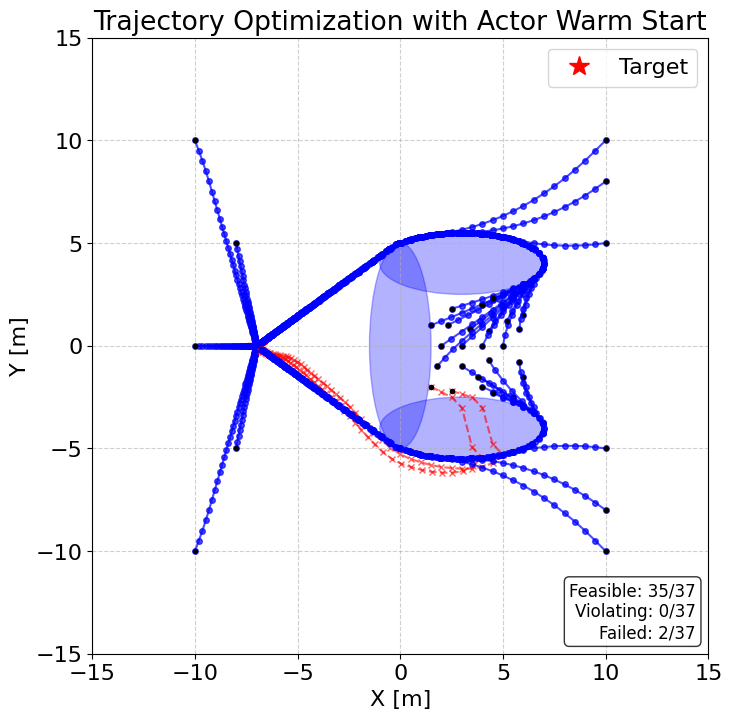

In [58]:
# Final evaluation of the constrained actor rollouts and TO performance after the last iteration
plot_cons_actor_rollouts(print_costs=True)
V_TO, all_cons_x_trajs = evaluate_TO_w_cons_warm_start()

--- CACTO Iteration 10 ---
Start solving 300 TO problems


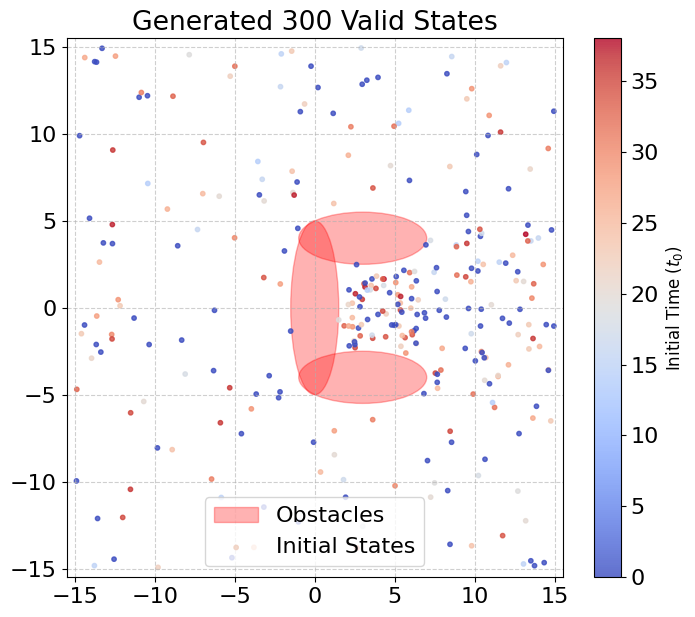

Computing warm start guesses via Actor...


COmputing OCPs: 100%|██████████| 300/300 [01:18<00:00,  3.80traj/s]


--- Finished ---
Successfully solved: 300 / 300
States Buffer size: (25000, 3) samples
Time taken: 81.430 s


In [59]:
# Solve an OCP for every sampled initial state-time using the constrained actor for warm start
solve_TO_problems(use_actor_to_warm_start=True, actor=cons_actor)

--- CACTO Iteration 10 ---
--- Start training critic ---
Replay buffer size: 25000 samples
Epoch 1/35 | MSE: 104.6000 | RMSE: 10.2274 | LR: 0.005000 | step: 98
Epoch 5/35 | MSE: 56.4370 | RMSE: 7.5125 | LR: 0.005000 | step: 490
Epoch 10/35 | MSE: 94.0161 | RMSE: 9.6962 | LR: 0.005000 | step: 980
Epoch 15/35 | MSE: 89.3575 | RMSE: 9.4529 | LR: 0.003750 | step: 1470
Epoch 20/35 | MSE: 17.6113 | RMSE: 4.1966 | LR: 0.002812 | step: 1960
Epoch 25/35 | MSE: 15.0248 | RMSE: 3.8762 | LR: 0.002109 | step: 2450
Epoch 30/35 | MSE: 8.0030 | RMSE: 2.8290 | LR: 0.001582 | step: 2940
Epoch 35/35 | MSE: 9.1091 | RMSE: 3.0181 | LR: 0.001187 | step: 3430
Final Critic MSE: 9.11
Final Critic RMSE: 3.02
--- Critic training has finished ---

Total critic cycles: 31850


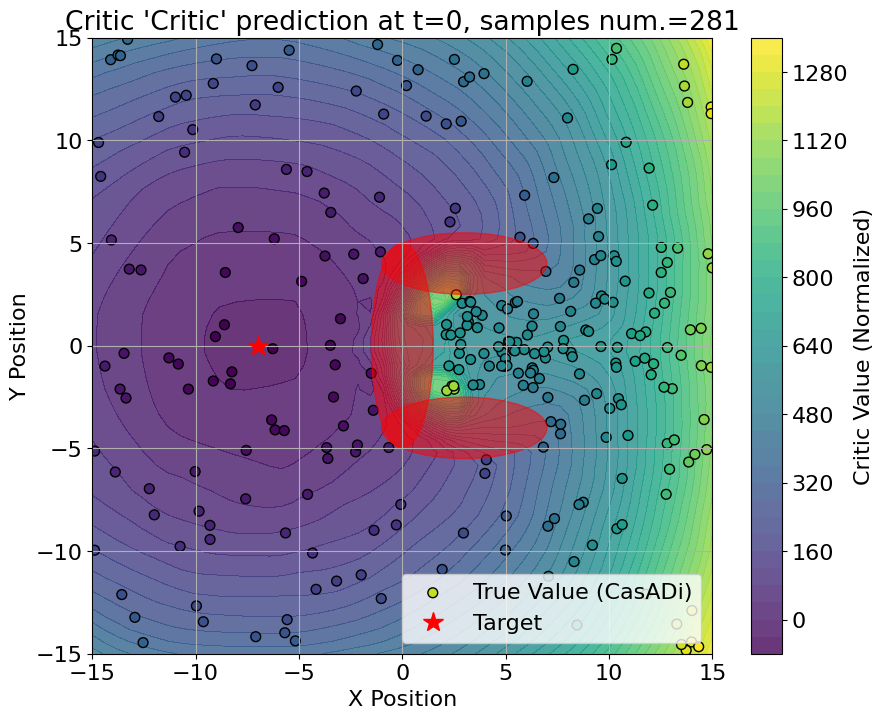

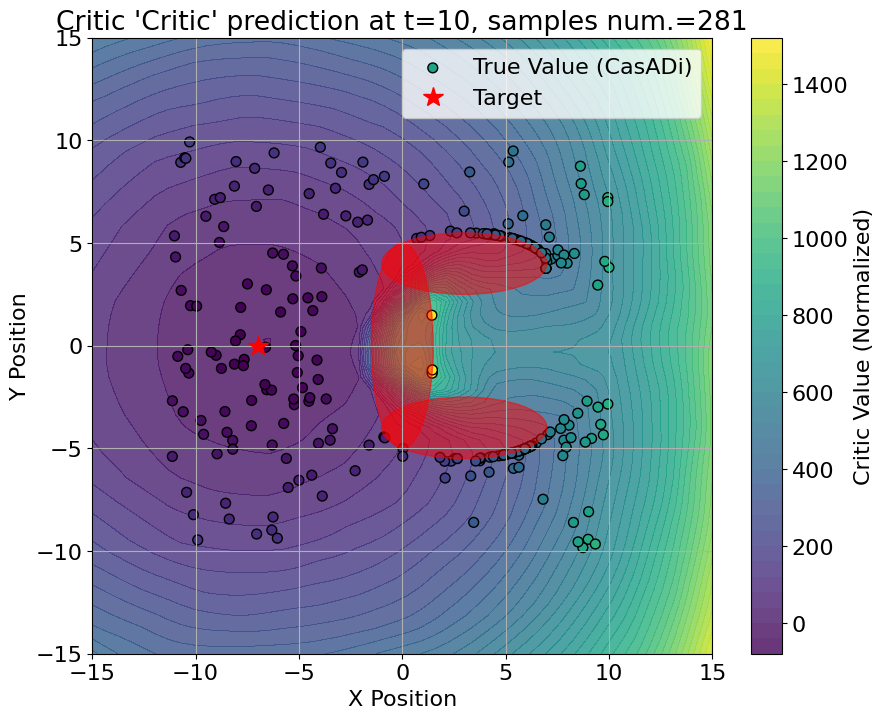

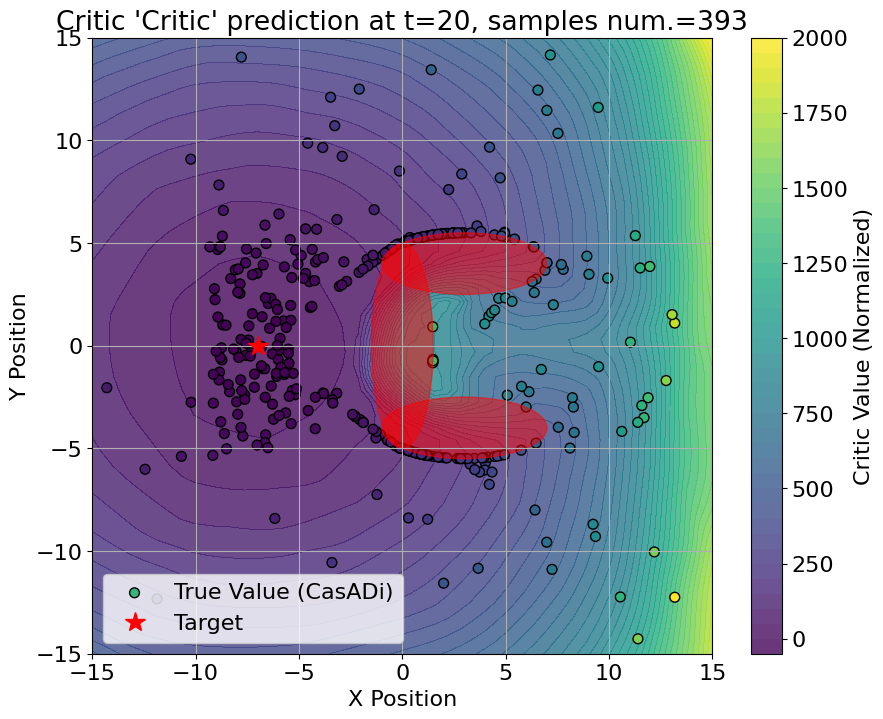

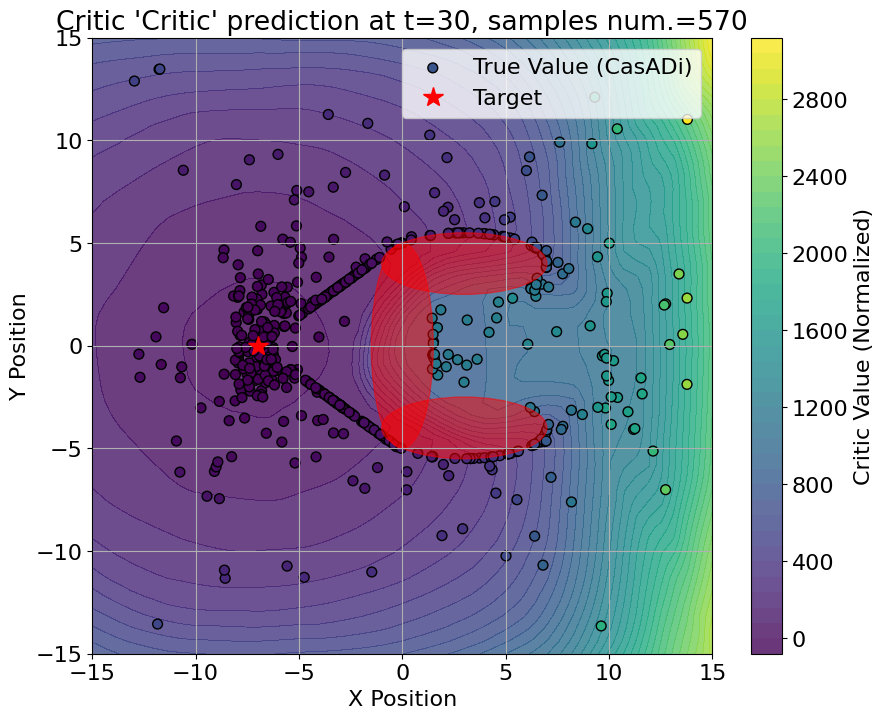

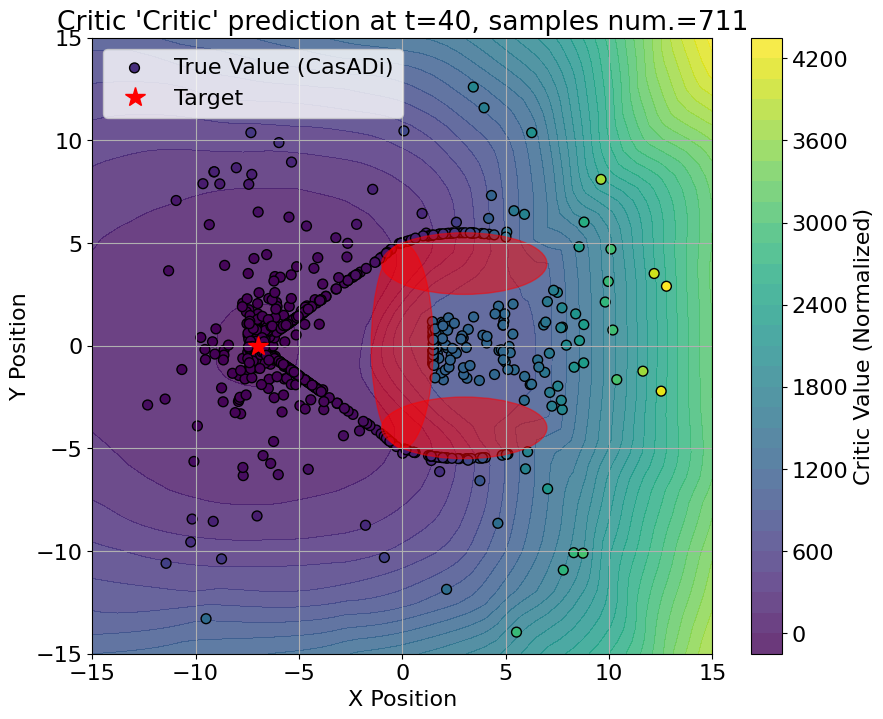

In [60]:
# Train the critic again with the new data in the buffer 
train_critic()

# Update the critic cycles counter
critic_cycles += cycles_counter(replay_buffer, minibatch_size, critic_epochs)
print(f"\nTotal critic cycles: {critic_cycles}")

for t in range(0, N, 10):
  plot_critic(critic, t, show=False)

--- CACTO Iteration 10 ---
--- Start training the constrained actor ---
--- Starting Constrained Actor training for 35 epochs ---
Epoch 1/35 | Mean Q+ALM: 245.6524 | Max Viol: 0.00060 | Lambda: [93.91 69.88 69.68] | Rho: 1160.2 | LR: 0.000500 | step: 98
 | dQ/du norm: 1.427737
Epoch 5/35 | Mean Q+ALM: 245.8088 | Max Viol: 0.00226 | Lambda: [95.81 72.09 72.48] | Rho: 1207.3 | LR: 0.000500 | step: 490
 | dQ/du norm: 1.418700
Epoch 10/35 | Mean Q+ALM: 245.4279 | Max Viol: 0.00093 | Lambda: [96.53 73.87 73.91] | Rho: 1268.9 | LR: 0.000500 | step: 980
 | dQ/du norm: 1.431594
Epoch 15/35 | Mean Q+ALM: 245.4115 | Max Viol: 0.00056 | Lambda: [97.08 75.45 74.85] | Rho: 1333.6 | LR: 0.000400 | step: 1470
 | dQ/du norm: 1.413587
Epoch 20/35 | Mean Q+ALM: 245.3342 | Max Viol: 0.00051 | Lambda: [98.4  76.92 76.01] | Rho: 1401.6 | LR: 0.000320 | step: 1960
 | dQ/du norm: 1.414877
Epoch 25/35 | Mean Q+ALM: 245.3201 | Max Viol: 0.00069 | Lambda: [98.86 78.41 77.59] | Rho: 1473.1 | LR: 0.000256 | step:

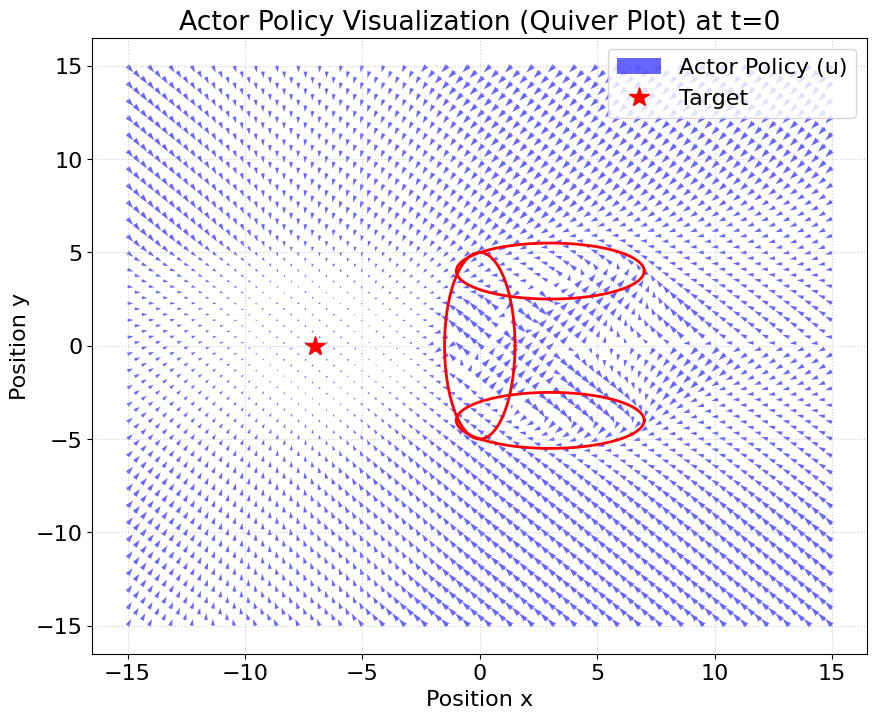

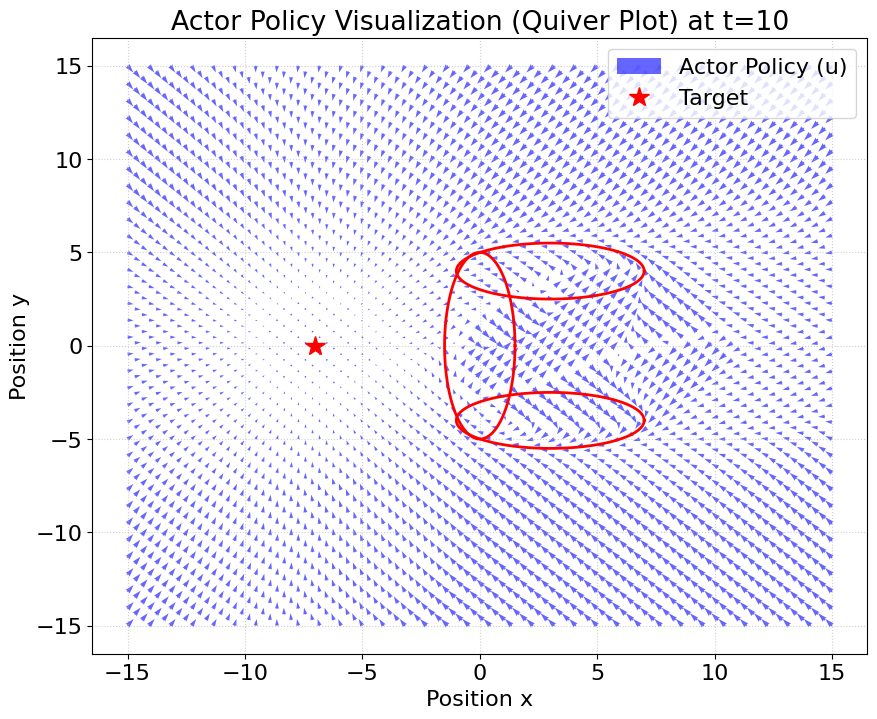

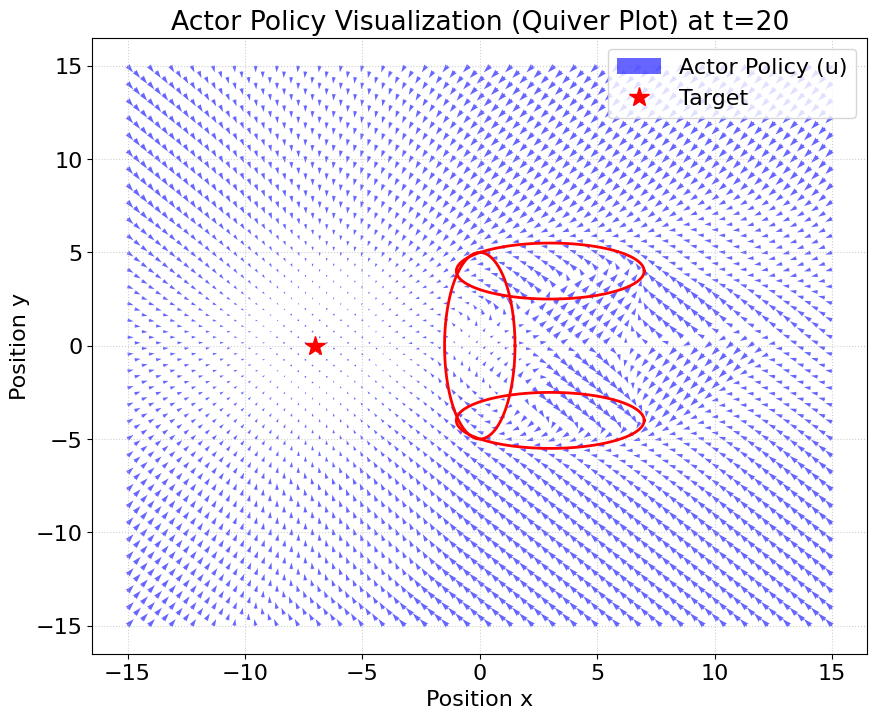

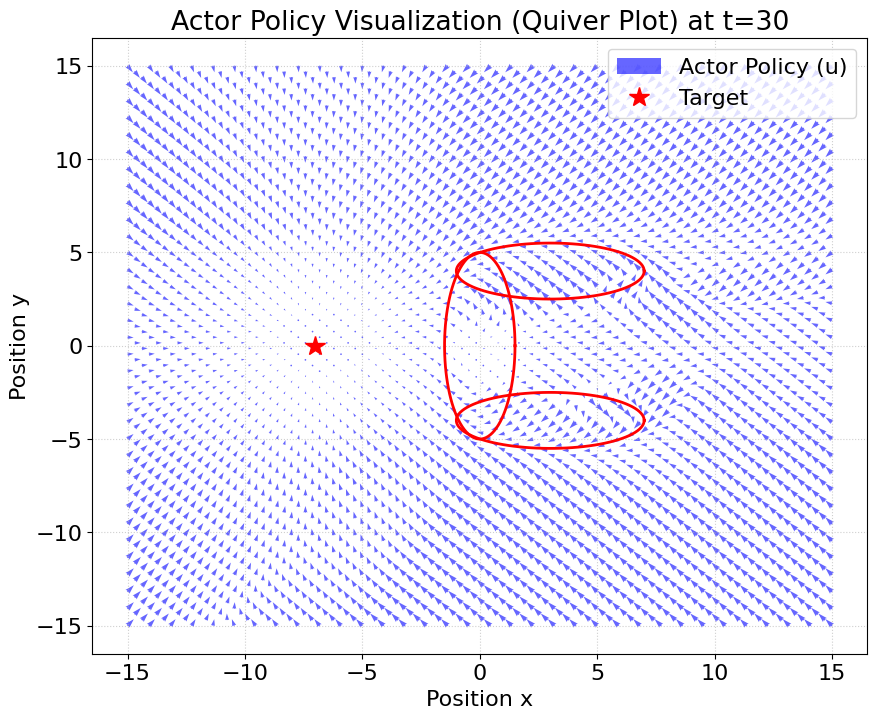

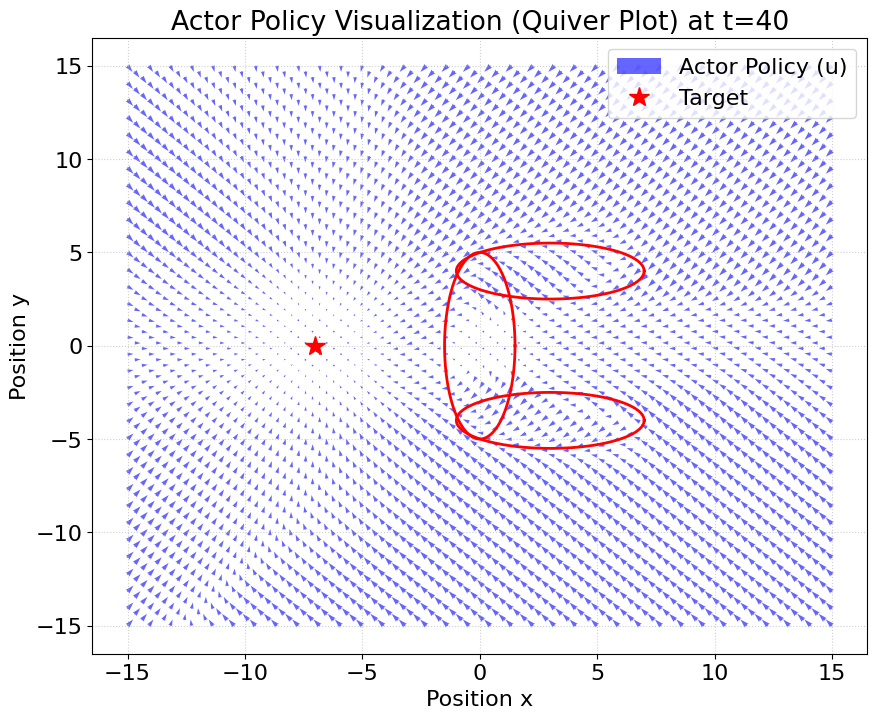

In [61]:
# Train the constrained actor again with the new critic

train_constr_actor()

# Update the constrained actor cycles counter
actor_cycles += cycles_counter(replay_buffer, minibatch_size, actor_epochs)
print(f"\nTotal constrained actor cycles: {actor_cycles}")

for t in range(0, N, 10):
  plot_constr_actor(t, show=True, plot_u_ocp=True)

Actor Only -> Feasible: 11/37 | Violating: 26/37
Actor Only -> Avg. max violation: 0.1031
Actor Only -> Avg. cost: 495.5272

Costs and Feasibility List:
Rollout 001 | Xini: (-10.0, -10.0) | Cost:   126.78 | Status: OK
Rollout 002 | Xini: (-8.0, -5.0) | Cost:    -7.89 | Status: OK
Rollout 003 | Xini: (-10.0,  0.0) | Cost:   -34.89 | Status: OK
Rollout 004 | Xini: (-8.0,  5.0) | Cost:    -7.22 | Status: OK
Rollout 005 | Xini: (-10.0, 10.0) | Cost:   126.28 | Status: OK
Rollout 006 | Xini: ( 5.0,  0.0) | Cost:   589.69 | Status: VIOL
Rollout 007 | Xini: ( 6.0,  1.5) | Cost:   516.22 | Status: VIOL
Rollout 008 | Xini: ( 6.0, -1.5) | Cost:   513.05 | Status: VIOL
Rollout 009 | Xini: ( 5.5,  2.5) | Cost:   470.02 | Status: VIOL
Rollout 010 | Xini: ( 5.5, -2.5) | Cost:   460.11 | Status: VIOL
Rollout 011 | Xini: ( 2.0,  0.0) | Cost:   608.91 | Status: VIOL
Rollout 012 | Xini: ( 1.5,  1.0) | Cost:   609.26 | Status: VIOL
Rollout 013 | Xini: ( 1.5, -2.0) | Cost:   684.05 | Status: VIOL
Rollout 

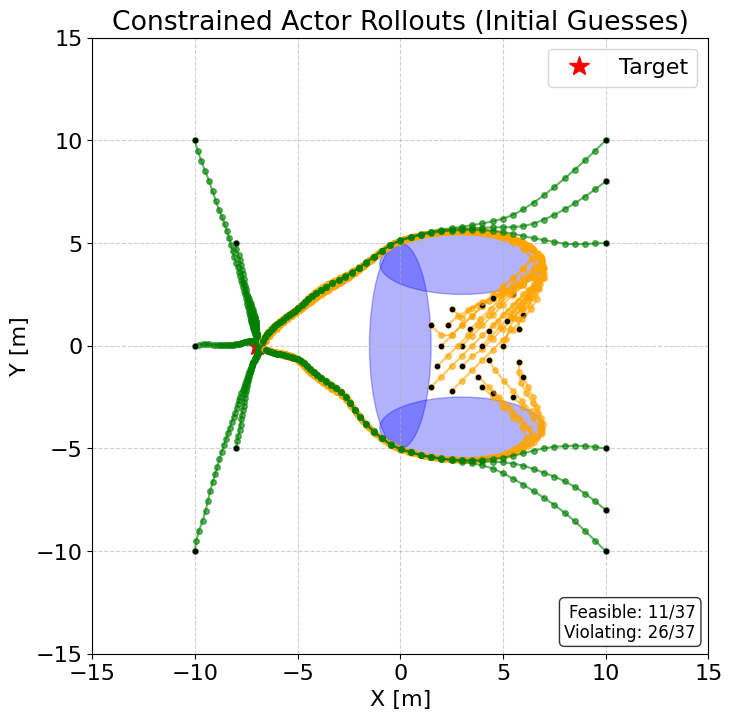

Computing initial guesses in batch...
TO + Warm Start -> Time: 13.926 s
TO + Warm Start -> Feasible: 37/37 | Failed: 0/37


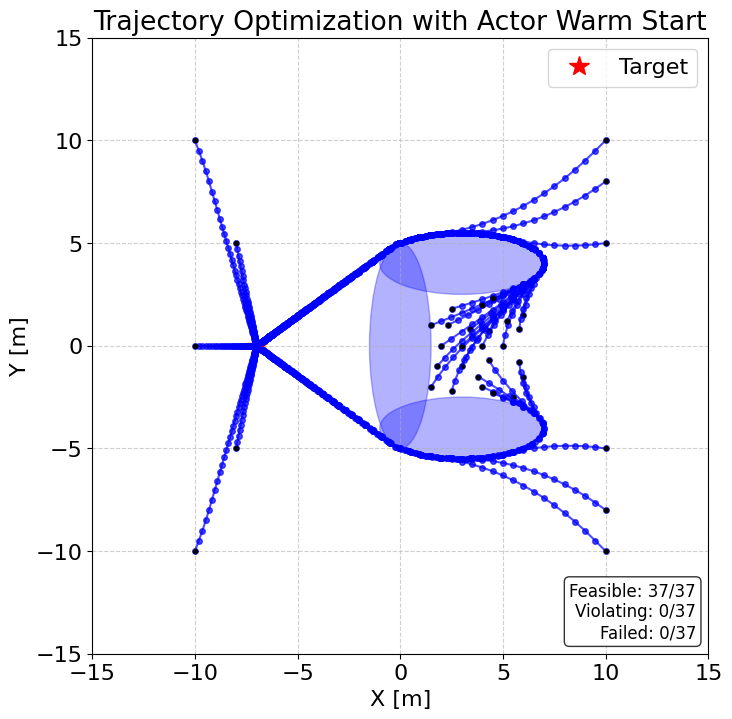

In [62]:
# Final evaluation of the constrained actor rollouts and TO performance after the last iteration
plot_cons_actor_rollouts(print_costs=True)
V_TO, all_cons_x_trajs = evaluate_TO_w_cons_warm_start()

--- CACTO Iteration 11 ---
Start solving 300 TO problems


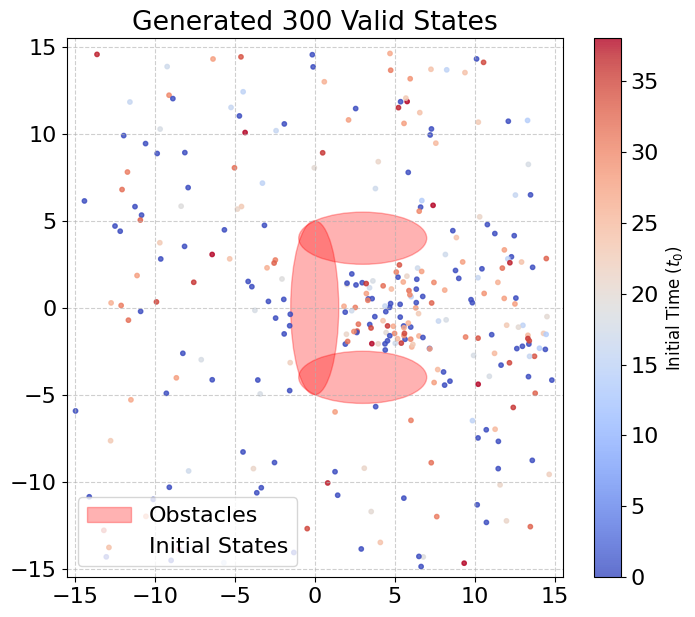

Computing warm start guesses via Actor...


COmputing OCPs: 100%|██████████| 300/300 [01:16<00:00,  3.91traj/s]


--- Finished ---
Successfully solved: 300 / 300
States Buffer size: (25000, 3) samples
Time taken: 79.166 s


In [63]:
# Solve an OCP for every sampled initial state-time using the constrained actor for warm start
solve_TO_problems(use_actor_to_warm_start=True, actor=cons_actor)

--- CACTO Iteration 11 ---
--- Start training critic ---
Replay buffer size: 25000 samples
Epoch 1/35 | MSE: 45.7184 | RMSE: 6.7615 | LR: 0.005000 | step: 98
Epoch 5/35 | MSE: 47.1656 | RMSE: 6.8677 | LR: 0.005000 | step: 490
Epoch 10/35 | MSE: 30.5092 | RMSE: 5.5235 | LR: 0.005000 | step: 980
Epoch 15/35 | MSE: 45.5142 | RMSE: 6.7464 | LR: 0.003750 | step: 1470
Epoch 20/35 | MSE: 27.2377 | RMSE: 5.2190 | LR: 0.002812 | step: 1960
Epoch 25/35 | MSE: 16.9151 | RMSE: 4.1128 | LR: 0.002109 | step: 2450
Epoch 30/35 | MSE: 8.3631 | RMSE: 2.8919 | LR: 0.001582 | step: 2940
Epoch 35/35 | MSE: 9.7462 | RMSE: 3.1219 | LR: 0.001187 | step: 3430
Final Critic MSE: 9.75
Final Critic RMSE: 3.12
--- Critic training has finished ---

Total critic cycles: 35280


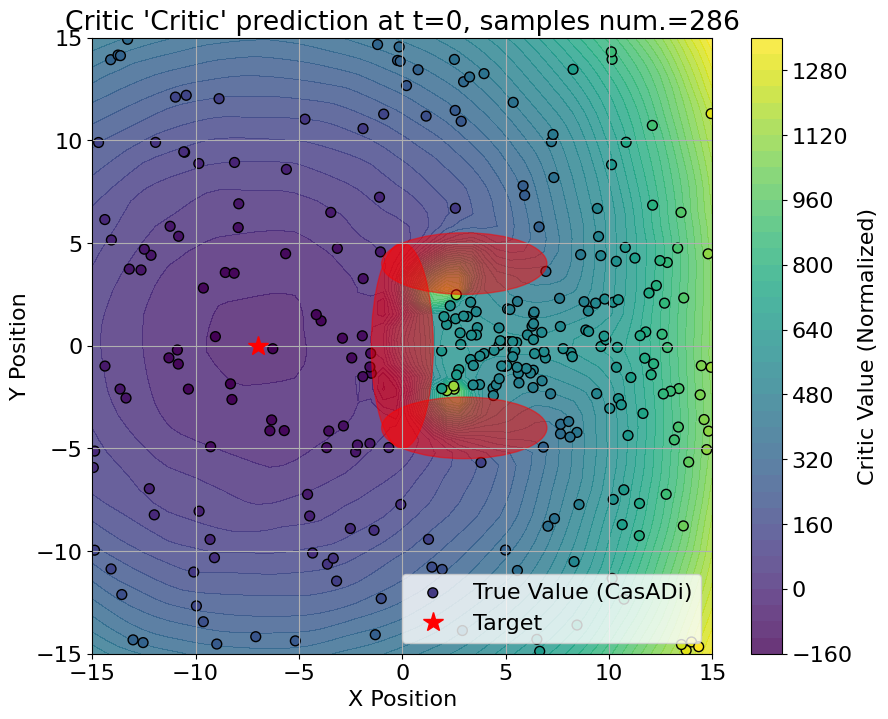

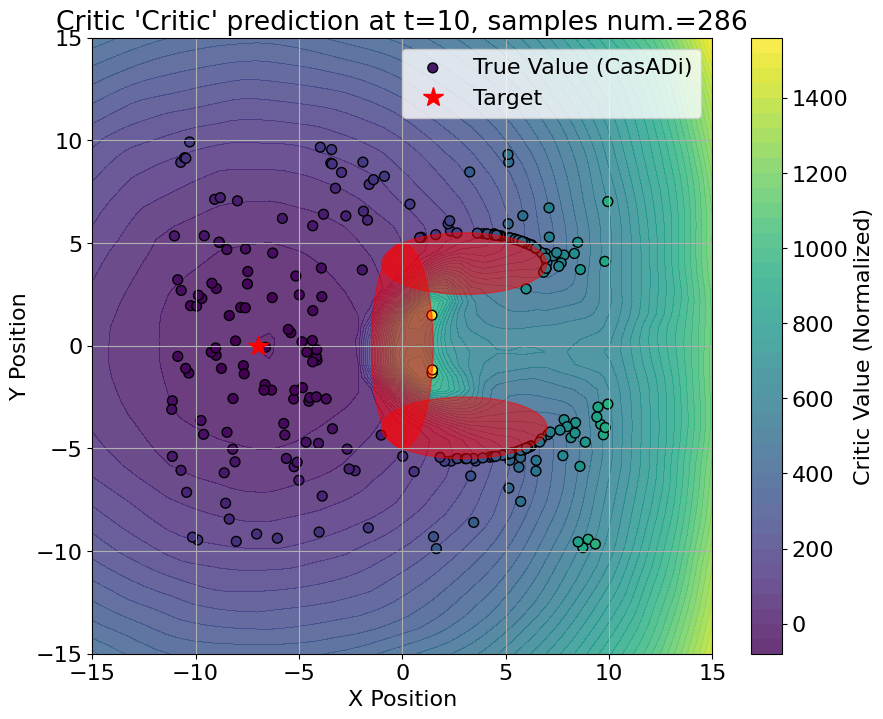

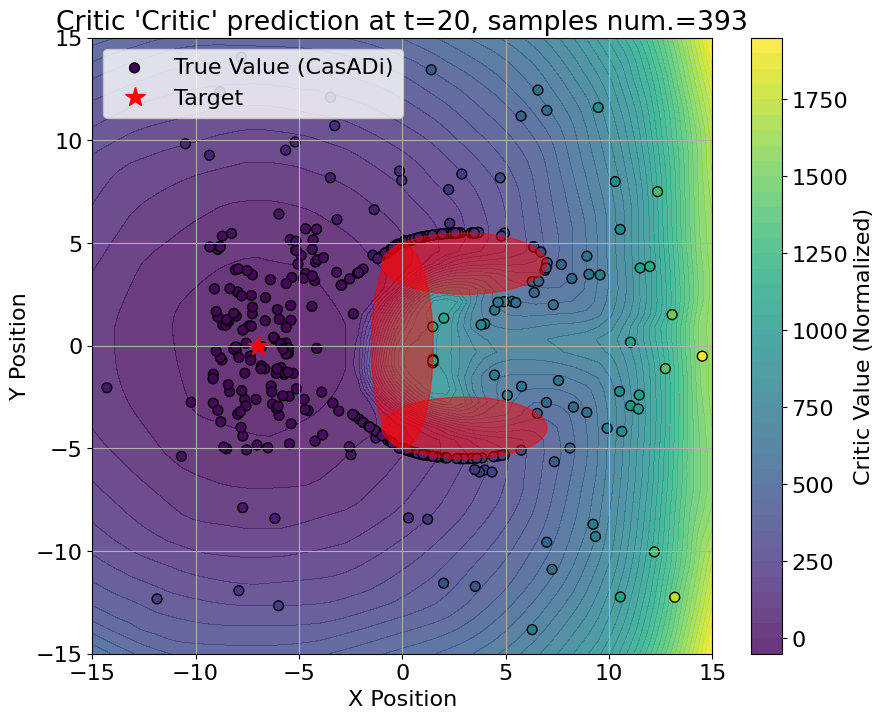

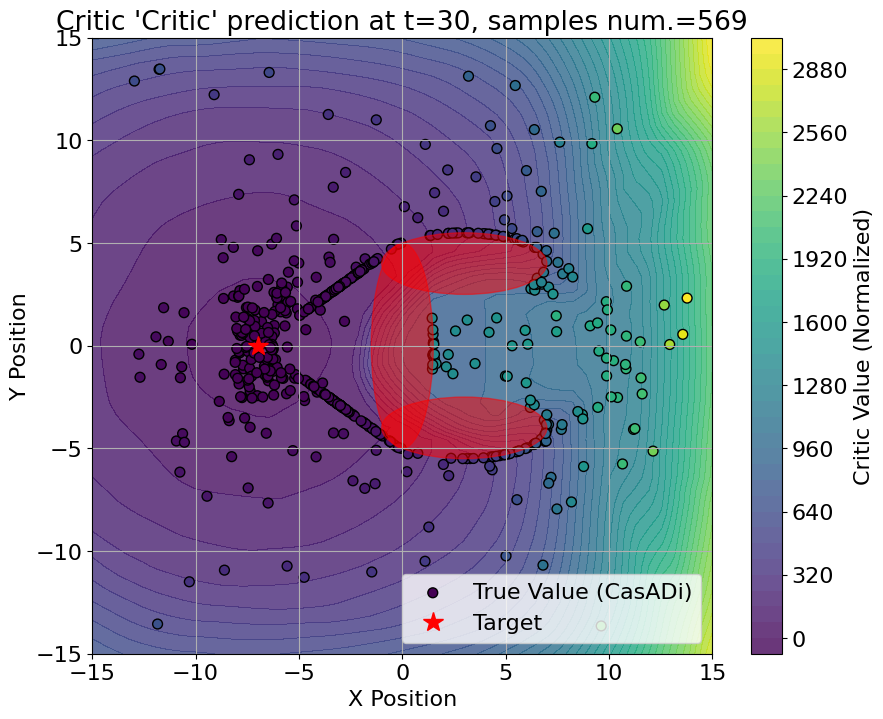

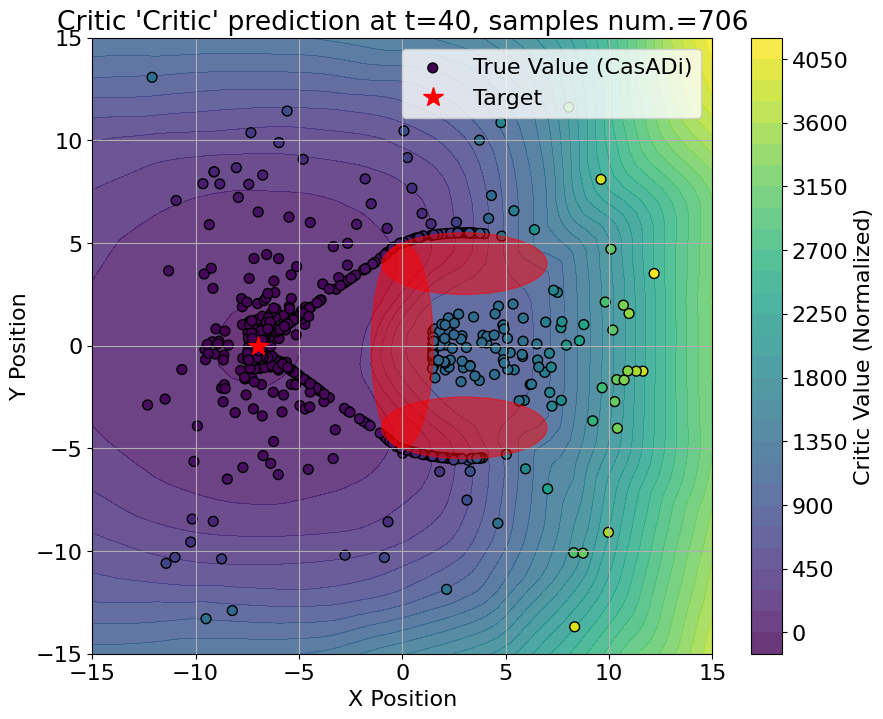

In [64]:
# Train the critic again with the new data in the buffer 
train_critic()

# Update the critic cycles counter
critic_cycles += cycles_counter(replay_buffer, minibatch_size, critic_epochs)
print(f"\nTotal critic cycles: {critic_cycles}")

for t in range(0, N, 10):
  plot_critic(critic, t, show=False)

--- CACTO Iteration 11 ---
--- Start training the constrained actor ---
--- Starting Constrained Actor training for 35 epochs ---
Epoch 1/35 | Mean Q+ALM: 247.2474 | Max Viol: 0.00074 | Lambda: [101.04  81.98  80.05] | Rho: 1643.5 | LR: 0.000500 | step: 98
 | dQ/du norm: 1.445287
Epoch 5/35 | Mean Q+ALM: 247.3946 | Max Viol: 0.00172 | Lambda: [102.67  84.1   81.73] | Rho: 1710.2 | LR: 0.000500 | step: 490
 | dQ/du norm: 1.445299
Epoch 10/35 | Mean Q+ALM: 247.3188 | Max Viol: 0.00058 | Lambda: [103.41  86.07  83.19] | Rho: 1797.5 | LR: 0.000500 | step: 980
 | dQ/du norm: 1.454739
Epoch 15/35 | Mean Q+ALM: 247.3176 | Max Viol: 0.00075 | Lambda: [104.61  88.03  85.03] | Rho: 1889.2 | LR: 0.000400 | step: 1470
 | dQ/du norm: 1.449768
Epoch 20/35 | Mean Q+ALM: 247.3201 | Max Viol: 0.00080 | Lambda: [105.9   90.14  86.61] | Rho: 1985.5 | LR: 0.000320 | step: 1960
 | dQ/du norm: 1.453753
Epoch 25/35 | Mean Q+ALM: 247.2333 | Max Viol: 0.00106 | Lambda: [107.56  92.58  88.21] | Rho: 2086.8 | LR

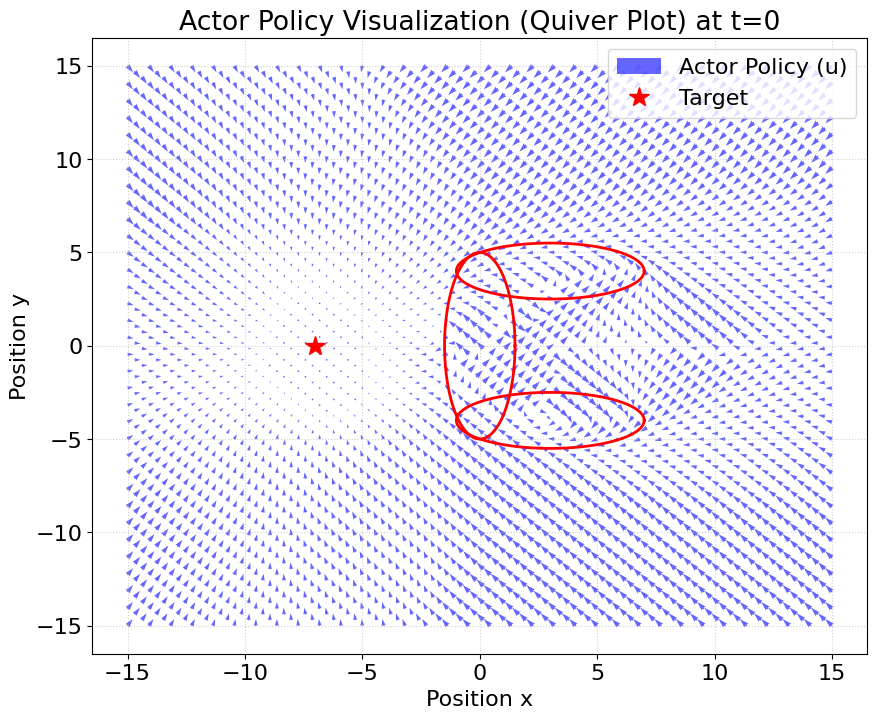

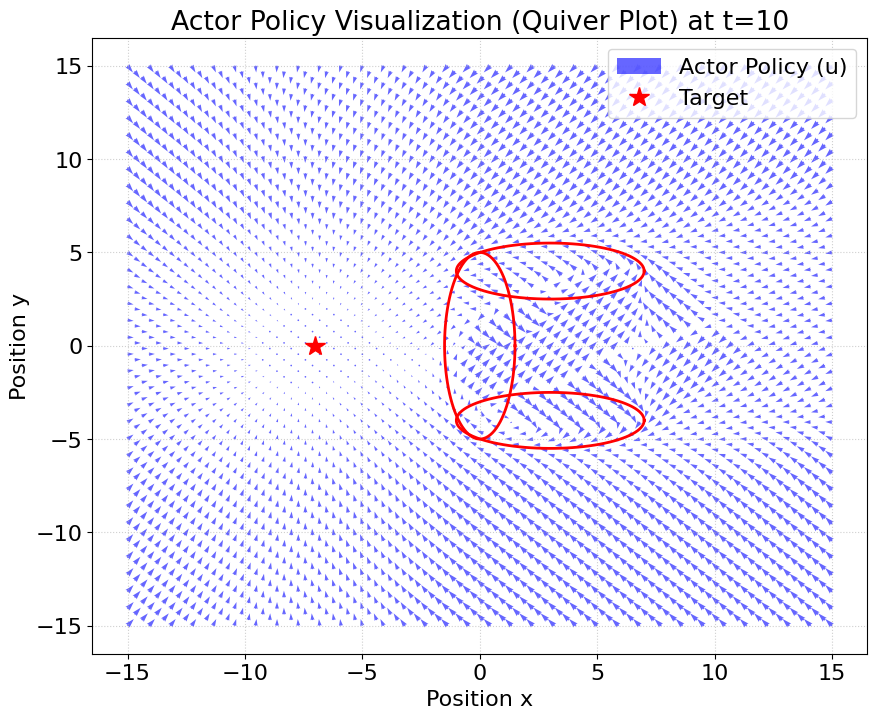

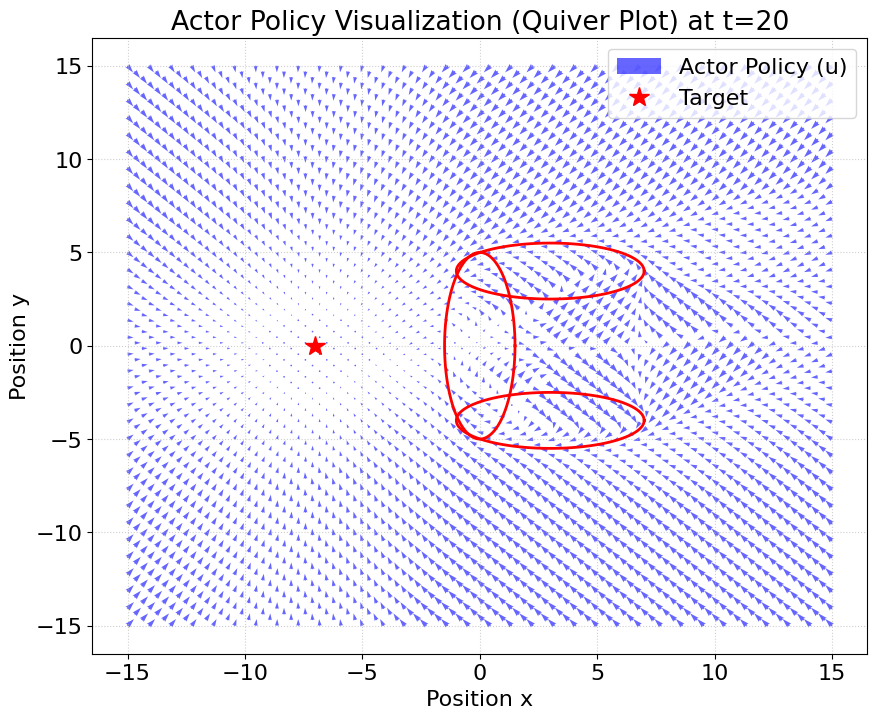

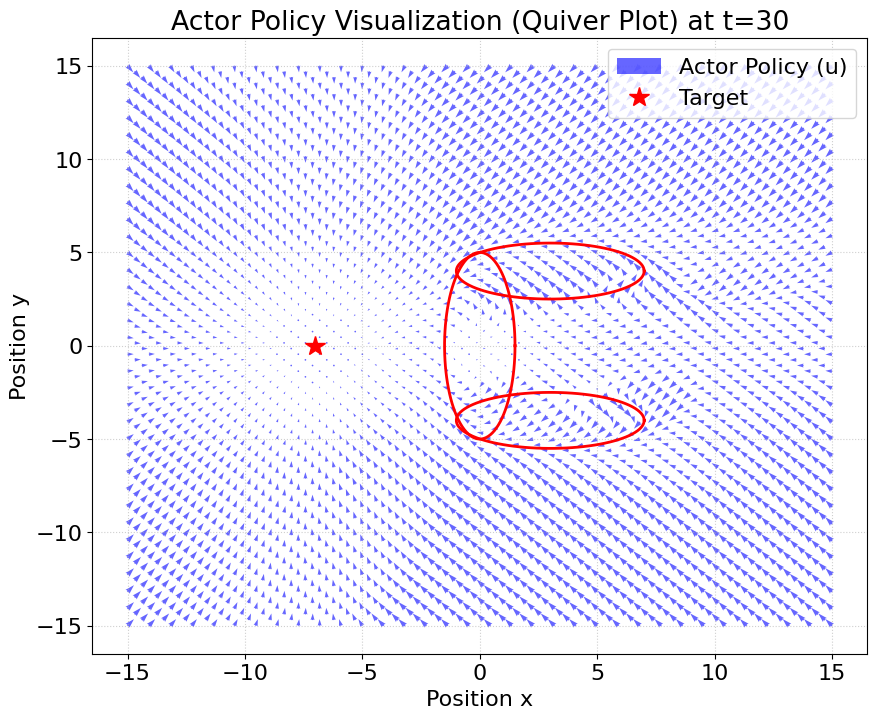

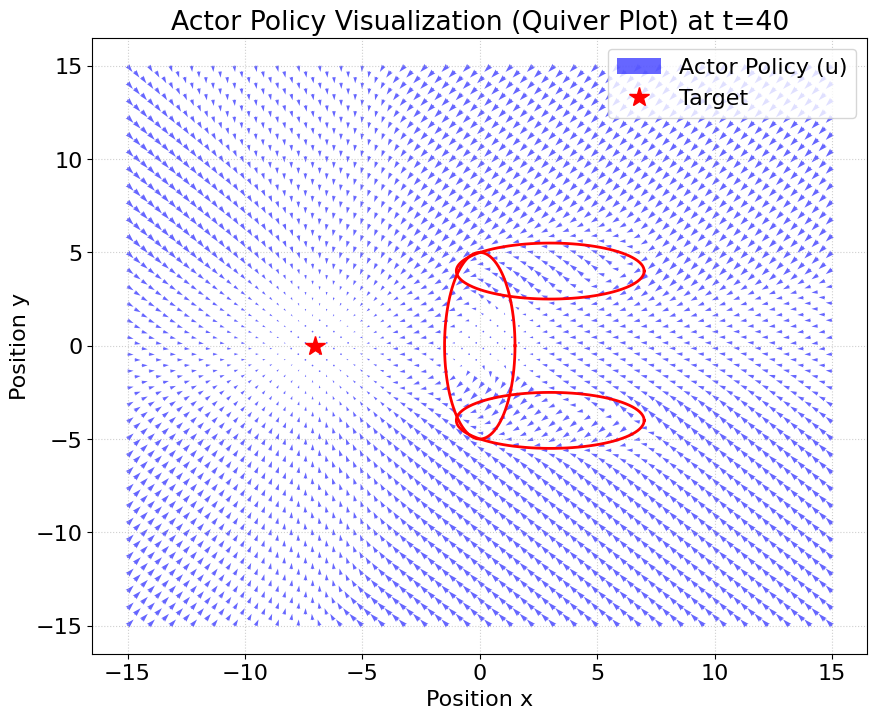

In [65]:
# Train the constrained actor again with the new critic

train_constr_actor()

# Update the constrained actor cycles counter
actor_cycles += cycles_counter(replay_buffer, minibatch_size, actor_epochs)
print(f"\nTotal constrained actor cycles: {actor_cycles}")

for t in range(0, N, 10):
  plot_constr_actor(t, show=True, plot_u_ocp=True)

Actor Only -> Feasible: 12/37 | Violating: 25/37
Actor Only -> Avg. max violation: 0.0893
Actor Only -> Avg. cost: 494.7581

Costs and Feasibility List:
Rollout 001 | Xini: (-10.0, -10.0) | Cost:   126.03 | Status: OK
Rollout 002 | Xini: (-8.0, -5.0) | Cost:    -7.75 | Status: OK
Rollout 003 | Xini: (-10.0,  0.0) | Cost:   -34.94 | Status: OK
Rollout 004 | Xini: (-8.0,  5.0) | Cost:    -7.90 | Status: OK
Rollout 005 | Xini: (-10.0, 10.0) | Cost:   126.19 | Status: OK
Rollout 006 | Xini: ( 5.0,  0.0) | Cost:   589.52 | Status: VIOL
Rollout 007 | Xini: ( 6.0,  1.5) | Cost:   514.45 | Status: VIOL
Rollout 008 | Xini: ( 6.0, -1.5) | Cost:   519.47 | Status: OK
Rollout 009 | Xini: ( 5.5,  2.5) | Cost:   462.46 | Status: VIOL
Rollout 010 | Xini: ( 5.5, -2.5) | Cost:   464.95 | Status: VIOL
Rollout 011 | Xini: ( 2.0,  0.0) | Cost:   620.53 | Status: VIOL
Rollout 012 | Xini: ( 1.5,  1.0) | Cost:   613.18 | Status: VIOL
Rollout 013 | Xini: ( 1.5, -2.0) | Cost:   684.51 | Status: VIOL
Rollout 01

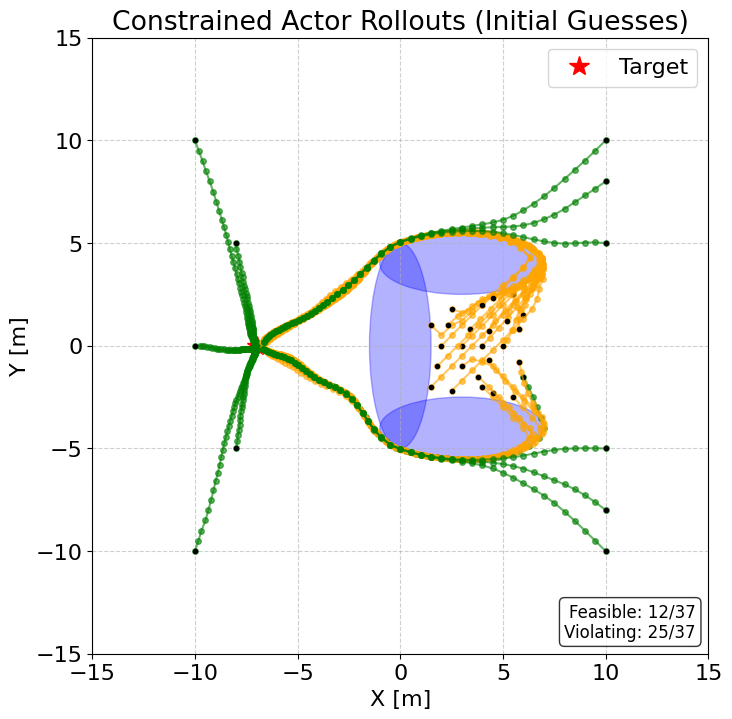

Computing initial guesses in batch...
TO + Warm Start -> Time: 13.166 s
TO + Warm Start -> Feasible: 37/37 | Failed: 0/37


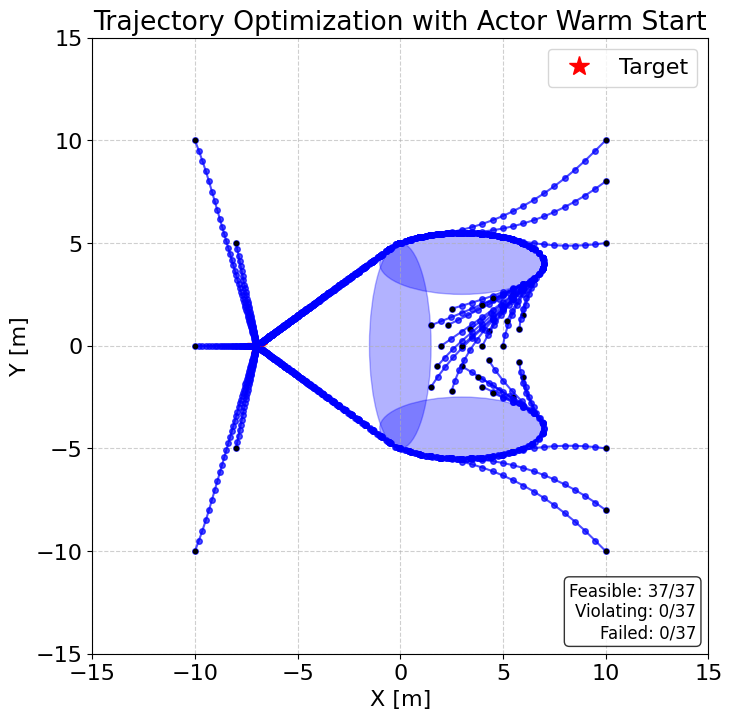

In [66]:
# Final evaluation of the constrained actor rollouts and TO performance after the last iteration
plot_cons_actor_rollouts(print_costs=True)
V_TO, all_cons_x_trajs = evaluate_TO_w_cons_warm_start()

--- CACTO Iteration 12 ---
Start solving 300 TO problems


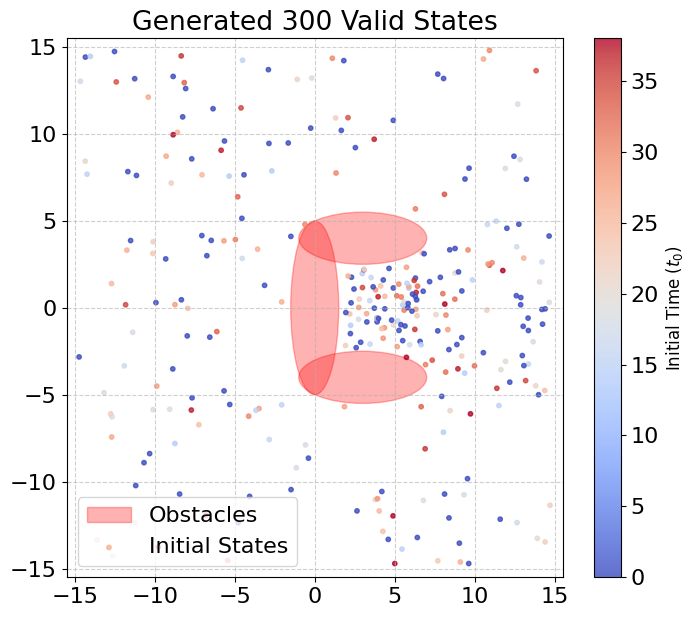

Computing warm start guesses via Actor...


COmputing OCPs: 100%|██████████| 300/300 [01:14<00:00,  4.05traj/s]


--- Finished ---
Successfully solved: 300 / 300
States Buffer size: (25000, 3) samples
Time taken: 76.542 s


In [67]:
# Solve an OCP for every sampled initial state-time using the constrained actor for warm start
solve_TO_problems(use_actor_to_warm_start=True, actor=cons_actor)

--- CACTO Iteration 12 ---
--- Start training critic ---
Replay buffer size: 25000 samples
Epoch 1/35 | MSE: 59.5338 | RMSE: 7.7158 | LR: 0.005000 | step: 98
Epoch 5/35 | MSE: 95.8313 | RMSE: 9.7893 | LR: 0.005000 | step: 490
Epoch 10/35 | MSE: 25.3389 | RMSE: 5.0338 | LR: 0.005000 | step: 980
Epoch 15/35 | MSE: 28.3260 | RMSE: 5.3222 | LR: 0.003750 | step: 1470
Epoch 20/35 | MSE: 17.7876 | RMSE: 4.2175 | LR: 0.002812 | step: 1960
Epoch 25/35 | MSE: 14.6581 | RMSE: 3.8286 | LR: 0.002109 | step: 2450
Epoch 30/35 | MSE: 8.6098 | RMSE: 2.9342 | LR: 0.001582 | step: 2940
Epoch 35/35 | MSE: 3.4437 | RMSE: 1.8557 | LR: 0.001187 | step: 3430
Final Critic MSE: 3.44
Final Critic RMSE: 1.86
--- Critic training has finished ---

Total critic cycles: 38710


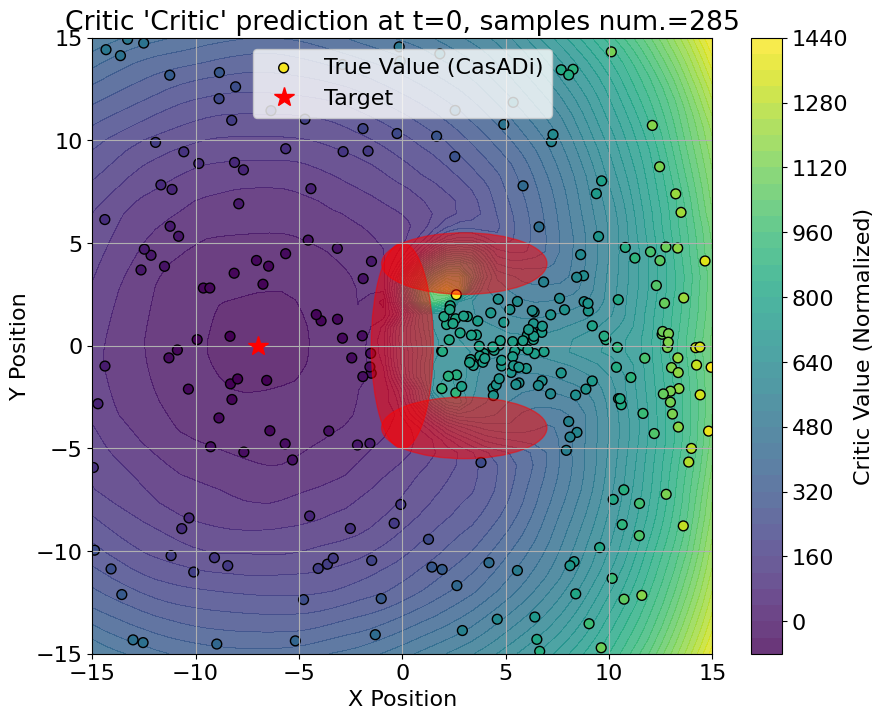

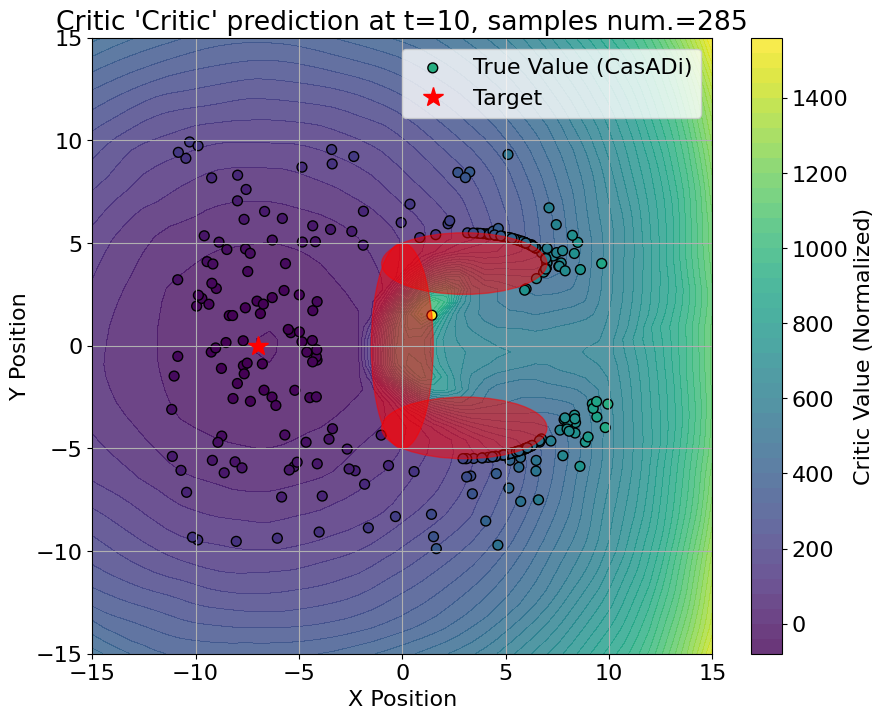

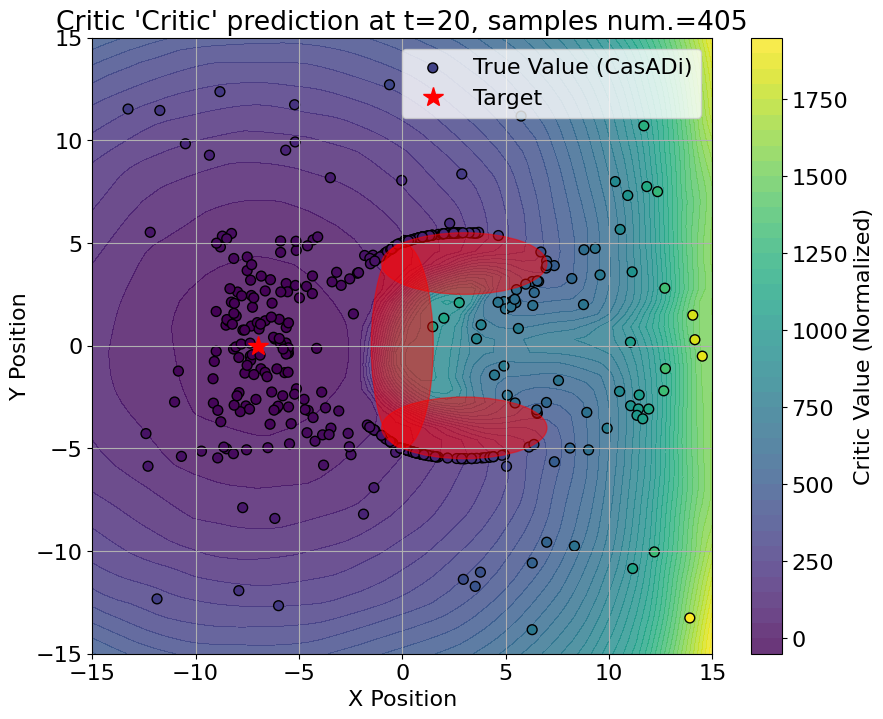

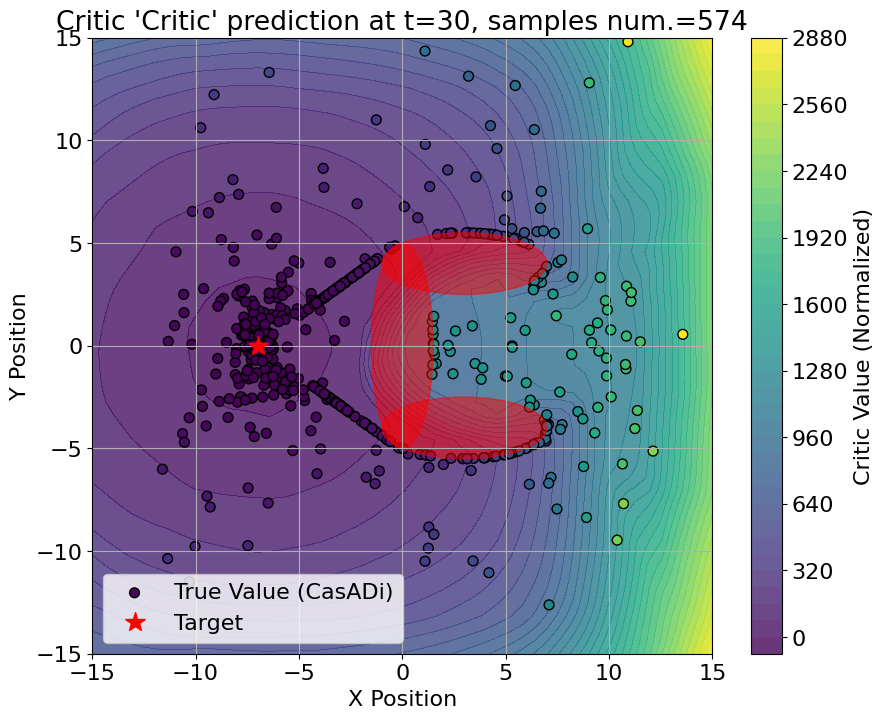

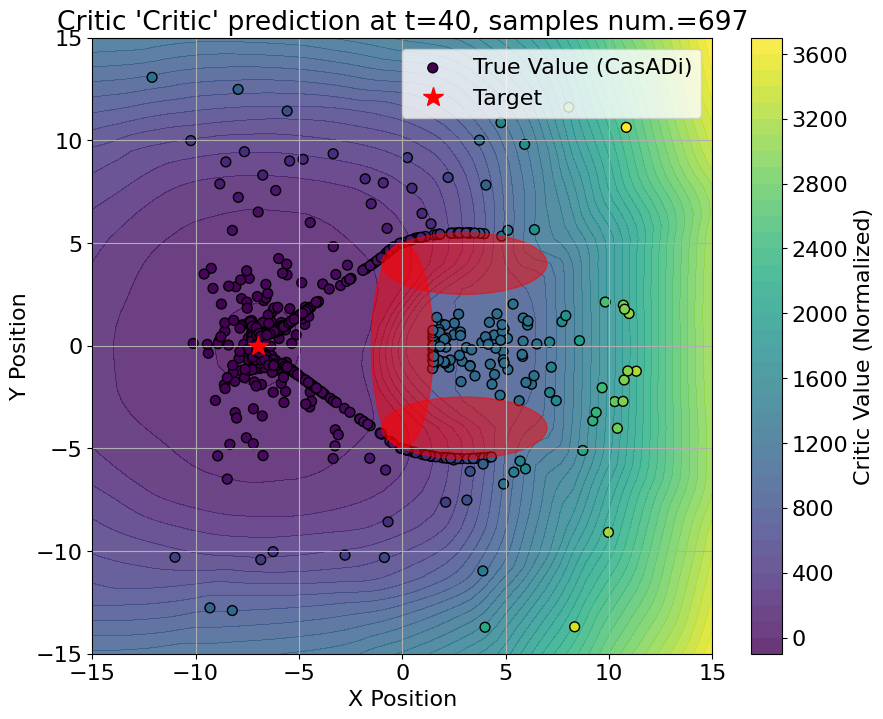

In [68]:
# Train the critic again with the new data in the buffer 
train_critic()

# Update the critic cycles counter
critic_cycles += cycles_counter(replay_buffer, minibatch_size, critic_epochs)
print(f"\nTotal critic cycles: {critic_cycles}")

for t in range(0, N, 10):
  plot_critic(critic, t, show=False)

--- CACTO Iteration 12 ---
--- Start training the constrained actor ---
--- Starting Constrained Actor training for 35 epochs ---
Epoch 1/35 | Mean Q+ALM: 235.0433 | Max Viol: 0.00059 | Lambda: [109.05  96.22  91.16] | Rho: 2328.2 | LR: 0.000500 | step: 98
 | dQ/du norm: 1.328295
Epoch 5/35 | Mean Q+ALM: 235.0603 | Max Viol: 0.00055 | Lambda: [110.38  97.71  93.77] | Rho: 2422.7 | LR: 0.000500 | step: 490
 | dQ/du norm: 1.343742
Epoch 10/35 | Mean Q+ALM: 235.0527 | Max Viol: 0.00061 | Lambda: [114.13 100.49  98.29] | Rho: 2546.3 | LR: 0.000500 | step: 980
 | dQ/du norm: 1.308828
Epoch 15/35 | Mean Q+ALM: 235.0027 | Max Viol: 0.00035 | Lambda: [115.53 101.68 101.25] | Rho: 2676.2 | LR: 0.000400 | step: 1470
 | dQ/du norm: 1.319486
Epoch 20/35 | Mean Q+ALM: 235.0415 | Max Viol: 0.00066 | Lambda: [116.77 103.4  103.73] | Rho: 2812.7 | LR: 0.000320 | step: 1960
 | dQ/du norm: 1.319978
Epoch 25/35 | Mean Q+ALM: 234.9007 | Max Viol: 0.00027 | Lambda: [118.42 105.32 105.95] | Rho: 2956.2 | LR

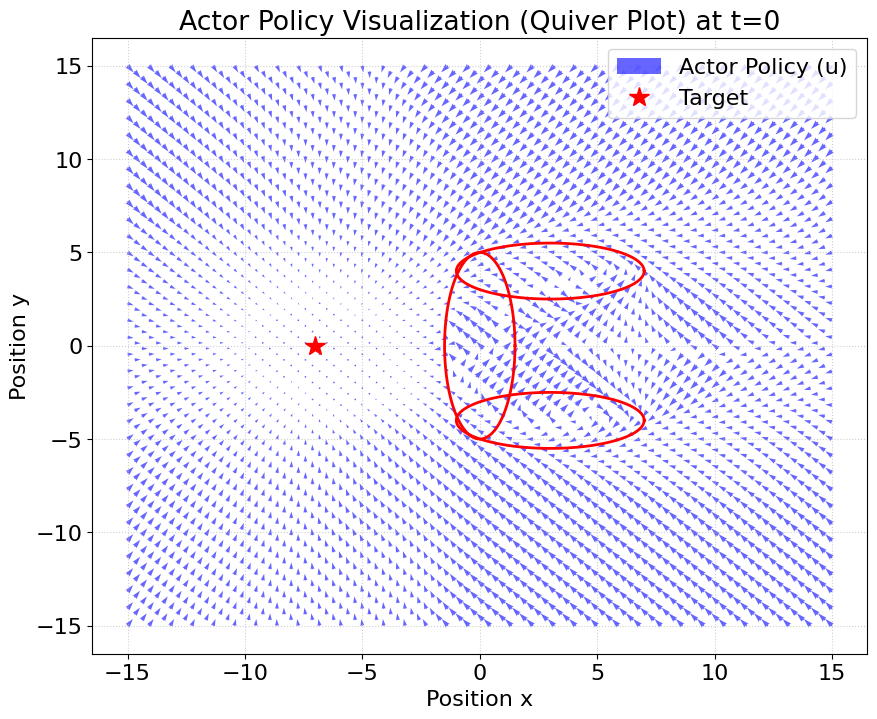

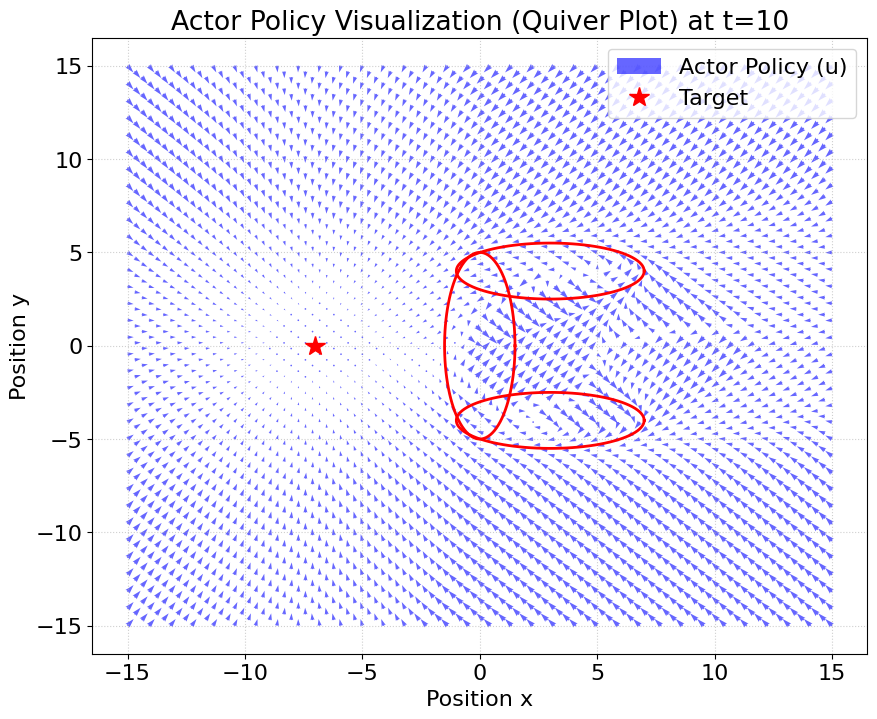

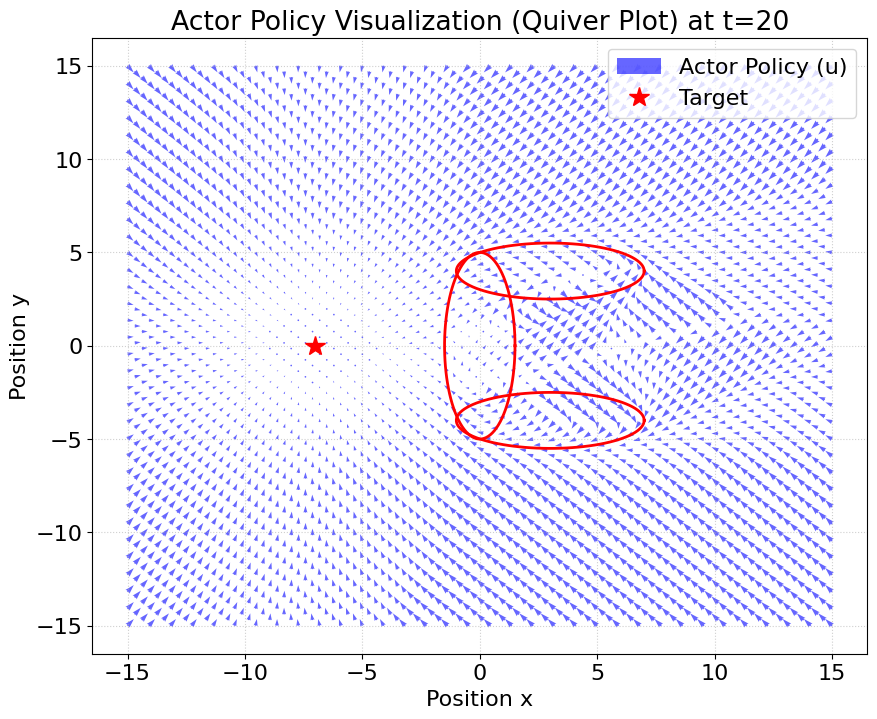

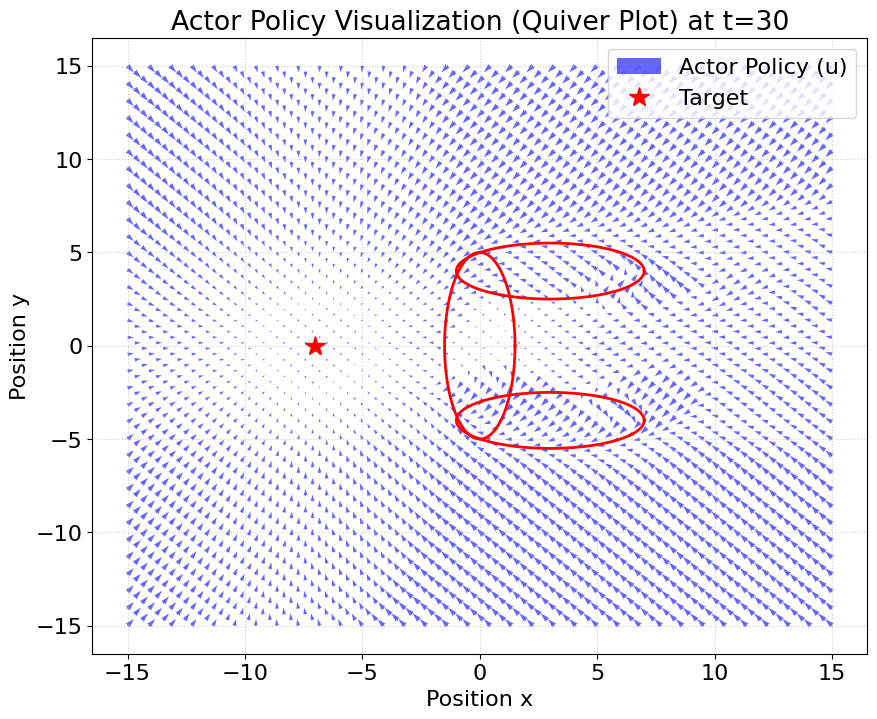

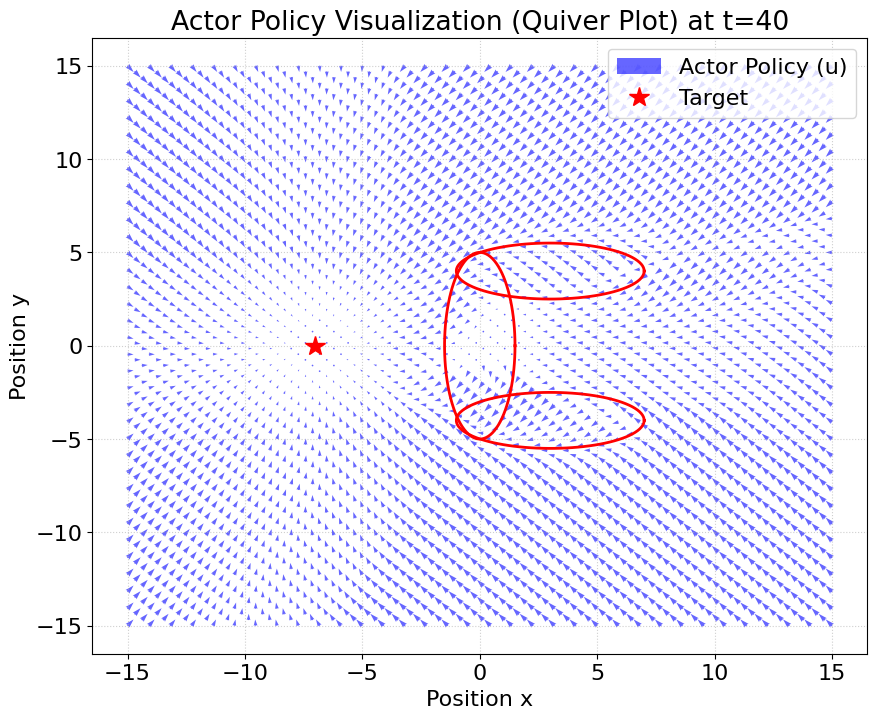

In [69]:
# Train the constrained actor again with the new critic

train_constr_actor()

# Update the constrained actor cycles counter
actor_cycles += cycles_counter(replay_buffer, minibatch_size, actor_epochs)
print(f"\nTotal constrained actor cycles: {actor_cycles}")

for t in range(0, N, 10):
  plot_constr_actor(t, show=True, plot_u_ocp=True)

Actor Only -> Feasible: 12/37 | Violating: 25/37
Actor Only -> Avg. max violation: 0.0274
Actor Only -> Avg. cost: 505.7639

Costs and Feasibility List:
Rollout 001 | Xini: (-10.0, -10.0) | Cost:   125.94 | Status: OK
Rollout 002 | Xini: (-8.0, -5.0) | Cost:    -7.90 | Status: OK
Rollout 003 | Xini: (-10.0,  0.0) | Cost:   -35.04 | Status: OK
Rollout 004 | Xini: (-8.0,  5.0) | Cost:    -7.71 | Status: OK
Rollout 005 | Xini: (-10.0, 10.0) | Cost:   126.18 | Status: OK
Rollout 006 | Xini: ( 5.0,  0.0) | Cost:   623.19 | Status: VIOL
Rollout 007 | Xini: ( 6.0,  1.5) | Cost:   517.78 | Status: VIOL
Rollout 008 | Xini: ( 6.0, -1.5) | Cost:   513.91 | Status: VIOL
Rollout 009 | Xini: ( 5.5,  2.5) | Cost:   473.24 | Status: VIOL
Rollout 010 | Xini: ( 5.5, -2.5) | Cost:   458.70 | Status: VIOL
Rollout 011 | Xini: ( 2.0,  0.0) | Cost:   637.58 | Status: VIOL
Rollout 012 | Xini: ( 1.5,  1.0) | Cost:   637.73 | Status: VIOL
Rollout 013 | Xini: ( 1.5, -2.0) | Cost:   688.96 | Status: VIOL
Rollout 

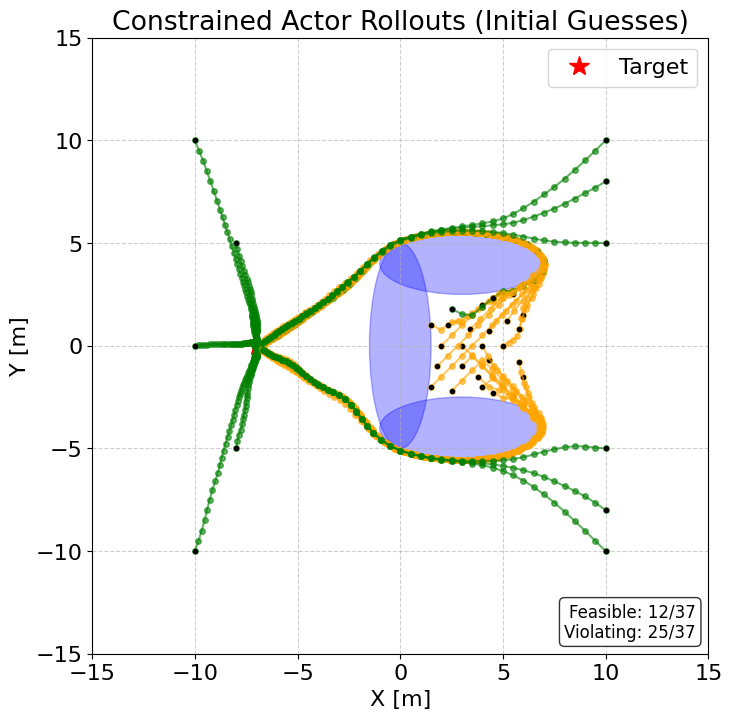

Computing initial guesses in batch...
TO + Warm Start -> Time: 12.120 s
TO + Warm Start -> Feasible: 37/37 | Failed: 0/37


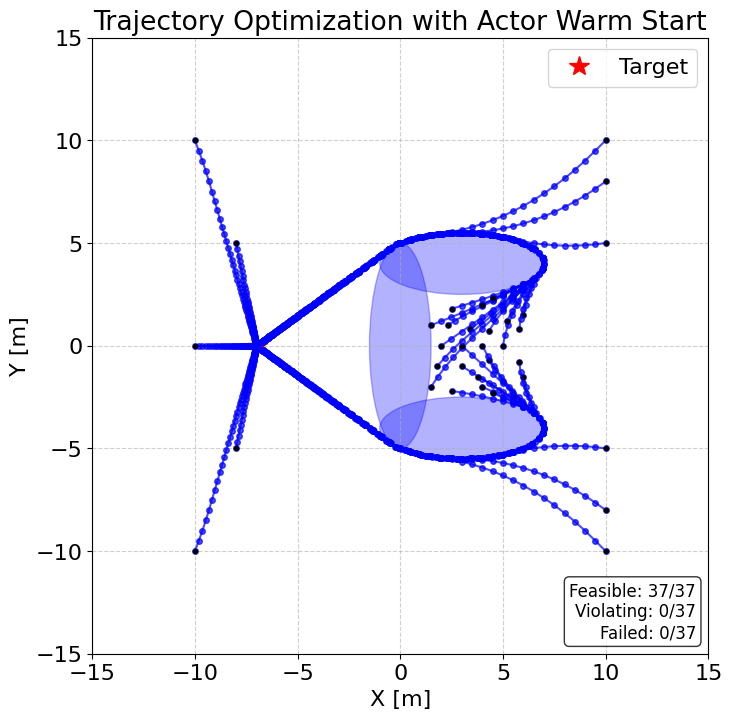

In [70]:
# Final evaluation of the constrained actor rollouts and TO performance after the last iteration
plot_cons_actor_rollouts(print_costs=True)
V_TO, all_cons_x_trajs = evaluate_TO_w_cons_warm_start()

--- CACTO Iteration 13 ---
Start solving 300 TO problems


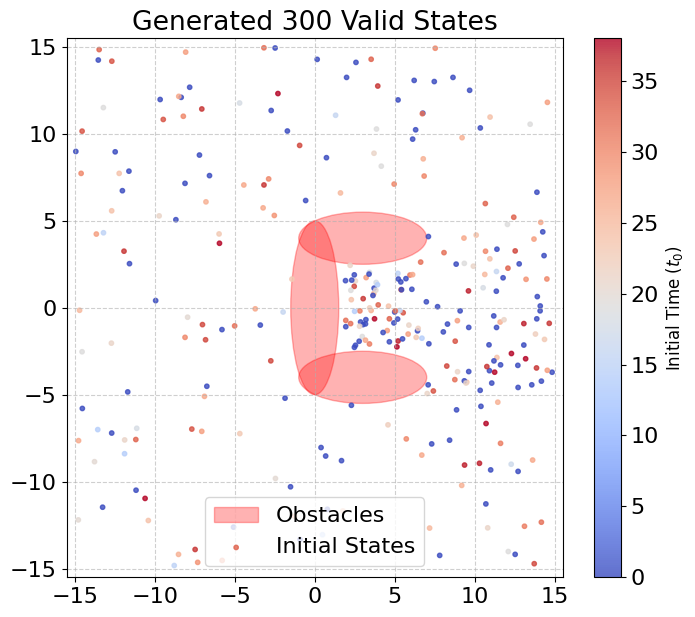

Computing warm start guesses via Actor...


COmputing OCPs: 100%|██████████| 300/300 [01:12<00:00,  4.14traj/s]


--- Finished ---
Successfully solved: 300 / 300
States Buffer size: (25000, 3) samples
Time taken: 74.817 s


In [71]:
# Solve an OCP for every sampled initial state-time using the constrained actor for warm start
solve_TO_problems(use_actor_to_warm_start=True, actor=cons_actor)

--- CACTO Iteration 13 ---
--- Start training critic ---
Replay buffer size: 25000 samples
Epoch 1/35 | MSE: 81.3017 | RMSE: 9.0167 | LR: 0.005000 | step: 98
Epoch 5/35 | MSE: 267.9596 | RMSE: 16.3695 | LR: 0.005000 | step: 490
Epoch 10/35 | MSE: 76.6292 | RMSE: 8.7538 | LR: 0.005000 | step: 980
Epoch 15/35 | MSE: 32.3531 | RMSE: 5.6880 | LR: 0.003750 | step: 1470
Epoch 20/35 | MSE: 40.6230 | RMSE: 6.3736 | LR: 0.002812 | step: 1960
Epoch 25/35 | MSE: 23.4959 | RMSE: 4.8473 | LR: 0.002109 | step: 2450
Epoch 30/35 | MSE: 17.5207 | RMSE: 4.1858 | LR: 0.001582 | step: 2940
Epoch 35/35 | MSE: 7.1329 | RMSE: 2.6708 | LR: 0.001187 | step: 3430
Final Critic MSE: 7.13
Final Critic RMSE: 2.67
--- Critic training has finished ---

Total critic cycles: 42140


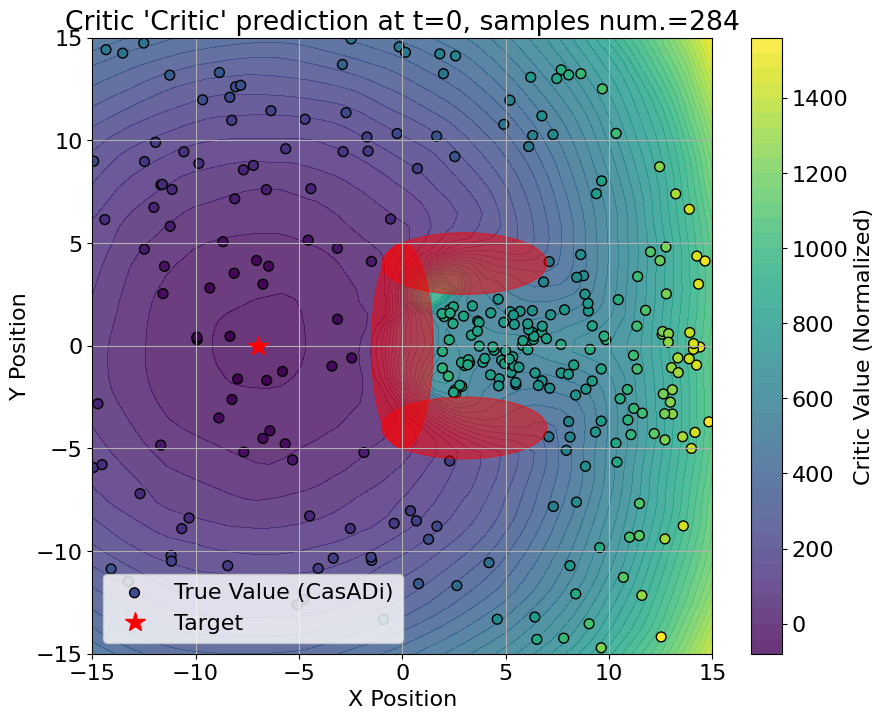

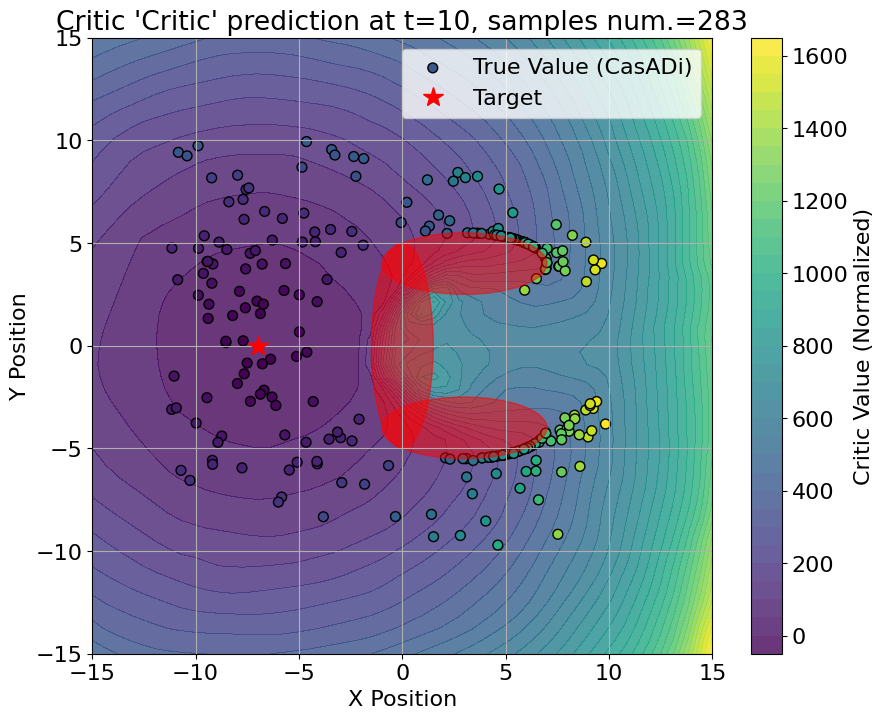

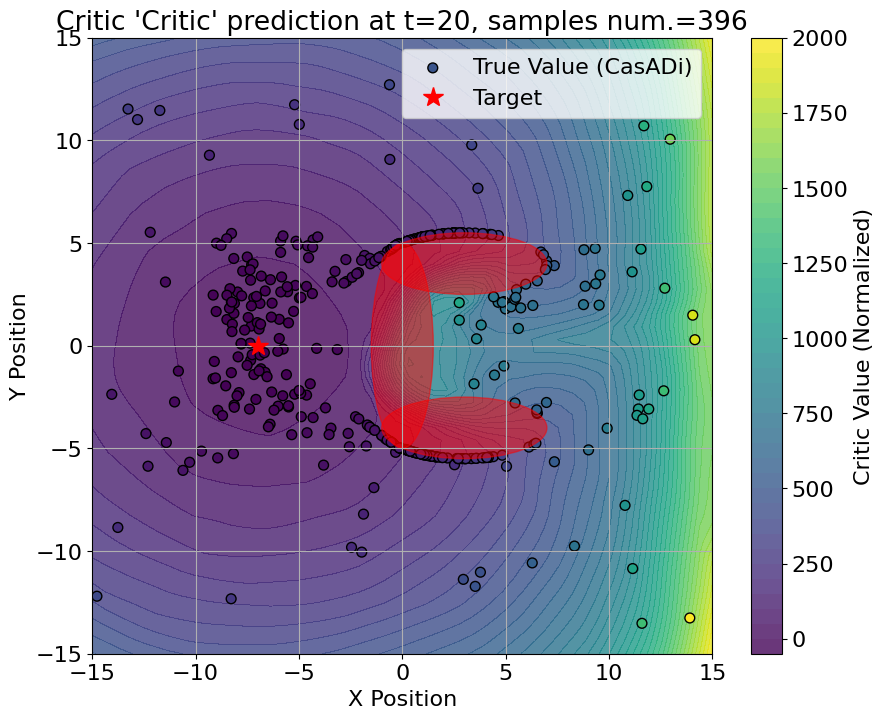

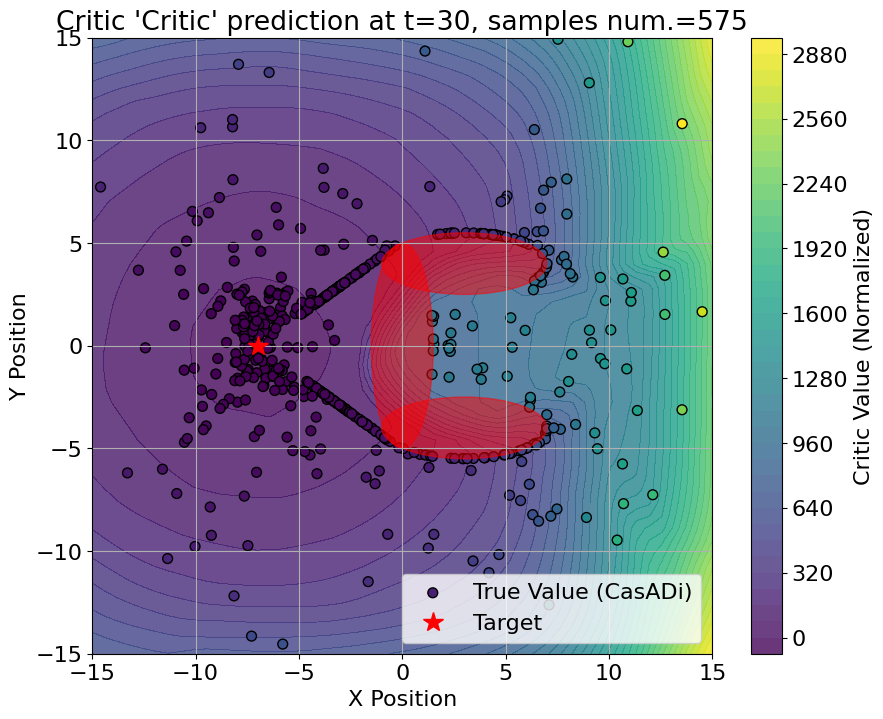

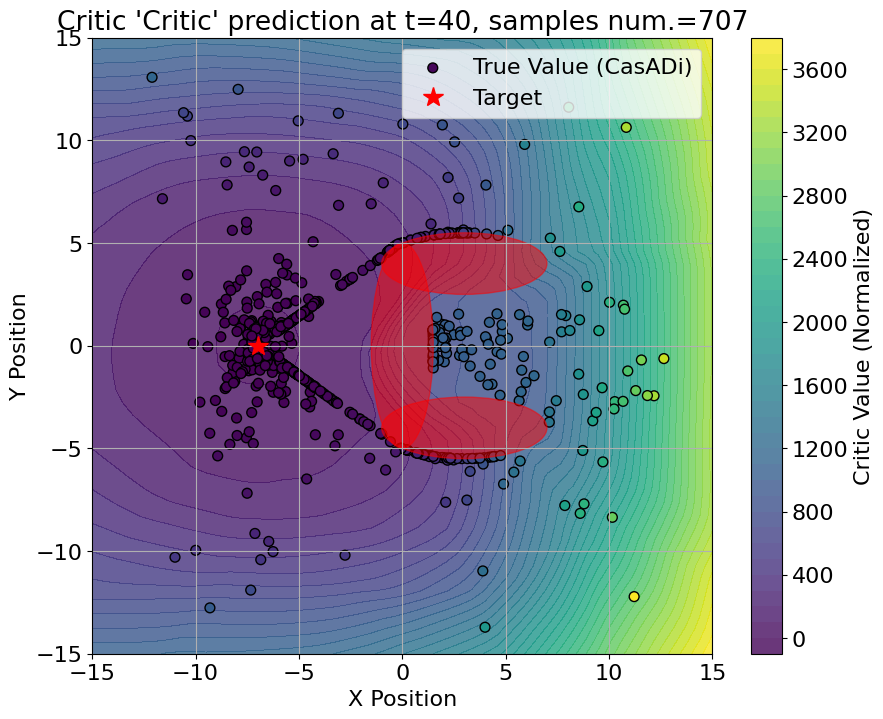

In [72]:
# Train the critic again with the new data in the buffer 
train_critic()

# Update the critic cycles counter
critic_cycles += cycles_counter(replay_buffer, minibatch_size, critic_epochs)
print(f"\nTotal critic cycles: {critic_cycles}")

for t in range(0, N, 10):
  plot_critic(critic, t, show=False)

--- CACTO Iteration 13 ---
--- Start training the constrained actor ---
--- Starting Constrained Actor training for 35 epochs ---
Epoch 1/35 | Mean Q+ALM: 239.5776 | Max Viol: 0.00061 | Lambda: [120.75 108.83 110.65] | Rho: 3298.1 | LR: 0.000500 | step: 98
 | dQ/du norm: 1.411731
Epoch 5/35 | Mean Q+ALM: 239.6454 | Max Viol: 0.00093 | Lambda: [122.58 112.15 112.39] | Rho: 3432.1 | LR: 0.000500 | step: 490
 | dQ/du norm: 1.438235
Epoch 10/35 | Mean Q+ALM: 239.5227 | Max Viol: 0.00046 | Lambda: [123.17 115.94 115.15] | Rho: 3607.1 | LR: 0.000500 | step: 980
 | dQ/du norm: 1.435763
Epoch 15/35 | Mean Q+ALM: 239.4828 | Max Viol: 0.00029 | Lambda: [124.81 117.53 116.8 ] | Rho: 3791.1 | LR: 0.000400 | step: 1470
 | dQ/du norm: 1.423724
Epoch 20/35 | Mean Q+ALM: 239.3910 | Max Viol: 0.00024 | Lambda: [125.35 120.2  118.71] | Rho: 3984.5 | LR: 0.000320 | step: 1960
 | dQ/du norm: 1.417210
Epoch 25/35 | Mean Q+ALM: 239.3094 | Max Viol: 0.00018 | Lambda: [126.37 122.18 120.25] | Rho: 4187.8 | LR

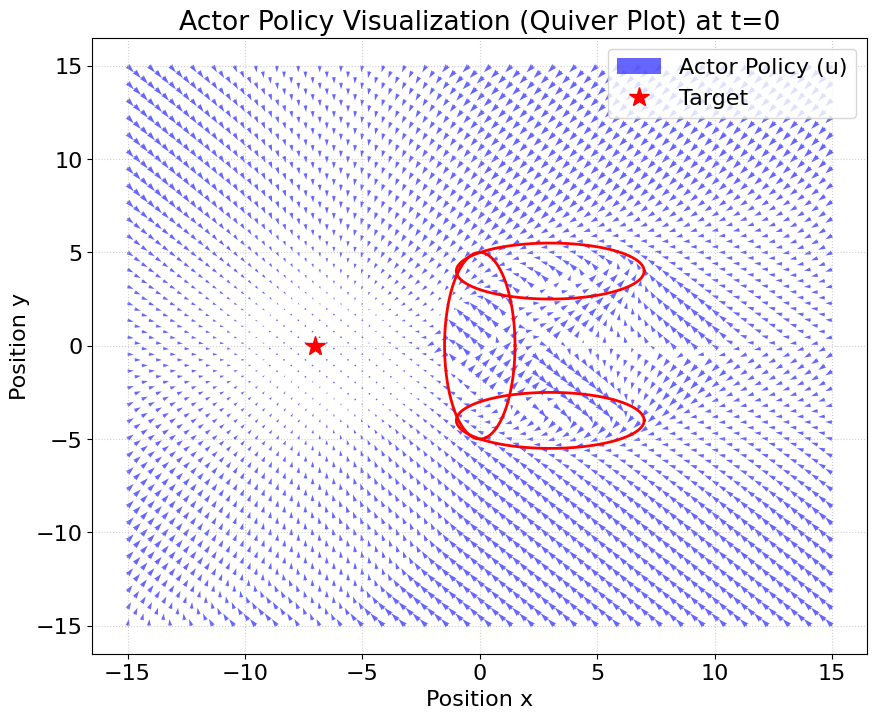

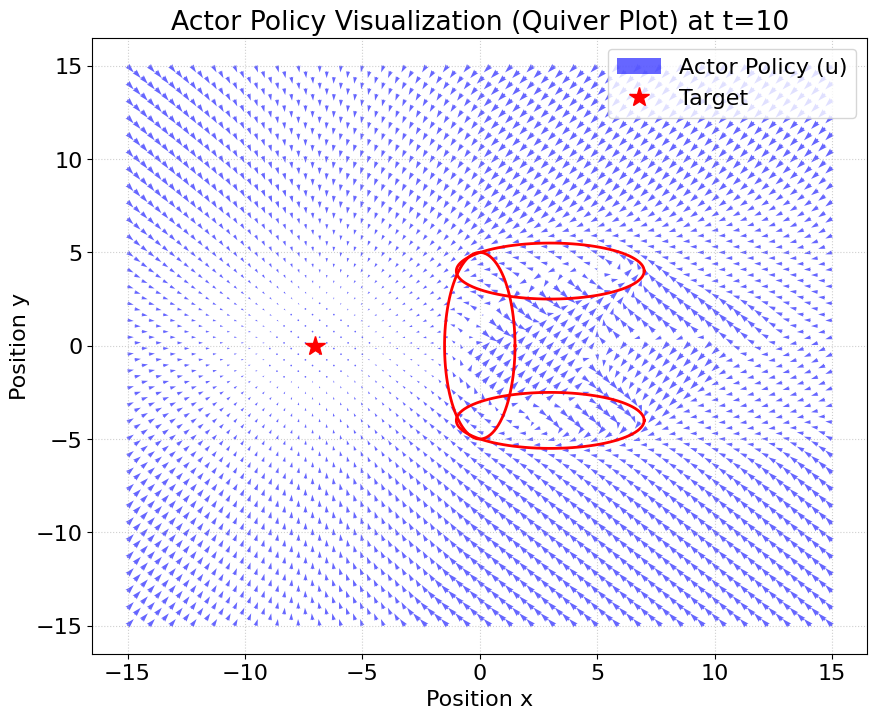

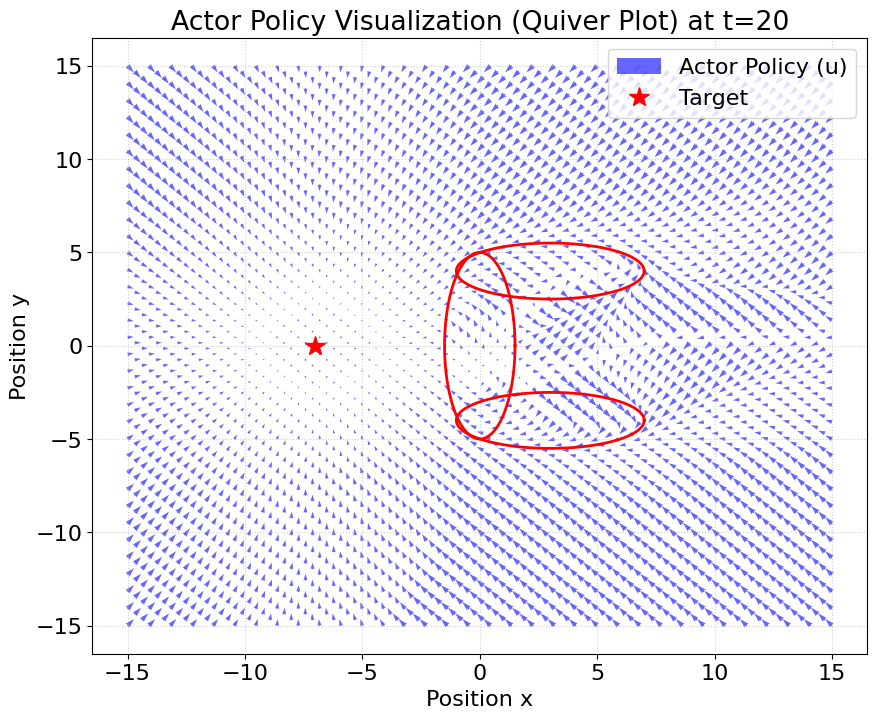

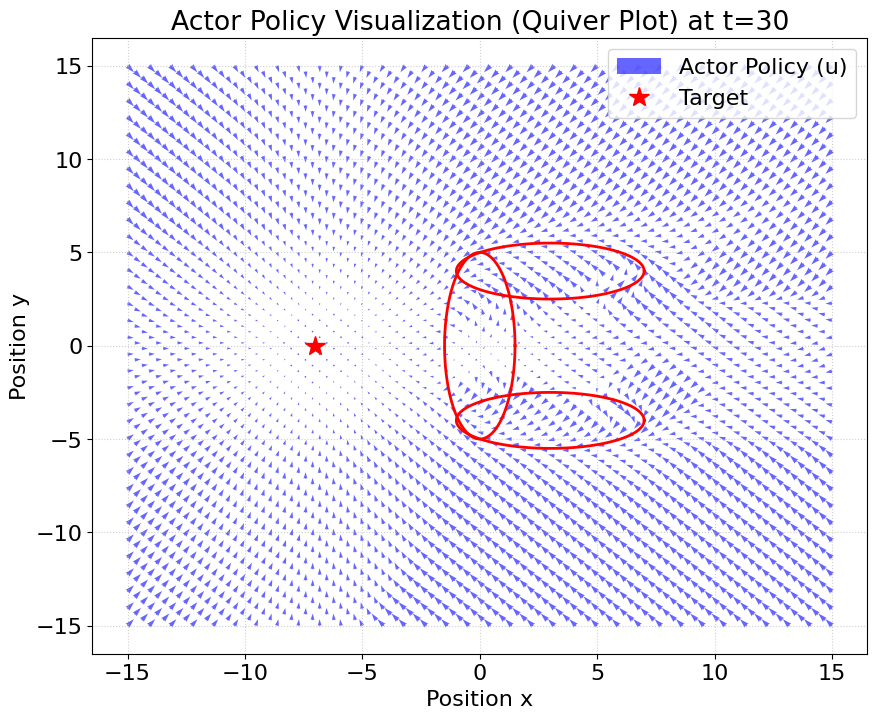

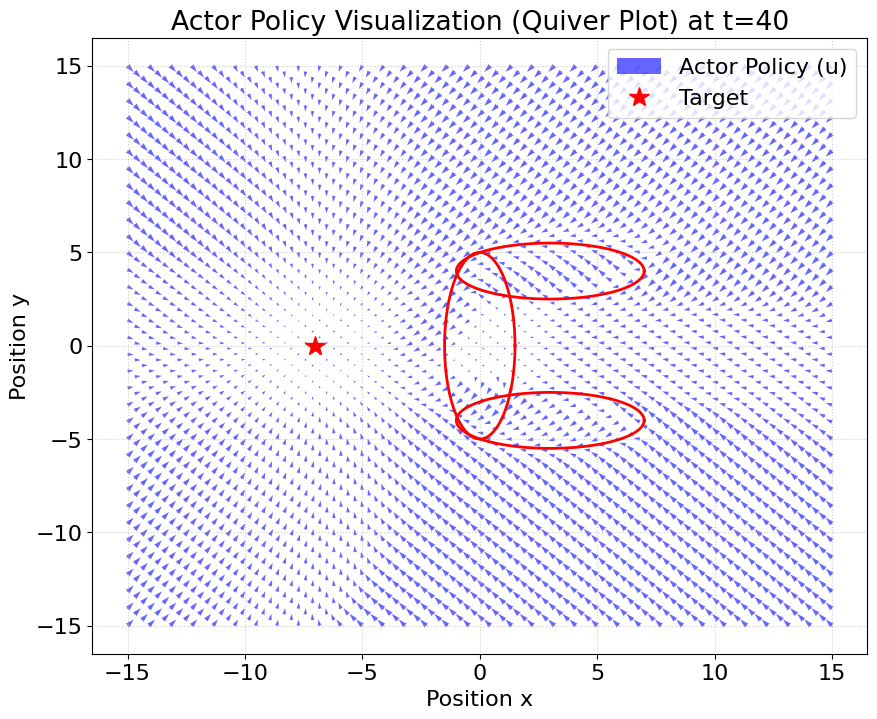

In [73]:
# Train the constrained actor again with the new critic

train_constr_actor()

# Update the constrained actor cycles counter
actor_cycles += cycles_counter(replay_buffer, minibatch_size, actor_epochs)
print(f"\nTotal constrained actor cycles: {actor_cycles}")

for t in range(0, N, 10):
  plot_constr_actor(t, show=True, plot_u_ocp=True)

Actor Only -> Feasible: 11/37 | Violating: 26/37
Actor Only -> Avg. max violation: 0.0615
Actor Only -> Avg. cost: 496.9911

Costs and Feasibility List:
Rollout 001 | Xini: (-10.0, -10.0) | Cost:   126.37 | Status: OK
Rollout 002 | Xini: (-8.0, -5.0) | Cost:    -7.40 | Status: OK
Rollout 003 | Xini: (-10.0,  0.0) | Cost:   -34.63 | Status: OK
Rollout 004 | Xini: (-8.0,  5.0) | Cost:    -7.35 | Status: OK
Rollout 005 | Xini: (-10.0, 10.0) | Cost:   126.97 | Status: OK
Rollout 006 | Xini: ( 5.0,  0.0) | Cost:   586.50 | Status: VIOL
Rollout 007 | Xini: ( 6.0,  1.5) | Cost:   513.80 | Status: VIOL
Rollout 008 | Xini: ( 6.0, -1.5) | Cost:   509.50 | Status: VIOL
Rollout 009 | Xini: ( 5.5,  2.5) | Cost:   468.20 | Status: VIOL
Rollout 010 | Xini: ( 5.5, -2.5) | Cost:   458.27 | Status: VIOL
Rollout 011 | Xini: ( 2.0,  0.0) | Cost:   628.25 | Status: VIOL
Rollout 012 | Xini: ( 1.5,  1.0) | Cost:   633.79 | Status: VIOL
Rollout 013 | Xini: ( 1.5, -2.0) | Cost:   683.72 | Status: VIOL
Rollout 

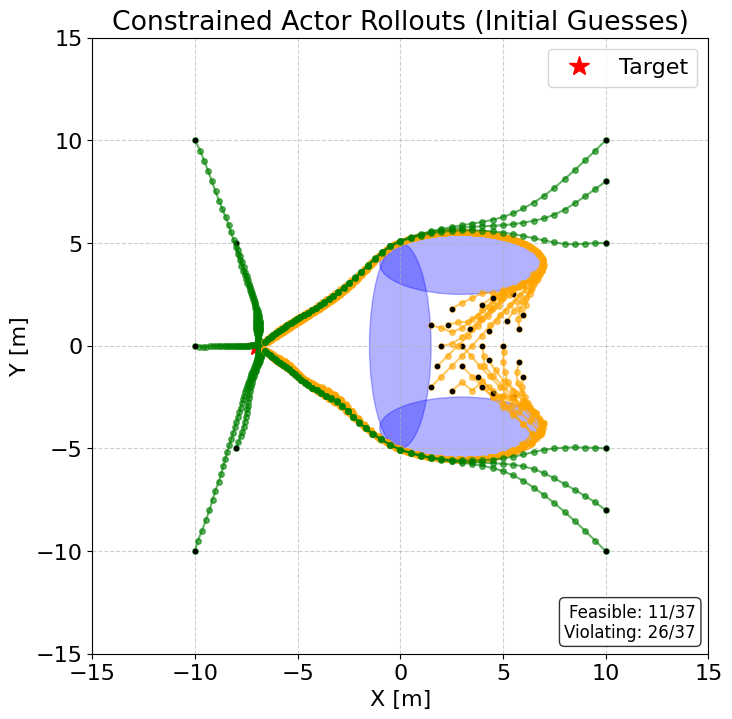

Computing initial guesses in batch...
TO + Warm Start -> Time: 13.112 s
TO + Warm Start -> Feasible: 37/37 | Failed: 0/37


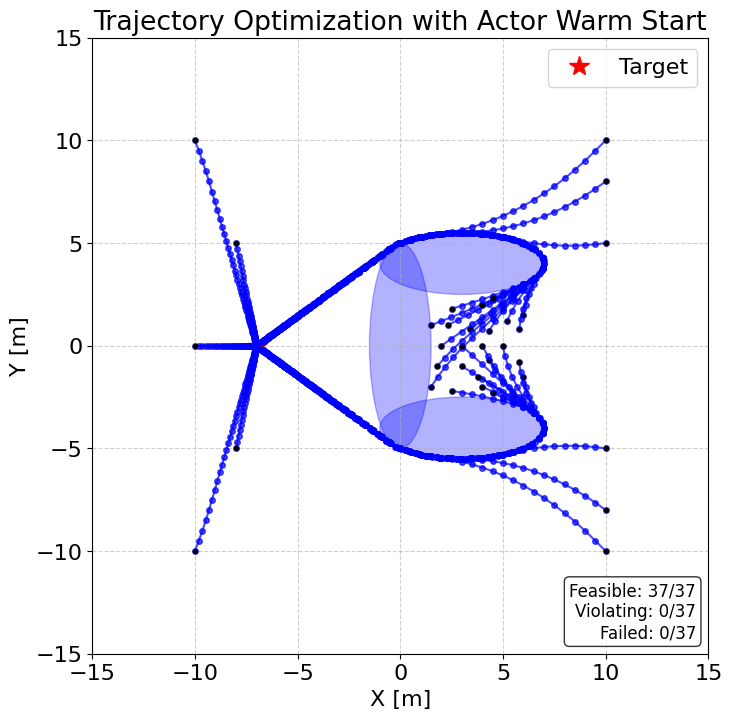

In [74]:
# Final evaluation of the constrained actor rollouts and TO performance after the last iteration
plot_cons_actor_rollouts(print_costs=True)
V_TO, all_cons_x_trajs = evaluate_TO_w_cons_warm_start()

--- CACTO Iteration 14 ---
Start solving 300 TO problems


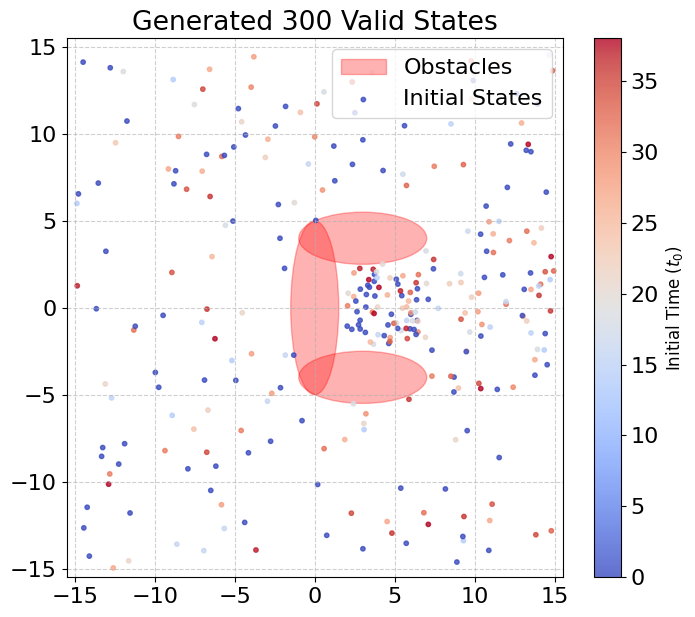

Computing warm start guesses via Actor...


COmputing OCPs: 100%|██████████| 300/300 [01:17<00:00,  3.85traj/s]


--- Finished ---
Successfully solved: 300 / 300
States Buffer size: (25000, 3) samples
Time taken: 80.261 s


In [75]:
# Solve an OCP for every sampled initial state-time using the constrained actor for warm start
solve_TO_problems(use_actor_to_warm_start=True, actor=cons_actor)

--- CACTO Iteration 14 ---
--- Start training critic ---
Replay buffer size: 25000 samples
Epoch 1/35 | MSE: 200.0455 | RMSE: 14.1437 | LR: 0.005000 | step: 98
Epoch 5/35 | MSE: 51.9840 | RMSE: 7.2100 | LR: 0.005000 | step: 490
Epoch 10/35 | MSE: 57.5661 | RMSE: 7.5872 | LR: 0.005000 | step: 980
Epoch 15/35 | MSE: 111.7735 | RMSE: 10.5723 | LR: 0.003750 | step: 1470
Epoch 20/35 | MSE: 18.1401 | RMSE: 4.2591 | LR: 0.002812 | step: 1960
Epoch 25/35 | MSE: 20.9430 | RMSE: 4.5763 | LR: 0.002109 | step: 2450
Epoch 30/35 | MSE: 14.3178 | RMSE: 3.7839 | LR: 0.001582 | step: 2940
Epoch 35/35 | MSE: 12.5132 | RMSE: 3.5374 | LR: 0.001187 | step: 3430
Final Critic MSE: 12.51
Final Critic RMSE: 3.54
--- Critic training has finished ---

Total critic cycles: 45570


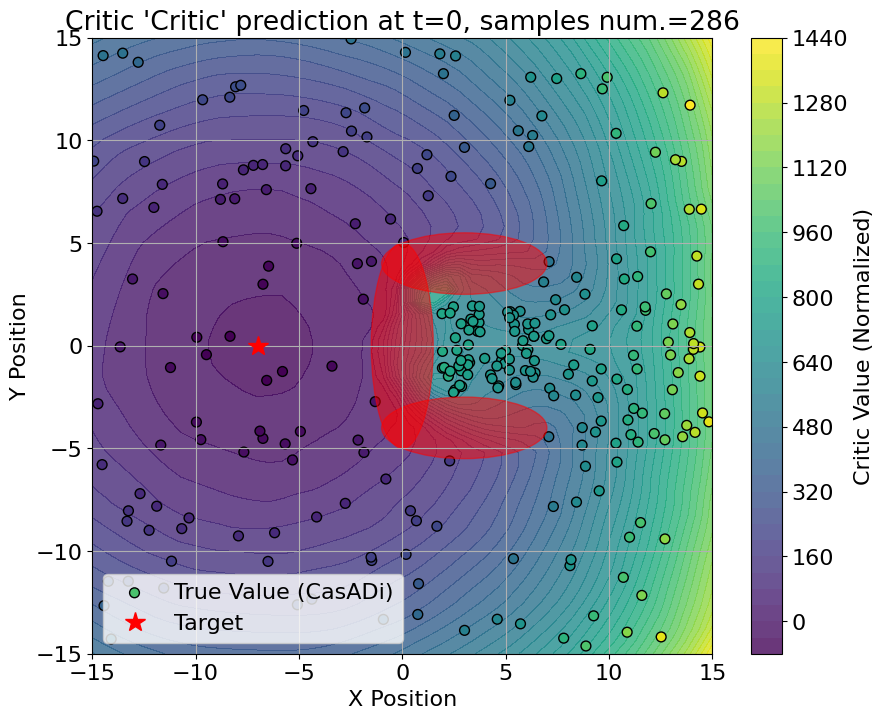

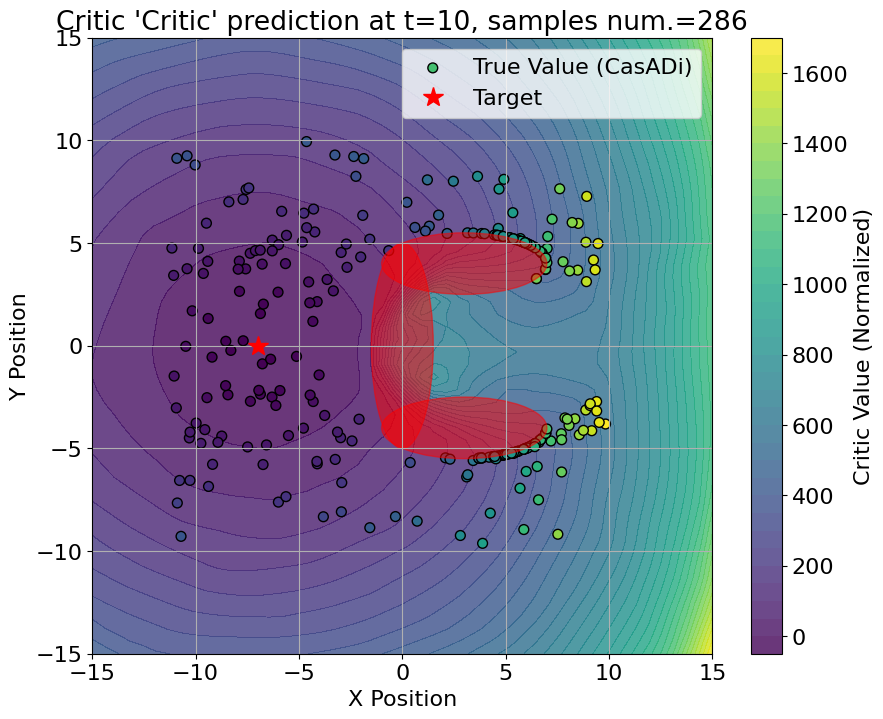

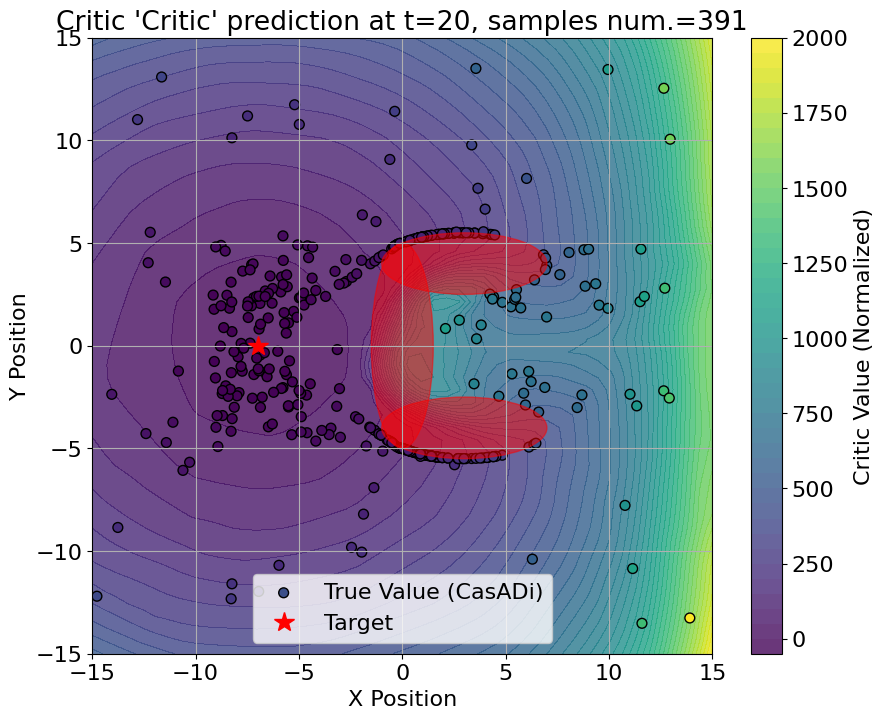

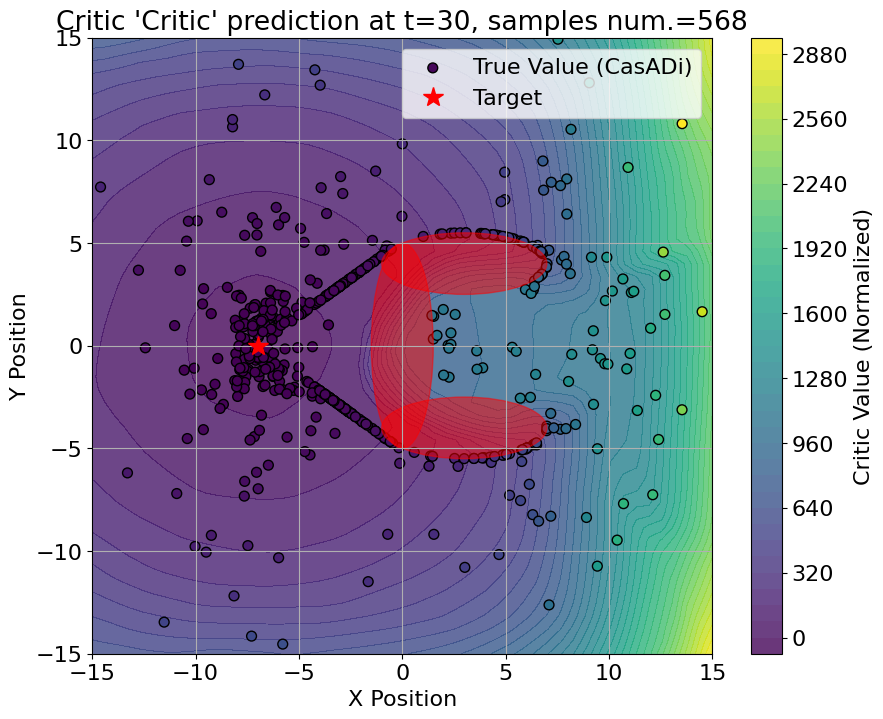

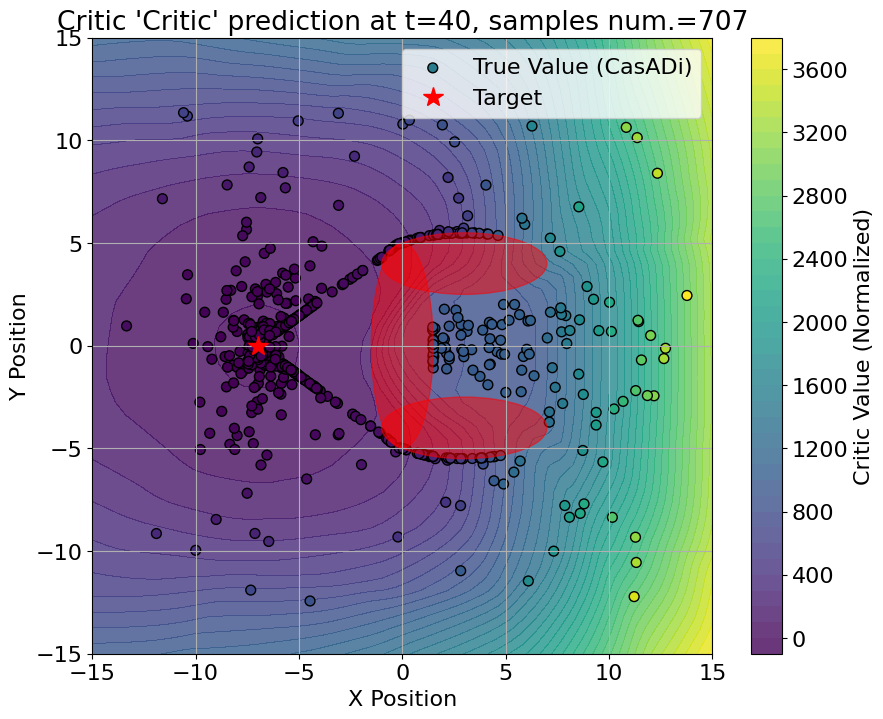

In [76]:
# Train the critic again with the new data in the buffer 
train_critic()

# Update the critic cycles counter
critic_cycles += cycles_counter(replay_buffer, minibatch_size, critic_epochs)
print(f"\nTotal critic cycles: {critic_cycles}")

for t in range(0, N, 10):
  plot_critic(critic, t, show=False)

--- CACTO Iteration 14 ---
--- Start training the constrained actor ---
--- Starting Constrained Actor training for 35 epochs ---
Epoch 1/35 | Mean Q+ALM: 249.3596 | Max Viol: 0.00041 | Lambda: [131.3  125.68 126.79] | Rho: 4672.1 | LR: 0.000500 | step: 98
 | dQ/du norm: 1.508427
Epoch 5/35 | Mean Q+ALM: 249.3550 | Max Viol: 0.00060 | Lambda: [132.65 128.08 128.53] | Rho: 4861.9 | LR: 0.000500 | step: 490
 | dQ/du norm: 1.506334
Epoch 10/35 | Mean Q+ALM: 249.2839 | Max Viol: 0.00035 | Lambda: [134.48 132.29 134.  ] | Rho: 5109.9 | LR: 0.000500 | step: 980
 | dQ/du norm: 1.500097
Epoch 15/35 | Mean Q+ALM: 249.2472 | Max Viol: 0.00023 | Lambda: [135.7  136.78 136.61] | Rho: 5370.5 | LR: 0.000400 | step: 1470
 | dQ/du norm: 1.494497
Epoch 20/35 | Mean Q+ALM: 249.1868 | Max Viol: 0.00029 | Lambda: [137.83 139.88 141.11] | Rho: 5644.5 | LR: 0.000320 | step: 1960
 | dQ/du norm: 1.479879
Epoch 25/35 | Mean Q+ALM: 249.1842 | Max Viol: 0.00015 | Lambda: [138.46 142.8  144.32] | Rho: 5932.4 | LR

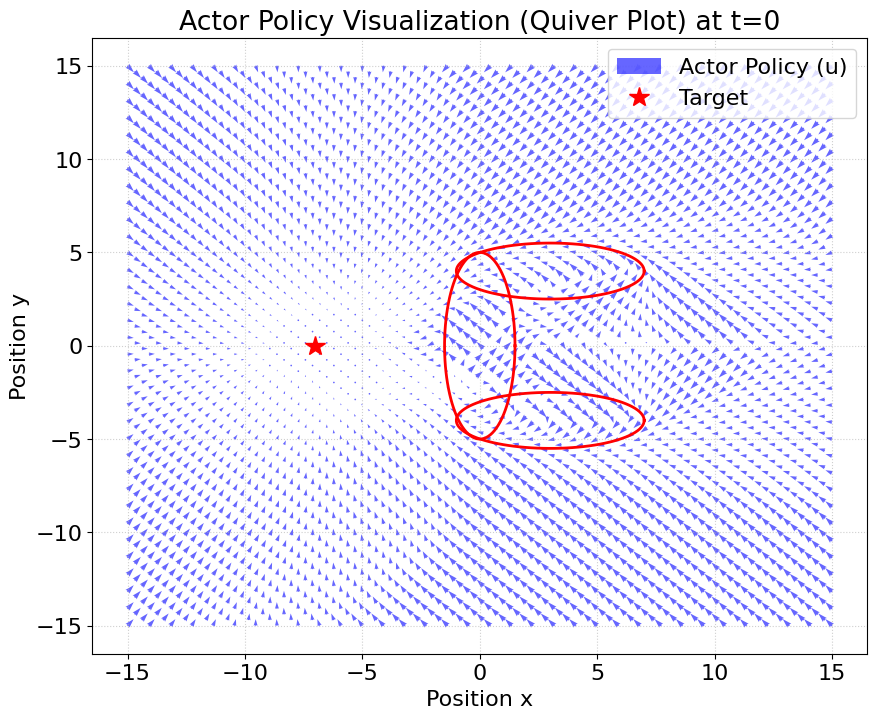

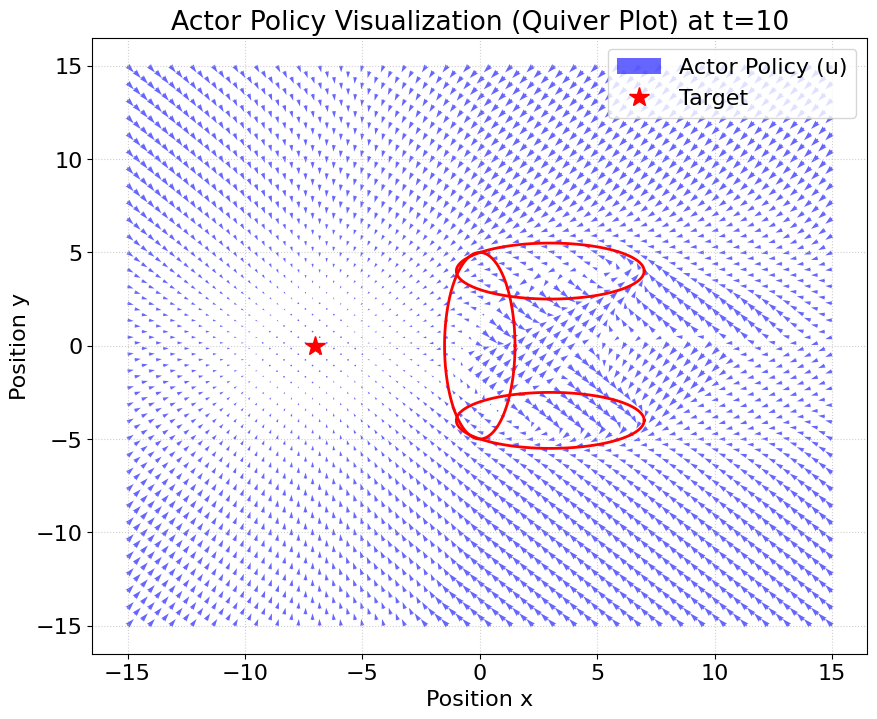

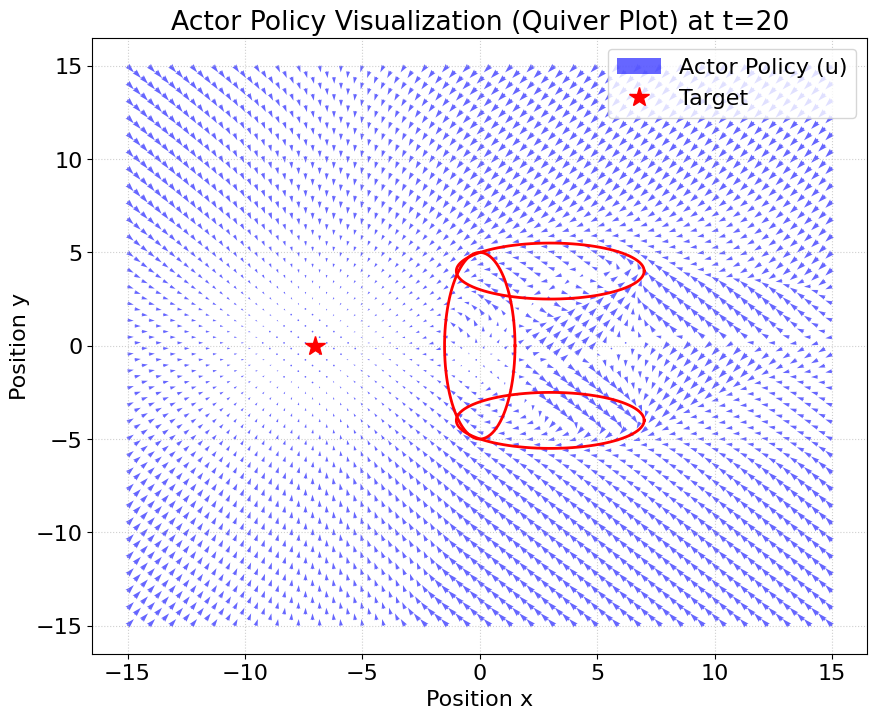

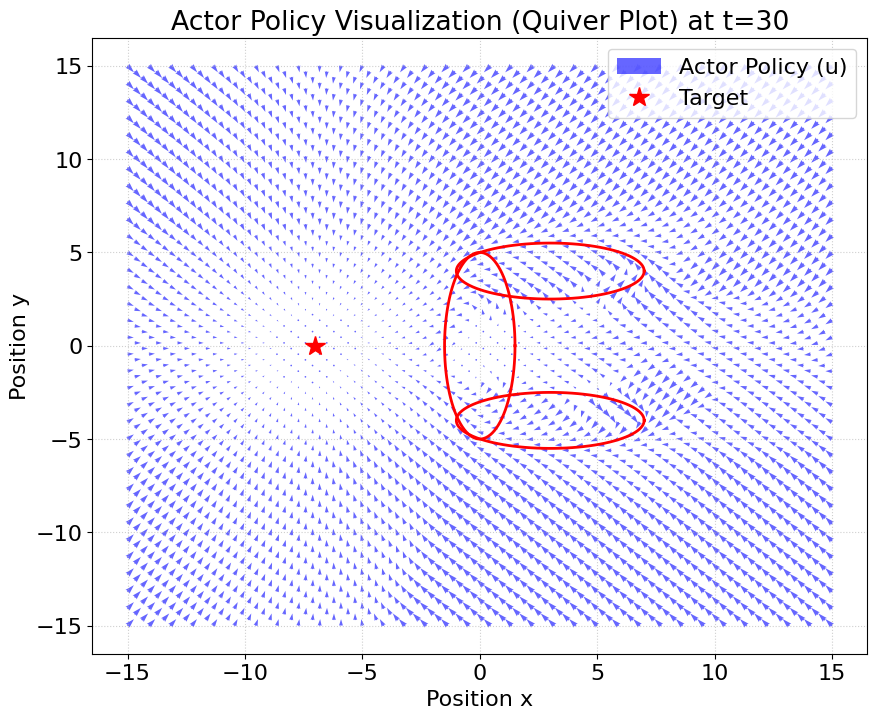

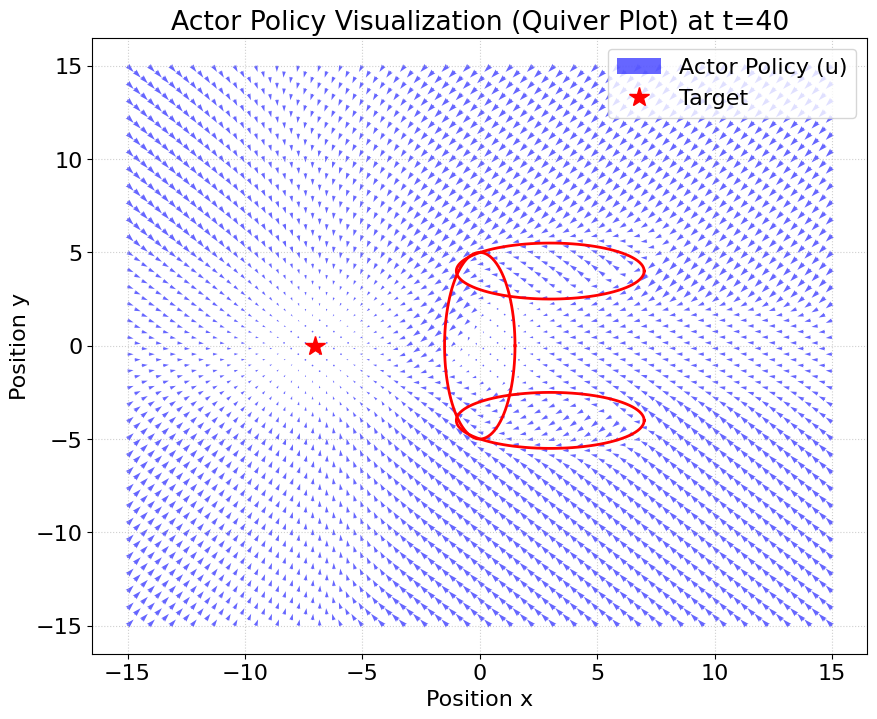

In [77]:
# Train the constrained actor again with the new critic

train_constr_actor()

# Update the constrained actor cycles counter
actor_cycles += cycles_counter(replay_buffer, minibatch_size, actor_epochs)
print(f"\nTotal constrained actor cycles: {actor_cycles}")

for t in range(0, N, 10):
  plot_constr_actor(t, show=True, plot_u_ocp=True)

Actor Only -> Feasible: 14/37 | Violating: 23/37
Actor Only -> Avg. max violation: 0.0580
Actor Only -> Avg. cost: 497.3231

Costs and Feasibility List:
Rollout 001 | Xini: (-10.0, -10.0) | Cost:   126.13 | Status: OK
Rollout 002 | Xini: (-8.0, -5.0) | Cost:    -7.81 | Status: OK
Rollout 003 | Xini: (-10.0,  0.0) | Cost:   -34.86 | Status: OK
Rollout 004 | Xini: (-8.0,  5.0) | Cost:    -7.94 | Status: OK
Rollout 005 | Xini: (-10.0, 10.0) | Cost:   126.26 | Status: OK
Rollout 006 | Xini: ( 5.0,  0.0) | Cost:   588.91 | Status: VIOL
Rollout 007 | Xini: ( 6.0,  1.5) | Cost:   515.32 | Status: VIOL
Rollout 008 | Xini: ( 6.0, -1.5) | Cost:   518.66 | Status: OK
Rollout 009 | Xini: ( 5.5,  2.5) | Cost:   463.74 | Status: VIOL
Rollout 010 | Xini: ( 5.5, -2.5) | Cost:   473.92 | Status: VIOL
Rollout 011 | Xini: ( 2.0,  0.0) | Cost:   627.68 | Status: VIOL
Rollout 012 | Xini: ( 1.5,  1.0) | Cost:   631.32 | Status: VIOL
Rollout 013 | Xini: ( 1.5, -2.0) | Cost:   635.68 | Status: VIOL
Rollout 01

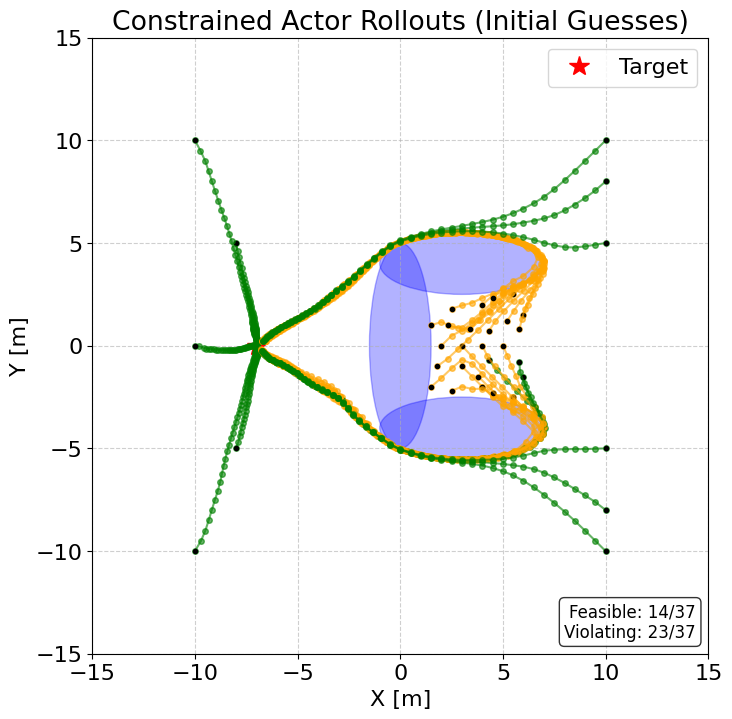

Computing initial guesses in batch...
TO + Warm Start -> Time: 11.694 s
TO + Warm Start -> Feasible: 37/37 | Failed: 0/37


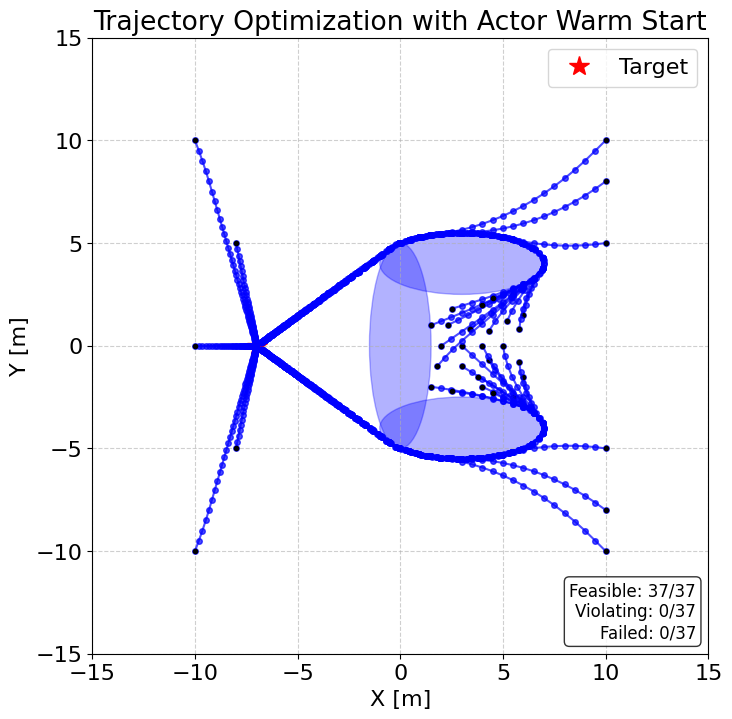

In [78]:
# Final evaluation of the constrained actor rollouts and TO performance after the last iteration
plot_cons_actor_rollouts(print_costs=True)
V_TO, all_cons_x_trajs = evaluate_TO_w_cons_warm_start()

--- CACTO Iteration 15 ---
Start solving 300 TO problems


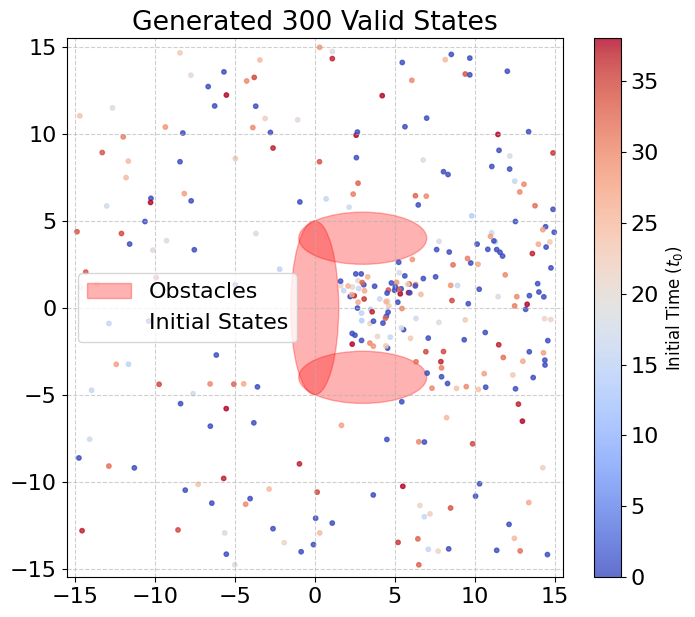

Computing warm start guesses via Actor...


COmputing OCPs: 100%|██████████| 300/300 [01:08<00:00,  4.36traj/s]


--- Finished ---
Successfully solved: 300 / 300
States Buffer size: (25000, 3) samples
Time taken: 71.319 s


In [79]:
# Solve an OCP for every sampled initial state-time using the constrained actor for warm start
solve_TO_problems(use_actor_to_warm_start=True, actor=cons_actor)

--- CACTO Iteration 15 ---
--- Start training critic ---
Replay buffer size: 25000 samples
Epoch 1/35 | MSE: 157.2370 | RMSE: 12.5394 | LR: 0.005000 | step: 98
Epoch 5/35 | MSE: 27.2337 | RMSE: 5.2186 | LR: 0.005000 | step: 490
Epoch 10/35 | MSE: 37.2468 | RMSE: 6.1030 | LR: 0.005000 | step: 980
Epoch 15/35 | MSE: 19.8435 | RMSE: 4.4546 | LR: 0.003750 | step: 1470
Epoch 20/35 | MSE: 24.7461 | RMSE: 4.9745 | LR: 0.002812 | step: 1960
Epoch 25/35 | MSE: 16.7703 | RMSE: 4.0952 | LR: 0.002109 | step: 2450
Epoch 30/35 | MSE: 11.5646 | RMSE: 3.4007 | LR: 0.001582 | step: 2940
Epoch 35/35 | MSE: 6.1121 | RMSE: 2.4723 | LR: 0.001187 | step: 3430
Final Critic MSE: 6.11
Final Critic RMSE: 2.47
--- Critic training has finished ---

Total critic cycles: 49000


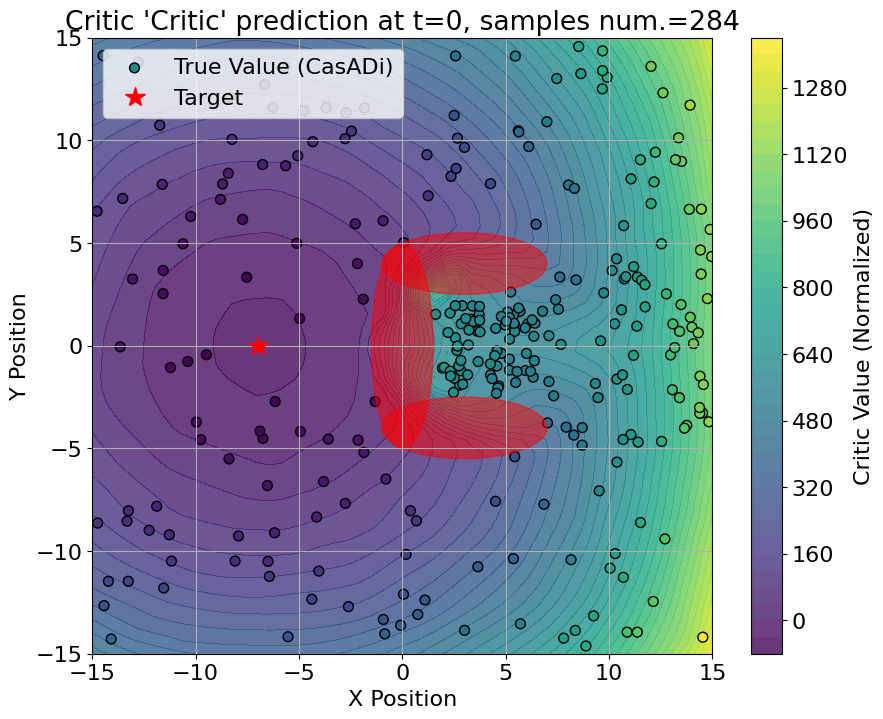

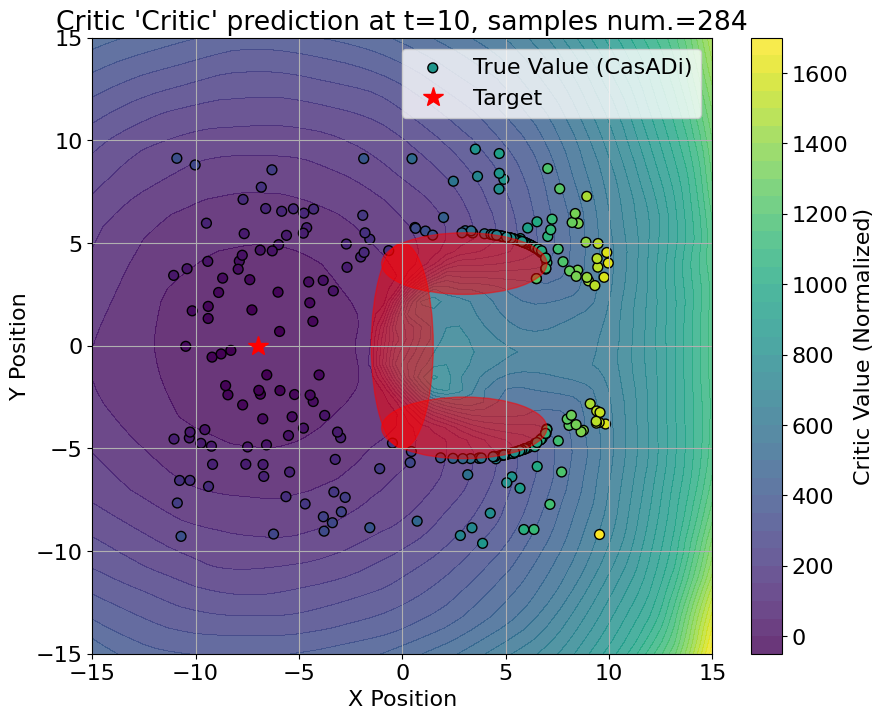

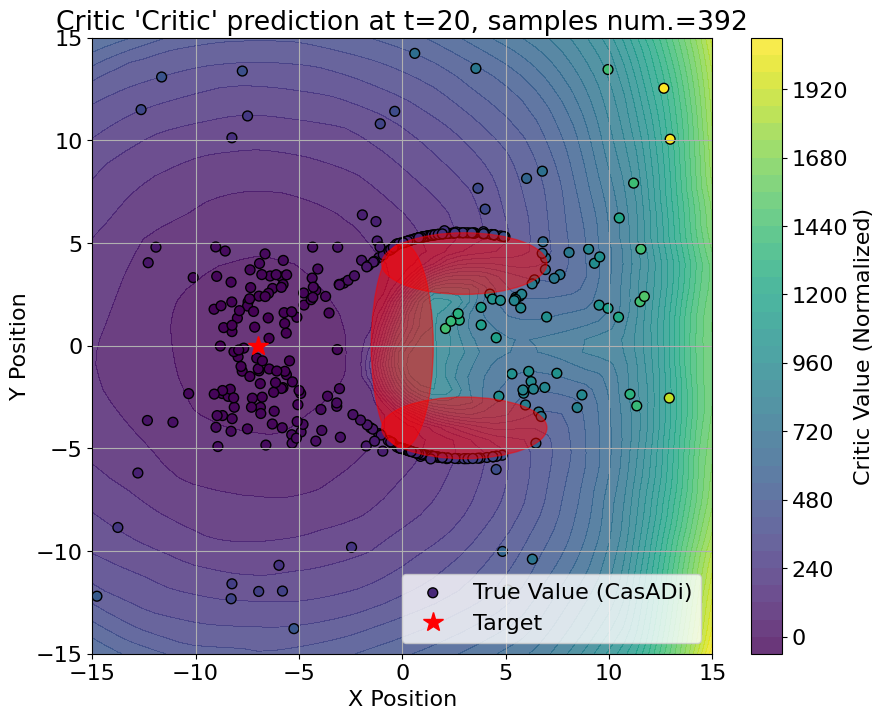

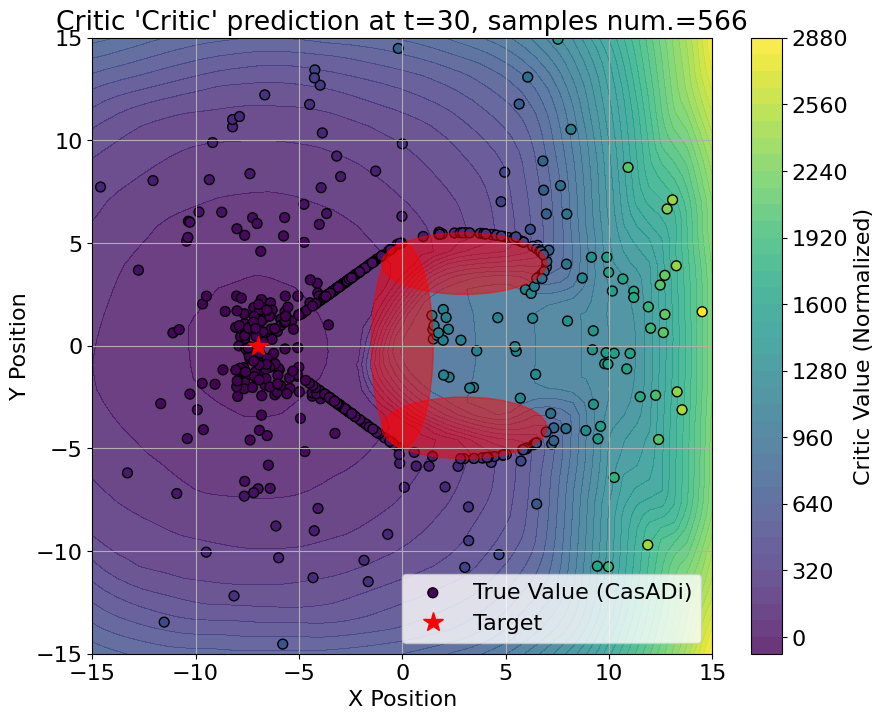

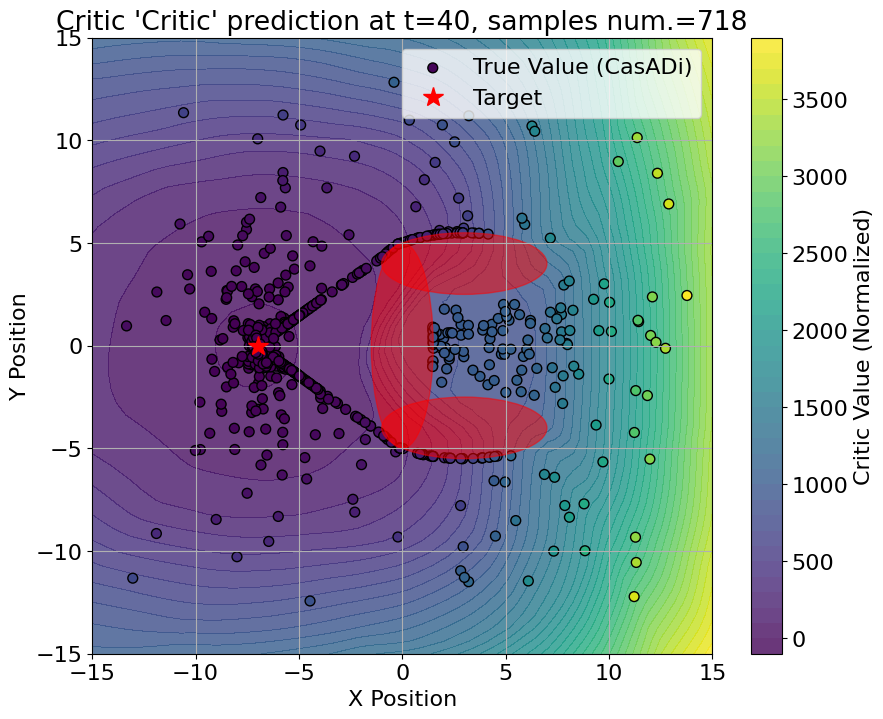

In [80]:
# Train the critic again with the new data in the buffer 
train_critic()

# Update the critic cycles counter
critic_cycles += cycles_counter(replay_buffer, minibatch_size, critic_epochs)
print(f"\nTotal critic cycles: {critic_cycles}")

for t in range(0, N, 10):
  plot_critic(critic, t, show=False)

--- CACTO Iteration 15 ---
--- Start training the constrained actor ---
--- Starting Constrained Actor training for 35 epochs ---
Epoch 1/35 | Mean Q+ALM: 260.1443 | Max Viol: 0.00119 | Lambda: [141.01 147.04 152.82] | Rho: 6618.6 | LR: 0.000500 | step: 98
 | dQ/du norm: 1.486356
Epoch 5/35 | Mean Q+ALM: 259.8380 | Max Viol: 0.00023 | Lambda: [141.65 149.94 156.69] | Rho: 6887.3 | LR: 0.000500 | step: 490
 | dQ/du norm: 1.502293
Epoch 10/35 | Mean Q+ALM: 259.7142 | Max Viol: 0.00023 | Lambda: [143.13 152.51 159.47] | Rho: 7238.6 | LR: 0.000500 | step: 980
 | dQ/du norm: 1.493247
Epoch 15/35 | Mean Q+ALM: 259.8446 | Max Viol: 0.00040 | Lambda: [144.74 155.83 163.4 ] | Rho: 7607.9 | LR: 0.000400 | step: 1470
 | dQ/du norm: 1.485516
Epoch 20/35 | Mean Q+ALM: 259.7465 | Max Viol: 0.00061 | Lambda: [145.66 159.73 166.45] | Rho: 7996.0 | LR: 0.000320 | step: 1960
 | dQ/du norm: 1.484669
Epoch 25/35 | Mean Q+ALM: 259.6121 | Max Viol: 0.00019 | Lambda: [147.59 162.89 169.55] | Rho: 8403.8 | LR

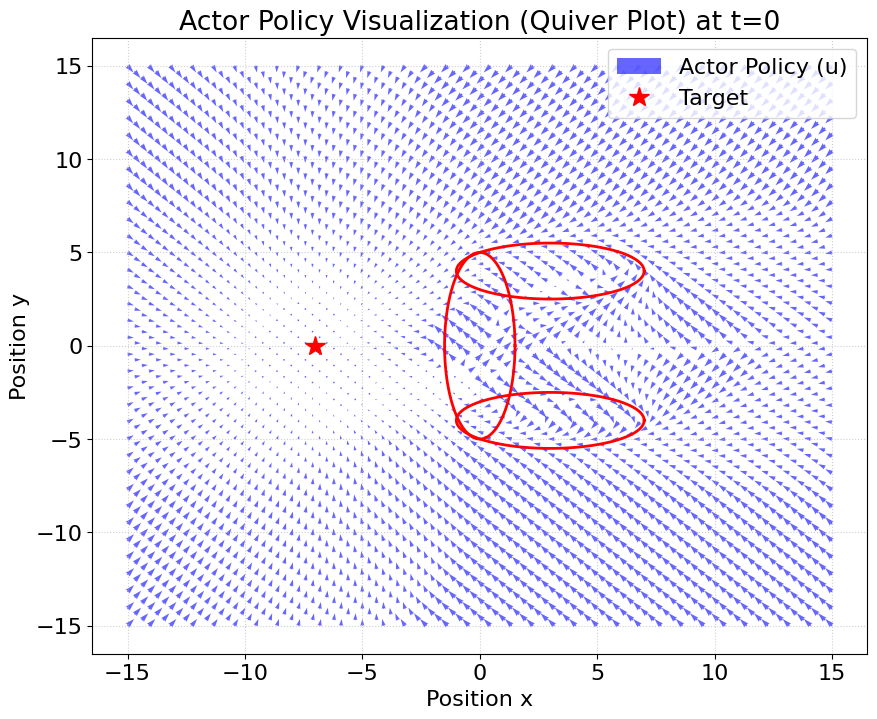

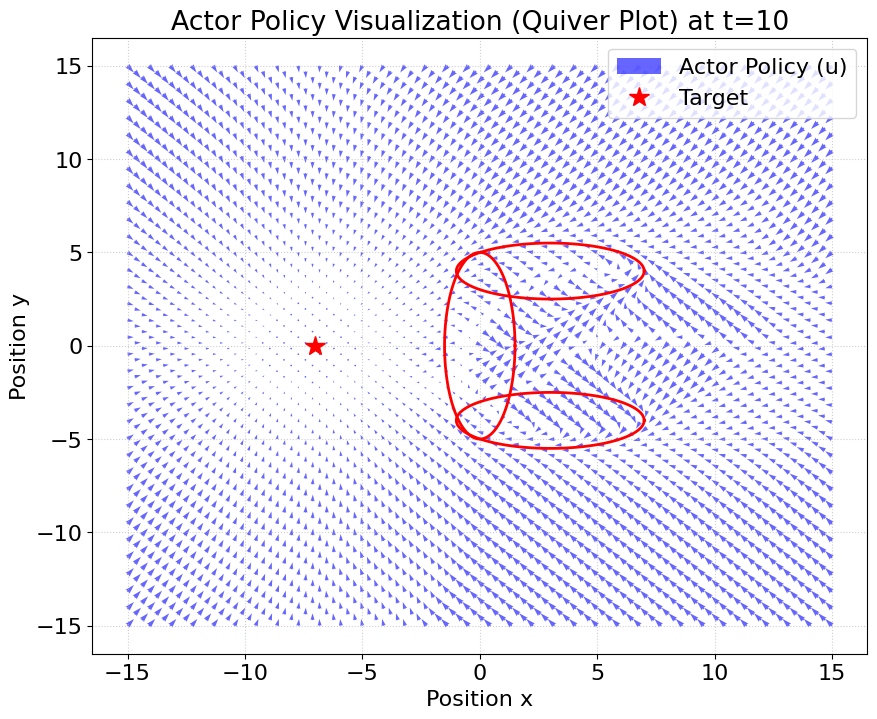

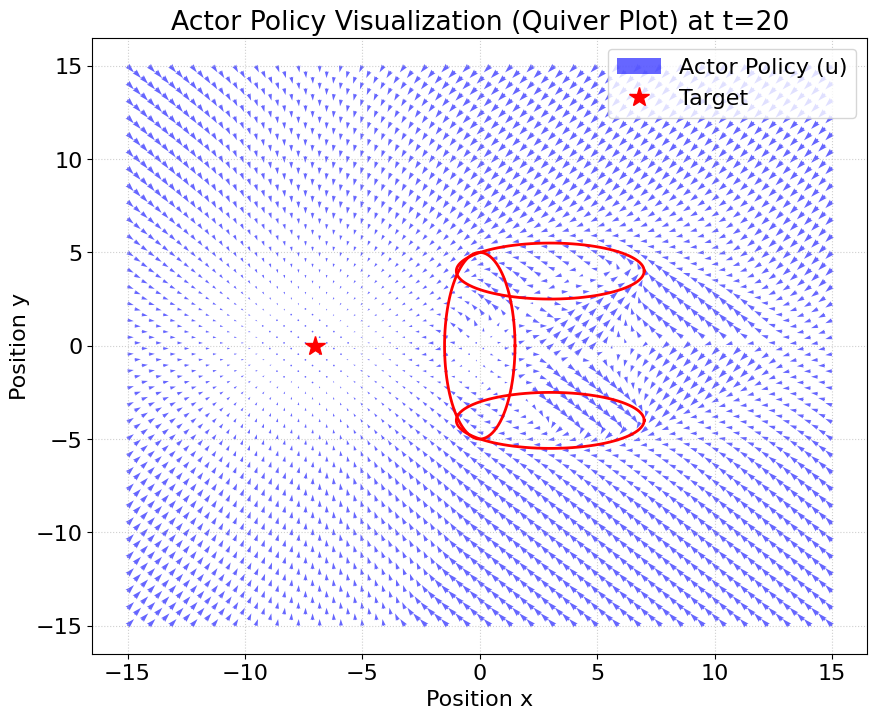

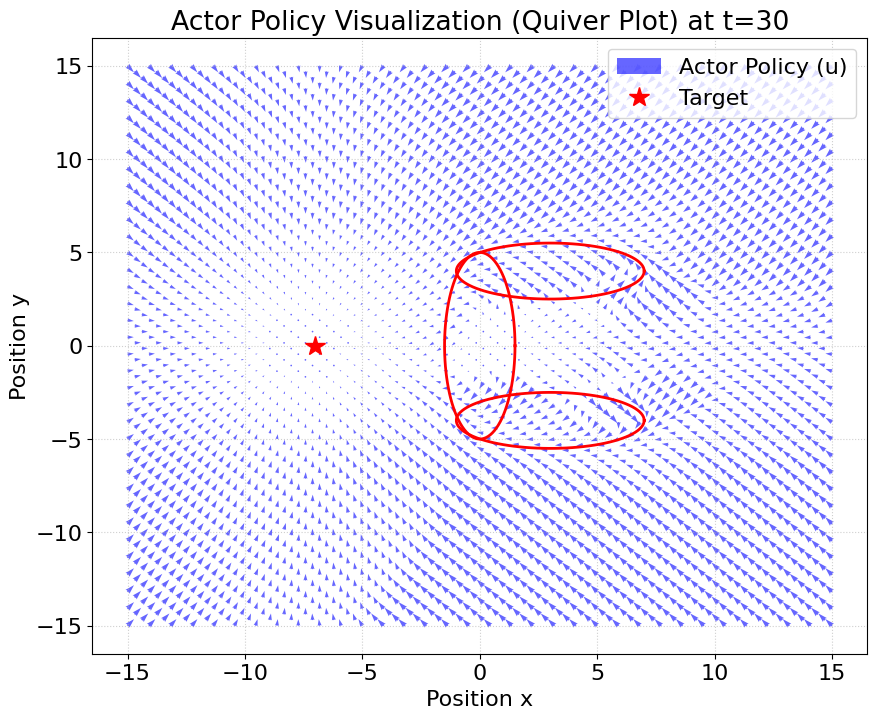

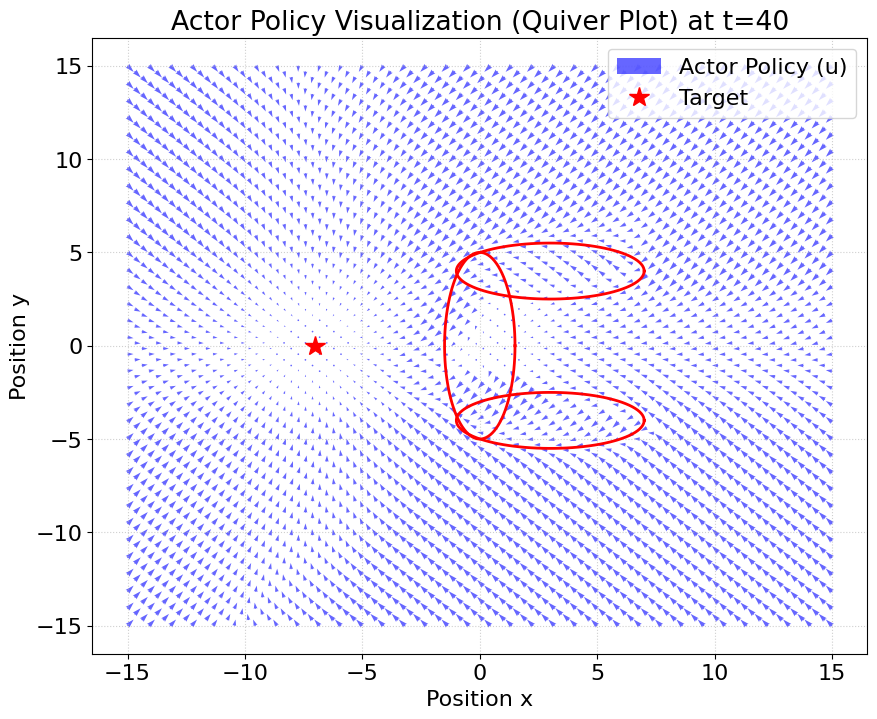

In [81]:
# Train the constrained actor again with the new critic

train_constr_actor()

# Update the constrained actor cycles counter
actor_cycles += cycles_counter(replay_buffer, minibatch_size, actor_epochs)
print(f"\nTotal constrained actor cycles: {actor_cycles}")

for t in range(0, N, 10):
  plot_constr_actor(t, show=True, plot_u_ocp=True)

Actor Only -> Feasible: 26/37 | Violating: 11/37
Actor Only -> Avg. max violation: 0.0085
Actor Only -> Avg. cost: 506.6890

Costs and Feasibility List:
Rollout 001 | Xini: (-10.0, -10.0) | Cost:   126.28 | Status: OK
Rollout 002 | Xini: (-8.0, -5.0) | Cost:    -7.78 | Status: OK
Rollout 003 | Xini: (-10.0,  0.0) | Cost:   -34.26 | Status: OK
Rollout 004 | Xini: (-8.0,  5.0) | Cost:    -7.52 | Status: OK
Rollout 005 | Xini: (-10.0, 10.0) | Cost:   126.25 | Status: OK
Rollout 006 | Xini: ( 5.0,  0.0) | Cost:   611.82 | Status: VIOL
Rollout 007 | Xini: ( 6.0,  1.5) | Cost:   523.98 | Status: OK
Rollout 008 | Xini: ( 6.0, -1.5) | Cost:   519.20 | Status: OK
Rollout 009 | Xini: ( 5.5,  2.5) | Cost:   489.16 | Status: VIOL
Rollout 010 | Xini: ( 5.5, -2.5) | Cost:   478.78 | Status: VIOL
Rollout 011 | Xini: ( 2.0,  0.0) | Cost:   641.10 | Status: OK
Rollout 012 | Xini: ( 1.5,  1.0) | Cost:   654.68 | Status: OK
Rollout 013 | Xini: ( 1.5, -2.0) | Cost:   617.90 | Status: VIOL
Rollout 014 | Xi

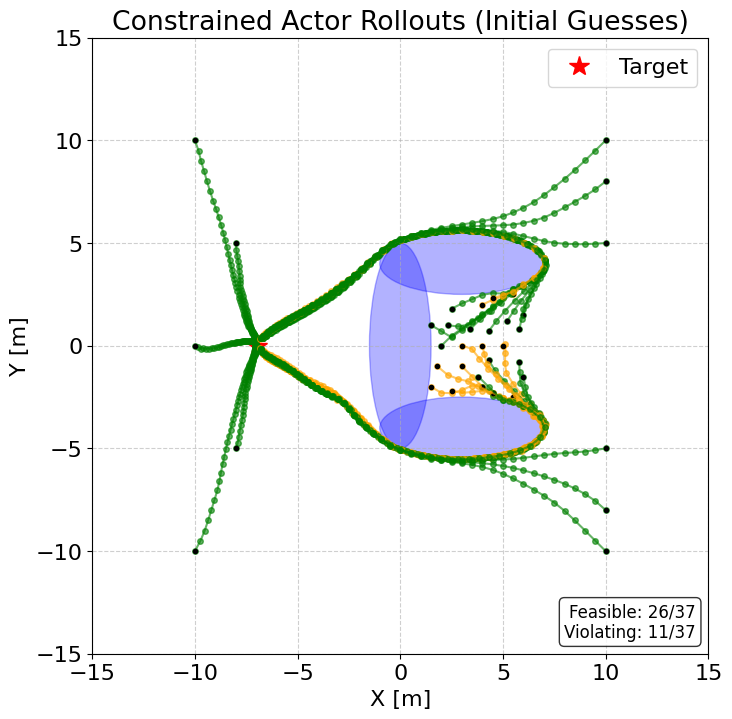

Computing initial guesses in batch...
TO + Warm Start -> Time: 12.008 s
TO + Warm Start -> Feasible: 37/37 | Failed: 0/37


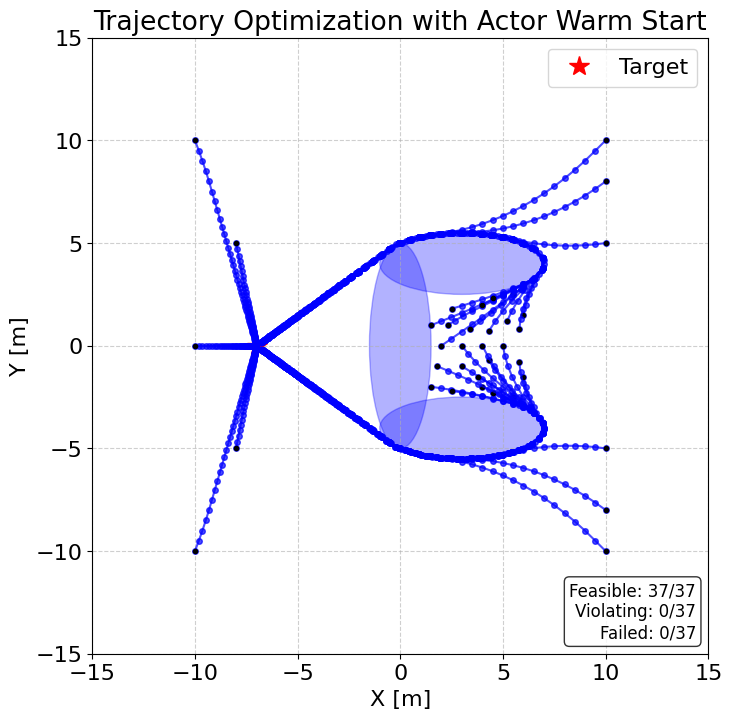

In [82]:
# Final evaluation of the constrained actor rollouts and TO performance after the last iteration
plot_cons_actor_rollouts(print_costs=True)
V_TO, all_cons_x_trajs = evaluate_TO_w_cons_warm_start()

--- CACTO Iteration 16 ---
Start solving 300 TO problems


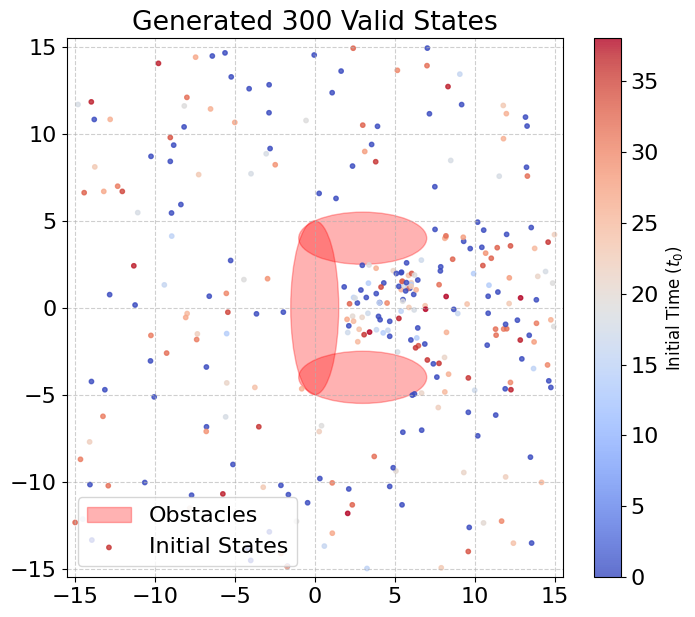

Computing warm start guesses via Actor...


COmputing OCPs: 100%|██████████| 300/300 [01:12<00:00,  4.12traj/s]


--- Finished ---
Successfully solved: 300 / 300
States Buffer size: (25000, 3) samples
Time taken: 75.246 s


In [83]:
# Solve an OCP for every sampled initial state-time using the constrained actor for warm start
solve_TO_problems(use_actor_to_warm_start=True, actor=cons_actor)

--- CACTO Iteration 16 ---
--- Start training critic ---
Replay buffer size: 25000 samples
Epoch 1/35 | MSE: 37.0462 | RMSE: 6.0866 | LR: 0.005000 | step: 98
Epoch 5/35 | MSE: 30.3686 | RMSE: 5.5108 | LR: 0.005000 | step: 490
Epoch 10/35 | MSE: 50.2954 | RMSE: 7.0919 | LR: 0.005000 | step: 980
Epoch 15/35 | MSE: 23.4619 | RMSE: 4.8437 | LR: 0.003750 | step: 1470
Epoch 20/35 | MSE: 25.5555 | RMSE: 5.0552 | LR: 0.002812 | step: 1960
Epoch 25/35 | MSE: 7.1120 | RMSE: 2.6668 | LR: 0.002109 | step: 2450
Epoch 30/35 | MSE: 8.8400 | RMSE: 2.9732 | LR: 0.001582 | step: 2940
Epoch 35/35 | MSE: 5.0043 | RMSE: 2.2370 | LR: 0.001187 | step: 3430
Final Critic MSE: 5.00
Final Critic RMSE: 2.24
--- Critic training has finished ---

Total critic cycles: 52430


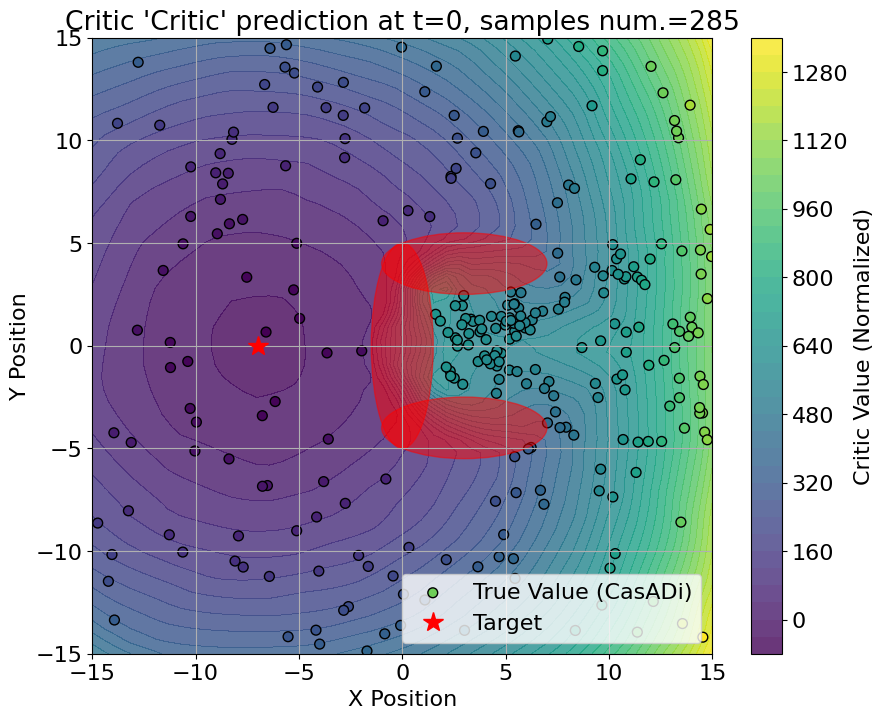

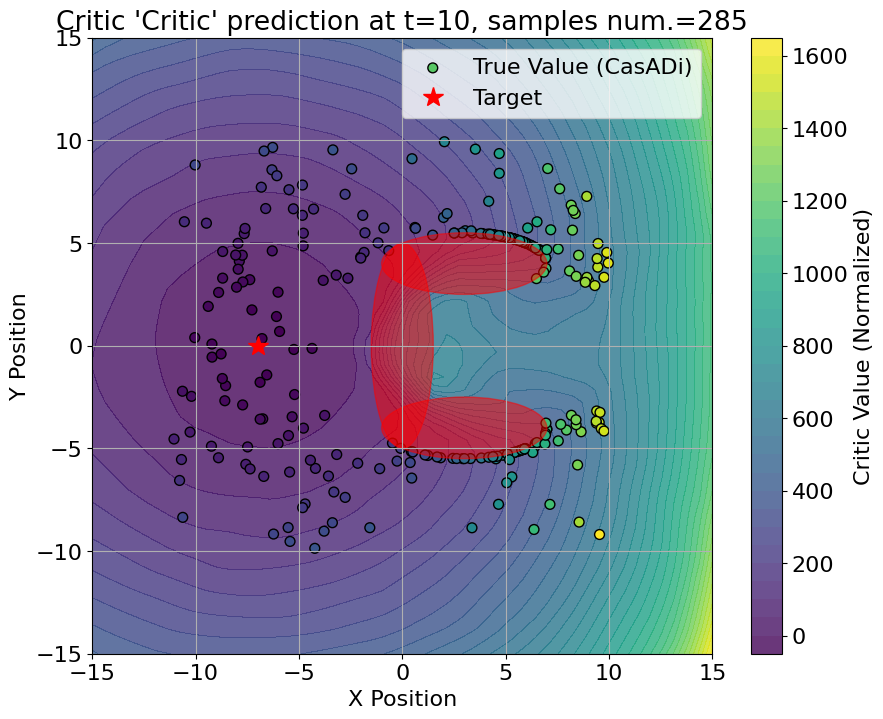

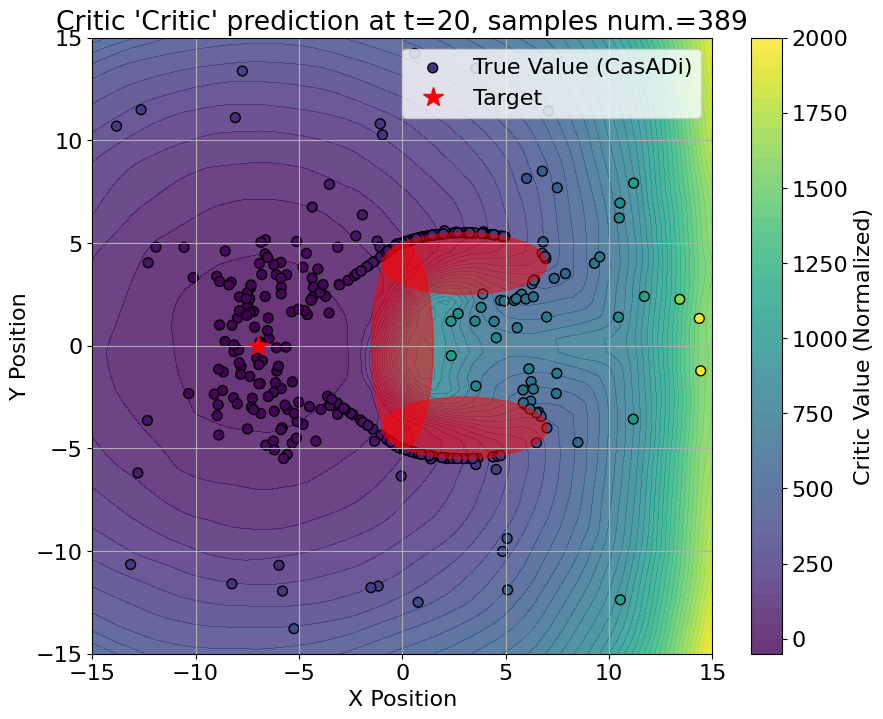

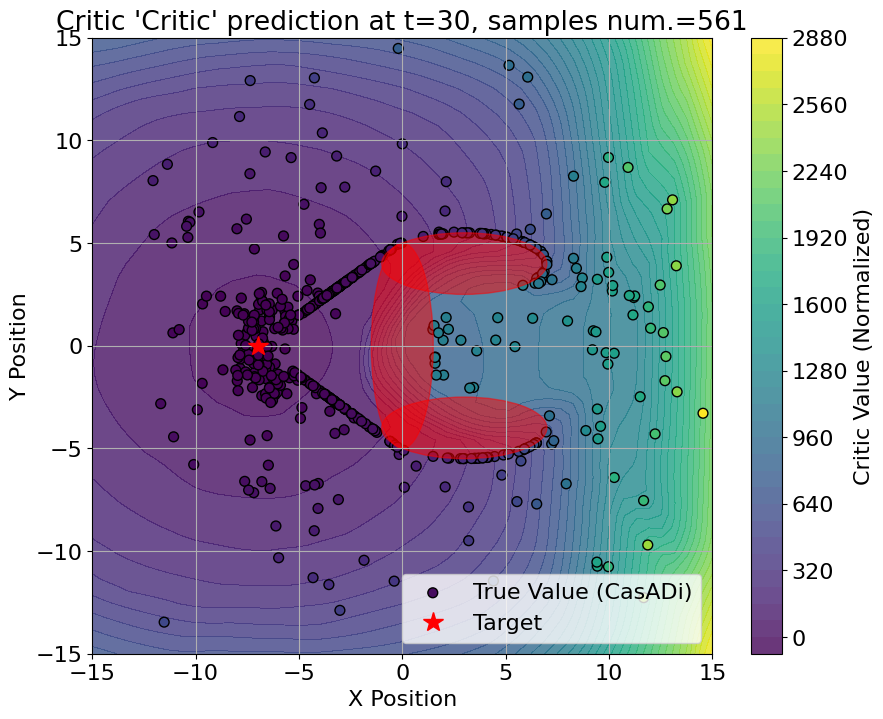

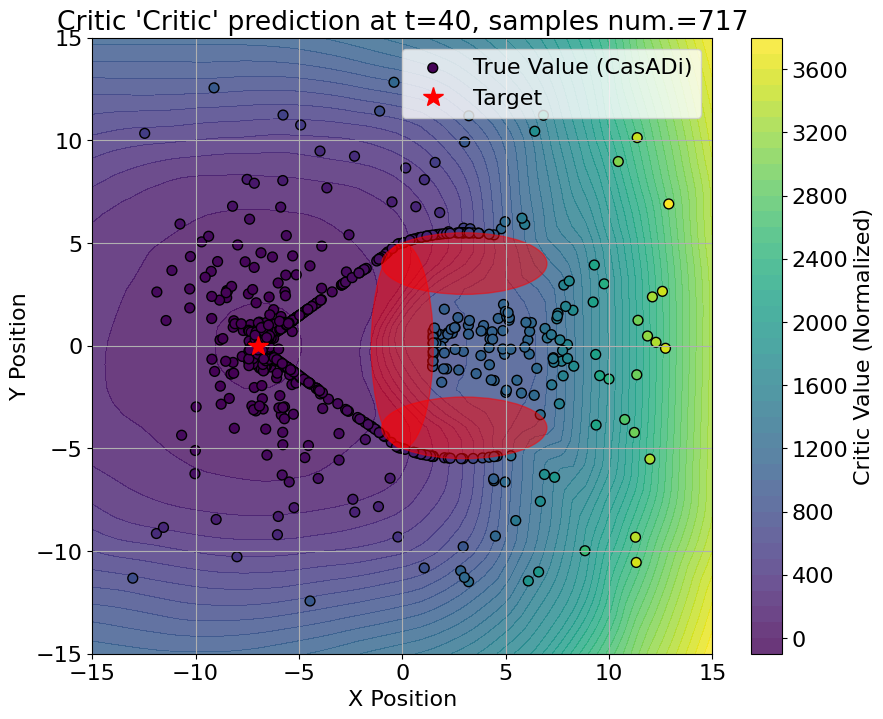

In [84]:
# Train the critic again with the new data in the buffer 
train_critic()

# Update the critic cycles counter
critic_cycles += cycles_counter(replay_buffer, minibatch_size, critic_epochs)
print(f"\nTotal critic cycles: {critic_cycles}")

for t in range(0, N, 10):
  plot_critic(critic, t, show=False)

--- CACTO Iteration 16 ---
--- Start training the constrained actor ---
--- Starting Constrained Actor training for 35 epochs ---
Epoch 1/35 | Mean Q+ALM: 251.0237 | Max Viol: 0.00053 | Lambda: [152.23 167.36 176.71] | Rho: 9375.9 | LR: 0.000500 | step: 98
 | dQ/du norm: 1.460726
Epoch 5/35 | Mean Q+ALM: 251.3385 | Max Viol: 0.00096 | Lambda: [160.19 171.92 181.61] | Rho: 9756.6 | LR: 0.000500 | step: 490
 | dQ/du norm: 1.479279
Epoch 10/35 | Mean Q+ALM: 251.3705 | Max Viol: 0.00089 | Lambda: [166.01 178.29 185.63] | Rho: 10254.3 | LR: 0.000500 | step: 980
 | dQ/du norm: 1.484462
Epoch 15/35 | Mean Q+ALM: 250.9286 | Max Viol: 0.00012 | Lambda: [169.91 182.81 189.04] | Rho: 10777.3 | LR: 0.000400 | step: 1470
 | dQ/du norm: 1.470543
Epoch 20/35 | Mean Q+ALM: 250.8334 | Max Viol: 0.00017 | Lambda: [170.62 186.53 191.81] | Rho: 11215.0 | LR: 0.000320 | step: 1960
 | dQ/du norm: 1.465063
Epoch 25/35 | Mean Q+ALM: 250.7638 | Max Viol: 0.00010 | Lambda: [171.53 189.63 194.47] | Rho: 11670.3 

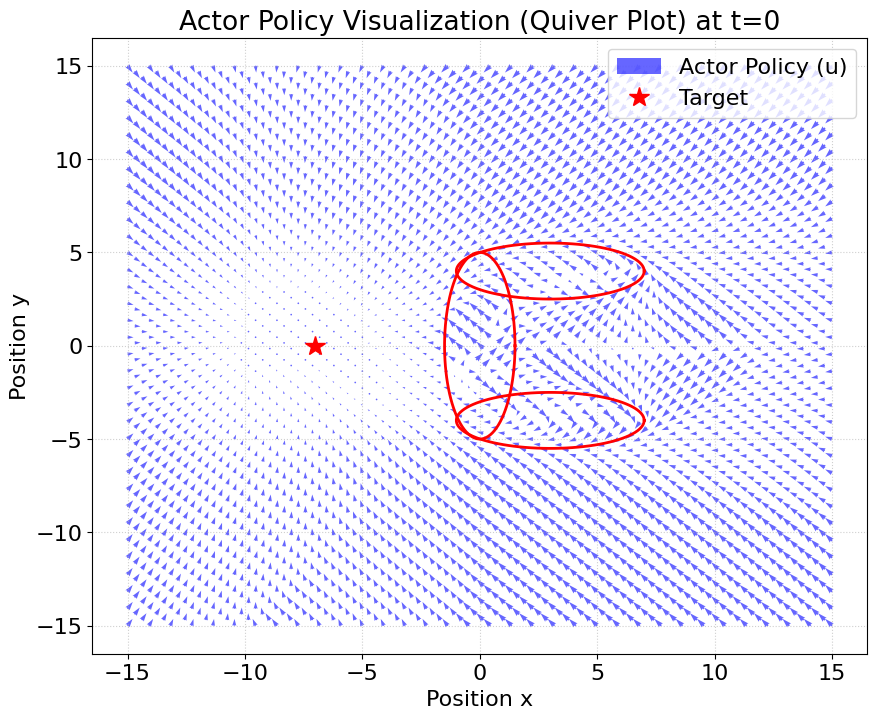

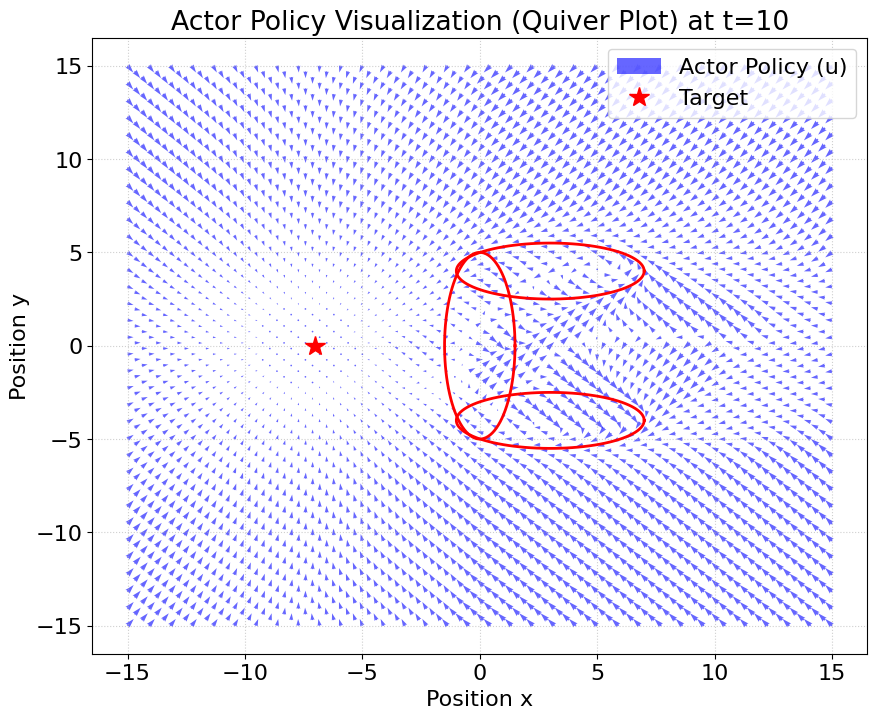

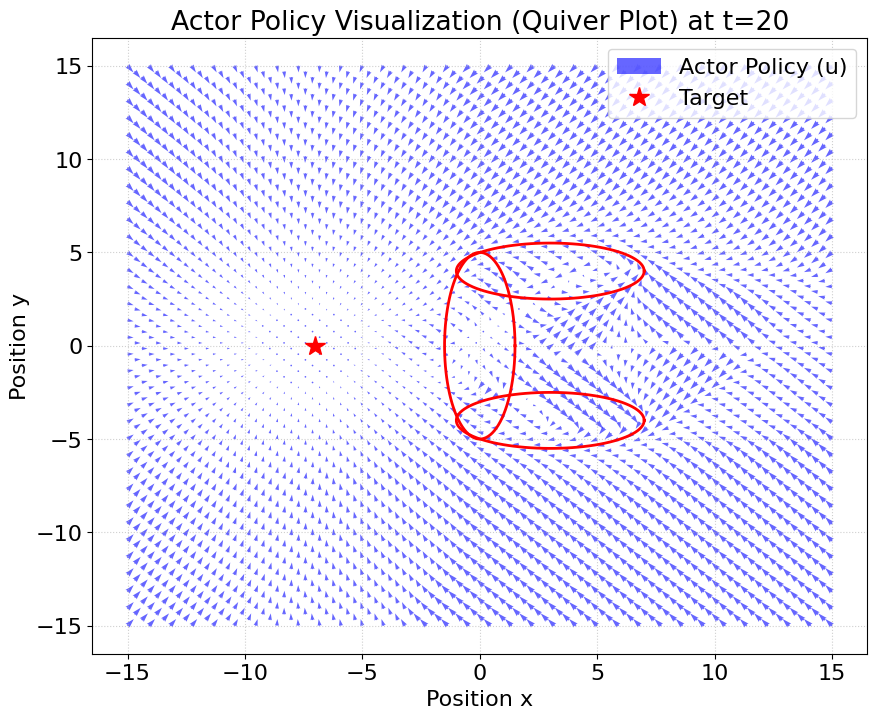

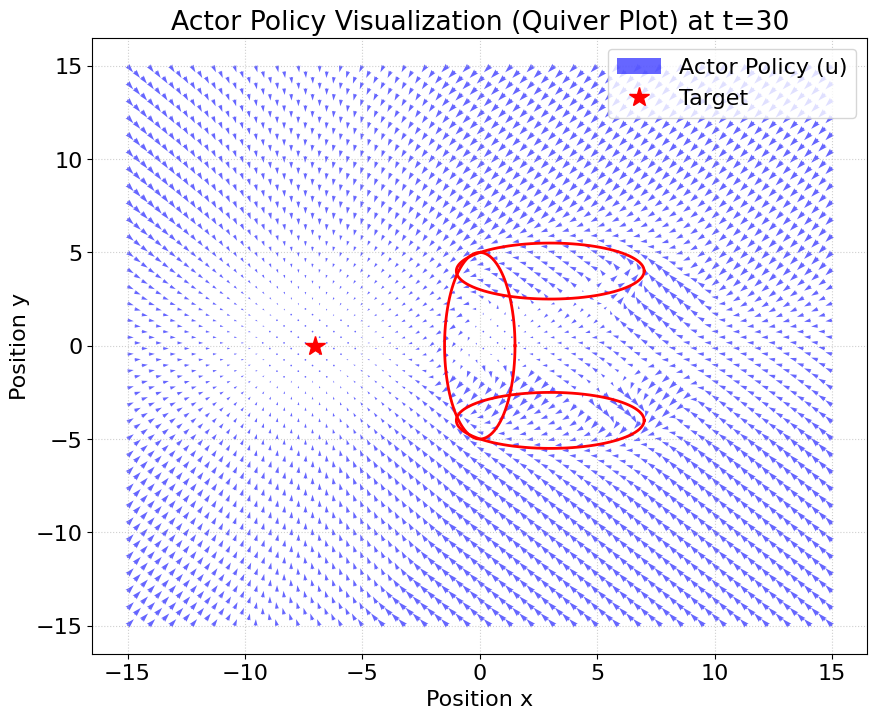

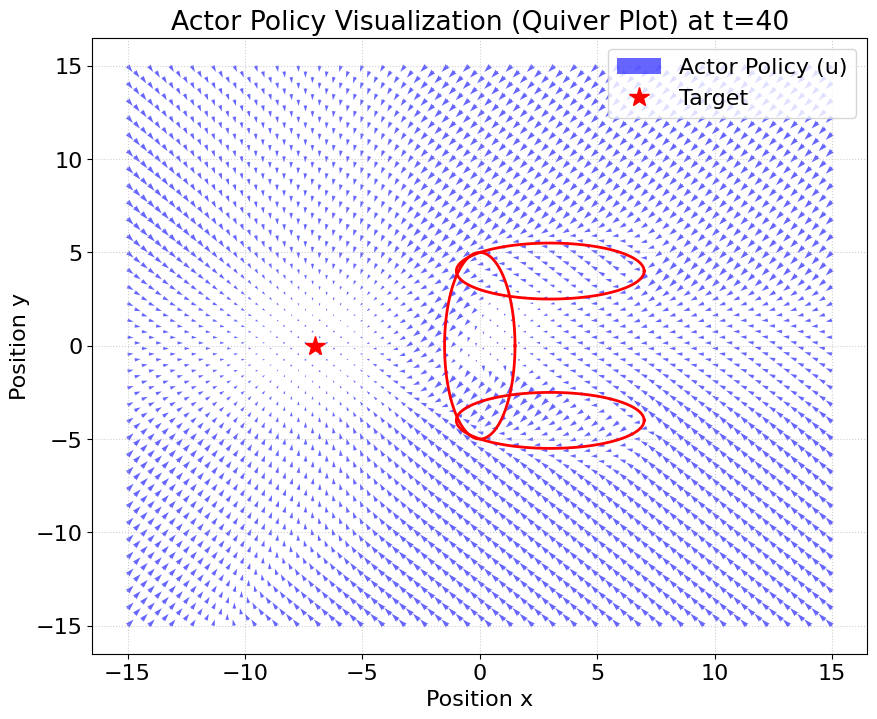

In [85]:
# Train the constrained actor again with the new critic

train_constr_actor()

# Update the constrained actor cycles counter
actor_cycles += cycles_counter(replay_buffer, minibatch_size, actor_epochs)
print(f"\nTotal constrained actor cycles: {actor_cycles}")

for t in range(0, N, 10):
  plot_constr_actor(t, show=True, plot_u_ocp=True)

Actor Only -> Feasible: 29/37 | Violating: 8/37
Actor Only -> Avg. max violation: 0.0042
Actor Only -> Avg. cost: 508.2379

Costs and Feasibility List:
Rollout 001 | Xini: (-10.0, -10.0) | Cost:   126.29 | Status: OK
Rollout 002 | Xini: (-8.0, -5.0) | Cost:    -7.70 | Status: OK
Rollout 003 | Xini: (-10.0,  0.0) | Cost:   -34.41 | Status: OK
Rollout 004 | Xini: (-8.0,  5.0) | Cost:    -7.10 | Status: OK
Rollout 005 | Xini: (-10.0, 10.0) | Cost:   126.84 | Status: OK
Rollout 006 | Xini: ( 5.0,  0.0) | Cost:   637.53 | Status: OK
Rollout 007 | Xini: ( 6.0,  1.5) | Cost:   520.09 | Status: OK
Rollout 008 | Xini: ( 6.0, -1.5) | Cost:   521.45 | Status: OK
Rollout 009 | Xini: ( 5.5,  2.5) | Cost:   491.83 | Status: OK
Rollout 010 | Xini: ( 5.5, -2.5) | Cost:   479.45 | Status: VIOL
Rollout 011 | Xini: ( 2.0,  0.0) | Cost:   636.37 | Status: VIOL
Rollout 012 | Xini: ( 1.5,  1.0) | Cost:   637.75 | Status: VIOL
Rollout 013 | Xini: ( 1.5, -2.0) | Cost:   640.36 | Status: OK
Rollout 014 | Xini:

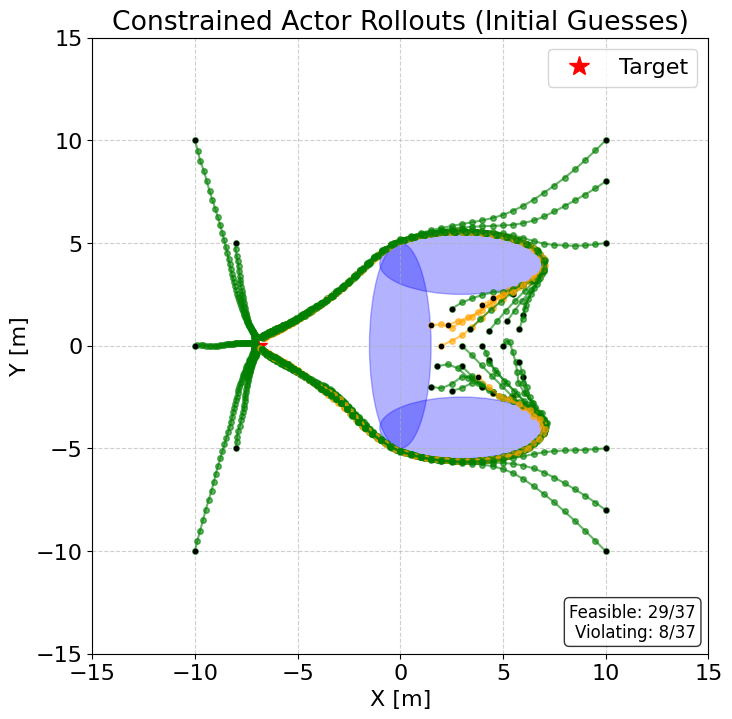

Computing initial guesses in batch...
TO + Warm Start -> Time: 11.880 s
TO + Warm Start -> Feasible: 37/37 | Failed: 0/37


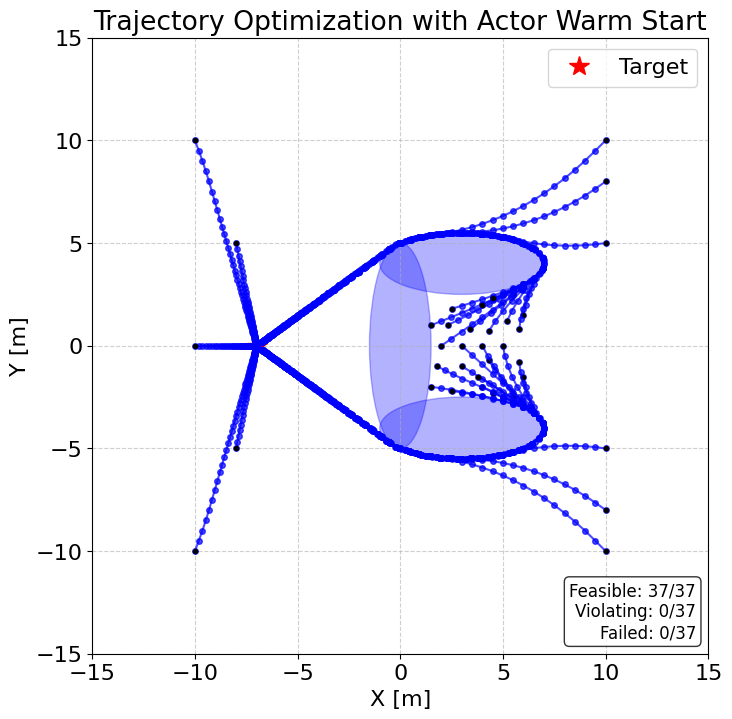

In [86]:
# Final evaluation of the constrained actor rollouts and TO performance after the last iteration
plot_cons_actor_rollouts(print_costs=True)
V_TO, all_cons_x_trajs = evaluate_TO_w_cons_warm_start()

--- CACTO Iteration 17 ---
Start solving 300 TO problems


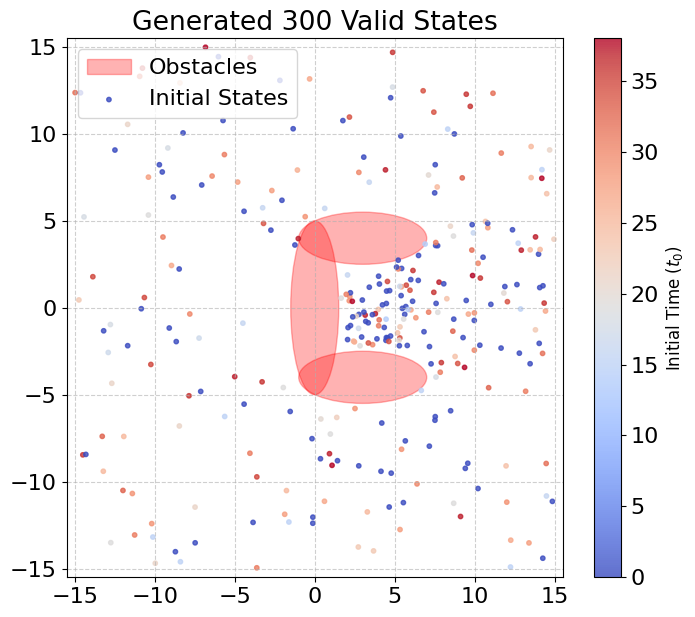

Computing warm start guesses via Actor...


COmputing OCPs: 100%|██████████| 300/300 [01:15<00:00,  3.98traj/s]


--- Finished ---
Successfully solved: 300 / 300
States Buffer size: (25000, 3) samples
Time taken: 77.778 s


In [87]:
# Solve an OCP for every sampled initial state-time using the constrained actor for warm start
solve_TO_problems(use_actor_to_warm_start=True, actor=cons_actor)

--- CACTO Iteration 17 ---
--- Start training critic ---
Replay buffer size: 25000 samples
Epoch 1/35 | MSE: 59.0032 | RMSE: 7.6814 | LR: 0.005000 | step: 98
Epoch 5/35 | MSE: 59.1294 | RMSE: 7.6896 | LR: 0.005000 | step: 490
Epoch 10/35 | MSE: 166.3290 | RMSE: 12.8969 | LR: 0.005000 | step: 980
Epoch 15/35 | MSE: 76.1425 | RMSE: 8.7260 | LR: 0.003750 | step: 1470
Epoch 20/35 | MSE: 15.3440 | RMSE: 3.9171 | LR: 0.002812 | step: 1960
Epoch 25/35 | MSE: 8.5948 | RMSE: 2.9317 | LR: 0.002109 | step: 2450
Epoch 30/35 | MSE: 8.7012 | RMSE: 2.9498 | LR: 0.001582 | step: 2940
Epoch 35/35 | MSE: 5.4243 | RMSE: 2.3290 | LR: 0.001187 | step: 3430
Final Critic MSE: 5.42
Final Critic RMSE: 2.33
--- Critic training has finished ---

Total critic cycles: 55860


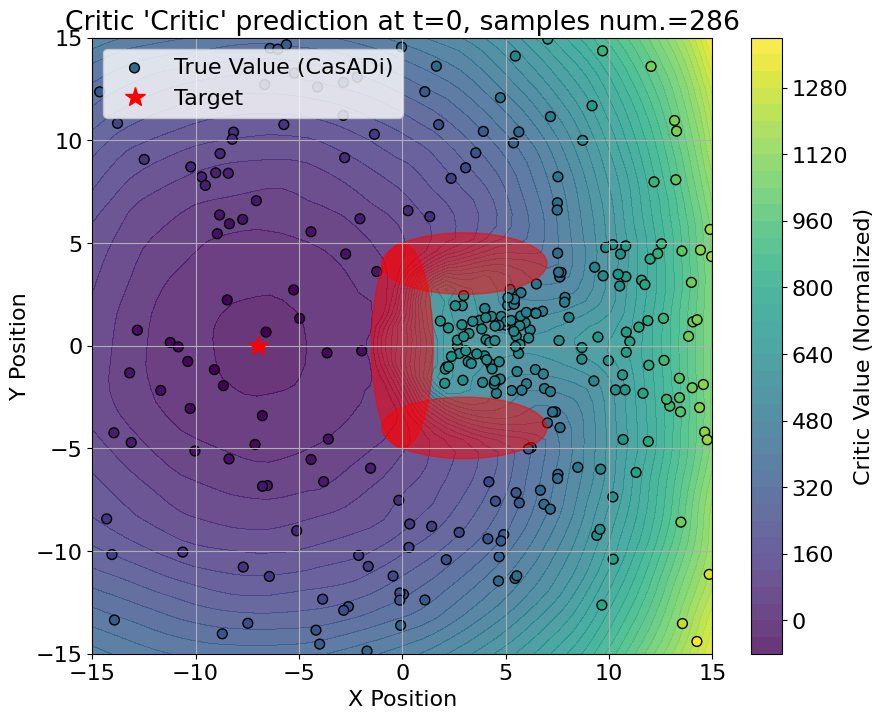

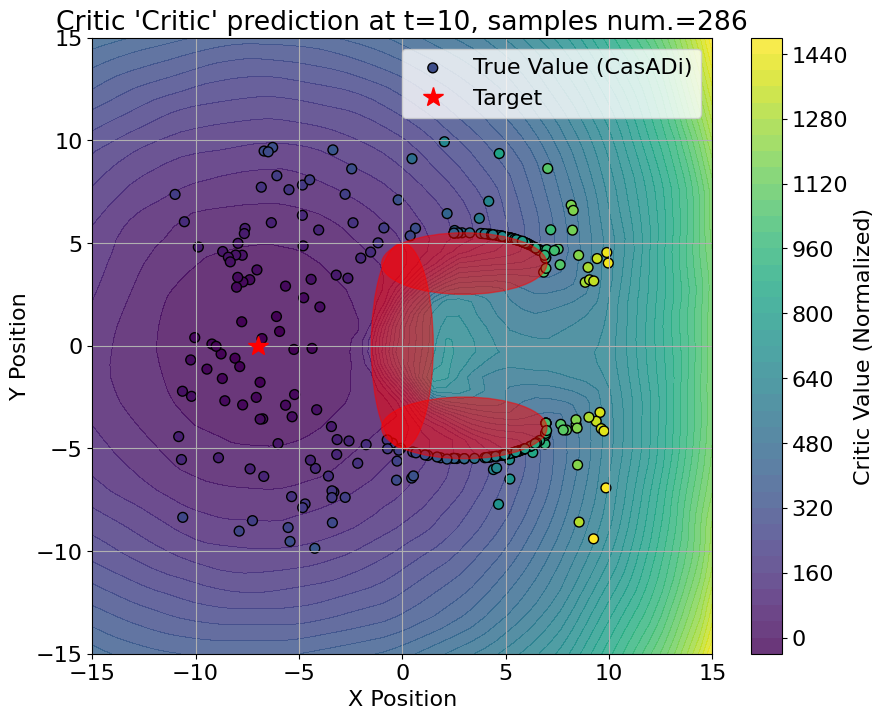

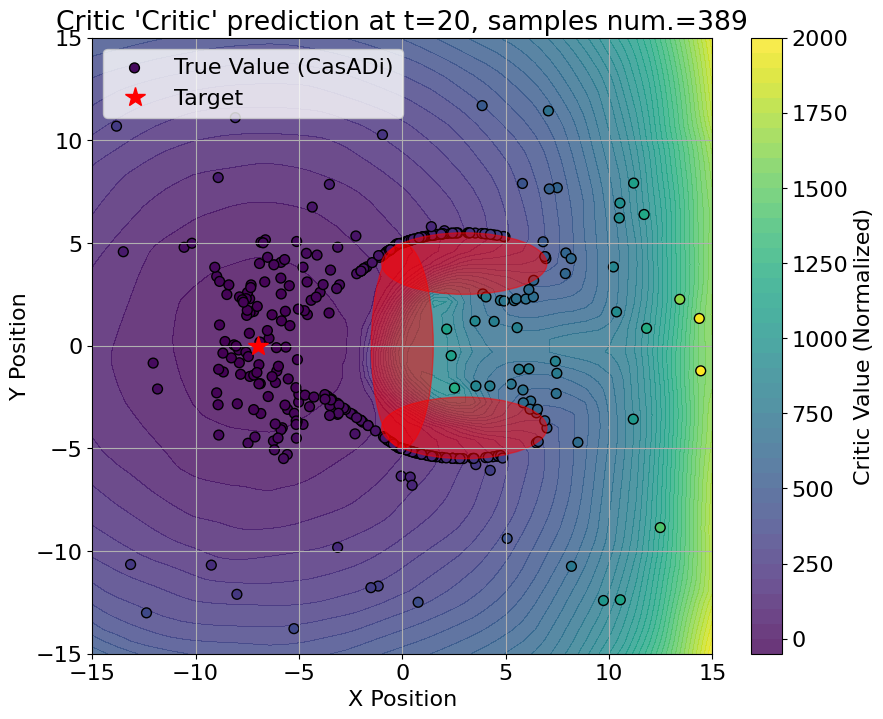

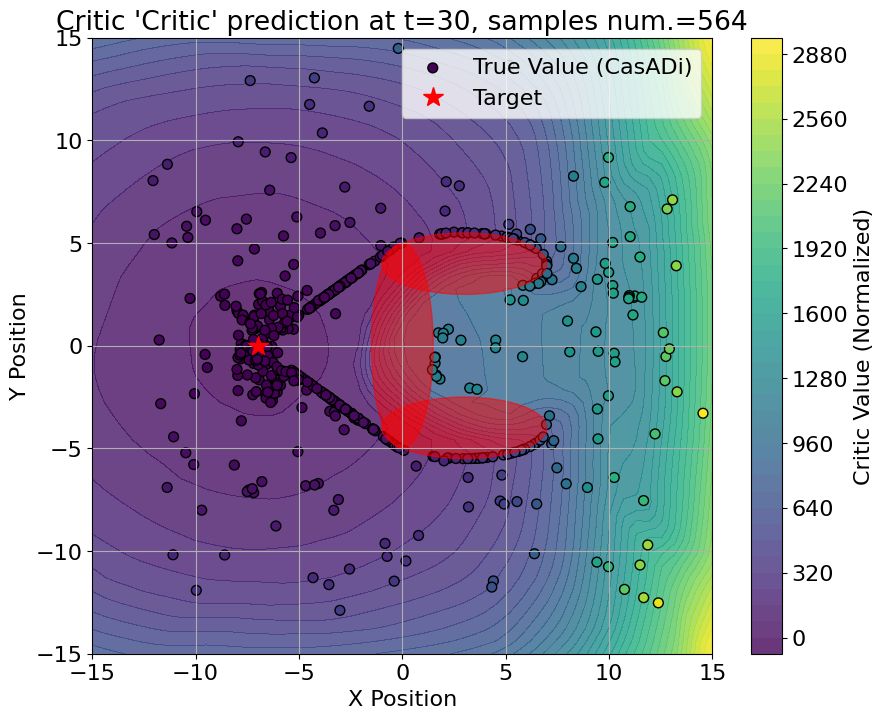

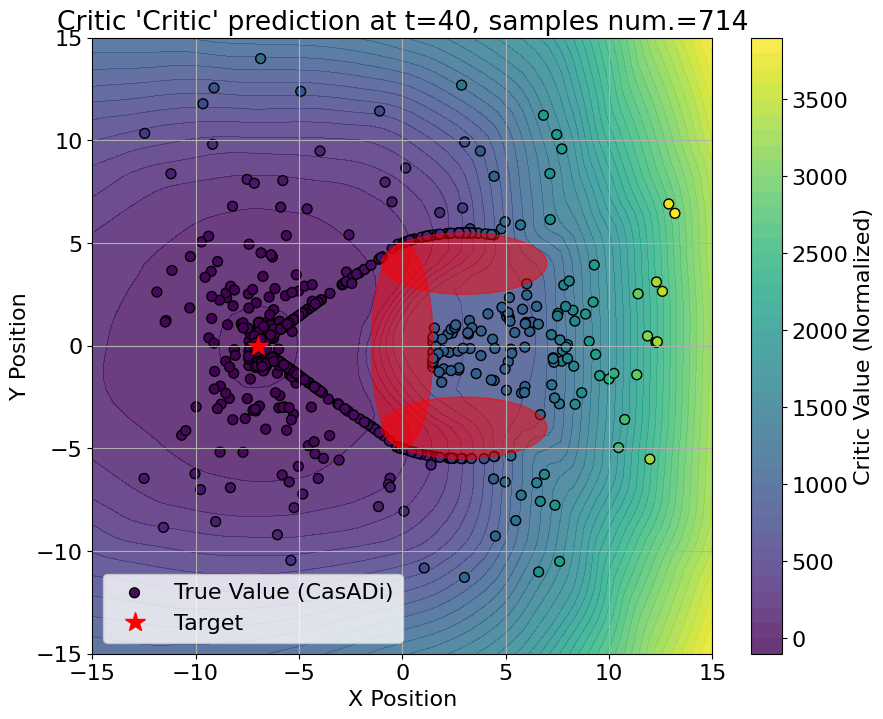

In [88]:
# Train the critic again with the new data in the buffer 
train_critic()

# Update the critic cycles counter
critic_cycles += cycles_counter(replay_buffer, minibatch_size, critic_epochs)
print(f"\nTotal critic cycles: {critic_cycles}")

for t in range(0, N, 10):
  plot_critic(critic, t, show=False)

--- CACTO Iteration 17 ---
--- Start training the constrained actor ---
--- Starting Constrained Actor training for 35 epochs ---
Epoch 1/35 | Mean Q+ALM: 250.1448 | Max Viol: 0.00023 | Lambda: [176.74 194.17 202.47] | Rho: 12891.3 | LR: 0.000500 | step: 98
 | dQ/du norm: 1.458803
Epoch 5/35 | Mean Q+ALM: 250.1529 | Max Viol: 0.00038 | Lambda: [179.97 200.09 205.78] | Rho: 13414.7 | LR: 0.000500 | step: 490
 | dQ/du norm: 1.463023
Epoch 10/35 | Mean Q+ALM: 250.1220 | Max Viol: 0.00015 | Lambda: [180.72 203.38 208.81] | Rho: 13821.2 | LR: 0.000500 | step: 980
 | dQ/du norm: 1.462182
Epoch 15/35 | Mean Q+ALM: 250.1821 | Max Viol: 0.00040 | Lambda: [184.47 208.62 211.4 ] | Rho: 14382.4 | LR: 0.000400 | step: 1470
 | dQ/du norm: 1.449267
Epoch 20/35 | Mean Q+ALM: 249.9358 | Max Viol: 0.00024 | Lambda: [187.25 213.86 216.32] | Rho: 14966.4 | LR: 0.000320 | step: 1960
 | dQ/du norm: 1.437420
Epoch 25/35 | Mean Q+ALM: 249.9118 | Max Viol: 0.00014 | Lambda: [190.25 216.4  219.  ] | Rho: 15574.

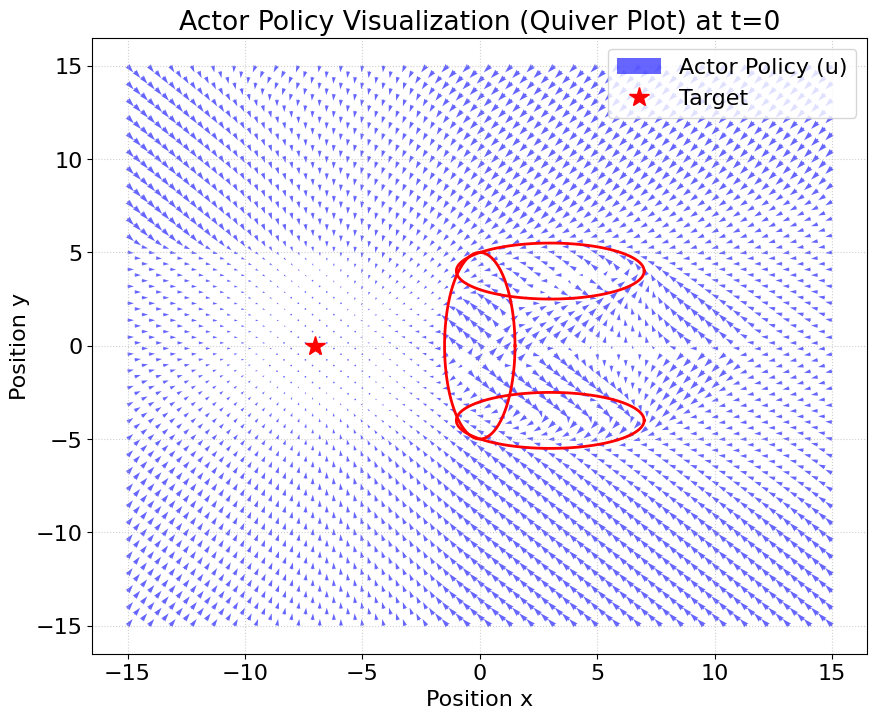

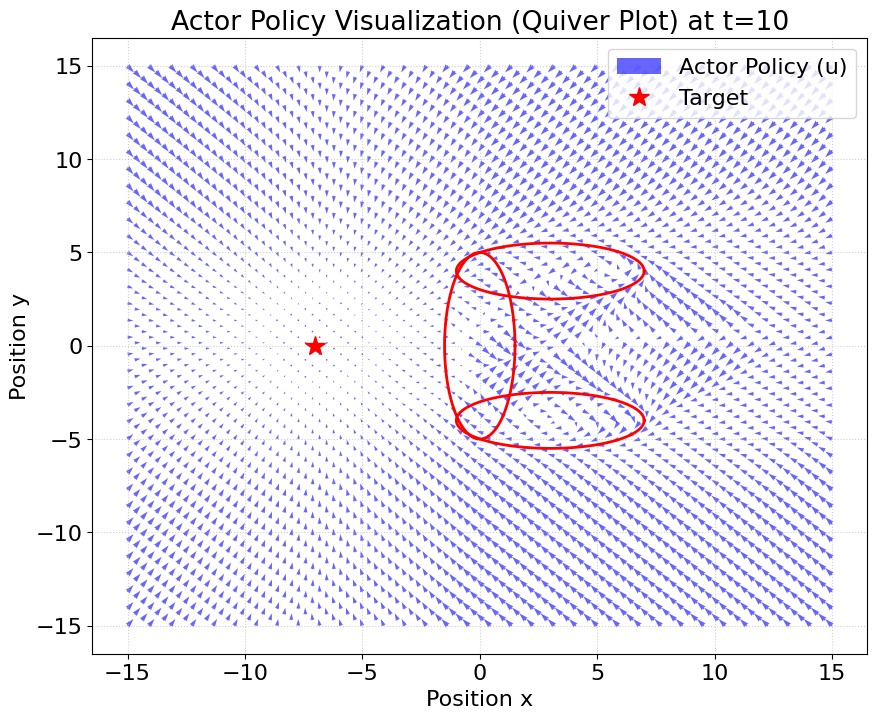

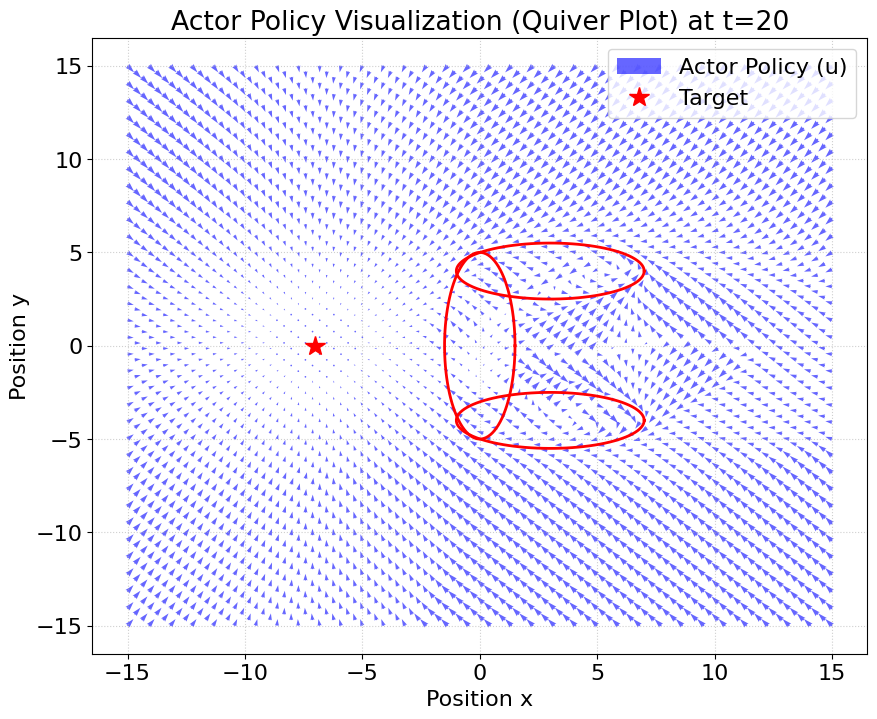

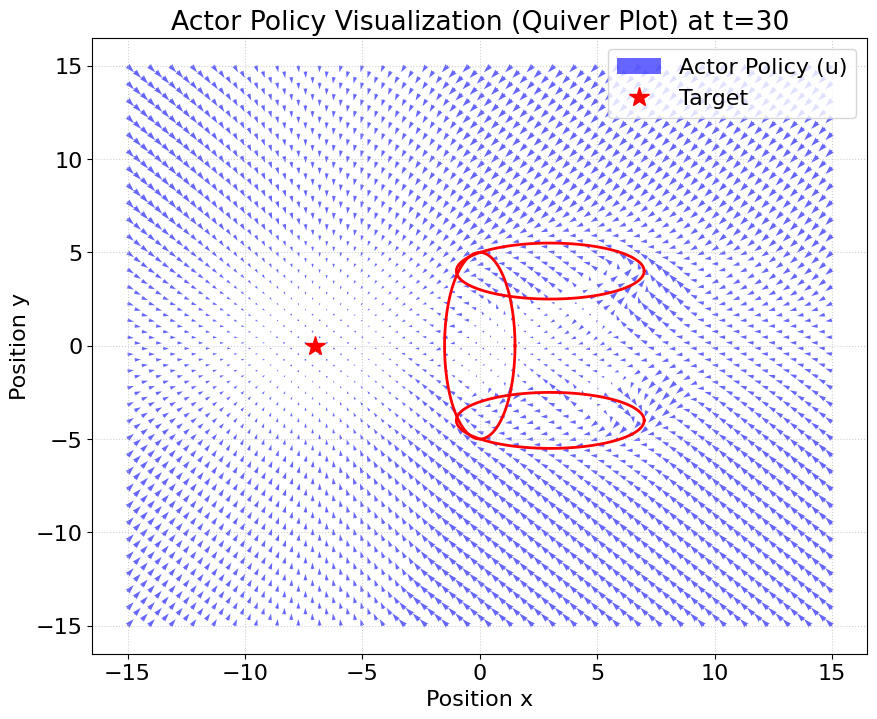

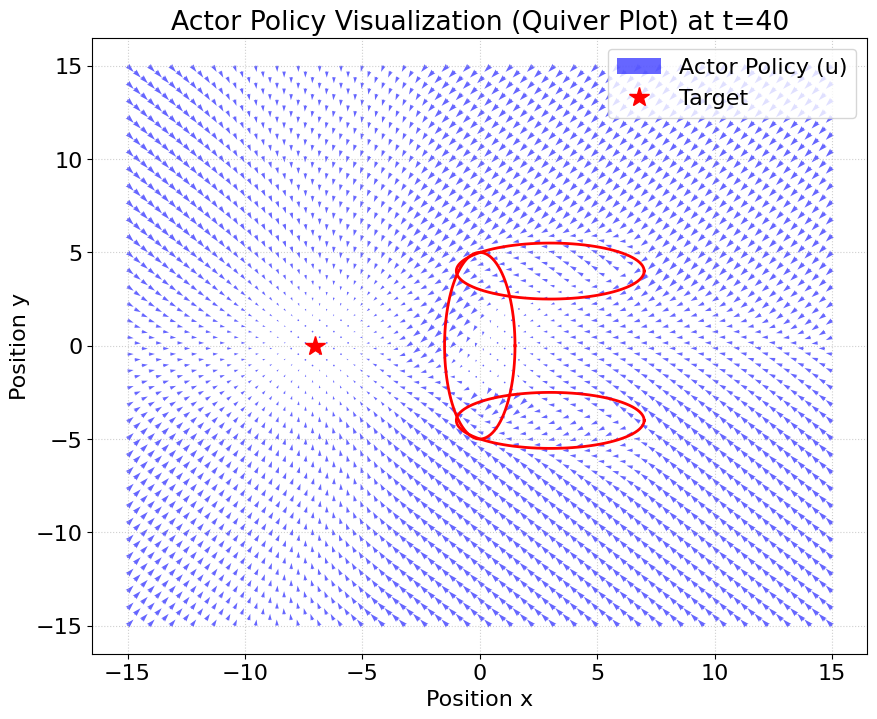

In [89]:
# Train the constrained actor again with the new critic

train_constr_actor()

# Update the constrained actor cycles counter
actor_cycles += cycles_counter(replay_buffer, minibatch_size, actor_epochs)
print(f"\nTotal constrained actor cycles: {actor_cycles}")

for t in range(0, N, 10):
  plot_constr_actor(t, show=True, plot_u_ocp=True)

Actor Only -> Feasible: 26/37 | Violating: 11/37
Actor Only -> Avg. max violation: 0.0548
Actor Only -> Avg. cost: 490.9443

Costs and Feasibility List:
Rollout 001 | Xini: (-10.0, -10.0) | Cost:   126.94 | Status: OK
Rollout 002 | Xini: (-8.0, -5.0) | Cost:    -7.49 | Status: OK
Rollout 003 | Xini: (-10.0,  0.0) | Cost:   -34.41 | Status: OK
Rollout 004 | Xini: (-8.0,  5.0) | Cost:    -7.54 | Status: OK
Rollout 005 | Xini: (-10.0, 10.0) | Cost:   126.62 | Status: OK
Rollout 006 | Xini: ( 5.0,  0.0) | Cost:   593.94 | Status: OK
Rollout 007 | Xini: ( 6.0,  1.5) | Cost:   523.16 | Status: OK
Rollout 008 | Xini: ( 6.0, -1.5) | Cost:   519.72 | Status: VIOL
Rollout 009 | Xini: ( 5.5,  2.5) | Cost:   486.82 | Status: VIOL
Rollout 010 | Xini: ( 5.5, -2.5) | Cost:   473.47 | Status: VIOL
Rollout 011 | Xini: ( 2.0,  0.0) | Cost:   642.20 | Status: OK
Rollout 012 | Xini: ( 1.5,  1.0) | Cost:   641.03 | Status: OK
Rollout 013 | Xini: ( 1.5, -2.0) | Cost:   296.92 | Status: VIOL
Rollout 014 | Xi

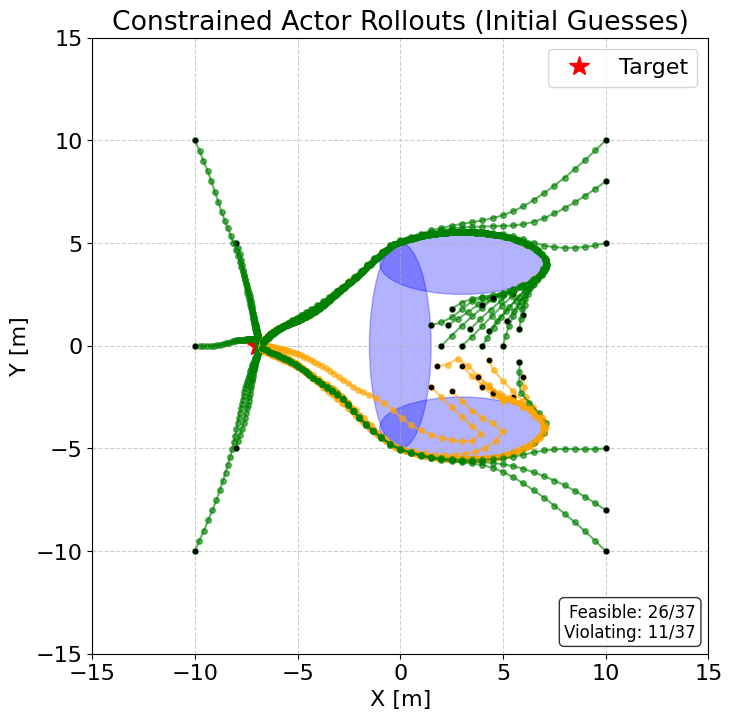

Computing initial guesses in batch...
Skip i=12: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
Skip i=24: OCP failed | Error: Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'
TO + Warm Start -> Time: 12.511 s
TO + Warm Start -> Feasible: 35/37 | Failed: 2/37


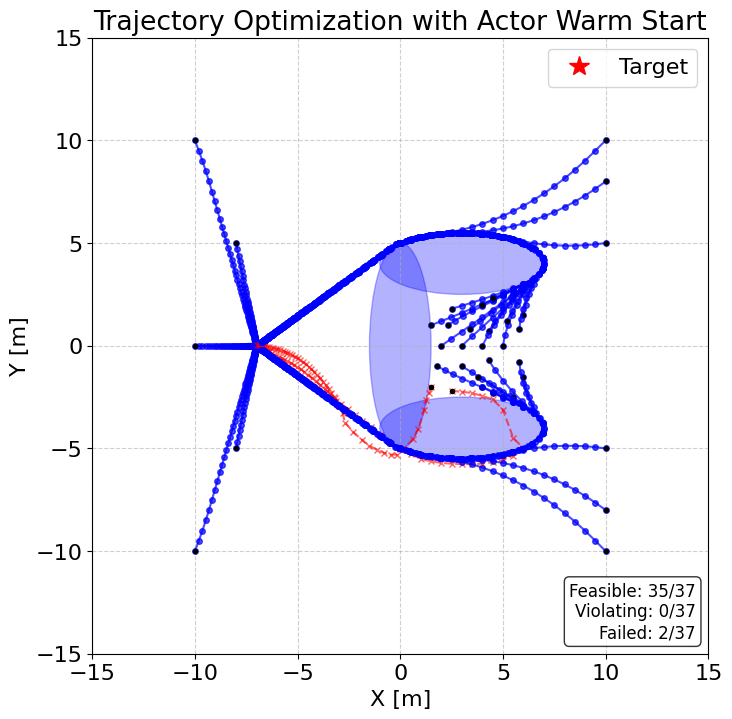

In [90]:
# Final evaluation of the constrained actor rollouts and TO performance after the last iteration
plot_cons_actor_rollouts(print_costs=True)
V_TO, all_cons_x_trajs = evaluate_TO_w_cons_warm_start()

--- CACTO Iteration 18 ---
Start solving 300 TO problems


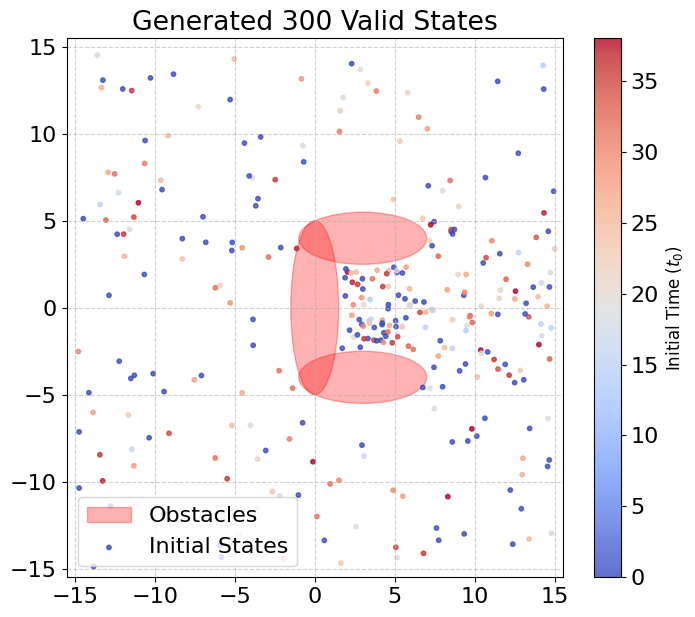

Computing warm start guesses via Actor...


COmputing OCPs: 100%|██████████| 300/300 [01:14<00:00,  4.03traj/s]


--- Finished ---
Successfully solved: 300 / 300
States Buffer size: (25000, 3) samples
Time taken: 76.864 s


In [91]:
# Solve an OCP for every sampled initial state-time using the constrained actor for warm start
solve_TO_problems(use_actor_to_warm_start=True, actor=cons_actor)

--- CACTO Iteration 18 ---
--- Start training critic ---
Replay buffer size: 25000 samples
Epoch 1/35 | MSE: 32.2167 | RMSE: 5.6760 | LR: 0.005000 | step: 98
Epoch 5/35 | MSE: 94.0186 | RMSE: 9.6963 | LR: 0.005000 | step: 490
Epoch 10/35 | MSE: 20.2978 | RMSE: 4.5053 | LR: 0.005000 | step: 980
Epoch 15/35 | MSE: 34.5351 | RMSE: 5.8767 | LR: 0.003750 | step: 1470
Epoch 20/35 | MSE: 22.3993 | RMSE: 4.7328 | LR: 0.002812 | step: 1960
Epoch 25/35 | MSE: 14.5567 | RMSE: 3.8153 | LR: 0.002109 | step: 2450
Epoch 30/35 | MSE: 7.2803 | RMSE: 2.6982 | LR: 0.001582 | step: 2940
Epoch 35/35 | MSE: 6.1557 | RMSE: 2.4811 | LR: 0.001187 | step: 3430
Final Critic MSE: 6.16
Final Critic RMSE: 2.48
--- Critic training has finished ---

Total critic cycles: 59290


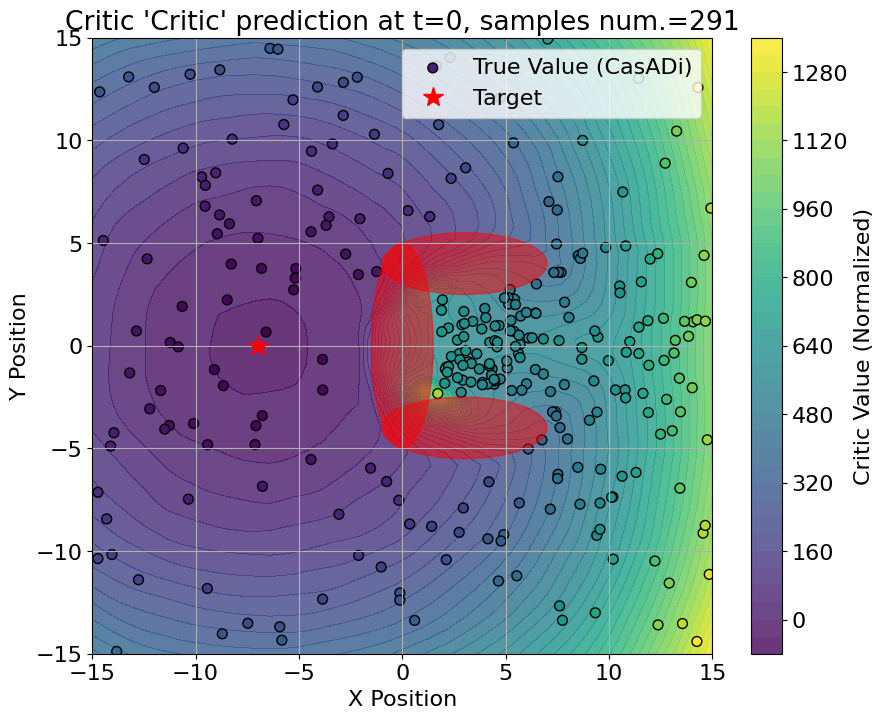

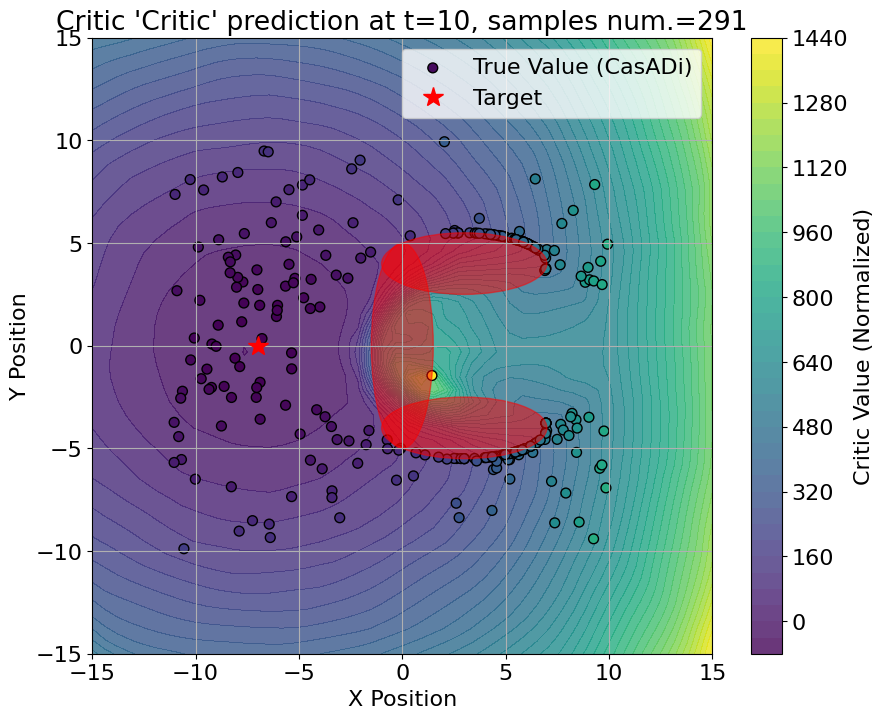

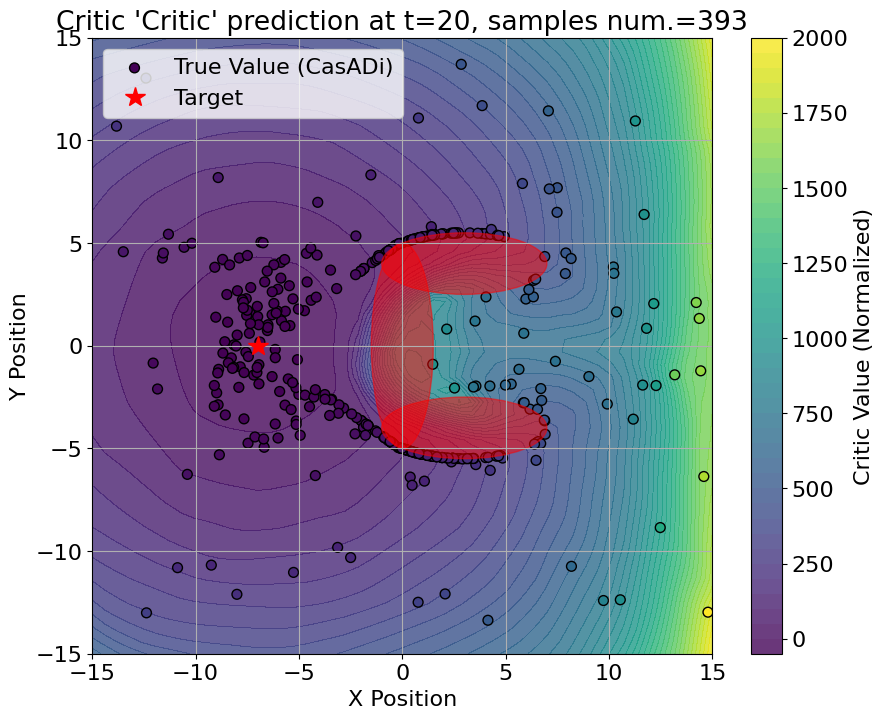

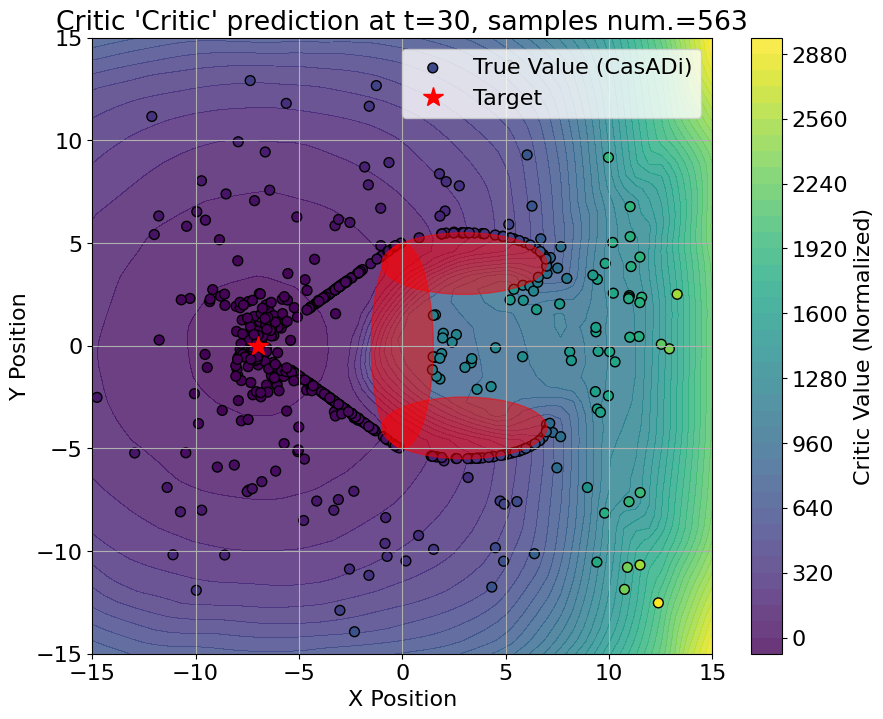

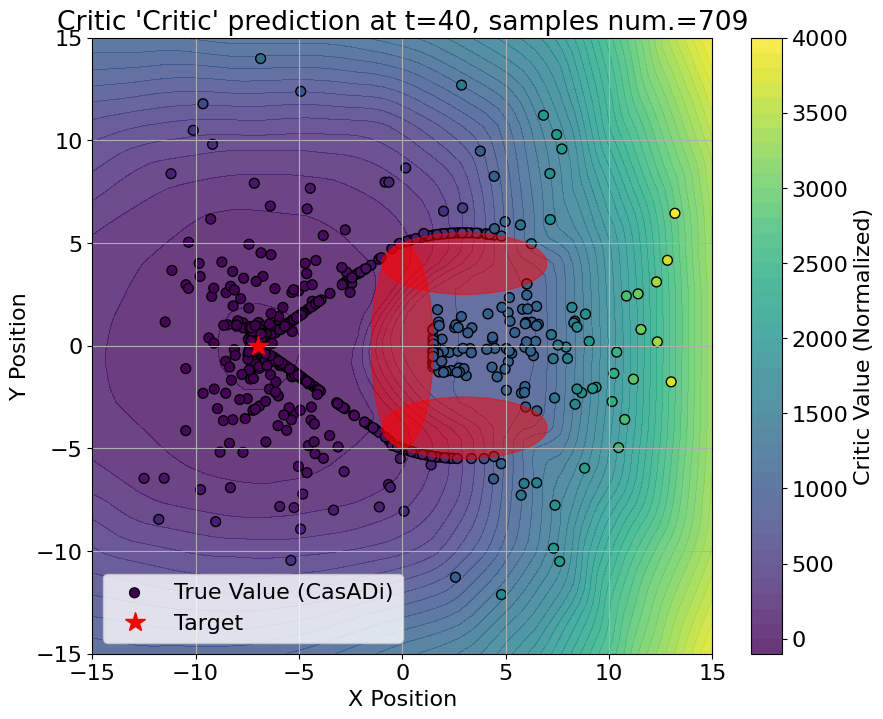

In [92]:
# Train the critic again with the new data in the buffer 
train_critic()

# Update the critic cycles counter
critic_cycles += cycles_counter(replay_buffer, minibatch_size, critic_epochs)
print(f"\nTotal critic cycles: {critic_cycles}")

for t in range(0, N, 10):
  plot_critic(critic, t, show=False)

--- CACTO Iteration 18 ---
--- Start training the constrained actor ---
--- Starting Constrained Actor training for 35 epochs ---
Epoch 1/35 | Mean Q+ALM: 242.3761 | Max Viol: 0.00010 | Lambda: [192.53 222.71 224.02] | Rho: 16206.5 | LR: 0.000500 | step: 98
 | dQ/du norm: 1.350352
Epoch 5/35 | Mean Q+ALM: 242.3795 | Max Viol: 0.00013 | Lambda: [198.7  226.63 228.09] | Rho: 16864.5 | LR: 0.000500 | step: 490
 | dQ/du norm: 1.338152
Epoch 10/35 | Mean Q+ALM: 242.3170 | Max Viol: 0.00016 | Lambda: [199.57 229.09 230.05] | Rho: 17033.2 | LR: 0.000500 | step: 980
 | dQ/du norm: 1.339331
Epoch 15/35 | Mean Q+ALM: 242.2191 | Max Viol: 0.00007 | Lambda: [200.54 231.03 233.52] | Rho: 17375.5 | LR: 0.000400 | step: 1470
 | dQ/du norm: 1.327664
Epoch 20/35 | Mean Q+ALM: 242.1620 | Max Viol: 0.00009 | Lambda: [202.41 233.48 236.4 ] | Rho: 17724.8 | LR: 0.000320 | step: 1960
 | dQ/du norm: 1.323176
Epoch 25/35 | Mean Q+ALM: 242.1622 | Max Viol: 0.00010 | Lambda: [205.75 236.6  238.27] | Rho: 18444.

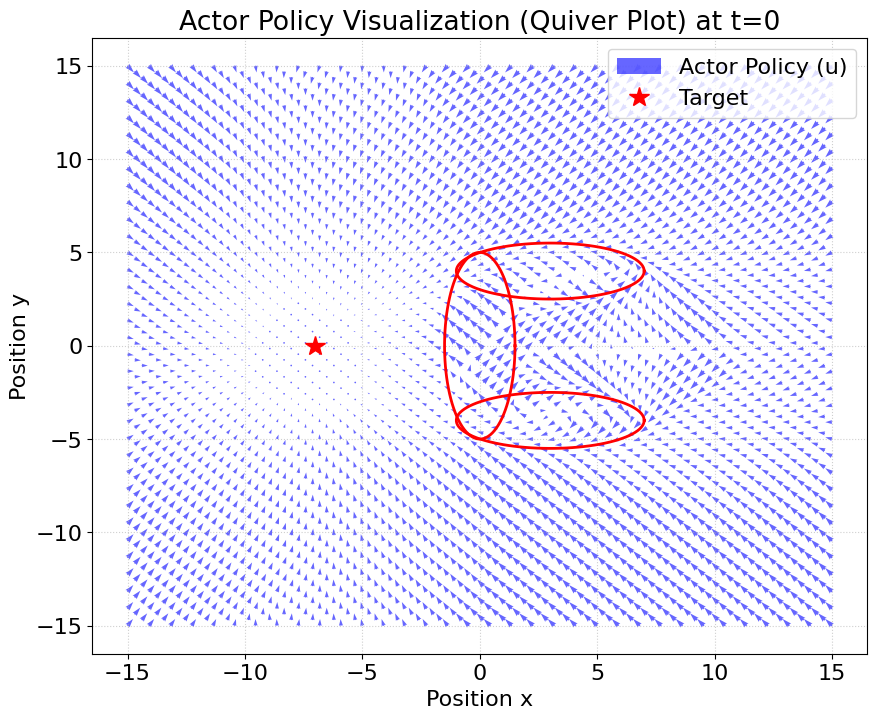

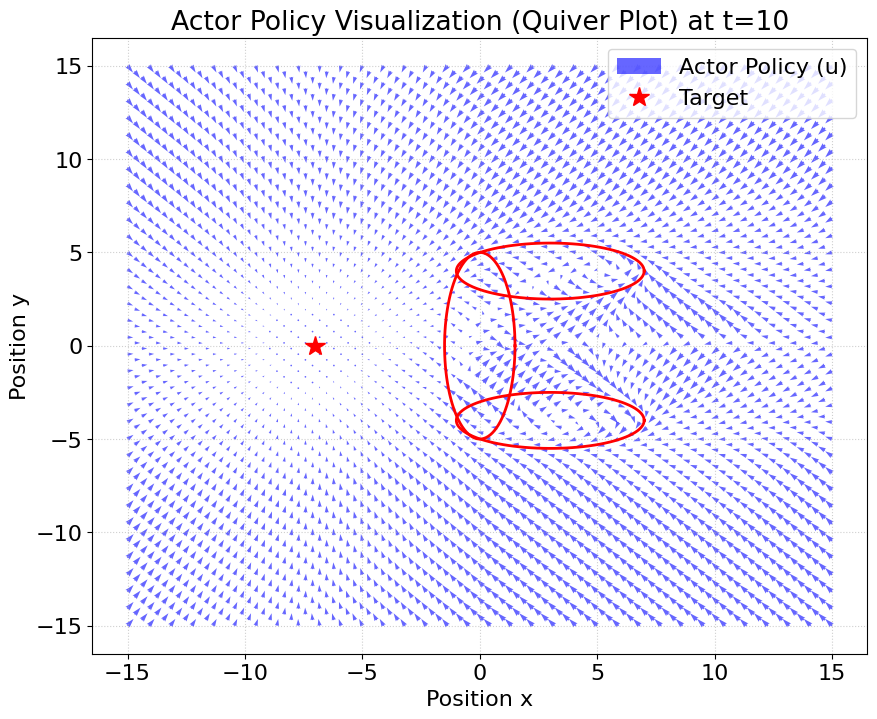

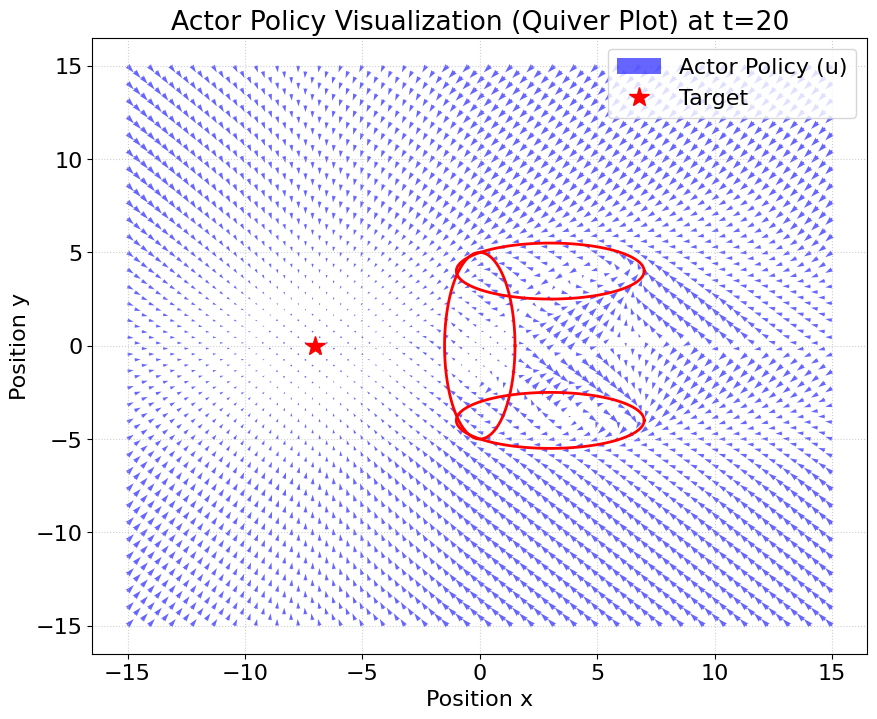

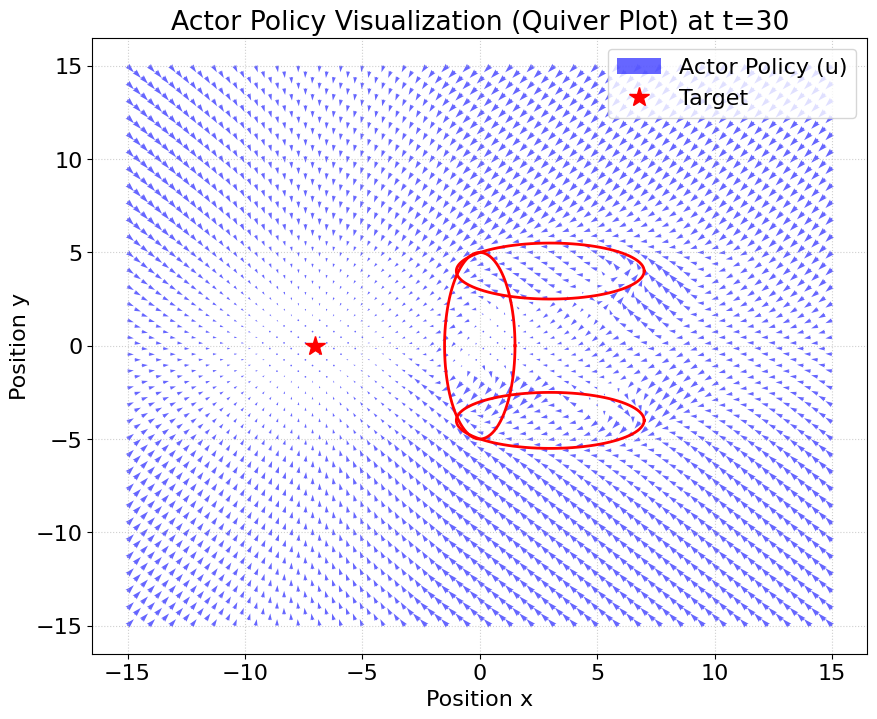

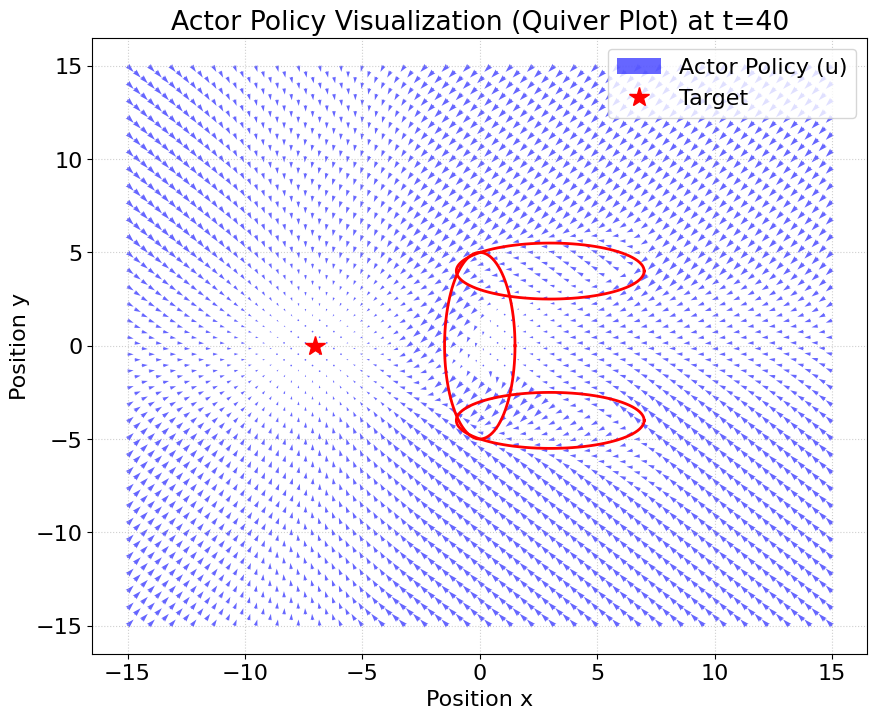

In [93]:
# Train the constrained actor again with the new critic

train_constr_actor()

# Update the constrained actor cycles counter
actor_cycles += cycles_counter(replay_buffer, minibatch_size, actor_epochs)
print(f"\nTotal constrained actor cycles: {actor_cycles}")

for t in range(0, N, 10):
  plot_constr_actor(t, show=True, plot_u_ocp=True)

Actor Only -> Feasible: 21/37 | Violating: 16/37
Actor Only -> Avg. max violation: 0.0058
Actor Only -> Avg. cost: 503.7058

Costs and Feasibility List:
Rollout 001 | Xini: (-10.0, -10.0) | Cost:   126.44 | Status: OK
Rollout 002 | Xini: (-8.0, -5.0) | Cost:    -7.76 | Status: OK
Rollout 003 | Xini: (-10.0,  0.0) | Cost:   -35.14 | Status: OK
Rollout 004 | Xini: (-8.0,  5.0) | Cost:    -7.49 | Status: OK
Rollout 005 | Xini: (-10.0, 10.0) | Cost:   126.48 | Status: OK
Rollout 006 | Xini: ( 5.0,  0.0) | Cost:   589.42 | Status: OK
Rollout 007 | Xini: ( 6.0,  1.5) | Cost:   519.62 | Status: OK
Rollout 008 | Xini: ( 6.0, -1.5) | Cost:   517.70 | Status: VIOL
Rollout 009 | Xini: ( 5.5,  2.5) | Cost:   483.10 | Status: VIOL
Rollout 010 | Xini: ( 5.5, -2.5) | Cost:   475.45 | Status: VIOL
Rollout 011 | Xini: ( 2.0,  0.0) | Cost:   638.24 | Status: OK
Rollout 012 | Xini: ( 1.5,  1.0) | Cost:   634.13 | Status: VIOL
Rollout 013 | Xini: ( 1.5, -2.0) | Cost:   639.34 | Status: VIOL
Rollout 014 | 

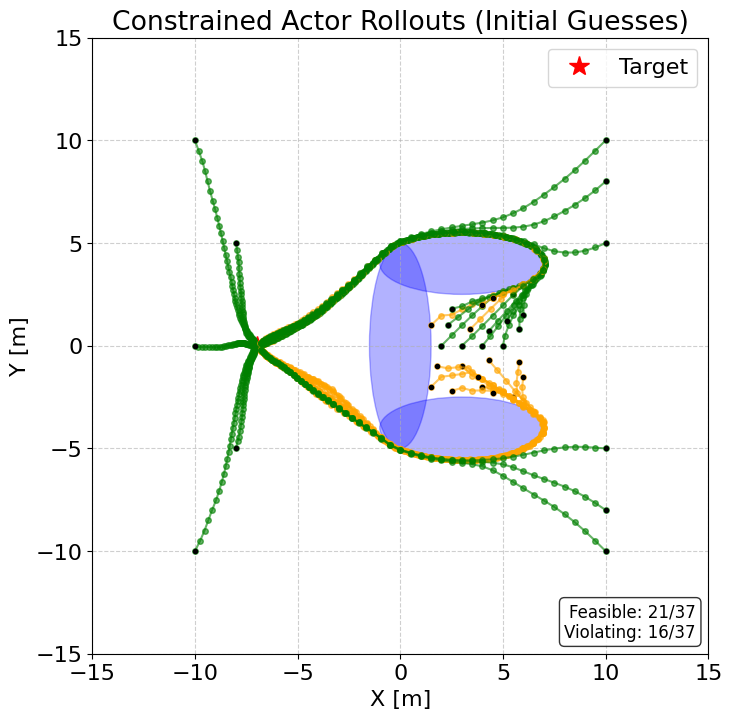

Computing initial guesses in batch...
TO + Warm Start -> Time: 12.979 s
TO + Warm Start -> Feasible: 37/37 | Failed: 0/37


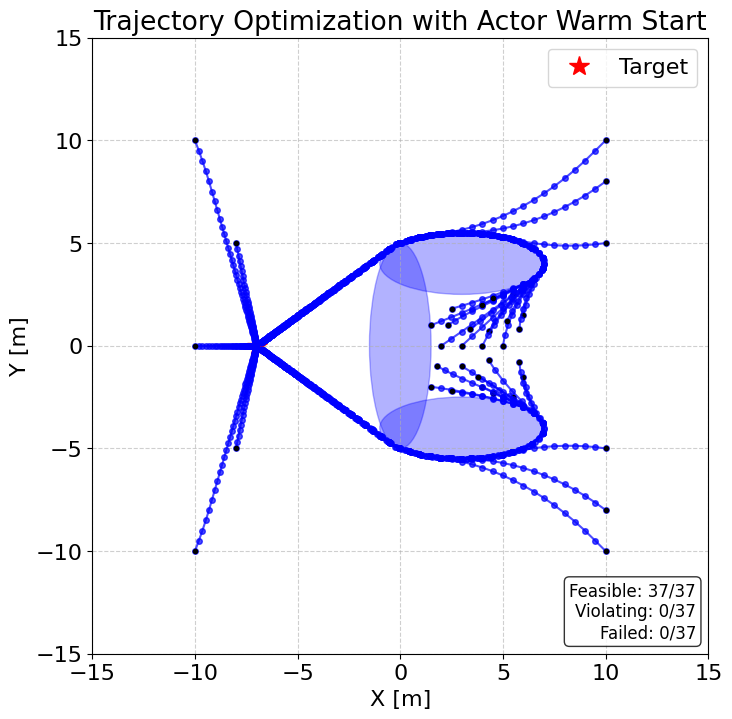

In [94]:
# Final evaluation of the constrained actor rollouts and TO performance after the last iteration
plot_cons_actor_rollouts(print_costs=True)
V_TO, all_cons_x_trajs = evaluate_TO_w_cons_warm_start()

--- CACTO Iteration 19 ---
Start solving 300 TO problems


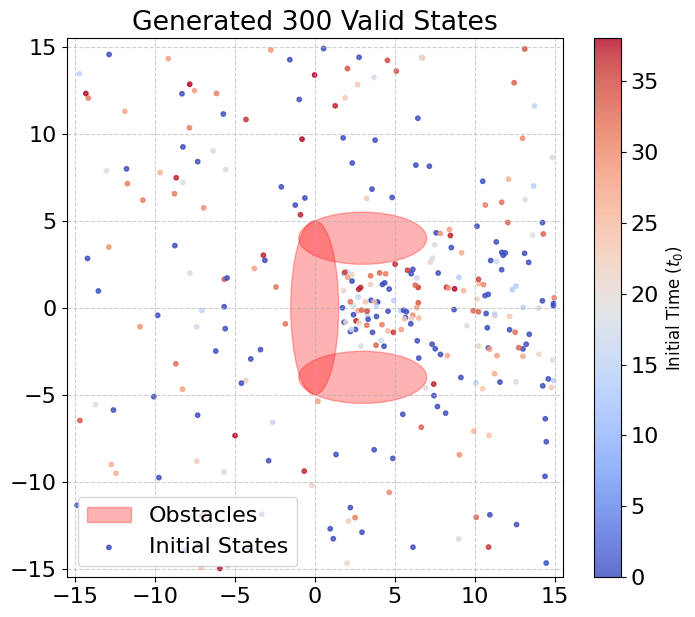

Computing warm start guesses via Actor...


COmputing OCPs: 100%|██████████| 300/300 [01:17<00:00,  3.89traj/s]


--- Finished ---
Successfully solved: 300 / 300
States Buffer size: (25000, 3) samples
Time taken: 79.656 s


In [95]:
# Solve an OCP for every sampled initial state-time using the constrained actor for warm start
solve_TO_problems(use_actor_to_warm_start=True, actor=cons_actor)

--- CACTO Iteration 19 ---
--- Start training critic ---
Replay buffer size: 25000 samples
Epoch 1/35 | MSE: 50.0347 | RMSE: 7.0735 | LR: 0.005000 | step: 98
Epoch 5/35 | MSE: 64.4557 | RMSE: 8.0284 | LR: 0.005000 | step: 490
Epoch 10/35 | MSE: 166.2082 | RMSE: 12.8922 | LR: 0.005000 | step: 980
Epoch 15/35 | MSE: 20.8553 | RMSE: 4.5668 | LR: 0.003750 | step: 1470
Epoch 20/35 | MSE: 22.1702 | RMSE: 4.7085 | LR: 0.002812 | step: 1960
Epoch 25/35 | MSE: 21.8530 | RMSE: 4.6747 | LR: 0.002109 | step: 2450
Epoch 30/35 | MSE: 9.8698 | RMSE: 3.1416 | LR: 0.001582 | step: 2940
Epoch 35/35 | MSE: 10.2853 | RMSE: 3.2071 | LR: 0.001187 | step: 3430
Final Critic MSE: 10.29
Final Critic RMSE: 3.21
--- Critic training has finished ---

Total critic cycles: 62720


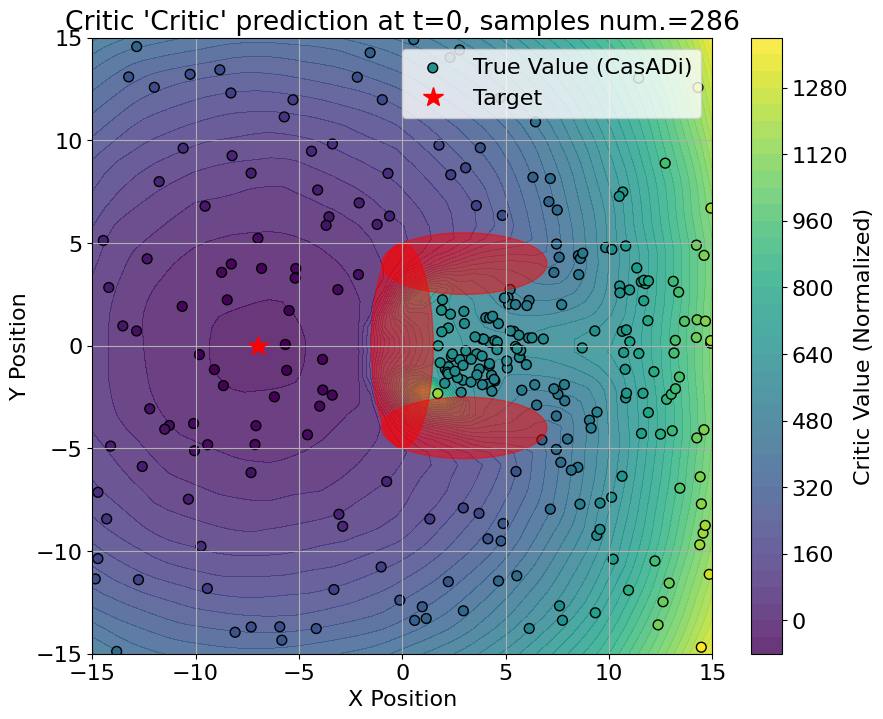

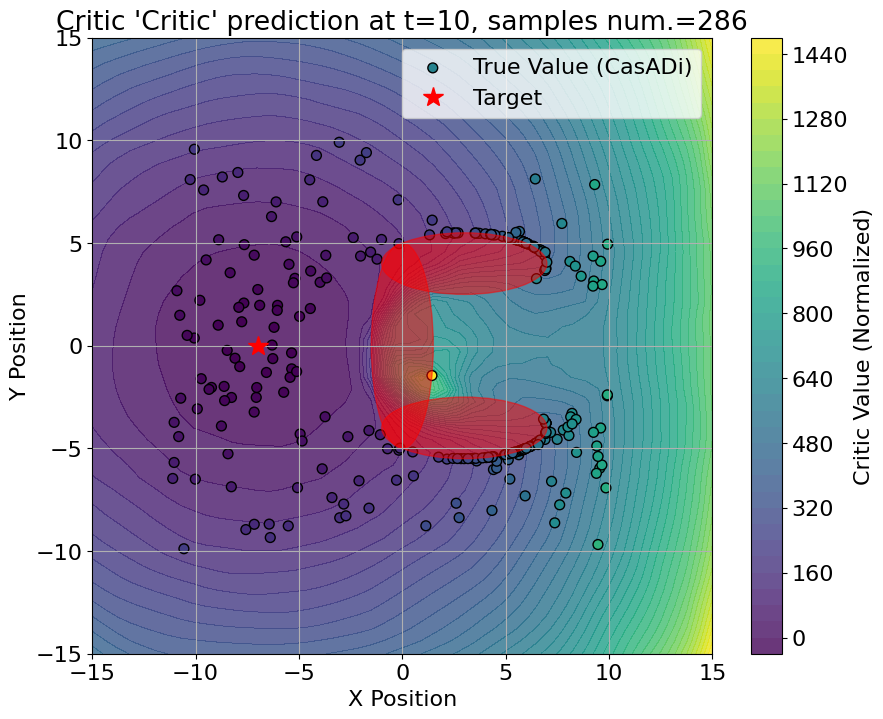

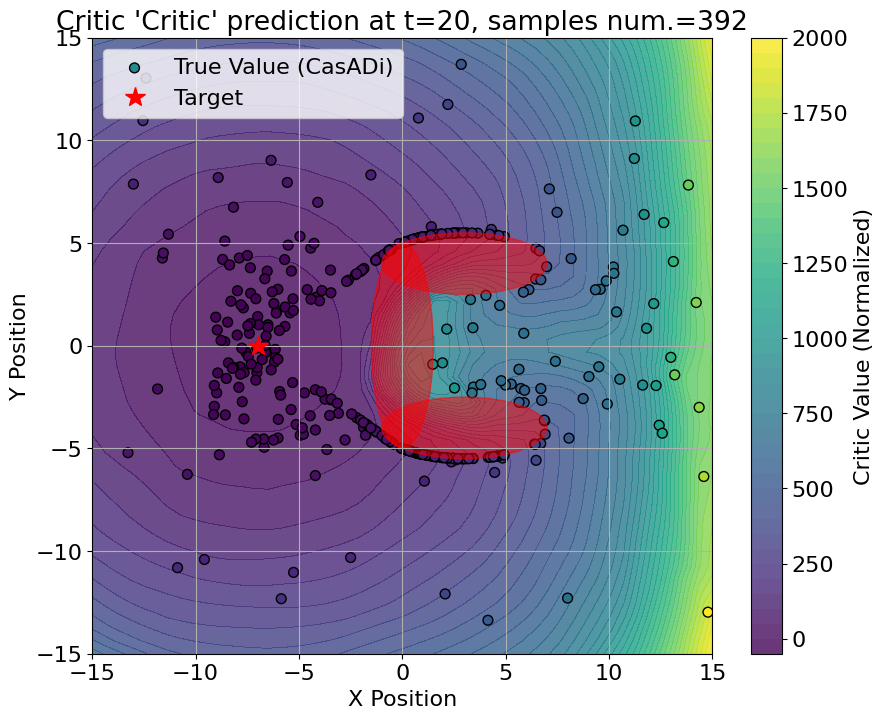

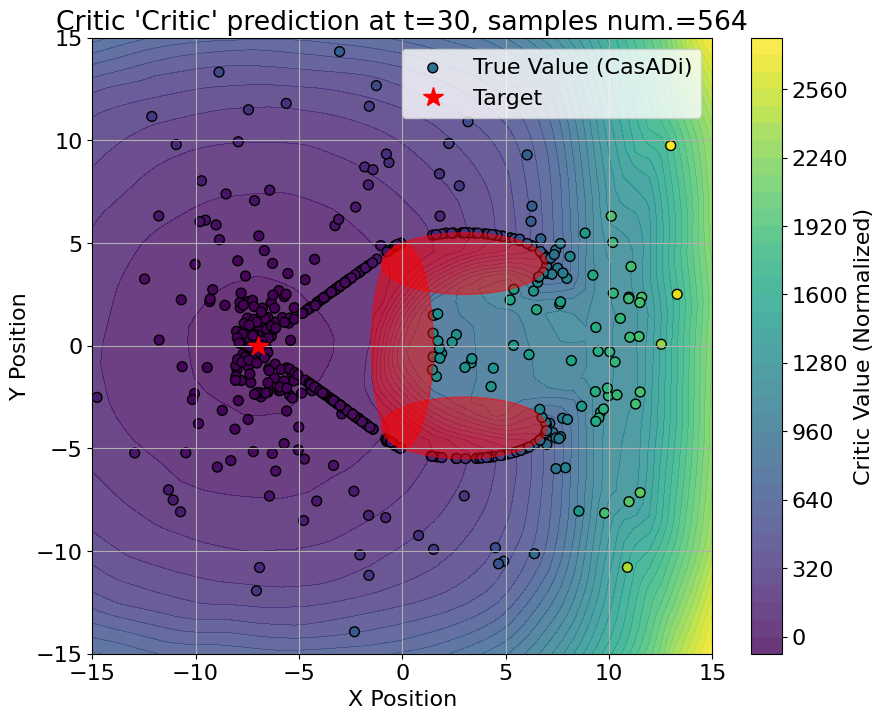

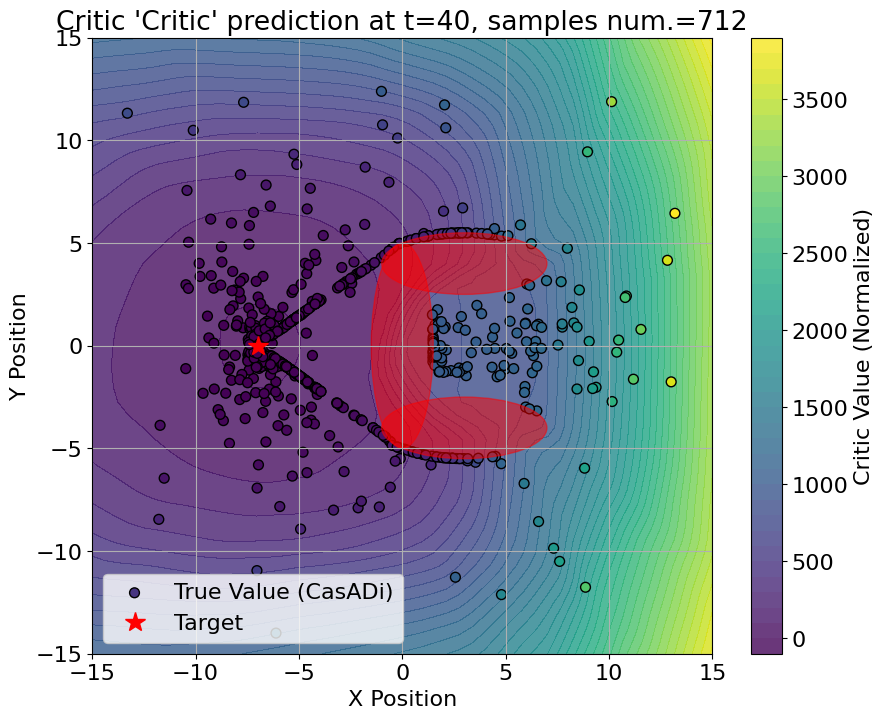

In [96]:
# Train the critic again with the new data in the buffer 
train_critic()

# Update the critic cycles counter
critic_cycles += cycles_counter(replay_buffer, minibatch_size, critic_epochs)
print(f"\nTotal critic cycles: {critic_cycles}")

for t in range(0, N, 10):
  plot_critic(critic, t, show=False)

--- CACTO Iteration 19 ---
--- Start training the constrained actor ---
--- Starting Constrained Actor training for 35 epochs ---
Epoch 1/35 | Mean Q+ALM: 247.7914 | Max Viol: 0.00021 | Lambda: [213.42 243.45 246.83] | Rho: 19579.2 | LR: 0.000500 | step: 98
 | dQ/du norm: 1.425977
Epoch 5/35 | Mean Q+ALM: 248.0434 | Max Viol: 0.00030 | Lambda: [214.06 247.41 249.76] | Rho: 20172.4 | LR: 0.000500 | step: 490
 | dQ/du norm: 1.445640
Epoch 10/35 | Mean Q+ALM: 247.7107 | Max Viol: 0.00010 | Lambda: [218.27 250.8  253.54] | Rho: 20783.7 | LR: 0.000500 | step: 980
 | dQ/du norm: 1.420989
Epoch 15/35 | Mean Q+ALM: 247.5720 | Max Viol: 0.00006 | Lambda: [219.1  255.97 255.49] | Rho: 21413.4 | LR: 0.000400 | step: 1470
 | dQ/du norm: 1.408999
Epoch 20/35 | Mean Q+ALM: 247.6956 | Max Viol: 0.00030 | Lambda: [222.97 258.58 260.24] | Rho: 22505.8 | LR: 0.000320 | step: 1960
 | dQ/du norm: 1.407017
Epoch 25/35 | Mean Q+ALM: 247.6893 | Max Viol: 0.00032 | Lambda: [224.62 264.41 262.96] | Rho: 23419.

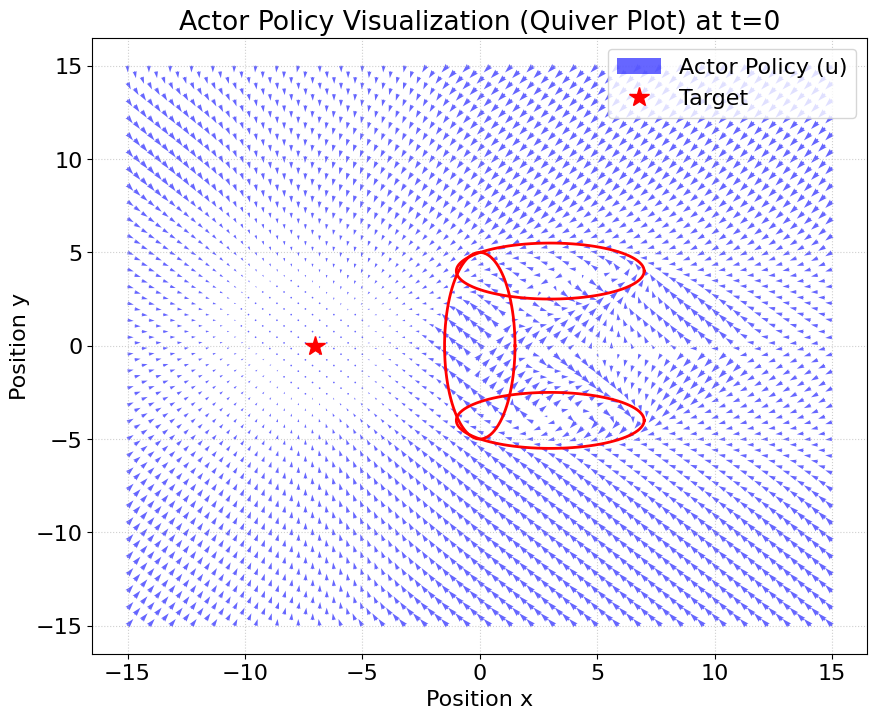

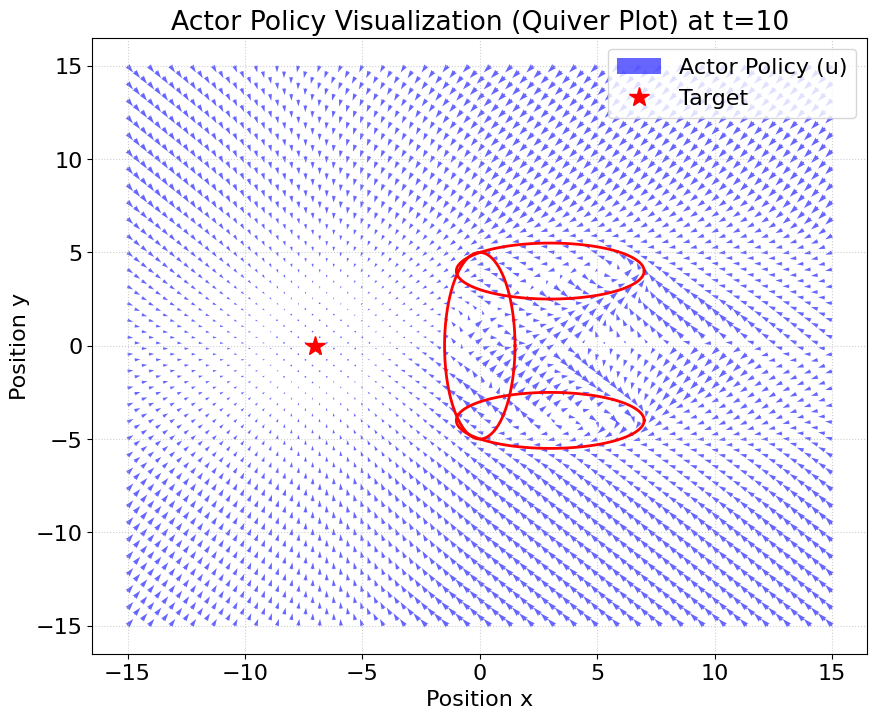

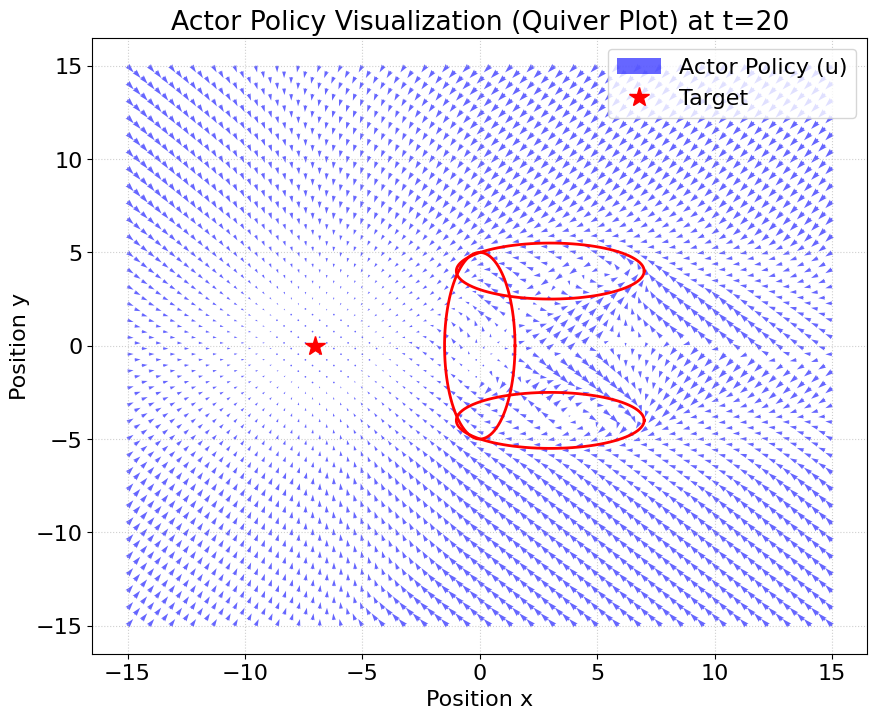

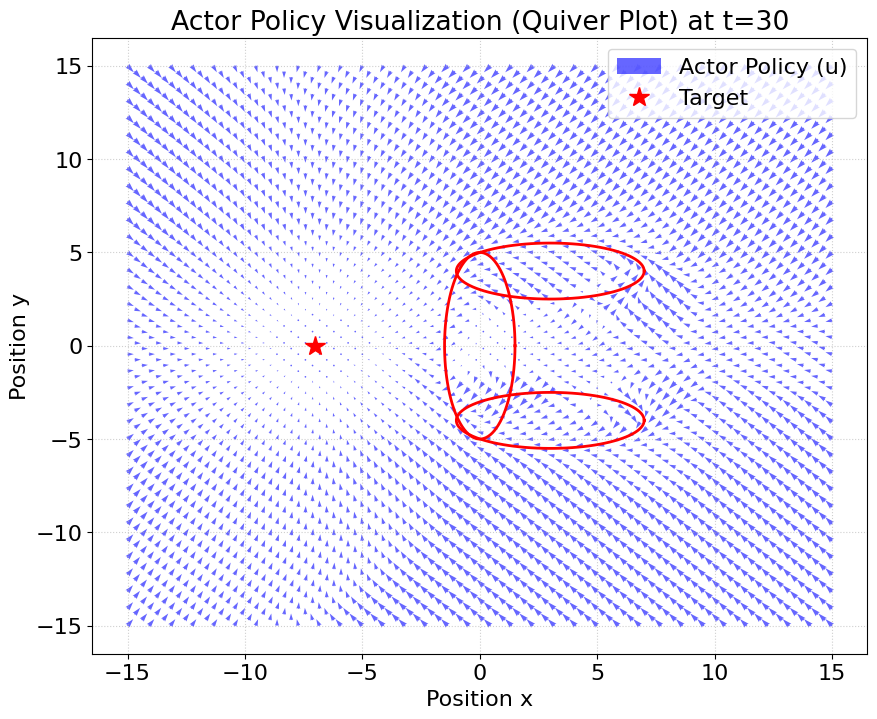

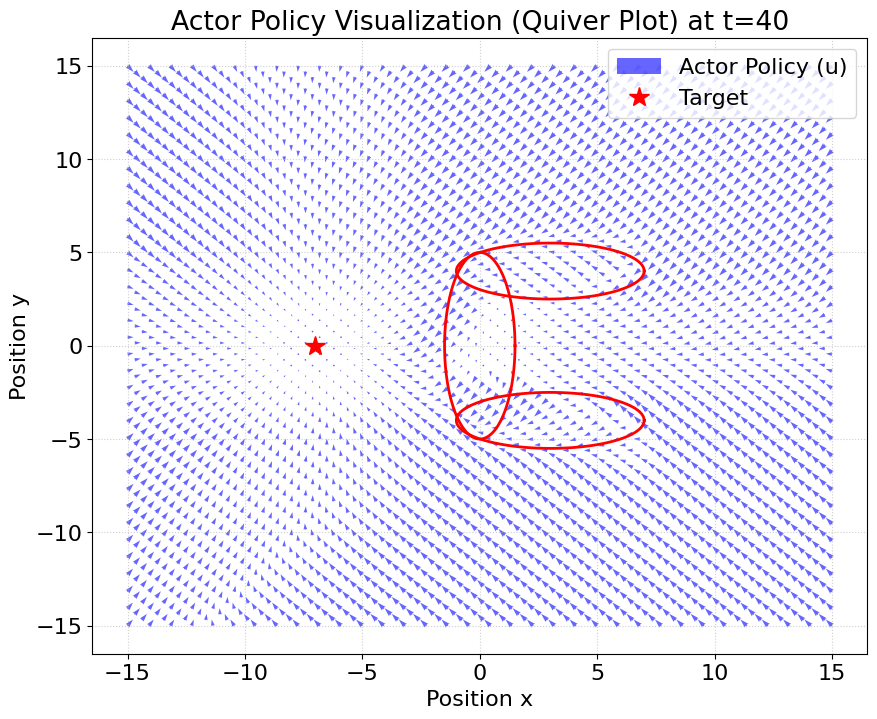

In [97]:
# Train the constrained actor again with the new critic

train_constr_actor()

# Update the constrained actor cycles counter
actor_cycles += cycles_counter(replay_buffer, minibatch_size, actor_epochs)
print(f"\nTotal constrained actor cycles: {actor_cycles}")

for t in range(0, N, 10):
  plot_constr_actor(t, show=True, plot_u_ocp=True)

Actor Only -> Feasible: 26/37 | Violating: 11/37
Actor Only -> Avg. max violation: 0.0051
Actor Only -> Avg. cost: 506.4504

Costs and Feasibility List:
Rollout 001 | Xini: (-10.0, -10.0) | Cost:   125.94 | Status: OK
Rollout 002 | Xini: (-8.0, -5.0) | Cost:    -7.70 | Status: OK
Rollout 003 | Xini: (-10.0,  0.0) | Cost:   -34.72 | Status: OK
Rollout 004 | Xini: (-8.0,  5.0) | Cost:    -7.91 | Status: OK
Rollout 005 | Xini: (-10.0, 10.0) | Cost:   126.19 | Status: OK
Rollout 006 | Xini: ( 5.0,  0.0) | Cost:   592.85 | Status: OK
Rollout 007 | Xini: ( 6.0,  1.5) | Cost:   524.06 | Status: OK
Rollout 008 | Xini: ( 6.0, -1.5) | Cost:   518.12 | Status: VIOL
Rollout 009 | Xini: ( 5.5,  2.5) | Cost:   492.16 | Status: OK
Rollout 010 | Xini: ( 5.5, -2.5) | Cost:   476.86 | Status: VIOL
Rollout 011 | Xini: ( 2.0,  0.0) | Cost:   640.89 | Status: OK
Rollout 012 | Xini: ( 1.5,  1.0) | Cost:   644.56 | Status: OK
Rollout 013 | Xini: ( 1.5, -2.0) | Cost:   643.76 | Status: VIOL
Rollout 014 | Xini

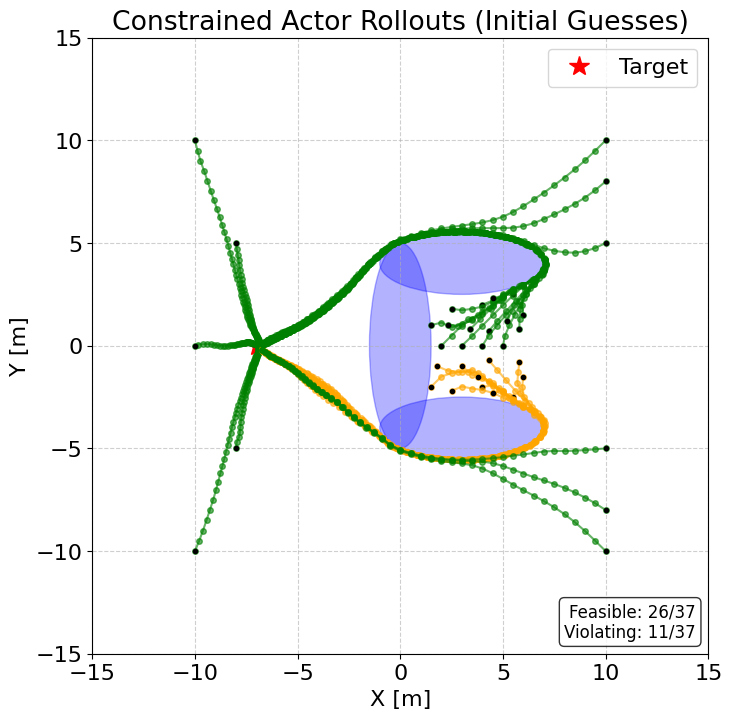

Computing initial guesses in batch...
TO + Warm Start -> Time: 15.712 s
TO + Warm Start -> Feasible: 37/37 | Failed: 0/37


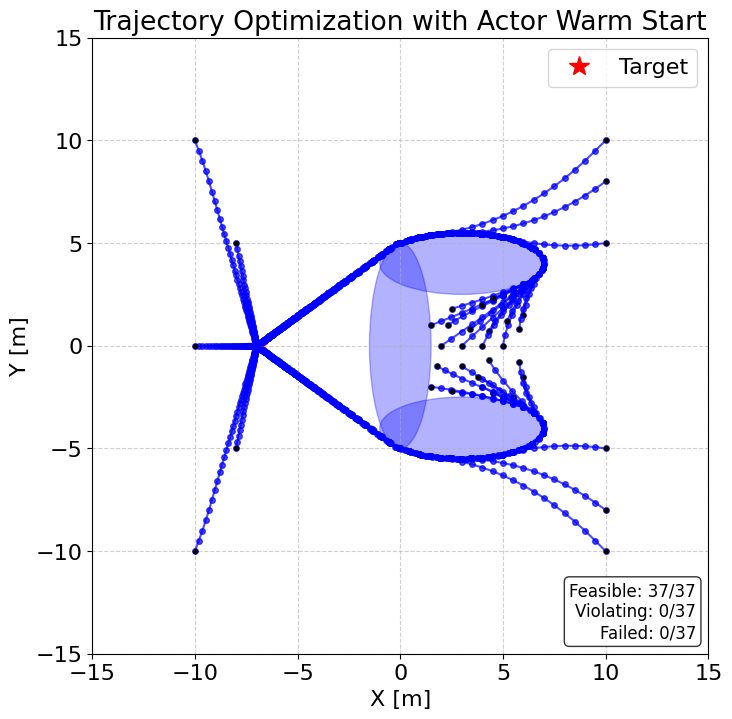

In [98]:
# Final evaluation of the constrained actor rollouts and TO performance after the last iteration
plot_cons_actor_rollouts(print_costs=True)
V_TO, all_cons_x_trajs = evaluate_TO_w_cons_warm_start()

--- CACTO Iteration 20 ---
Start solving 300 TO problems


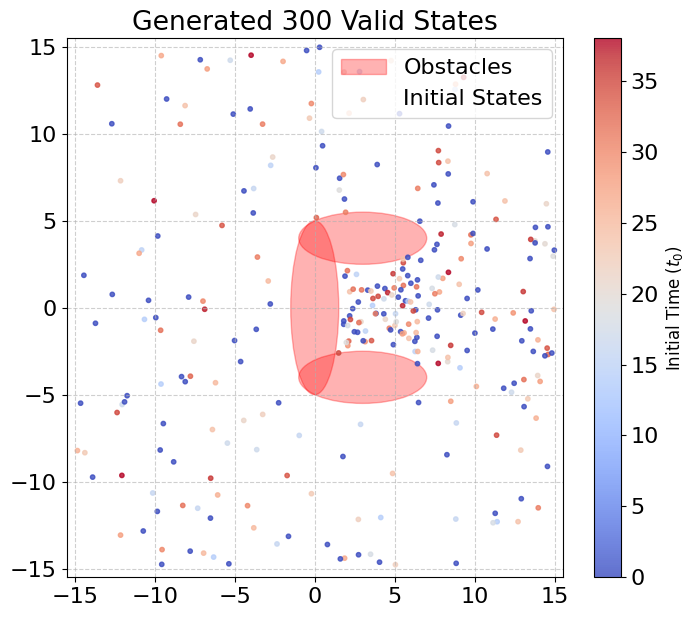

Computing warm start guesses via Actor...


COmputing OCPs: 100%|██████████| 300/300 [01:15<00:00,  3.95traj/s]


--- Finished ---
Successfully solved: 300 / 300
States Buffer size: (25000, 3) samples
Time taken: 78.303 s


In [99]:
# Solve an OCP for every sampled initial state-time using the constrained actor for warm start
solve_TO_problems(use_actor_to_warm_start=True, actor=cons_actor)

--- CACTO Iteration 20 ---
--- Start training critic ---
Replay buffer size: 25000 samples
Epoch 1/35 | MSE: 104.9440 | RMSE: 10.2442 | LR: 0.005000 | step: 98
Epoch 5/35 | MSE: 39.1044 | RMSE: 6.2533 | LR: 0.005000 | step: 490
Epoch 10/35 | MSE: 69.3284 | RMSE: 8.3264 | LR: 0.005000 | step: 980
Epoch 15/35 | MSE: 17.7548 | RMSE: 4.2136 | LR: 0.003750 | step: 1470
Epoch 20/35 | MSE: 18.8893 | RMSE: 4.3462 | LR: 0.002812 | step: 1960
Epoch 25/35 | MSE: 26.6579 | RMSE: 5.1631 | LR: 0.002109 | step: 2450
Epoch 30/35 | MSE: 9.1375 | RMSE: 3.0228 | LR: 0.001582 | step: 2940
Epoch 35/35 | MSE: 9.3209 | RMSE: 3.0530 | LR: 0.001187 | step: 3430
Final Critic MSE: 9.32
Final Critic RMSE: 3.05
--- Critic training has finished ---

Total critic cycles: 66150


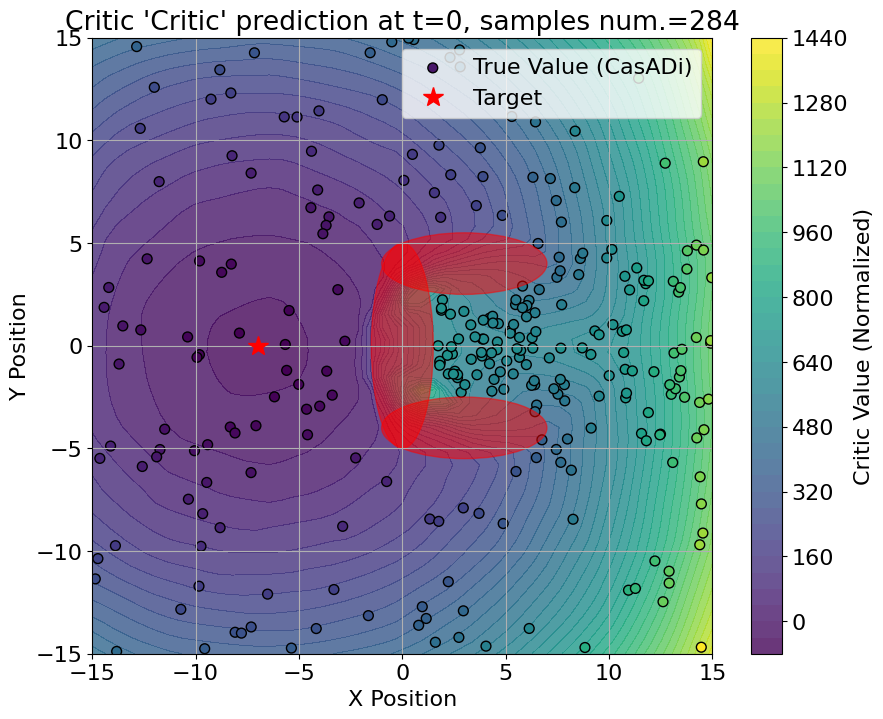

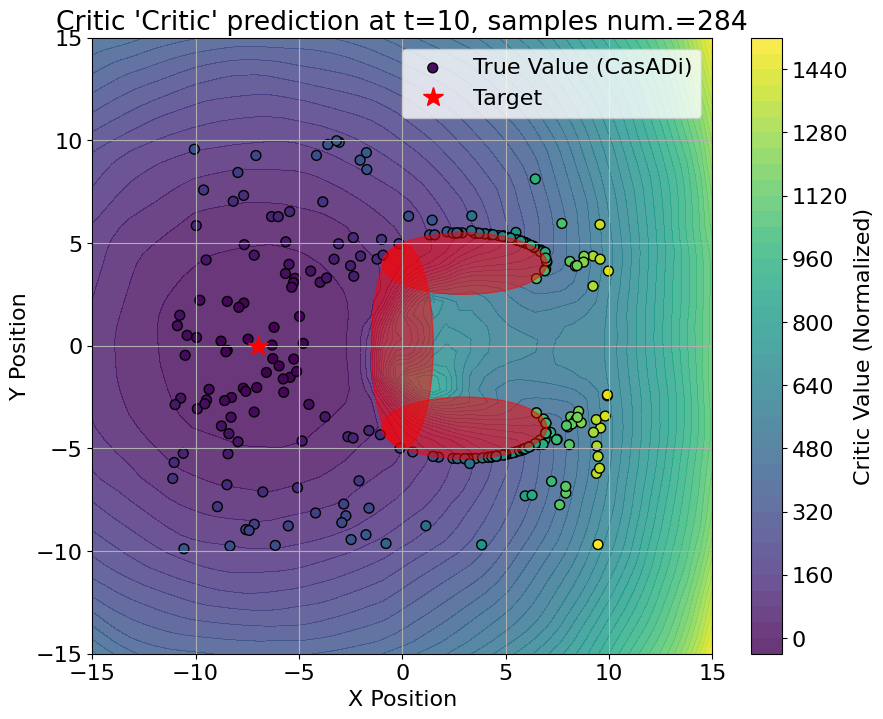

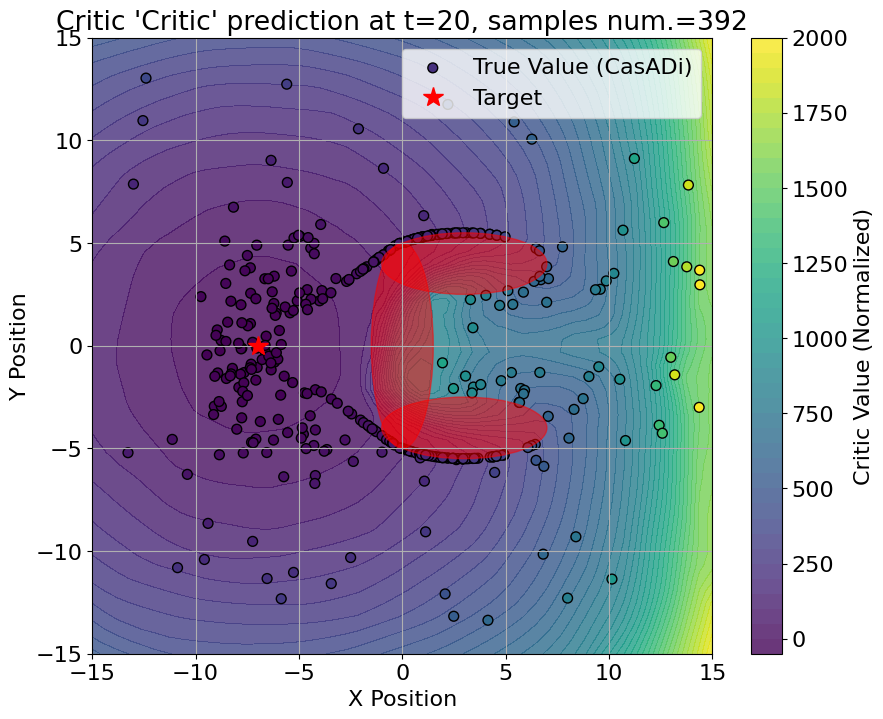

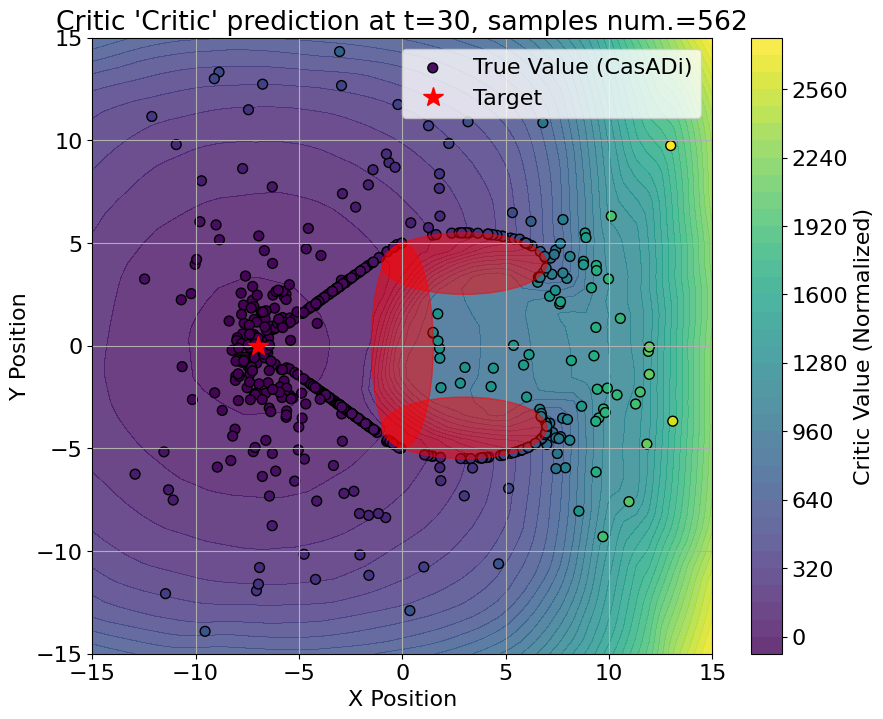

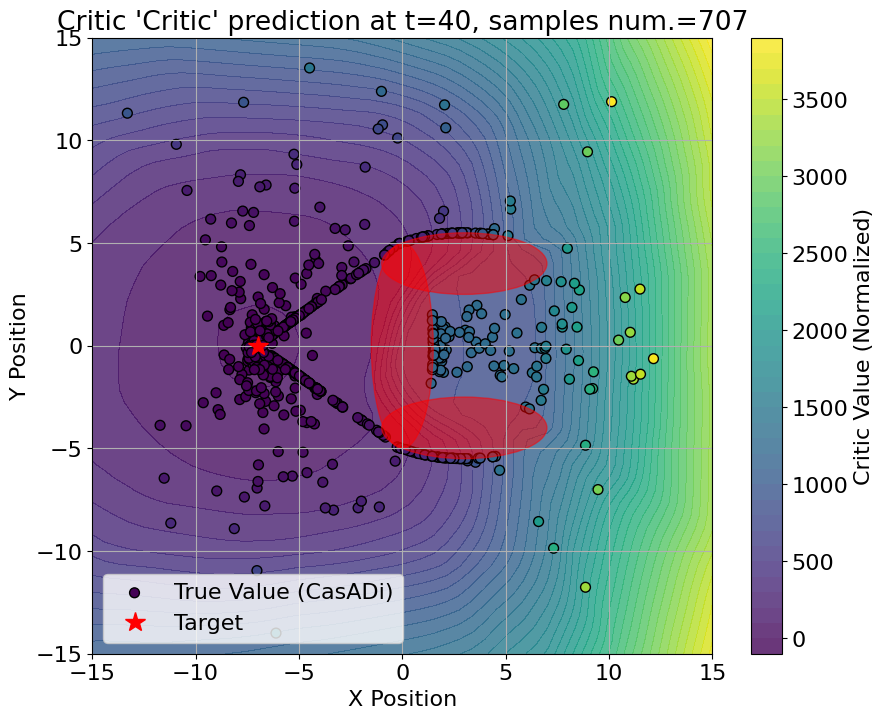

In [100]:
# Train the critic again with the new data in the buffer 
train_critic()

# Update the critic cycles counter
critic_cycles += cycles_counter(replay_buffer, minibatch_size, critic_epochs)
print(f"\nTotal critic cycles: {critic_cycles}")

for t in range(0, N, 10):
  plot_critic(critic, t, show=False)

--- CACTO Iteration 20 ---
--- Start training the constrained actor ---
--- Starting Constrained Actor training for 35 epochs ---
Epoch 1/35 | Mean Q+ALM: 239.6397 | Max Viol: 0.00008 | Lambda: [228.23 272.31 275.67] | Rho: 24860.4 | LR: 0.000500 | step: 98
 | dQ/du norm: 1.482843
Epoch 5/35 | Mean Q+ALM: 239.7361 | Max Viol: 0.00032 | Lambda: [232.82 276.45 280.89] | Rho: 25360.0 | LR: 0.000500 | step: 490
 | dQ/du norm: 1.487602
Epoch 10/35 | Mean Q+ALM: 239.5081 | Max Viol: 0.00003 | Lambda: [242.42 279.68 285.21] | Rho: 25869.8 | LR: 0.000500 | step: 980
 | dQ/du norm: 1.483460
Epoch 15/35 | Mean Q+ALM: 239.5072 | Max Viol: 0.00020 | Lambda: [242.87 284.15 289.93] | Rho: 26653.7 | LR: 0.000400 | step: 1470
 | dQ/du norm: 1.481829
Epoch 20/35 | Mean Q+ALM: 239.6271 | Max Viol: 0.00014 | Lambda: [246.63 289.42 295.97] | Rho: 27735.9 | LR: 0.000320 | step: 1960
 | dQ/du norm: 1.471841
Epoch 25/35 | Mean Q+ALM: 239.4463 | Max Viol: 0.00018 | Lambda: [248.99 291.16 298.99] | Rho: 28013.

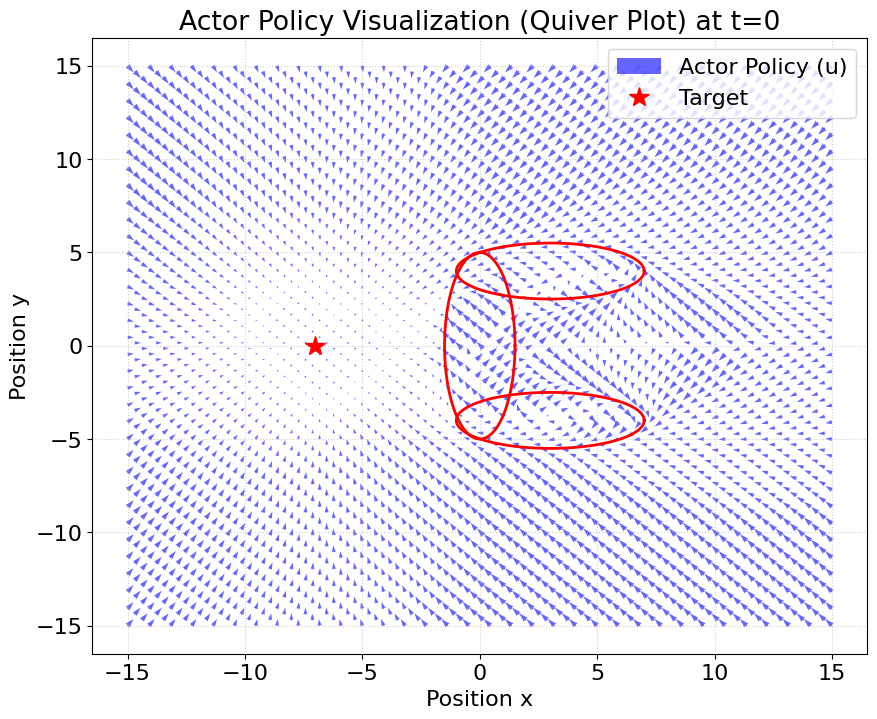

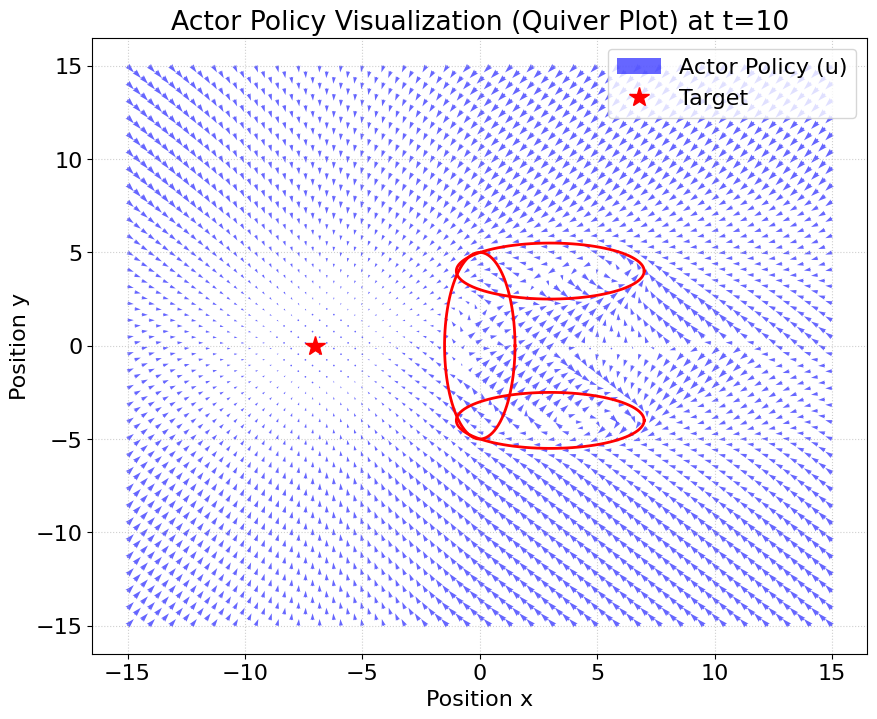

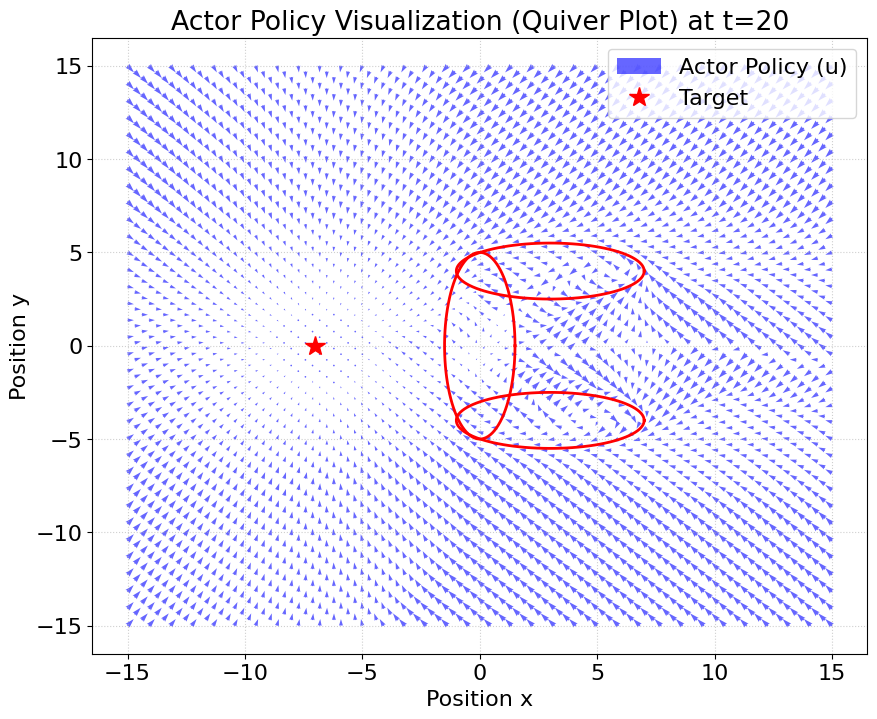

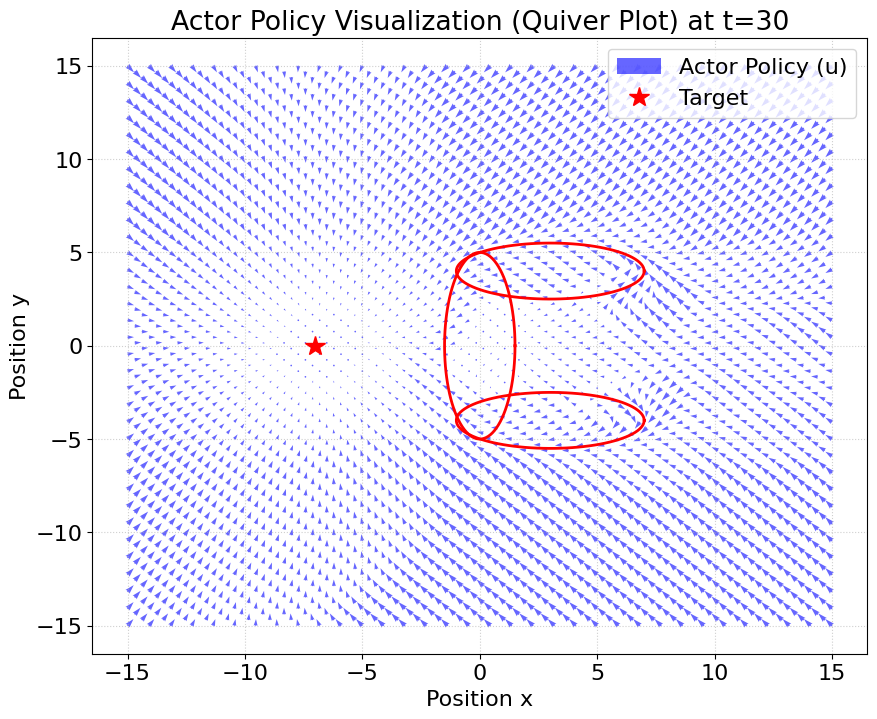

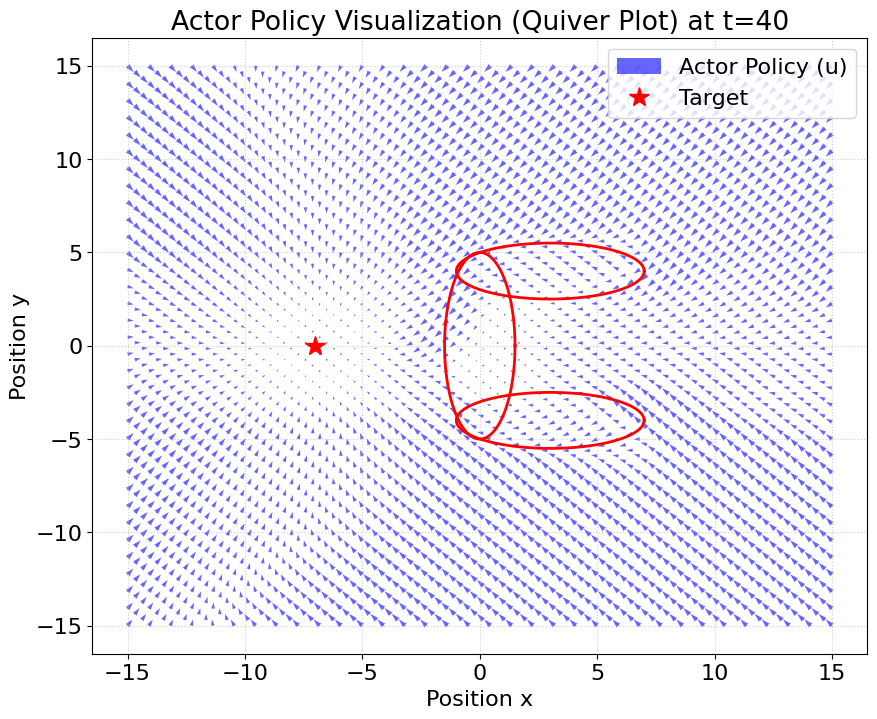

In [101]:
# Train the constrained actor again with the new critic

train_constr_actor()

# Update the constrained actor cycles counter
actor_cycles += cycles_counter(replay_buffer, minibatch_size, actor_epochs)
print(f"\nTotal constrained actor cycles: {actor_cycles}")

for t in range(0, N, 10):
  plot_constr_actor(t, show=True, plot_u_ocp=True)

Actor Only -> Feasible: 32/37 | Violating: 5/37
Actor Only -> Avg. max violation: 0.0052
Actor Only -> Avg. cost: 509.8595

Costs and Feasibility List:
Rollout 001 | Xini: (-10.0, -10.0) | Cost:   126.79 | Status: OK
Rollout 002 | Xini: (-8.0, -5.0) | Cost:    -7.26 | Status: OK
Rollout 003 | Xini: (-10.0,  0.0) | Cost:   -34.30 | Status: OK
Rollout 004 | Xini: (-8.0,  5.0) | Cost:    -7.42 | Status: OK
Rollout 005 | Xini: (-10.0, 10.0) | Cost:   126.83 | Status: OK
Rollout 006 | Xini: ( 5.0,  0.0) | Cost:   598.37 | Status: OK
Rollout 007 | Xini: ( 6.0,  1.5) | Cost:   522.58 | Status: OK
Rollout 008 | Xini: ( 6.0, -1.5) | Cost:   526.00 | Status: OK
Rollout 009 | Xini: ( 5.5,  2.5) | Cost:   485.96 | Status: VIOL
Rollout 010 | Xini: ( 5.5, -2.5) | Cost:   487.13 | Status: OK
Rollout 011 | Xini: ( 2.0,  0.0) | Cost:   641.73 | Status: OK
Rollout 012 | Xini: ( 1.5,  1.0) | Cost:   641.40 | Status: OK
Rollout 013 | Xini: ( 1.5, -2.0) | Cost:   654.68 | Status: OK
Rollout 014 | Xini: ( 2

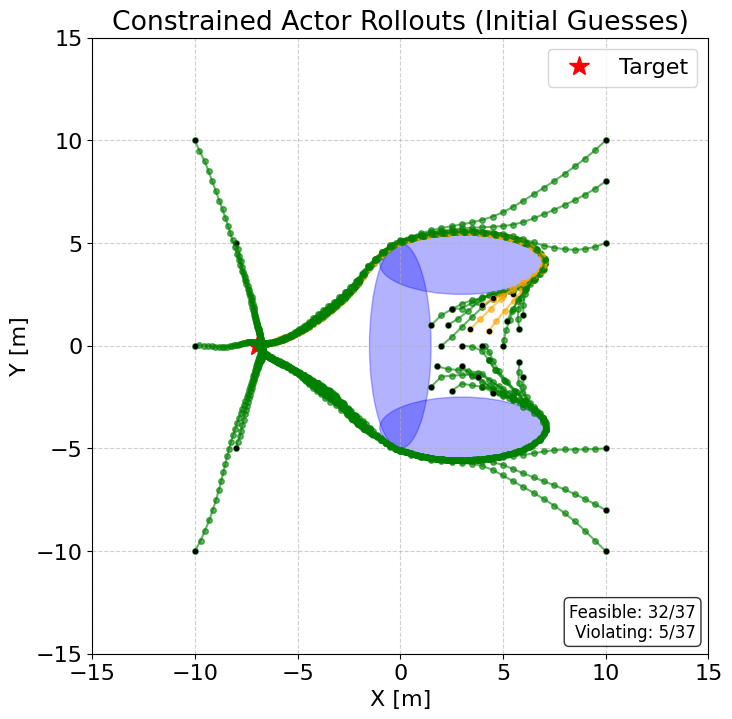

Computing initial guesses in batch...
TO + Warm Start -> Time: 14.670 s
TO + Warm Start -> Feasible: 37/37 | Failed: 0/37


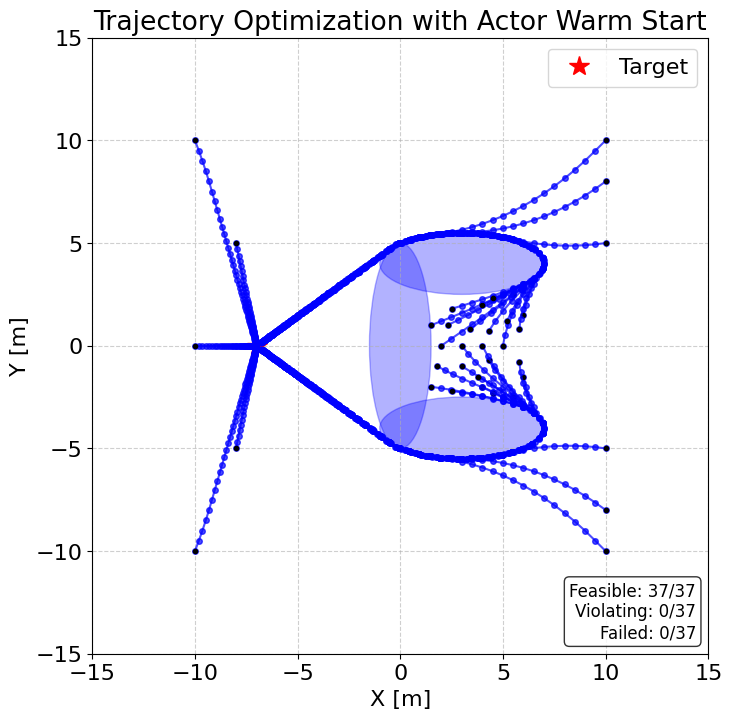

In [102]:
# Final evaluation of the constrained actor rollouts and TO performance after the last iteration
plot_cons_actor_rollouts(print_costs=True)
V_TO, all_cons_x_trajs = evaluate_TO_w_cons_warm_start()

--- CACTO Iteration 21 ---
Start solving 300 TO problems


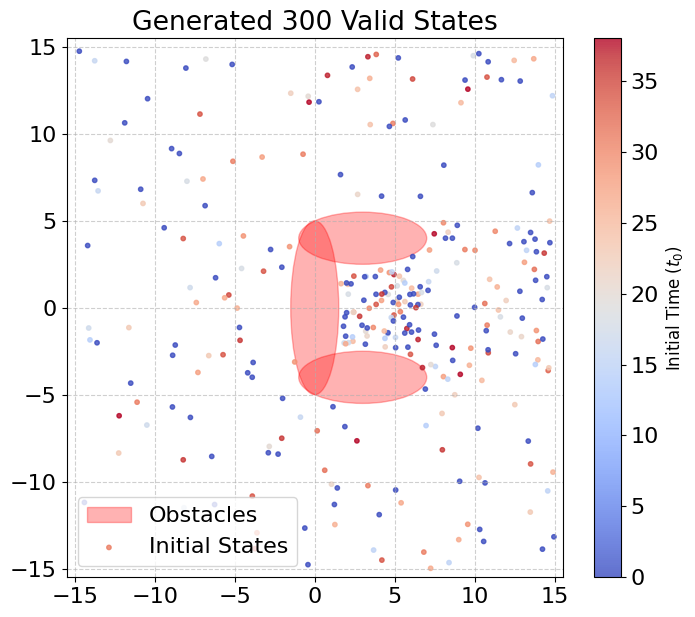

Computing warm start guesses via Actor...


COmputing OCPs: 100%|██████████| 300/300 [01:16<00:00,  3.90traj/s]


--- Finished ---
Successfully solved: 300 / 300
States Buffer size: (25000, 3) samples
Time taken: 79.617 s


In [103]:
# Solve an OCP for every sampled initial state-time using the constrained actor for warm start
solve_TO_problems(use_actor_to_warm_start=True, actor=cons_actor)

--- CACTO Iteration 21 ---
--- Start training critic ---
Replay buffer size: 25000 samples
Epoch 1/35 | MSE: 52.2475 | RMSE: 7.2282 | LR: 0.005000 | step: 98
Epoch 5/35 | MSE: 44.9141 | RMSE: 6.7018 | LR: 0.005000 | step: 490
Epoch 10/35 | MSE: 61.9379 | RMSE: 7.8701 | LR: 0.005000 | step: 980
Epoch 15/35 | MSE: 25.6433 | RMSE: 5.0639 | LR: 0.003750 | step: 1470
Epoch 20/35 | MSE: 10.2017 | RMSE: 3.1940 | LR: 0.002812 | step: 1960
Epoch 25/35 | MSE: 12.5712 | RMSE: 3.5456 | LR: 0.002109 | step: 2450
Epoch 30/35 | MSE: 6.3569 | RMSE: 2.5213 | LR: 0.001582 | step: 2940
Epoch 35/35 | MSE: 5.3628 | RMSE: 2.3158 | LR: 0.001187 | step: 3430
Final Critic MSE: 5.36
Final Critic RMSE: 2.32
--- Critic training has finished ---

Total critic cycles: 69580


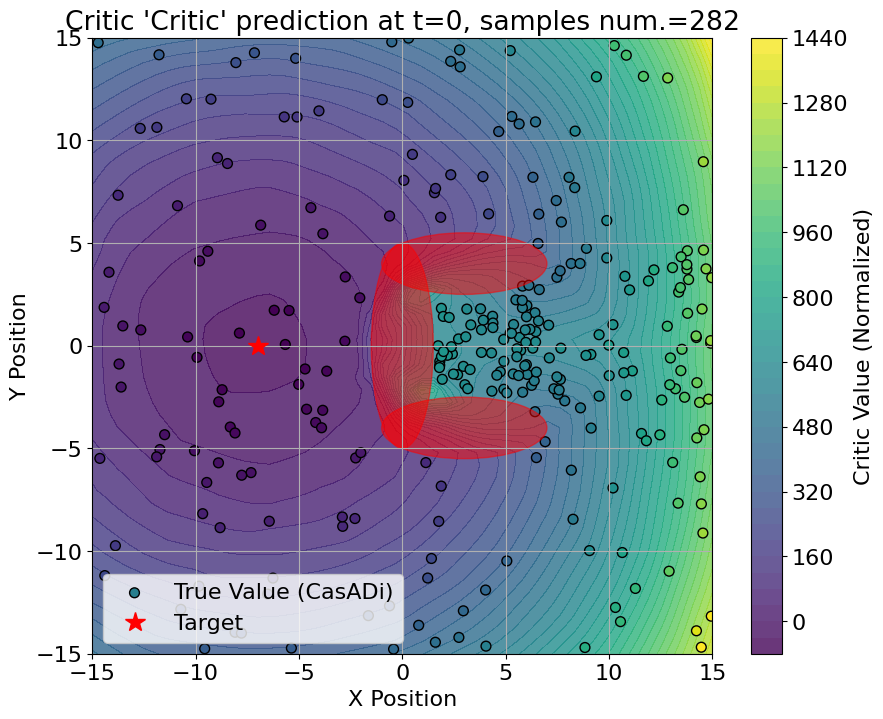

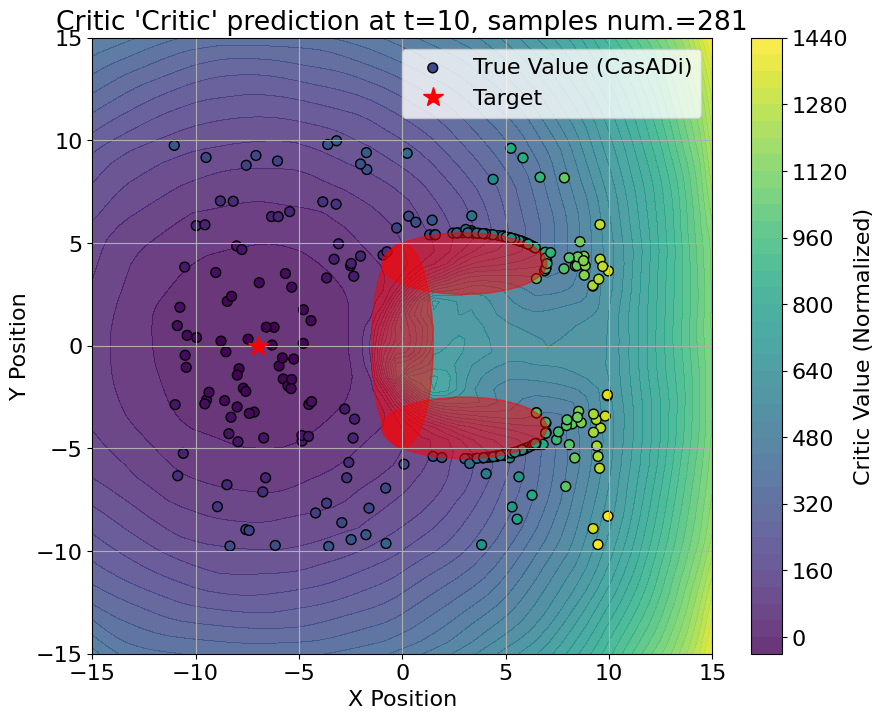

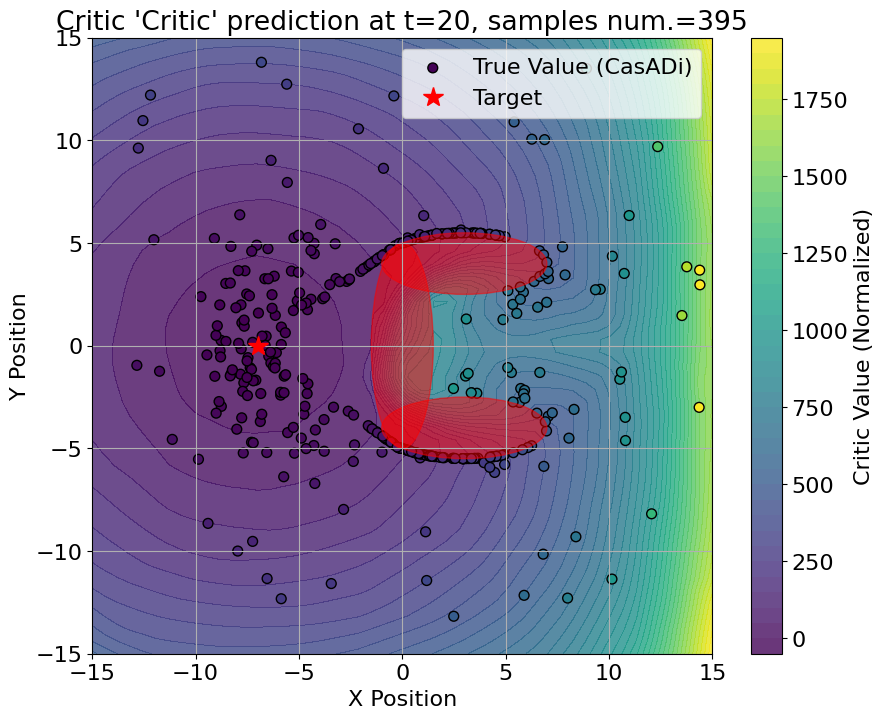

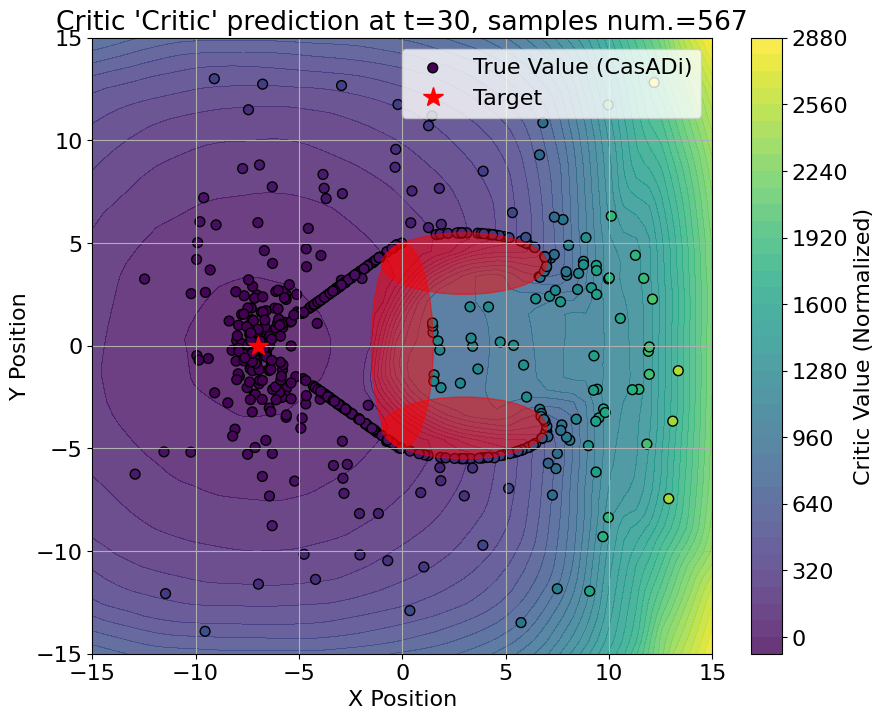

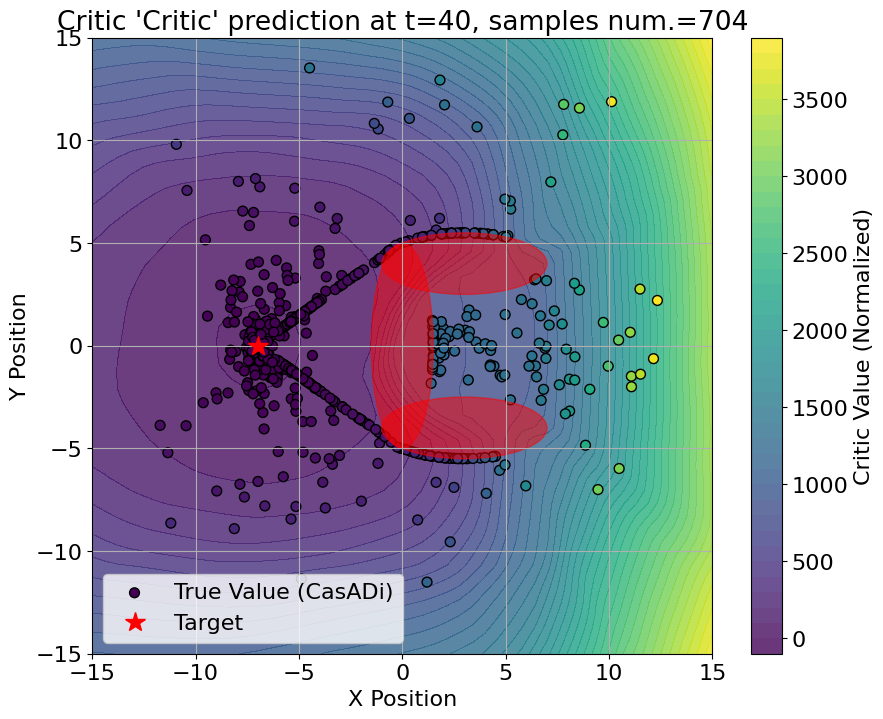

In [104]:
# Train the critic again with the new data in the buffer 
train_critic()

# Update the critic cycles counter
critic_cycles += cycles_counter(replay_buffer, minibatch_size, critic_epochs)
print(f"\nTotal critic cycles: {critic_cycles}")

for t in range(0, N, 10):
  plot_critic(critic, t, show=False)

--- CACTO Iteration 21 ---
--- Start training the constrained actor ---
--- Starting Constrained Actor training for 35 epochs ---
Epoch 1/35 | Mean Q+ALM: 244.4414 | Max Viol: 0.00117 | Lambda: [266.27 299.74 306.48] | Rho: 29150.7 | LR: 0.000500 | step: 98
 | dQ/du norm: 1.459069
Epoch 5/35 | Mean Q+ALM: 242.7709 | Max Viol: 0.00007 | Lambda: [268.19 300.8  309.52] | Rho: 29442.2 | LR: 0.000500 | step: 490
 | dQ/du norm: 1.483653
Epoch 10/35 | Mean Q+ALM: 242.9133 | Max Viol: 0.00018 | Lambda: [273.46 306.77 328.75] | Rho: 30944.1 | LR: 0.000500 | step: 980
 | dQ/du norm: 1.479566
Epoch 15/35 | Mean Q+ALM: 242.6560 | Max Viol: 0.00003 | Lambda: [288.78 308.41 332.6 ] | Rho: 31881.7 | LR: 0.000400 | step: 1470
 | dQ/du norm: 1.480309
Epoch 20/35 | Mean Q+ALM: 242.6322 | Max Viol: 0.00001 | Lambda: [295.24 314.41 338.42] | Rho: 32200.5 | LR: 0.000320 | step: 1960
 | dQ/du norm: 1.472649
Epoch 25/35 | Mean Q+ALM: 242.6749 | Max Viol: 0.00017 | Lambda: [296.05 316.79 342.57] | Rho: 32522.

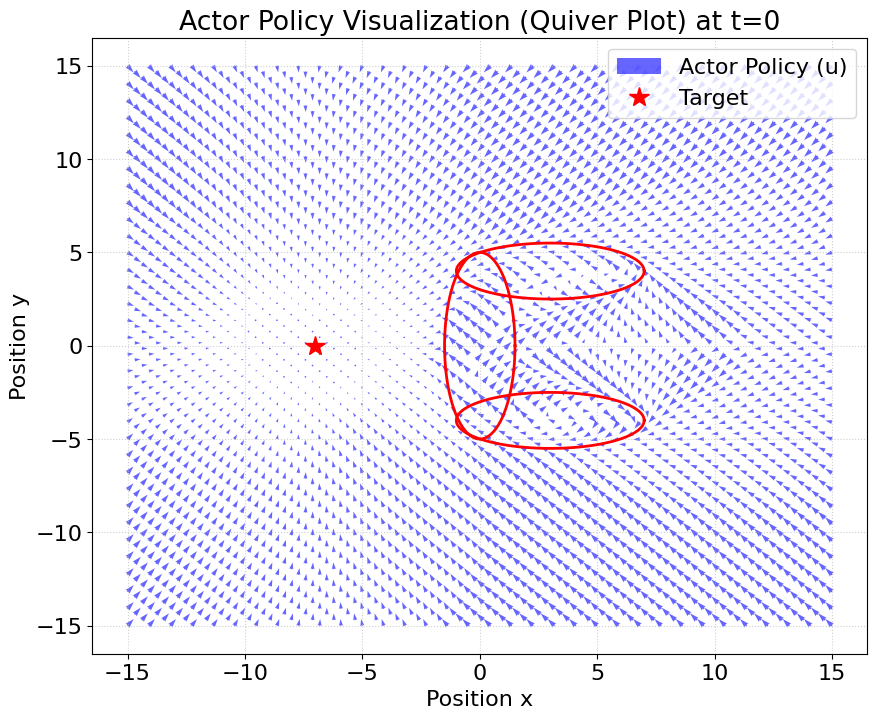

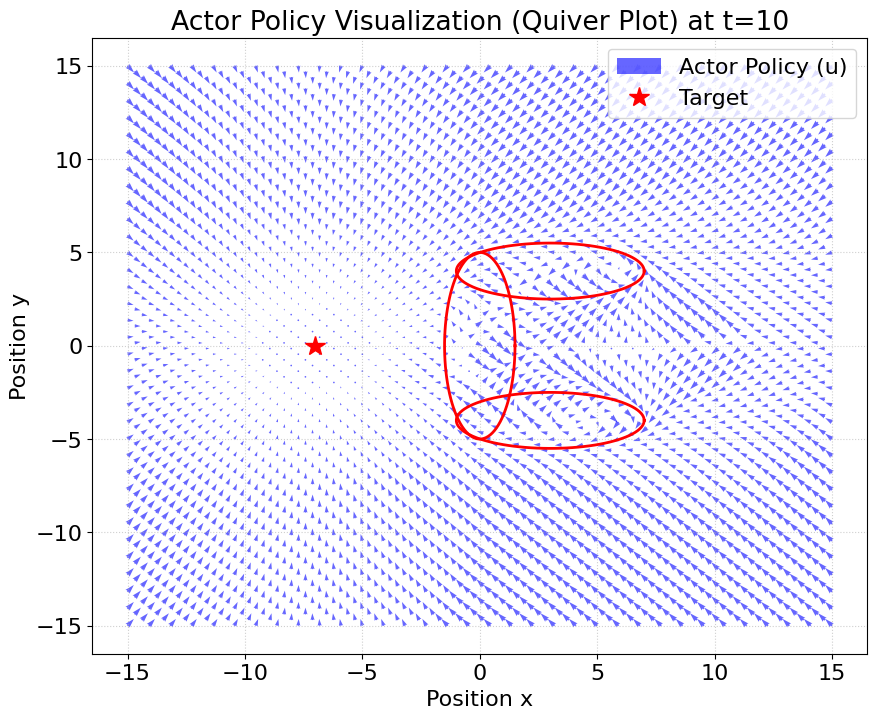

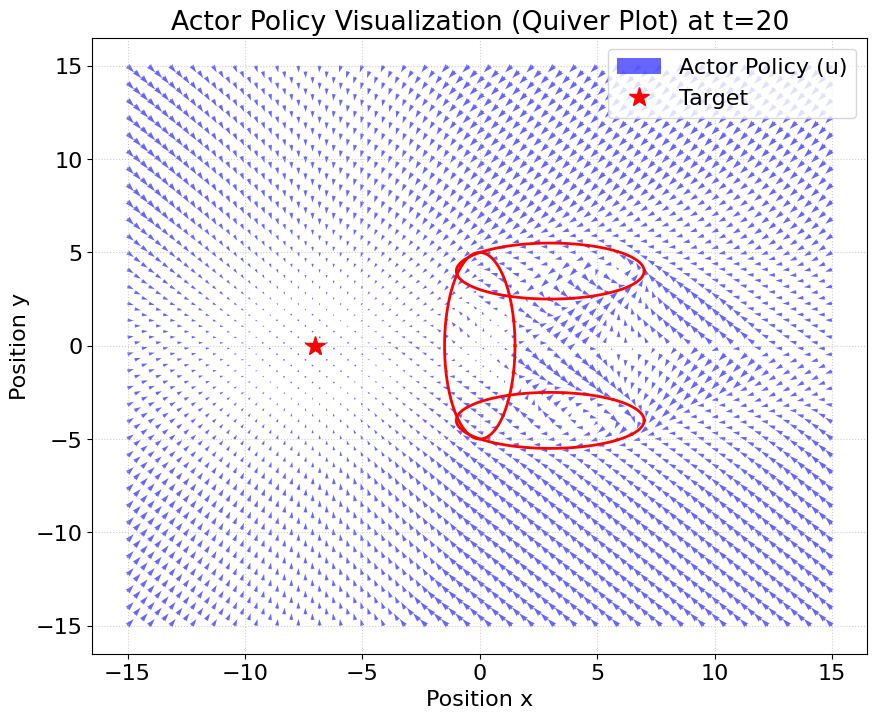

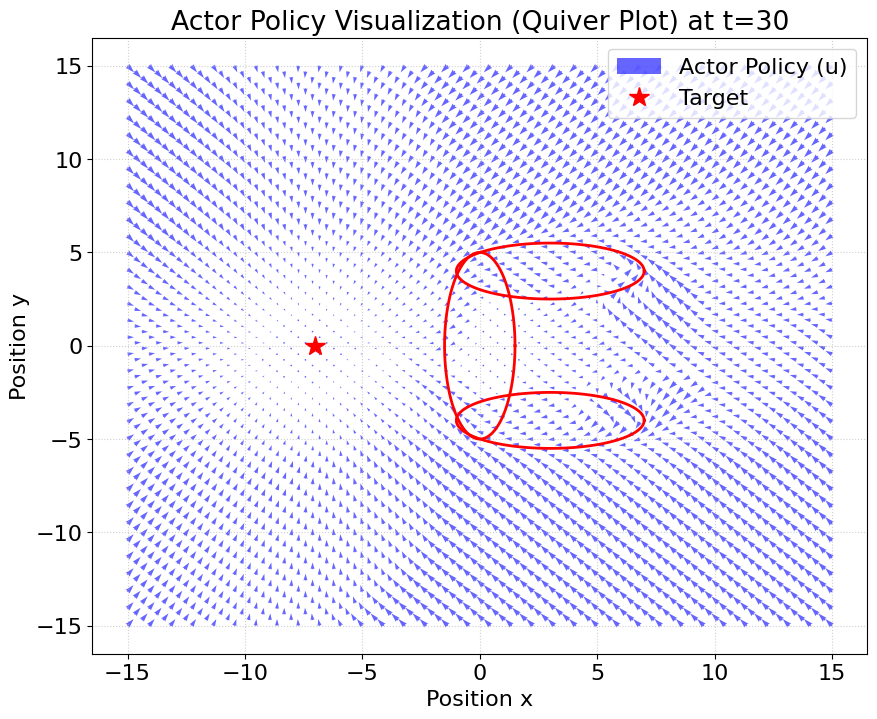

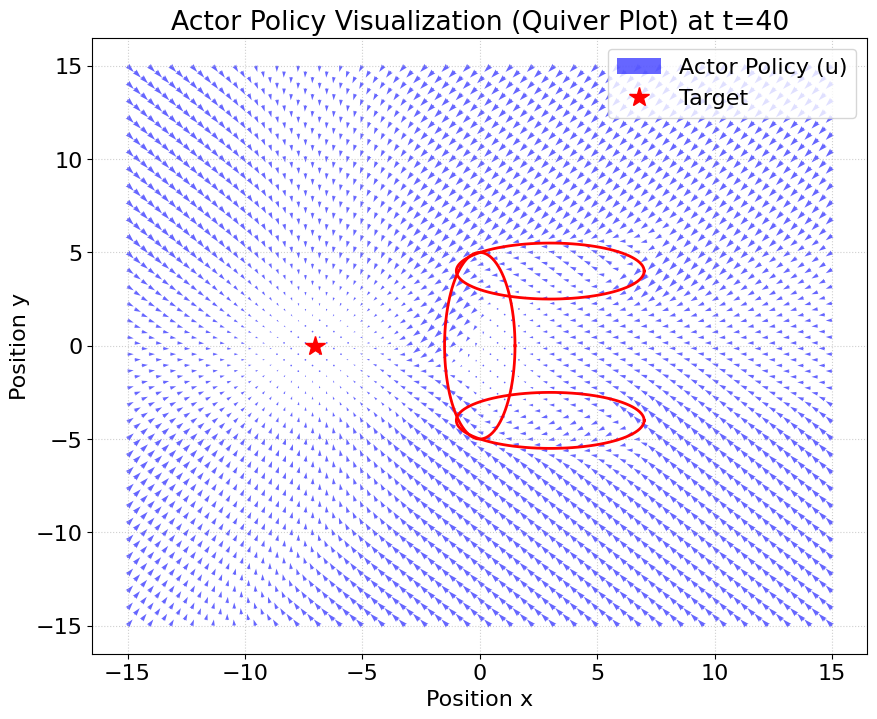

In [105]:
# Train the constrained actor again with the new critic

train_constr_actor()

# Update the constrained actor cycles counter
actor_cycles += cycles_counter(replay_buffer, minibatch_size, actor_epochs)
print(f"\nTotal constrained actor cycles: {actor_cycles}")

for t in range(0, N, 10):
  plot_constr_actor(t, show=True, plot_u_ocp=True)

Actor Only -> Feasible: 23/37 | Violating: 14/37
Actor Only -> Avg. max violation: 0.0024
Actor Only -> Avg. cost: 506.7715

Costs and Feasibility List:
Rollout 001 | Xini: (-10.0, -10.0) | Cost:   126.66 | Status: OK
Rollout 002 | Xini: (-8.0, -5.0) | Cost:    -7.55 | Status: OK
Rollout 003 | Xini: (-10.0,  0.0) | Cost:   -35.08 | Status: OK
Rollout 004 | Xini: (-8.0,  5.0) | Cost:    -7.81 | Status: OK
Rollout 005 | Xini: (-10.0, 10.0) | Cost:   126.06 | Status: OK
Rollout 006 | Xini: ( 5.0,  0.0) | Cost:   600.91 | Status: OK
Rollout 007 | Xini: ( 6.0,  1.5) | Cost:   518.38 | Status: VIOL
Rollout 008 | Xini: ( 6.0, -1.5) | Cost:   518.63 | Status: OK
Rollout 009 | Xini: ( 5.5,  2.5) | Cost:   486.27 | Status: VIOL
Rollout 010 | Xini: ( 5.5, -2.5) | Cost:   488.34 | Status: VIOL
Rollout 011 | Xini: ( 2.0,  0.0) | Cost:   634.79 | Status: VIOL
Rollout 012 | Xini: ( 1.5,  1.0) | Cost:   631.82 | Status: VIOL
Rollout 013 | Xini: ( 1.5, -2.0) | Cost:   653.55 | Status: OK
Rollout 014 | 

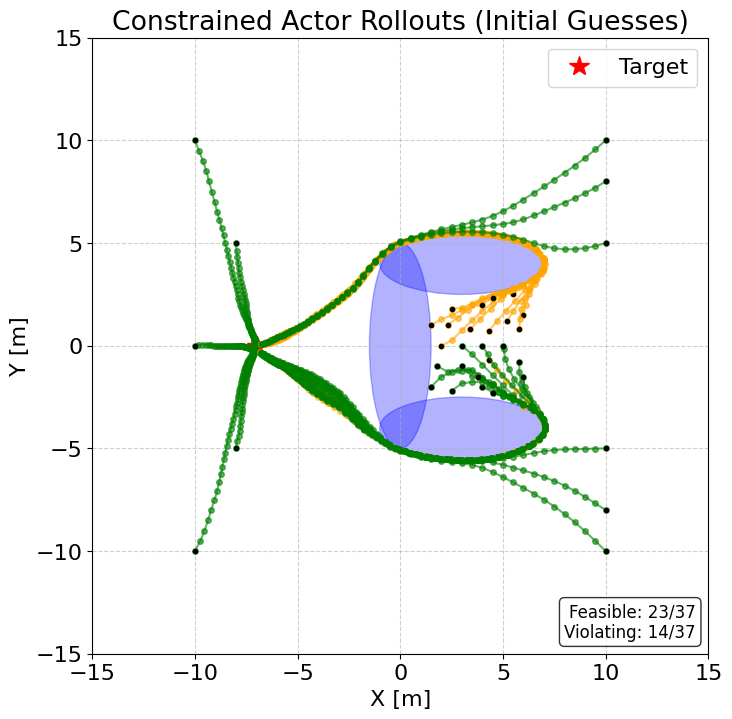

Computing initial guesses in batch...
TO + Warm Start -> Time: 12.299 s
TO + Warm Start -> Feasible: 37/37 | Failed: 0/37


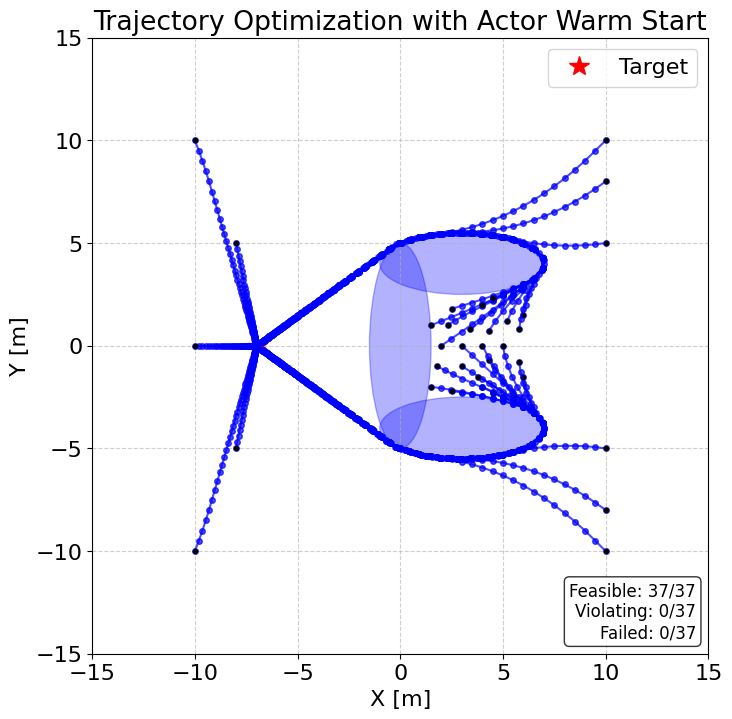

In [106]:
# Final evaluation of the constrained actor rollouts and TO performance after the last iteration
plot_cons_actor_rollouts(print_costs=True)
V_TO, all_cons_x_trajs = evaluate_TO_w_cons_warm_start()

--- CACTO Iteration 22 ---
Start solving 300 TO problems


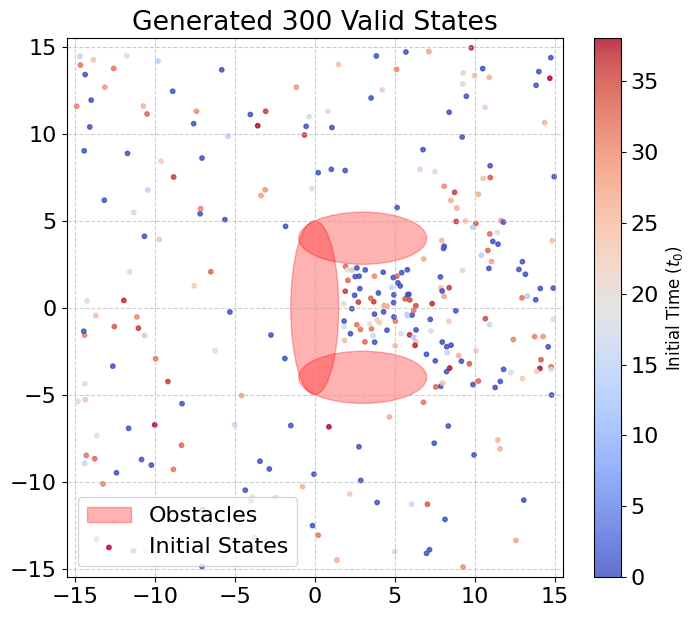

Computing warm start guesses via Actor...


COmputing OCPs: 100%|██████████| 300/300 [01:17<00:00,  3.85traj/s]


--- Finished ---
Successfully solved: 300 / 300
States Buffer size: (25000, 3) samples
Time taken: 80.500 s


In [107]:
# Solve an OCP for every sampled initial state-time using the constrained actor for warm start
solve_TO_problems(use_actor_to_warm_start=True, actor=cons_actor)

--- CACTO Iteration 22 ---
--- Start training critic ---
Replay buffer size: 25000 samples
Epoch 1/35 | MSE: 58.8750 | RMSE: 7.6730 | LR: 0.005000 | step: 98
Epoch 5/35 | MSE: 118.3121 | RMSE: 10.8771 | LR: 0.005000 | step: 490
Epoch 10/35 | MSE: 21.9740 | RMSE: 4.6876 | LR: 0.005000 | step: 980
Epoch 15/35 | MSE: 25.9653 | RMSE: 5.0956 | LR: 0.003750 | step: 1470
Epoch 20/35 | MSE: 5.1484 | RMSE: 2.2690 | LR: 0.002812 | step: 1960
Epoch 25/35 | MSE: 22.6164 | RMSE: 4.7557 | LR: 0.002109 | step: 2450
Epoch 30/35 | MSE: 6.8351 | RMSE: 2.6144 | LR: 0.001582 | step: 2940
Epoch 35/35 | MSE: 3.6537 | RMSE: 1.9115 | LR: 0.001187 | step: 3430
Final Critic MSE: 3.65
Final Critic RMSE: 1.91
--- Critic training has finished ---

Total critic cycles: 73010


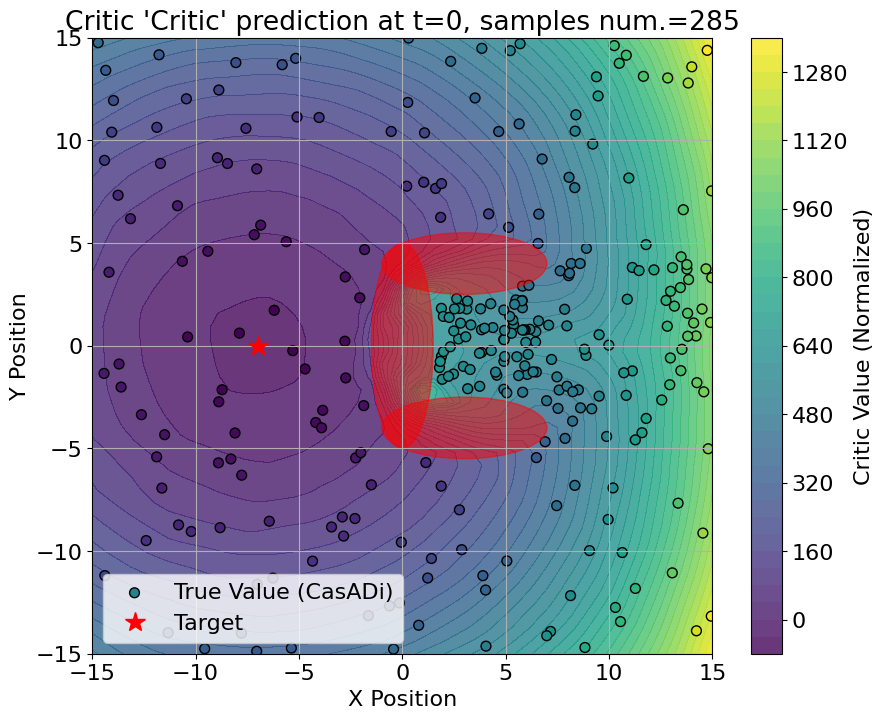

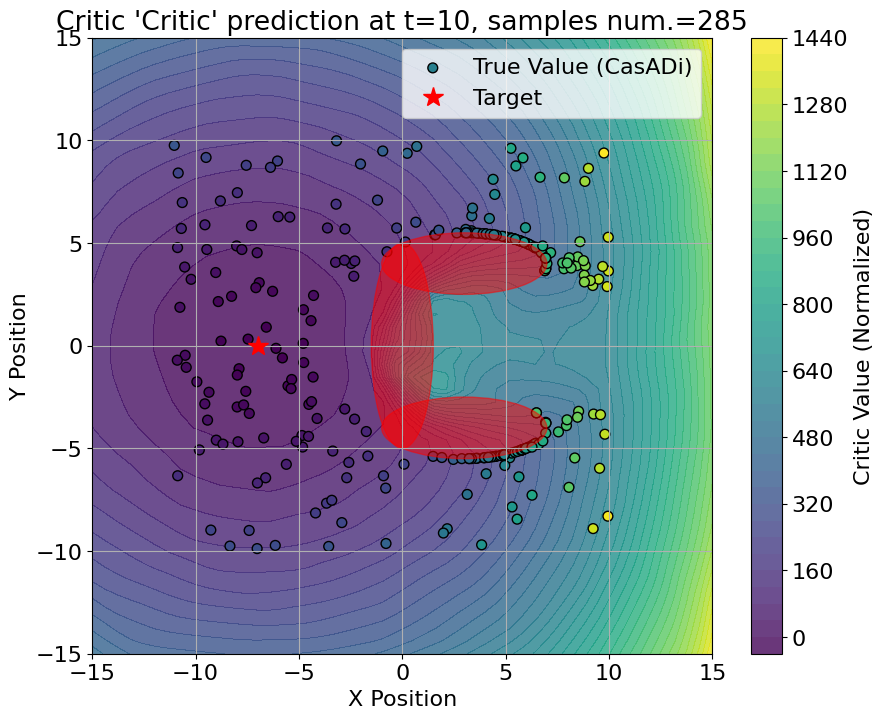

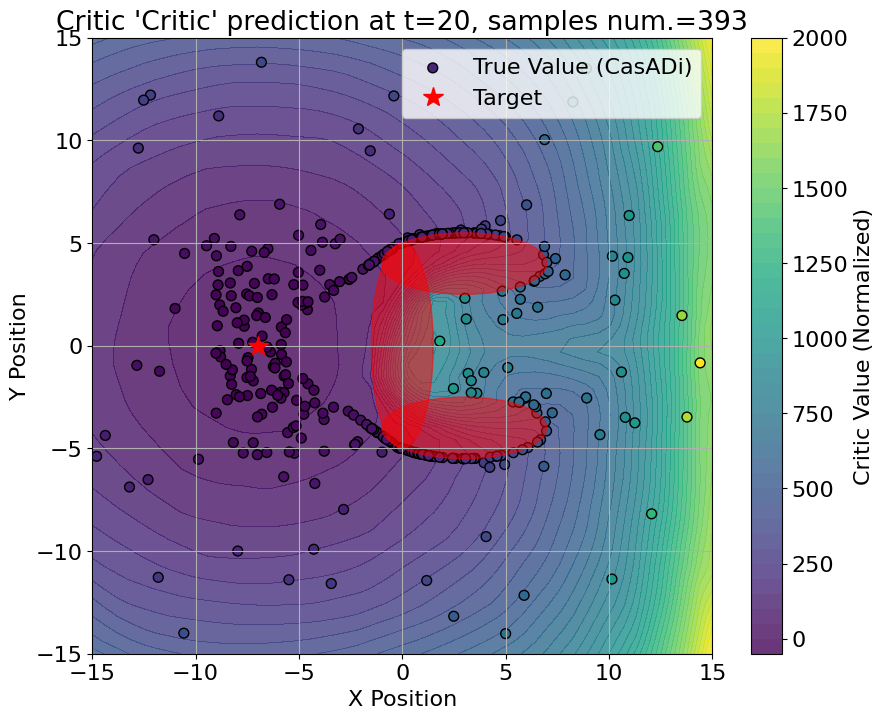

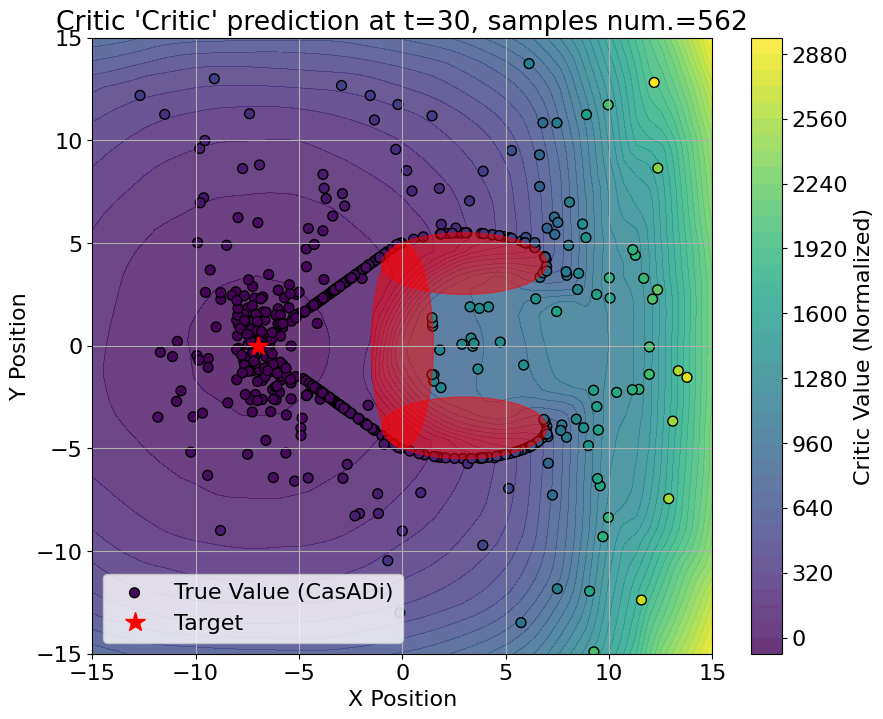

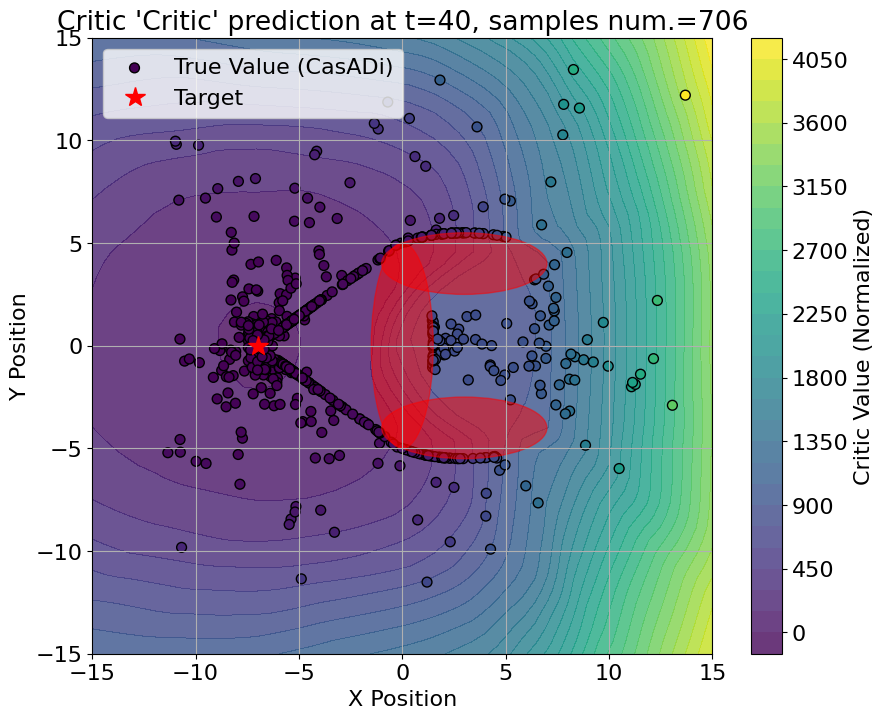

In [108]:
# Train the critic again with the new data in the buffer 
train_critic()

# Update the critic cycles counter
critic_cycles += cycles_counter(replay_buffer, minibatch_size, critic_epochs)
print(f"\nTotal critic cycles: {critic_cycles}")

for t in range(0, N, 10):
  plot_critic(critic, t, show=False)

--- CACTO Iteration 22 ---
--- Start training the constrained actor ---
--- Starting Constrained Actor training for 35 epochs ---
Epoch 1/35 | Mean Q+ALM: 241.9163 | Max Viol: 0.00010 | Lambda: [298.7  322.89 348.17] | Rho: 32847.8 | LR: 0.000500 | step: 98
 | dQ/du norm: 1.521105
Epoch 5/35 | Mean Q+ALM: 241.8118 | Max Viol: 0.00011 | Lambda: [301.97 326.24 354.81] | Rho: 33843.1 | LR: 0.000500 | step: 490
 | dQ/du norm: 1.501475
Epoch 10/35 | Mean Q+ALM: 242.2100 | Max Viol: 0.00013 | Lambda: [303.67 336.99 357.05] | Rho: 34523.3 | LR: 0.000500 | step: 980
 | dQ/du norm: 1.542449
Epoch 15/35 | Mean Q+ALM: 241.7628 | Max Viol: 0.00006 | Lambda: [313.73 343.84 358.51] | Rho: 35569.4 | LR: 0.000400 | step: 1470
 | dQ/du norm: 1.502166
Epoch 20/35 | Mean Q+ALM: 241.8242 | Max Viol: 0.00011 | Lambda: [317.16 348.32 366.19] | Rho: 36647.2 | LR: 0.000320 | step: 1960
 | dQ/du norm: 1.505347
Epoch 25/35 | Mean Q+ALM: 241.7897 | Max Viol: 0.00013 | Lambda: [320.37 355.6  368.56] | Rho: 37383.

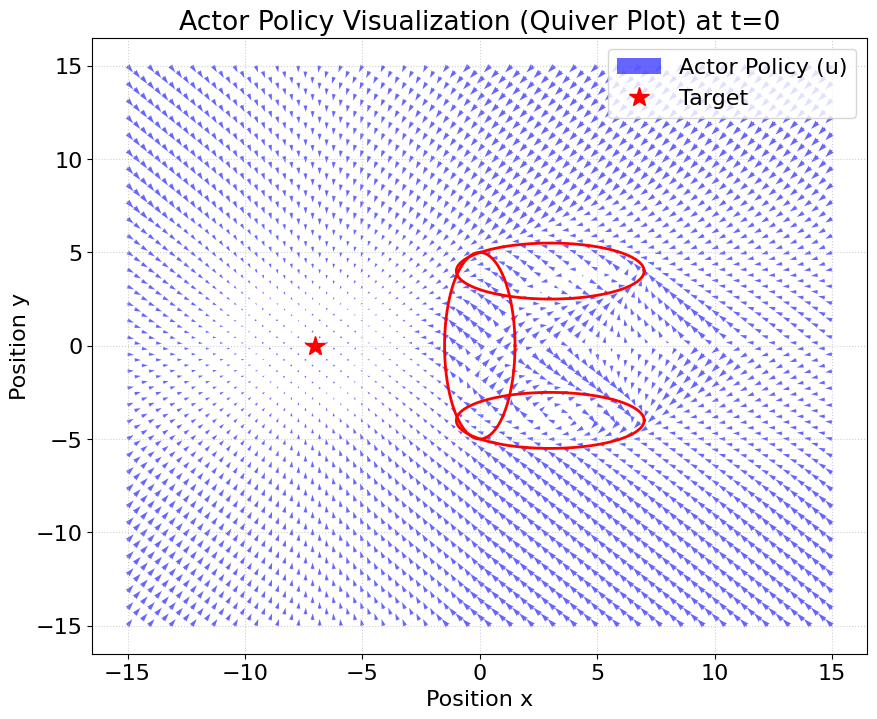

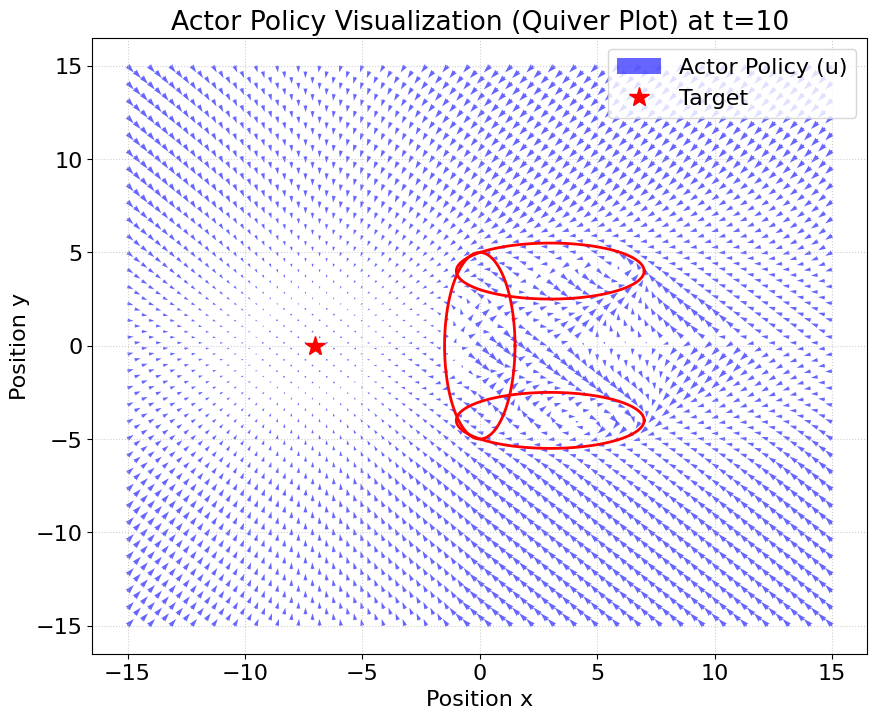

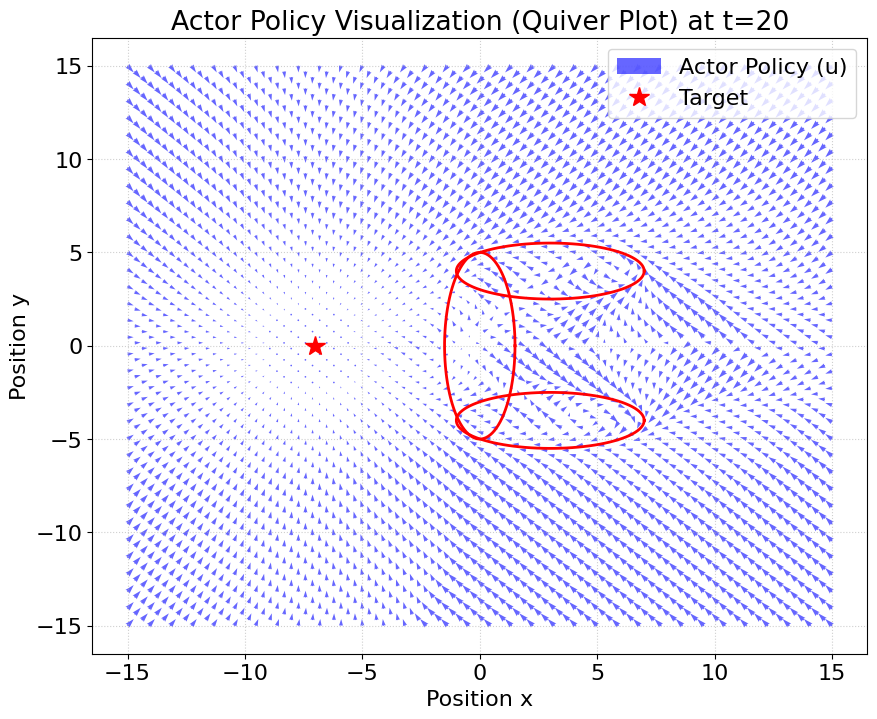

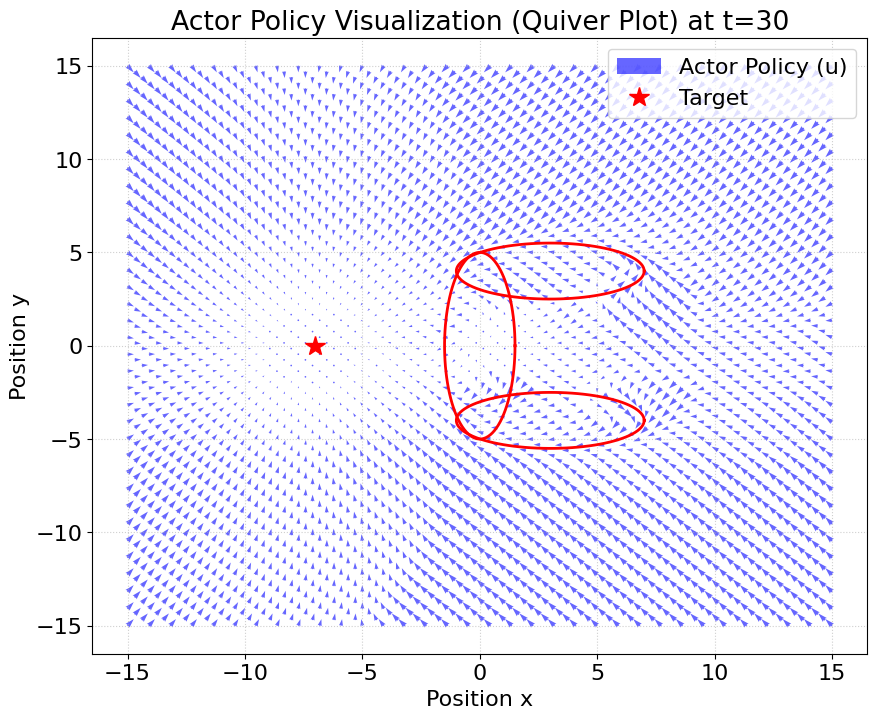

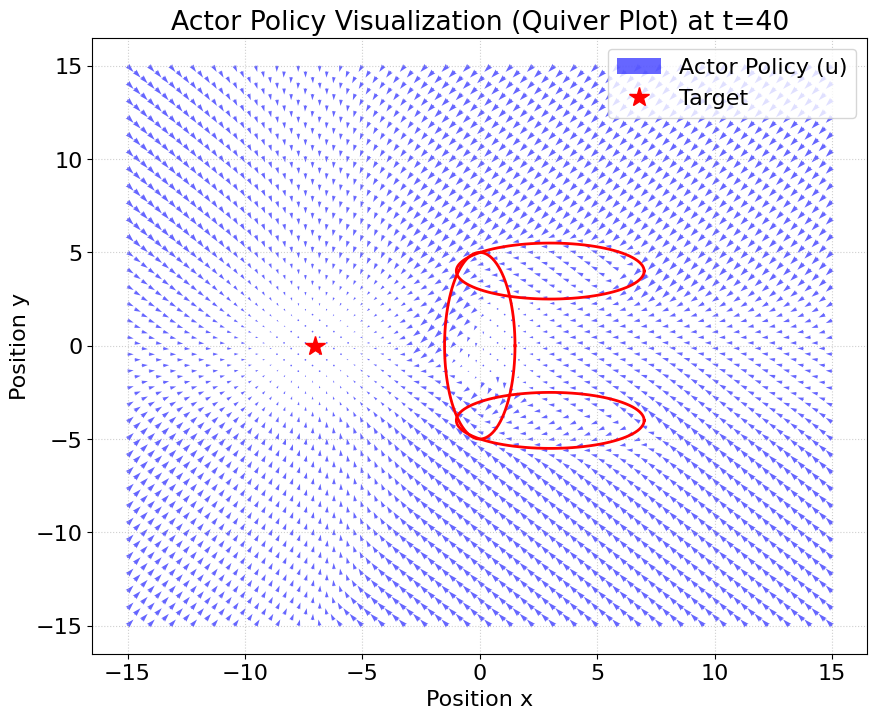

In [109]:
# Train the constrained actor again with the new critic

train_constr_actor()

# Update the constrained actor cycles counter
actor_cycles += cycles_counter(replay_buffer, minibatch_size, actor_epochs)
print(f"\nTotal constrained actor cycles: {actor_cycles}")

for t in range(0, N, 10):
  plot_constr_actor(t, show=True, plot_u_ocp=True)

Actor Only -> Feasible: 26/37 | Violating: 11/37
Actor Only -> Avg. max violation: 0.0074
Actor Only -> Avg. cost: 504.9171

Costs and Feasibility List:
Rollout 001 | Xini: (-10.0, -10.0) | Cost:   126.28 | Status: OK
Rollout 002 | Xini: (-8.0, -5.0) | Cost:    -7.64 | Status: OK
Rollout 003 | Xini: (-10.0,  0.0) | Cost:   -35.37 | Status: OK
Rollout 004 | Xini: (-8.0,  5.0) | Cost:    -7.81 | Status: OK
Rollout 005 | Xini: (-10.0, 10.0) | Cost:   125.87 | Status: OK
Rollout 006 | Xini: ( 5.0,  0.0) | Cost:   617.42 | Status: OK
Rollout 007 | Xini: ( 6.0,  1.5) | Cost:   518.93 | Status: OK
Rollout 008 | Xini: ( 6.0, -1.5) | Cost:   515.78 | Status: VIOL
Rollout 009 | Xini: ( 5.5,  2.5) | Cost:   490.93 | Status: OK
Rollout 010 | Xini: ( 5.5, -2.5) | Cost:   480.83 | Status: VIOL
Rollout 011 | Xini: ( 2.0,  0.0) | Cost:   653.56 | Status: OK
Rollout 012 | Xini: ( 1.5,  1.0) | Cost:   646.32 | Status: OK
Rollout 013 | Xini: ( 1.5, -2.0) | Cost:   626.69 | Status: VIOL
Rollout 014 | Xini

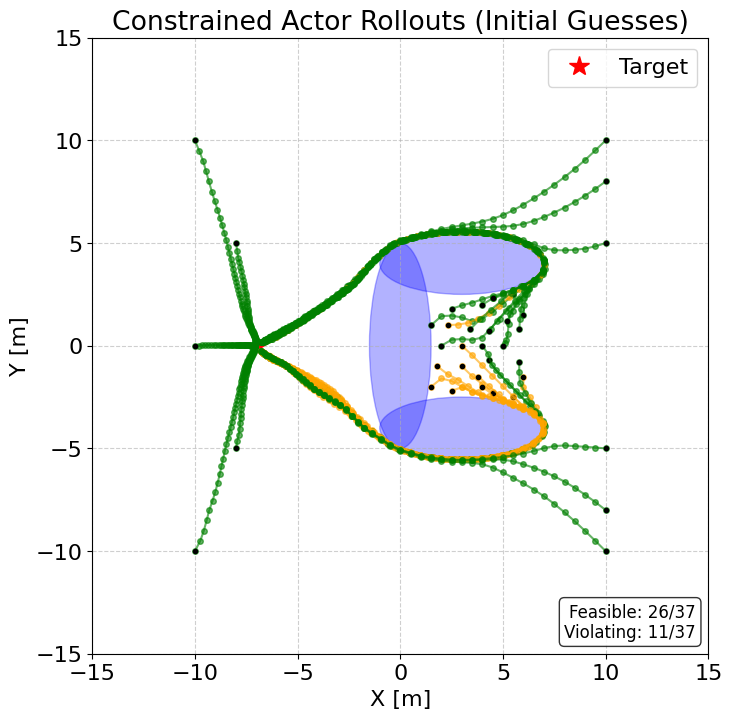

Computing initial guesses in batch...
TO + Warm Start -> Time: 12.376 s
TO + Warm Start -> Feasible: 37/37 | Failed: 0/37


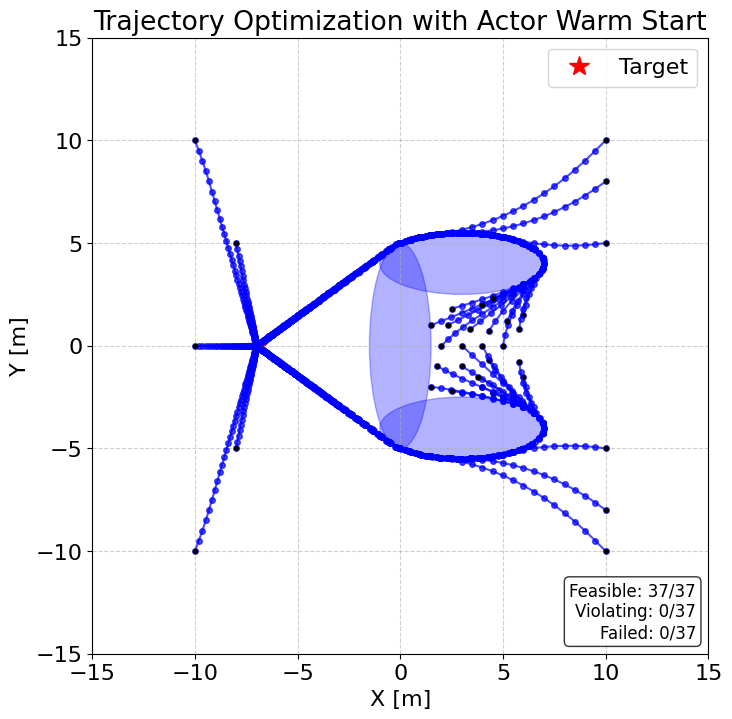

In [110]:
# Final evaluation of the constrained actor rollouts and TO performance after the last iteration
plot_cons_actor_rollouts(print_costs=True)
V_TO, all_cons_x_trajs = evaluate_TO_w_cons_warm_start()

In [111]:
# Final summary of the results
final_total_time = timeit.default_timer() - start_total_time
total_time_minutes = final_total_time / 60
print("\n\n--- FINAL SUMMARY ---")
print(f"Total CACTO Iterations: {iteration_cnt}")
print(f"Total Critic Cycles: {critic_cycles}")
print(f"Total Constrained Actor Cycles: {actor_cycles}")
print(f"Total Time Taken: {total_time_minutes:.3f} min")
print(f"Total OCPs Solved: {N_OCP * iteration_cnt}")



--- FINAL SUMMARY ---
Total CACTO Iterations: 22
Total Critic Cycles: 73010
Total Constrained Actor Cycles: 73010
Total Time Taken: 142.873 min
Total OCPs Solved: 6600


We stop at 7 ierations since in previous attempts after the 7th the results were worse. 

**NB:** to compute the updates per-epoch (num. of times we update the weights) we used: 

$$\text{Updates per Epoch} = \lceil \frac{N}{\text{minibatch\_size}} \rceil$$

Where $N$ is the replay_buffer size.